Mounted at /content/drive
[computing]  _selftest.json ...
[saved]      /content/drive/MyDrive/GraphRAG_ThreatIntel/cache/_selftest.json
[cache hit]  _selftest.json
[figure saved] _selftest.png


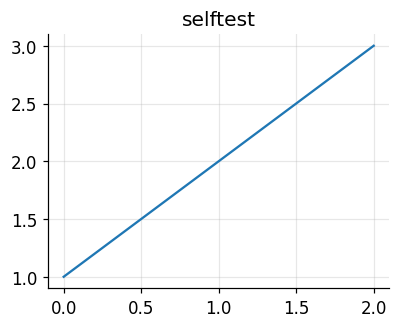

[table saved]  _selftest.png  (+ .csv)


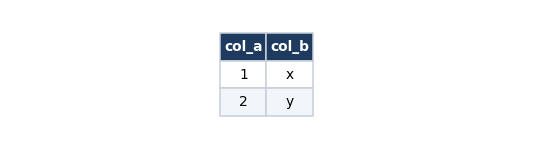

SELF-TEST PASSED

=== ENVIRONMENT ===
Python   : 3.13.18 | Colab: True
pandas   : 2.2.3 | numpy: 2.4.6 | matplotlib: 3.10.0
PyTorch  : 2.14.1+cpu
GPU      : none (CPU runtime)
Drive free: 109.8 GB
GROQ_API_KEY found: True
NVD_API_KEY  found: True

Project root: /content/drive/MyDrive/GraphRAG_ThreatIntel


In [1]:
# ============ BLOCK 1 : Setup, Drive folders, helper functions ============
import os, sys, json, time, pickle, random, platform, shutil
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# ---------- 1. Persistent storage (Google Drive) ----------
try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/GraphRAG_ThreatIntel')
    IN_COLAB = True
except ImportError:
    ROOT = Path('/tmp/GraphRAG_ThreatIntel')
    IN_COLAB = False
    print('WARNING: not running in Colab -> files go to a TEMPORARY folder, not Drive')

DIRS = {
    'raw':     ROOT / 'data' / 'raw',            # untouched downloads (NVD, ATT&CK, KEV, EPSS)
    'proc':    ROOT / 'data' / 'processed',      # cleaned tables, graph files
    'models':  ROOT / 'models',                  # training checkpoints
    'cache':   ROOT / 'cache',                   # LLM response cache, embeddings
    'results': ROOT / 'results',                 # evaluation outputs
    'figures': ROOT / 'report_assets' / 'figures',
    'tables':  ROOT / 'report_assets' / 'tables',
    'logs':    ROOT / 'logs',
}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
MANIFEST = ROOT / 'report_assets' / 'manifest.json'

# ---------- 2. Reproducibility ----------
SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass
seed_everything()

# ---------- 3. "Run only if not already on Drive" helper ----------
def _save(obj, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.tmp')       # write to temp first, so a dying session
    ext = path.suffix.lower()                       # never leaves a half-written file behind
    if ext == '.pkl':
        with open(tmp, 'wb') as f: pickle.dump(obj, f)
    elif ext == '.json':
        with open(tmp, 'w') as f: json.dump(obj, f, indent=2)
    elif ext == '.parquet':
        obj.to_parquet(tmp)
    elif ext == '.csv':
        obj.to_csv(tmp, index=False)
    else:
        raise ValueError(f'Unsupported extension: {ext}')
    os.replace(tmp, path)

def _load(path):
    path = Path(path); ext = path.suffix.lower()
    if ext == '.pkl':
        with open(path, 'rb') as f: return pickle.load(f)
    if ext == '.json':
        with open(path) as f: return json.load(f)
    if ext == '.parquet': return pd.read_parquet(path)
    if ext == '.csv': return pd.read_csv(path)
    raise ValueError(f'Unsupported extension: {ext}')

def cached(path, fn, force=False):
    """If `path` exists on Drive -> load it. Otherwise run fn(), save the result, return it."""
    path = Path(path)
    if path.exists() and not force:
        print(f'[cache hit]  {path.name}')
        return _load(path)
    print(f'[computing]  {path.name} ...')
    out = fn()
    _save(out, path)
    print(f'[saved]      {path}')
    return out

# ---------- 4. Training checkpoints (resume after a crashed / deleted session) ----------
def save_ckpt(state, tag, epoch, keep=2):
    import torch
    p = DIRS['models'] / f'{tag}_epoch{epoch:04d}.pt'
    tmp = p.with_name(p.name + '.tmp')
    torch.save(state, tmp); os.replace(tmp, p)
    for old in sorted(DIRS['models'].glob(f'{tag}_epoch*.pt'))[:-keep]:   # keep newest `keep` only
        old.unlink()
    return p

def load_latest_ckpt(tag, map_location='cpu'):
    import torch
    files = sorted(DIRS['models'].glob(f'{tag}_epoch*.pt'))
    if not files:
        print(f'[resume] no checkpoint for "{tag}" -> starting fresh'); return None
    print(f'[resume] loading {files[-1].name}')
    return torch.load(files[-1], map_location=map_location, weights_only=False)

# ---------- 5. Report assets: one figure per file, tables as images ----------
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 11,
    'axes.grid': True, 'grid.alpha': 0.3,
    'axes.spines.top': False, 'axes.spines.right': False,
})

def _register(kind, name, caption):
    if name.startswith('_'): return
    m = _load(MANIFEST) if MANIFEST.exists() else {'figures': {}, 'tables': {}}
    m[kind][name] = {'caption': caption, 'saved': datetime.now().isoformat(timespec='seconds')}
    _save(m, MANIFEST)

def save_fig(fig, name, caption=''):
    path = DIRS['figures'] / f'{name}.png'
    fig.savefig(path, dpi=300, bbox_inches='tight', facecolor='white')
    _register('figures', name, caption)
    print(f'[figure saved] {path.name}')
    plt.show()

def save_table(df, name, caption='', max_rows=30):
    df.to_csv(DIRS['tables'] / f'{name}.csv', index=False)          # raw data kept as CSV too
    show = df.head(max_rows)
    fig, ax = plt.subplots(figsize=(max(6, 1.7 * len(show.columns)), max(1.5, 0.42 * (len(show) + 1))))
    ax.axis('off')
    tbl = ax.table(cellText=show.values, colLabels=list(show.columns), loc='center', cellLoc='center')
    tbl.auto_set_font_size(False); tbl.set_fontsize(9); tbl.scale(1, 1.5)
    tbl.auto_set_column_width(list(range(len(show.columns))))
    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor('#C8CFDA')
        if r == 0:
            cell.set_facecolor('#1F3A5F'); cell.set_text_props(color='white', weight='bold')
        elif r % 2 == 0:
            cell.set_facecolor('#F2F5FA')
    path = DIRS['tables'] / f'{name}.png'
    fig.savefig(path, dpi=300, bbox_inches='tight', facecolor='white')
    _register('tables', name, caption)
    print(f'[table saved]  {path.name}  (+ .csv)')
    plt.show()

# ---------- 6. Secrets (API keys) ----------
def get_secret(name):
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)

# ---------- 7. Self-test (creates and deletes dummy files) ----------
def _selftest():
    p = DIRS['cache'] / '_selftest.json'
    cached(p, lambda: {'ok': True}, force=True)
    assert cached(p, lambda: {'ok': False}) == {'ok': True}, 'cache failed'
    p.unlink()
    pq = DIRS['cache'] / '_selftest.parquet'
    _save(pd.DataFrame({'a': [1, 2]}), pq); assert len(_load(pq)) == 2; pq.unlink()
    fig, ax = plt.subplots(figsize=(4, 3)); ax.plot([1, 2, 3]); ax.set_title('selftest')
    save_fig(fig, '_selftest'); (DIRS['figures'] / '_selftest.png').unlink()
    save_table(pd.DataFrame({'col_a': [1, 2], 'col_b': ['x', 'y']}), '_selftest')
    for ext in ('png', 'csv'): (DIRS['tables'] / f'_selftest.{ext}').unlink()
    print('SELF-TEST PASSED')
_selftest()

# ---------- 8. Environment report ----------
print('\n=== ENVIRONMENT ===')
print('Python   :', platform.python_version(), '| Colab:', IN_COLAB)
print('pandas   :', pd.__version__, '| numpy:', np.__version__, '| matplotlib:', matplotlib.__version__)
try:
    import torch
    print('PyTorch  :', torch.__version__)
    print('GPU      :', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none (CPU runtime)')
except ImportError:
    print('PyTorch  : not installed')
try:
    print('Drive free: %.1f GB' % (shutil.disk_usage(ROOT).free / 1e9))
except Exception:
    pass
print('GROQ_API_KEY found:', bool(get_secret('GROQ_API_KEY')))
print('NVD_API_KEY  found:', bool(get_secret('NVD_API_KEY')))
print('\nProject root:', ROOT)

[cache hit]  enterprise-attack.json (55.3 MB)
[cache hit]  known_exploited_vulnerabilities.json (1.9 MB)
[cache hit]  epss_scores-current.csv.gz (2.8 MB)
[cache hit]  ctid_kev_attack16.1.json (1.2 MB)
[cache hit]  ctid_attack_to_cve.csv (0.0 MB)
[cache hit]  processed tables found on Drive

===== ATT&CK Enterprise =====
version        : 20.1
techniques     : 227 | sub-techniques: 479
tactics        : 15 | groups: 178 | software: 842 | mitigations: 44
tactic names   : ['collection', 'command-and-control', 'credential-access', 'defense-impairment', 'discovery', 'execution', 'exfiltration', 'impact', 'initial-access', 'lateral-movement', 'persistence', 'privilege-escalation', 'reconnaissance', 'resource-development', 'stealth']
relationships  : {('software', 'uses', 'technique'): 11608, ('mitigation', 'mitigates', 'technique'): 1477, ('group', 'uses', 'technique'): 4815, ('group', 'uses', 'software'): 1166, ('technique', 'subtechnique-of', 'technique'): 479}
revoked->new id remaps availab

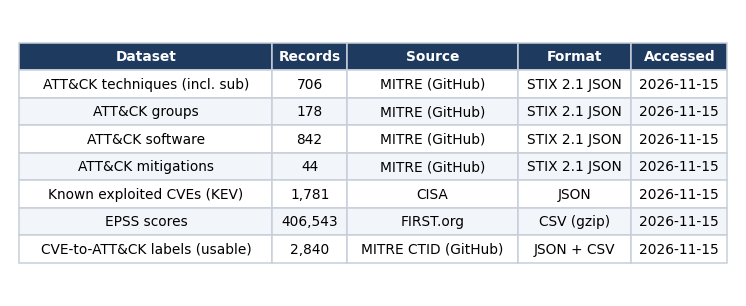


BLOCK 2 DONE


In [ ]:
# ============ BLOCK 2 : Download raw datasets (resumable), parse, clean, validate ============
# Needs Block 1 to have been run in this session (uses DIRS, _save, _load, save_table).
import gzip, io, re, requests
from collections import Counter

ACCESS_DATE = datetime.now().strftime('%Y-%m-%d')
HEADERS = {'User-Agent': 'Mozilla/5.0 (PatchPath final-year research project)'}
D = lambda s: {k: int(v) for k, v in dict(s).items()}          # tidy dict printing

SOURCES = {
    'attack_stix': {'file': 'enterprise-attack.json', 'urls': [
        'https://raw.githubusercontent.com/mitre-attack/attack-stix-data/master/enterprise-attack/enterprise-attack.json']},
    'kev': {'file': 'known_exploited_vulnerabilities.json', 'urls': [
        'https://www.cisa.gov/sites/default/files/feeds/known_exploited_vulnerabilities.json',
        'https://raw.githubusercontent.com/cisagov/kev-data/develop/known_exploited_vulnerabilities.json']},
    'epss': {'file': 'epss_scores-current.csv.gz', 'urls': [
        'https://epss.empiricalsecurity.com/epss_scores-current.csv.gz',
        'https://epss.cyentia.com/epss_scores-current.csv.gz']},
    'ctid_kev_map': {'file': 'ctid_kev_attack16.1.json', 'urls': [
        'https://raw.githubusercontent.com/center-for-threat-informed-defense/mappings-explorer/main/mappings/kev/attack-16.1/kev-07.28.2025/enterprise/kev-07.28.2025_attack-16.1-enterprise.json']},
    'ctid_csv_map': {'file': 'ctid_attack_to_cve.csv', 'urls': [
        'https://raw.githubusercontent.com/center-for-threat-informed-defense/attack_to_cve/master/Att%26ckToCveMappings.csv']},
}

# ---------- 1. Resumable downloads (skip anything already on Drive) ----------
LOG_PATH = DIRS['raw'] / 'source_log.json'
SOURCE_LOG = _load(LOG_PATH) if LOG_PATH.exists() else {}

def download(name):
    spec = SOURCES[name]; dest = DIRS['raw'] / spec['file']
    if dest.exists() and dest.stat().st_size > 0:
        print(f'[cache hit]  {dest.name} ({dest.stat().st_size / 1e6:.1f} MB)'); return dest
    last = None
    for url in spec['urls']:
        try:
            print(f'[download]   {name} <- {url}')
            tmp = dest.with_name(dest.name + '.tmp')
            with requests.get(url, headers=HEADERS, stream=True, timeout=120) as r:
                r.raise_for_status()
                with open(tmp, 'wb') as f:
                    for chunk in r.iter_content(1 << 20): f.write(chunk)
            if tmp.stat().st_size == 0: raise RuntimeError('empty file')
            os.replace(tmp, dest)
            SOURCE_LOG[name] = {'url': url, 'accessed': ACCESS_DATE, 'bytes': dest.stat().st_size}
            _save(SOURCE_LOG, LOG_PATH)
            print(f'[saved]      {dest.name} ({dest.stat().st_size / 1e6:.1f} MB)')
            return dest
        except Exception as e:
            last = e; print(f'   failed: {str(e)[:150]}')
    raise RuntimeError(f'All URLs failed for "{name}": {last}')

PATHS = {name: download(name) for name in SOURCES}

# ---------- 2. Parsers ----------
KIND = {'intrusion-set': 'group', 'malware': 'software', 'tool': 'software',
        'attack-pattern': 'technique', 'course-of-action': 'mitigation', 'x-mitre-tactic': 'tactic'}

def parse_attack(path):
    bundle = json.load(open(path))
    all_by_stix = {o['id']: o for o in bundle['objects']}
    objs = [o for o in bundle['objects'] if not o.get('revoked') and not o.get('x_mitre_deprecated')]
    by_stix = {o['id']: o for o in objs}
    def ext_id(o):
        for r in o.get('external_references', []):
            if r.get('source_name') == 'mitre-attack': return r.get('external_id')
    version = next((o.get('x_mitre_version') for o in bundle['objects'] if o['type'] == 'x-mitre-collection'), 'unknown')

    tactics = pd.DataFrame([{'tactic_id': ext_id(o), 'shortname': o['x_mitre_shortname'], 'name': o['name']}
                            for o in objs if o['type'] == 'x-mitre-tactic'])
    techniques = pd.DataFrame([{
        'technique_id': ext_id(o), 'name': o['name'], 'is_sub': bool(o.get('x_mitre_is_subtechnique')),
        'tactics': '|'.join(p['phase_name'] for p in o.get('kill_chain_phases', []) if p.get('kill_chain_name') == 'mitre-attack'),
        'platforms': '|'.join(o.get('x_mitre_platforms', [])),
        'description': o.get('description') or ''} for o in objs if o['type'] == 'attack-pattern'])
    groups = pd.DataFrame([{'group_id': ext_id(o), 'name': o['name'], 'aliases': '|'.join(o.get('aliases', [])),
                            'description': o.get('description') or ''} for o in objs if o['type'] == 'intrusion-set'])
    software = pd.DataFrame([{'software_id': ext_id(o), 'name': o['name'], 'kind': o['type'],
                              'description': o.get('description') or ''} for o in objs if o['type'] in ('malware', 'tool')])
    mitigations = pd.DataFrame([{'mitigation_id': ext_id(o), 'name': o['name'],
                                 'description': o.get('description') or ''} for o in objs if o['type'] == 'course-of-action'])

    edges, remap = [], {}
    for o in bundle['objects']:
        if o['type'] != 'relationship': continue
        rel = o['relationship_type']
        if rel == 'revoked-by':                                   # old technique -> the technique that replaced it
            s, t = all_by_stix.get(o['source_ref']), all_by_stix.get(o['target_ref'])
            if s and t and s['type'] == 'attack-pattern' and t['type'] == 'attack-pattern' \
               and not t.get('revoked') and not t.get('x_mitre_deprecated'):
                remap.setdefault(ext_id(s), ext_id(t))
            continue
        s, t = by_stix.get(o['source_ref']), by_stix.get(o['target_ref'])
        if not s or not t: continue
        st, tt = KIND.get(s['type']), KIND.get(t['type'])
        keep = ((rel == 'uses' and st in ('group', 'software') and tt == 'technique') or
                (rel == 'uses' and st == 'group' and tt == 'software') or
                (rel == 'mitigates' and st == 'mitigation' and tt == 'technique') or
                (rel == 'subtechnique-of' and st == 'technique' and tt == 'technique'))
        if keep:
            edges.append({'src_id': ext_id(s), 'src_type': st, 'rel': rel, 'dst_id': ext_id(t), 'dst_type': tt})
    edges = pd.DataFrame(edges).drop_duplicates().reset_index(drop=True)
    id_remap = pd.DataFrame({'old_id': list(remap), 'new_id': list(remap.values())})
    return {'attack_tactics': tactics, 'attack_techniques': techniques, 'attack_groups': groups,
            'attack_software': software, 'attack_mitigations': mitigations, 'attack_edges': edges,
            'attack_id_remap': id_remap}, version

def parse_kev(path):
    d = json.load(open(path))
    df = pd.DataFrame([{
        'cve_id': v['cveID'], 'vendor': v.get('vendorProject'), 'product': v.get('product'),
        'vuln_name': v.get('vulnerabilityName'), 'date_added': v.get('dateAdded'),
        'description': v.get('shortDescription'), 'required_action': v.get('requiredAction'),
        'due_date': v.get('dueDate'), 'ransomware_use': v.get('knownRansomwareCampaignUse'),
        'cwes': ';'.join(v.get('cwes') or [])} for v in d['vulnerabilities']])
    df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')
    return df, {'catalog_version': d.get('catalogVersion'), 'date_released': d.get('dateReleased'), 'count': d.get('count')}

def parse_epss(path):
    with gzip.open(path, 'rt') as f: lines = f.read().splitlines()
    meta = lines[0].lstrip('#') if lines and lines[0].startswith('#') else ''
    body = '\n'.join(lines[1:] if meta else lines)
    df = pd.read_csv(io.StringIO(body)).rename(columns=str.lower)[['cve', 'epss', 'percentile']]
    df = df.rename(columns={'cve': 'cve_id'})
    df['epss'] = df['epss'].astype('float32'); df['percentile'] = df['percentile'].astype('float32')
    return df, {'header': meta}

def parse_ctid_json(path):
    d = json.load(open(path))
    return pd.DataFrame([{
        'cve_id': m['capability_id'].strip().upper(), 'technique_id': m['attack_object_id'],
        'mapping_type': m['mapping_type'], 'source': 'ctid_kev_2025-07', 'vuln_group': m.get('capability_group'),
        'comment': m.get('comments')} for m in d['mapping_objects'] if m.get('attack_object_id')])

def parse_ctid_csv(path):
    df = pd.read_csv(path, encoding='utf-8-sig')
    cols = {'Primary Impact': 'primary_impact', 'Secondary Impact': 'secondary_impact',
            'Exploitation Technique': 'exploitation_technique', 'Uncategorized': 'uncategorized'}
    rows = []
    for _, r in df.iterrows():
        for col, mtype in cols.items():
            if pd.notna(r[col]):
                for t in str(r[col]).split(';'):
                    if t.strip():
                        rows.append({'cve_id': str(r['CVE ID']).strip().upper(), 'technique_id': t,
                                     'mapping_type': mtype, 'source': 'ctid_attack_to_cve', 'vuln_group': None, 'comment': None})
    return pd.DataFrame(rows)

def clean_technique_ids(lab, valid, remap):
    """Fix typos, follow ATT&CK 'revoked-by' links, and flag every row: ok / remapped / ics / unresolved."""
    lab = lab.copy(); lab['technique_id_raw'] = lab['technique_id']
    s = (lab['technique_id'].astype(str).str.strip().str.upper()
         .str.replace(r'\.\s+', ';', regex=True)          # "T1190. T1005" -> two separate ids
         .str.replace(r'^TT', 'T', regex=True))            # "TT1565" -> "T1565"
    lab['technique_id'] = s.str.split(';')
    lab = lab.explode('technique_id').reset_index(drop=True)
    t = lab['technique_id'].str.strip().str.rstrip('.')   # "T1036." -> "T1036"
    t = t.str.replace(r'^T(\d{3})$', r'T0\1', regex=True) # ICS ids written without the leading zero
    was_remapped = np.zeros(len(lab), dtype=bool)
    for _ in range(3):                                    # follow replacement chains (old -> new -> newer)
        m = (~t.isin(valid) & t.isin(remap)).to_numpy()
        if not m.any(): break
        t = t.where(~m, t.map(remap)); was_remapped |= m
    lab['technique_id'] = t
    ok = t.isin(valid).to_numpy(); ics = (t.str.match(r'^T0\d{3}$') & ~t.isin(valid)).to_numpy()
    lab['status'] = np.where(ok & was_remapped, 'remapped', np.where(ok, 'ok', np.where(ics, 'ics', 'unresolved')))
    lab['technique_parent'] = lab['technique_id'].str.split('.').str[0]
    return lab.drop_duplicates(['cve_id', 'technique_id', 'mapping_type']).reset_index(drop=True)

def build_labels(valid, remap):
    lab = pd.concat([parse_ctid_json(PATHS['ctid_kev_map']), parse_ctid_csv(PATHS['ctid_csv_map'])], ignore_index=True)
    return clean_technique_ids(lab, valid, remap)

# ---------- 3. Parse once, store as parquet on Drive ----------
PROC = DIRS['proc']
ATT_NAMES = ['attack_tactics', 'attack_techniques', 'attack_groups', 'attack_software',
             'attack_mitigations', 'attack_edges', 'attack_id_remap']
META_PATH = PROC / 'source_meta.json'

if all((PROC / f'{n}.parquet').exists() for n in ATT_NAMES + ['kev', 'epss', 'cve_attack_labels']) and META_PATH.exists():
    print('[cache hit]  processed tables found on Drive')
    ATT = {n: _load(PROC / f'{n}.parquet') for n in ATT_NAMES}
    KEV, EPSS, LABELS = (_load(PROC / f'{n}.parquet') for n in ('kev', 'epss', 'cve_attack_labels'))
    META = _load(META_PATH)
else:
    ATT, att_version = parse_attack(PATHS['attack_stix'])
    KEV, kev_meta = parse_kev(PATHS['kev'])
    EPSS, epss_meta = parse_epss(PATHS['epss'])
    LABELS = build_labels(set(ATT['attack_techniques'].technique_id),
                          dict(zip(ATT['attack_id_remap'].old_id, ATT['attack_id_remap'].new_id)))
    META = {'attack_version': att_version, 'kev': kev_meta, 'epss': epss_meta, 'accessed': ACCESS_DATE}
    for n, df in ATT.items(): _save(df, PROC / f'{n}.parquet')
    _save(KEV, PROC / 'kev.parquet'); _save(EPSS, PROC / 'epss.parquet'); _save(LABELS, PROC / 'cve_attack_labels.parquet')
    _save(META, META_PATH)
    print('[saved]      processed tables -> Drive/data/processed')

# ---------- 4. Validation report ----------
def section(t): print(f'\n===== {t} =====')
cve_re = re.compile(r'^CVE-\d{4}-\d{4,}$')

section('ATT&CK Enterprise')
T = ATT['attack_techniques']; E = ATT['attack_edges']
print('version        :', META['attack_version'])
print('techniques     :', int((~T.is_sub).sum()), '| sub-techniques:', int(T.is_sub.sum()))
print('tactics        :', len(ATT['attack_tactics']), '| groups:', len(ATT['attack_groups']),
      '| software:', len(ATT['attack_software']), '| mitigations:', len(ATT['attack_mitigations']))
print('tactic names   :', sorted(ATT['attack_tactics'].shortname))
print('relationships  :', D(Counter(zip(E.src_type, E.rel, E.dst_type))))
print('revoked->new id remaps available:', len(ATT['attack_id_remap']), '| techniques without an ID:', int(T.technique_id.isna().sum()))

section('CISA KEV')
print('catalog version:', META['kev']['catalog_version'], '| entries:', len(KEV), '| unique CVEs:', KEV.cve_id.nunique())
print('date added     :', KEV.date_added.min().date(), '->', KEV.date_added.max().date())
print('ransomware use :', D(KEV.ransomware_use.value_counts()))
print('bad CVE ids    :', int((~KEV.cve_id.str.match(cve_re)).sum()))

section('EPSS')
print('rows           :', f'{len(EPSS):,}', '| header:', META['epss']['header'][:90])
print('score range    :', round(float(EPSS.epss.min()), 5), '->', round(float(EPSS.epss.max()), 5), '| duplicate CVEs:', int(EPSS.cve_id.duplicated().sum()))

section('CVE -> ATT&CK labels (CTID), after cleaning')
print('rows           :', len(LABELS), '| unique CVEs:', LABELS.cve_id.nunique(), '| bad CVE ids:', int((~LABELS.cve_id.str.match(cve_re)).sum()))
print('row status     :', D(LABELS.status.value_counts()), ' (ok / remapped = usable)')
print('unresolved IDs :', sorted(LABELS[LABELS.status == 'unresolved'].technique_id.unique()))
USABLE = LABELS[LABELS.status.isin(['ok', 'remapped'])]
print('USABLE         : rows', len(USABLE), '| CVEs', USABLE.cve_id.nunique(), '| technique IDs', USABLE.technique_id.nunique())
print('usable by source      :', D(USABLE.groupby('source').cve_id.nunique()), '(unique CVEs)')
print('usable by mapping type:', D(USABLE.mapping_type.value_counts()))
srcs = [set(g.cve_id) for _, g in USABLE.groupby('source')]
print('CVE overlap between the two sources:', len(srcs[0] & srcs[1]) if len(srcs) == 2 else 'n/a')
print('CVEs with >=2 distinct techniques  :', int((USABLE.groupby('cve_id').technique_id.nunique() >= 2).sum()))

section('Cross-source coverage of the usable labelled CVEs')
lab_cves = set(USABLE.cve_id)
print(f'in CISA KEV    : {len(lab_cves & set(KEV.cve_id))} / {len(lab_cves)}')
print(f'have EPSS score: {len(lab_cves & set(EPSS.cve_id))} / {len(lab_cves)}')

# ---------- 5. Dataset-summary table for the report ----------
summary = pd.DataFrame([
    ['ATT&CK techniques (incl. sub)', f'{len(T):,}', 'MITRE (GitHub)', 'STIX 2.1 JSON', ACCESS_DATE],
    ['ATT&CK groups', f"{len(ATT['attack_groups']):,}", 'MITRE (GitHub)', 'STIX 2.1 JSON', ACCESS_DATE],
    ['ATT&CK software', f"{len(ATT['attack_software']):,}", 'MITRE (GitHub)', 'STIX 2.1 JSON', ACCESS_DATE],
    ['ATT&CK mitigations', f"{len(ATT['attack_mitigations']):,}", 'MITRE (GitHub)', 'STIX 2.1 JSON', ACCESS_DATE],
    ['Known exploited CVEs (KEV)', f'{len(KEV):,}', 'CISA', 'JSON', ACCESS_DATE],
    ['EPSS scores', f'{len(EPSS):,}', 'FIRST.org', 'CSV (gzip)', ACCESS_DATE],
    ['CVE-to-ATT&CK labels (usable)', f'{len(USABLE):,}', 'MITRE CTID (GitHub)', 'JSON + CSV', ACCESS_DATE],
], columns=['Dataset', 'Records', 'Source', 'Format', 'Accessed'])
save_table(summary, 'table_dataset_sources', 'Public datasets used in the project')

_save({'attack_version': META['attack_version'], 'kev_entries': len(KEV), 'epss_rows': len(EPSS),
       'label_rows_usable': len(USABLE), 'label_cves_usable': int(USABLE.cve_id.nunique()), 'accessed': ACCESS_DATE},
      DIRS['results'] / 'data_summary.json')
print('\nBLOCK 2 DONE')

NVD API key: found | min gap between requests: 0.7 s
[computing]  nvd_probe.json ...
  connected. total CVEs in NVD: 425,790
  year counts done  (375 s)
  product probes done (788 s)
[saved]      /content/drive/MyDrive/GraphRAG_ThreatIntel/cache/nvd_probe.json
[computing]  nvd_sample_CVE-2021-44228.json ...
[saved]      /content/drive/MyDrive/GraphRAG_ThreatIntel/data/raw/nvd_sample_CVE-2021-44228.json

Total CVEs in NVD: 425,790  (API version 2.0, snapshot 2026-11-15T12:52:39.727)

CVEs published per year:
2018     18154
2019     18938
2020     19222
2021     21950
2022     26431
2023     30949
2024     40704
2025     49972
2026    100513

Cumulative size if we pulled everything since year Y (2000 CVEs per page):
  since 2018:   326,833 CVEs  ~ 164 pages
  since 2021:   270,519 CVEs  ~ 136 pages
  since 2023:   222,138 CVEs  ~ 112 pages
  since 2024:   191,189 CVEs  ~  96 pages
  since 2025:   150,485 CVEs  ~  76 pages

Products (CVEs that affect any version of the product):
         

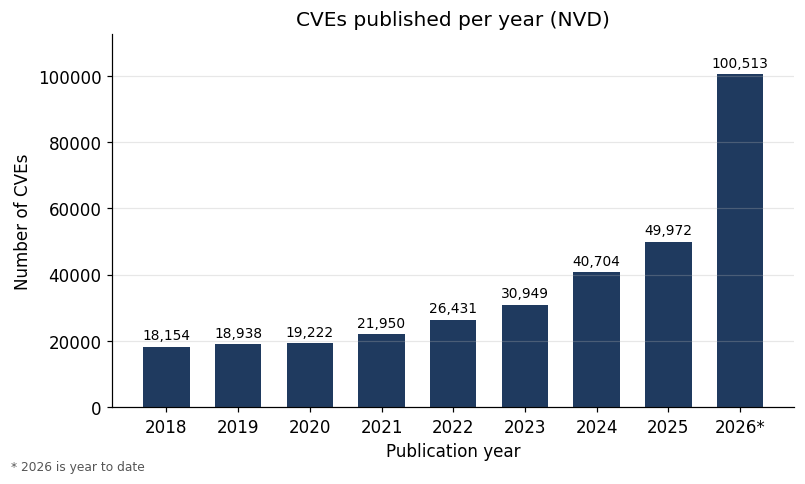


BLOCK 3 DONE


In [ ]:
# ============ BLOCK 3 : NVD connection test + data-size probe (about 2-6 minutes, cached afterwards) ============
# Needs Block 1 to have been run in this session (uses DIRS, cached, _save, get_secret, save_fig).
import time, math, requests
from datetime import datetime, timezone

NVD_URL = 'https://services.nvd.nist.gov/rest/json/cves/2.0'
NVD_KEY = get_secret('NVD_API_KEY')
MIN_GAP = 0.7 if NVD_KEY else 6.5            # NVD allows 50 requests / 30 s with a key, 5 / 30 s without
_last_call = [0.0]
print('NVD API key:', 'found' if NVD_KEY else 'MISSING (everything will be slow)', '| min gap between requests:', MIN_GAP, 's')

def nvd_get(params, retries=6):
    headers = {'apiKey': NVD_KEY} if NVD_KEY else {}
    err = 'unknown'
    for attempt in range(retries):
        wait = MIN_GAP - (time.time() - _last_call[0])
        if wait > 0: time.sleep(wait)
        _last_call[0] = time.time()
        try:
            r = requests.get(NVD_URL, params=params, headers=headers, timeout=90)
            if r.status_code == 200:
                return r.json()
            err = f'HTTP {r.status_code}'
            if r.status_code in (400, 404):               # bad request / bad key: retrying will not help
                raise RuntimeError(f'{err}: {r.headers.get("message", "") or r.text[:200]}')
        except requests.RequestException as e:
            err = type(e).__name__
        except ValueError:
            err = 'invalid JSON'
        time.sleep(min(60, 5 * 2 ** attempt))               # back off (rate limit / server busy)
    raise RuntimeError(f'NVD request failed after {retries} tries ({err})')

def total_of(params):
    return nvd_get({**params, 'resultsPerPage': 1})['totalResults']

PRODUCTS = {   # candidate software for the demo "server stacks"; a failed/zero entry just tells us the CPE name is wrong
    'Apache HTTP Server': 'cpe:2.3:a:apache:http_server', 'Apache Tomcat': 'cpe:2.3:a:apache:tomcat',
    'Apache Log4j': 'cpe:2.3:a:apache:log4j', 'nginx (F5)': 'cpe:2.3:a:f5:nginx',
    'nginx (old vendor id)': 'cpe:2.3:a:nginx:nginx', 'OpenSSL': 'cpe:2.3:a:openssl:openssl',
    'OpenSSH': 'cpe:2.3:a:openbsd:openssh', 'MySQL (Oracle)': 'cpe:2.3:a:oracle:mysql',
    'PostgreSQL': 'cpe:2.3:a:postgresql:postgresql', 'PHP': 'cpe:2.3:a:php:php',
    'WordPress': 'cpe:2.3:a:wordpress:wordpress', 'Linux kernel': 'cpe:2.3:o:linux:linux_kernel',
    'Microsoft Exchange Server': 'cpe:2.3:a:microsoft:exchange_server',
    'Microsoft IIS': 'cpe:2.3:a:microsoft:internet_information_services',
    'Windows Server 2019': 'cpe:2.3:o:microsoft:windows_server_2019',
    'Fortinet FortiOS': 'cpe:2.3:o:fortinet:fortios', 'Cisco IOS XE': 'cpe:2.3:o:cisco:ios_xe',
    'Atlassian Confluence Server': 'cpe:2.3:a:atlassian:confluence_server',
    'GitLab': 'cpe:2.3:a:gitlab:gitlab', 'Jenkins': 'cpe:2.3:a:jenkins:jenkins',
    'Redis': 'cpe:2.3:a:redis:redis', 'Elasticsearch': 'cpe:2.3:a:elastic:elasticsearch',
    'Samba': 'cpe:2.3:a:samba:samba', 'Python': 'cpe:2.3:a:python:python',
    'Node.js': 'cpe:2.3:a:nodejs:node.js', 'Spring Framework': 'cpe:2.3:a:vmware:spring_framework',
}
SAMPLE_CVE = 'CVE-2021-44228'
fmt = lambda dt: dt.strftime('%Y-%m-%dT%H:%M:%S.000')

def quarter_windows(start_year, now):
    for y in range(start_year, now.year + 1):
        for q, (m1, m2, d2) in enumerate([(1, 3, 31), (4, 6, 30), (7, 9, 30), (10, 12, 31)], 1):
            s, e = datetime(y, m1, 1), datetime(y, m2, d2, 23, 59, 59)
            if s > now: return
            yield y, q, s, min(e, now)

def run_probe():
    t0 = time.time(); now = datetime.now(timezone.utc).replace(tzinfo=None)
    d = nvd_get({'resultsPerPage': 1})
    out = {'total_cves': d['totalResults'], 'api_version': d.get('version'), 'timestamp': d.get('timestamp'),
           'year_counts': {}, 'products': {}}
    print(f"  connected. total CVEs in NVD: {out['total_cves']:,}")
    for y, q, s, e in quarter_windows(2018, now):                      # 120-day limit -> quarterly windows
        n = total_of({'pubStartDate': fmt(s), 'pubEndDate': fmt(e)})
        out['year_counts'][str(y)] = out['year_counts'].get(str(y), 0) + n
    print('  year counts done  (%.0f s)' % (time.time() - t0))
    for i, (name, cpe) in enumerate(PRODUCTS.items(), 1):
        try:    out['products'][name] = {'cpe': cpe, 'total': total_of({'virtualMatchString': cpe})}
        except Exception as ex: out['products'][name] = {'cpe': cpe, 'total': None, 'error': str(ex)[:150]}
    print('  product probes done (%.0f s)' % (time.time() - t0))
    return out

probe = cached(DIRS['cache'] / 'nvd_probe.json', run_probe)
sample = cached(DIRS['raw'] / f'nvd_sample_{SAMPLE_CVE}.json', lambda: nvd_get({'cveId': SAMPLE_CVE}))

# ---------- Report ----------
print(f"\nTotal CVEs in NVD: {probe['total_cves']:,}  (API version {probe['api_version']}, snapshot {probe['timestamp']})")
yc = pd.Series({int(k): v for k, v in probe['year_counts'].items()}).sort_index()
print('\nCVEs published per year:'); print(yc.to_string())
print('\nCumulative size if we pulled everything since year Y (2000 CVEs per page):')
for y in (2018, 2021, 2023, 2024, 2025):
    n = int(yc[yc.index >= y].sum()); print(f'  since {y}: {n:>9,} CVEs  ~{math.ceil(n / 2000):>4} pages')

print('\nProducts (CVEs that affect any version of the product):')
pr = pd.DataFrame([{'product': k, 'cpe_prefix': v['cpe'], 'cves': v['total'], 'error': v.get('error', '')}
                   for k, v in probe['products'].items()])
pr['cves'] = pr['cves'].astype('Int64')                       # whole numbers even when one product failed
pr = pr.sort_values('cves', ascending=False, na_position='last')
print(pr[['product', 'cves', 'error']].to_string(index=False))

print(f'\n===== Raw structure of {SAMPLE_CVE} (so Block 4 can parse the real format) =====')
vuln = sample['vulnerabilities'][0]; cve = vuln['cve']
print('top-level keys :', [k for k in sample if k != 'vulnerabilities'], '| item keys:', list(vuln))
print('cve keys       :', list(cve))
print('published      :', cve.get('published'), '| status:', cve.get('vulnStatus'))
print('description    :', next((x['value'][:110] for x in cve['descriptions'] if x['lang'] == 'en'), None), '...')
for mk, arr in cve.get('metrics', {}).items():
    cd = arr[0].get('cvssData', {})
    print(f'metric {mk:12s}: n={len(arr)} | source={arr[0].get("source")} type={arr[0].get("type")} | score={cd.get("baseScore")} '
          f'sev={cd.get("baseSeverity") or arr[0].get("baseSeverity")} | vector={cd.get("vectorString")}')
print('weaknesses     :', [(w.get('source'), w.get('type'), [x['value'] for x in w['description']]) for w in cve.get('weaknesses', [])])
cfg = cve.get('configurations', [])
matches = [m for c in cfg for n in c.get('nodes', []) for m in n.get('cpeMatch', [])]
print('configurations :', len(cfg), 'blocks |', len(matches), 'cpeMatch entries | cpeMatch keys:', list(matches[0]) if matches else None)
for m in matches[:3]: print('   ', m.get('criteria'), '| vulnerable:', m.get('vulnerable'))
print('references     :', len(cve.get('references', [])), '| CISA fields:', [k for k in cve if k.lower().startswith('cisa')])

# ---------- Figure for the report ----------
cur = datetime.now(timezone.utc).year
fig, ax = plt.subplots(figsize=(8, 4.4))
bars = ax.bar([f'{y}*' if y == cur else str(y) for y in yc.index], yc.values, color='#1F3A5F', width=0.65)
ax.bar_label(bars, labels=[f'{v:,}' for v in yc.values], padding=3, fontsize=9)
ax.set_title('CVEs published per year (NVD)'); ax.set_xlabel('Publication year'); ax.set_ylabel('Number of CVEs')
ax.grid(axis='x', visible=False); ax.set_ylim(0, yc.max() * 1.12)
fig.text(0.01, -0.02, f'* {cur} is year to date', fontsize=8, color='#555555')
save_fig(fig, 'fig_nvd_cves_per_year', 'Number of CVEs published per year in the NVD')
print('\nBLOCK 3 DONE')

In [ ]:
# ============ BLOCK 4 : Download CVE records from NVD (resumable: if it says NOT FINISHED, just run it again) ============
# Needs Block 1 (helpers) and Block 3 (nvd_probe.json on Drive) to have been run once. Keep the runtime on CPU.
import gzip, hashlib, re, threading, time, requests
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime, timezone

MAX_MINUTES      = 45     # this run stops cleanly after this long; run the cell again to continue where it stopped
WORKERS          = 6      # parallel requests (NVD allows 50 per 30 s with a key; each request takes ~10 s, so this is safe)
PAGE_SIZE        = 500    # records per page (the maximum is 2000, but smaller pages are less likely to time out)
MAX_PRODUCT_CVES = 5000   # skip huge products (Linux kernel, Windows Server): they would dwarf everything else

NVD_URL = 'https://services.nvd.nist.gov/rest/json/cves/2.0'
NVD_KEY = get_secret('NVD_API_KEY')
MIN_GAP = 0.7 if NVD_KEY else 6.5            # minimum seconds between any two requests (shared by all workers)
DEADLINE = time.time() + MAX_MINUTES * 60
NVD_DIR = DIRS['raw'] / 'nvd'; NVD_DIR.mkdir(parents=True, exist_ok=True)
INDEX_PATH = NVD_DIR / '_index.json'
print('NVD key:', 'found' if NVD_KEY else 'MISSING', '| workers:', WORKERS, '| time budget:', MAX_MINUTES, 'min')

# ---------- 0. Peek at the parts of the real record format I have not seen yet (offline, from the saved sample) ----------
sp = DIRS['raw'] / 'nvd_sample_CVE-2021-44228.json'
if sp.exists():
    c = _load(sp)['vulnerabilities'][0]['cve']
    print('\n--- record format peek (paste this part back to me) ---')
    aff = c.get('affected')
    print('affected   :', type(aff).__name__, '| length', len(aff) if aff is not None else None, '|', json.dumps(aff)[:600])
    mk = c['metrics'].get('cvssMetricV31', [{}])[0]
    print('cvssMetricV31[0] keys:', list(mk), '| cvssData keys:', list(mk.get('cvssData', {})))
    print('config keys:', sorted({k for cf in c['configurations'] for k in cf}), '| node keys:', sorted({k for cf in c['configurations'] for n in cf['nodes'] for k in n}),
          '| cpeMatch keys:', sorted({k for cf in c['configurations'] for n in cf['nodes'] for m in n['cpeMatch'] for k in m}))
    print('record size: %.0f KB as JSON' % (len(json.dumps(c)) / 1024))
    print('--- end of peek ---\n')

# ---------- 1. Rate-limited request helper (safe to call from many threads) ----------
class OutOfTime(Exception): pass
_gate, _next_slot = threading.Lock(), [0.0]

def _wait_turn():
    with _gate:
        now = time.time(); slot = max(now, _next_slot[0]); _next_slot[0] = slot + MIN_GAP
    if slot > now: time.sleep(slot - now)

def nvd_get(params, retries=6):
    """params may be a dict or a ready-made query string (needed for the value-less flag 'hasKev')."""
    headers = {'apiKey': NVD_KEY} if NVD_KEY else {}
    err = 'unknown'
    for attempt in range(retries):
        if time.time() > DEADLINE: raise OutOfTime()
        _wait_turn()
        try:
            r = requests.get(NVD_URL, params=params, headers=headers, timeout=180)
            if r.status_code == 200:
                return r.json()
            err = f'HTTP {r.status_code}'
            if r.status_code in (400, 404):                  # bad request / bad key: retrying will not help
                raise RuntimeError(f'{err}: {r.headers.get("message", "") or r.text[:200]}')
        except requests.RequestException as e:
            err = type(e).__name__
        except ValueError:
            err = 'invalid JSON'
        time.sleep(min(60, 5 * 2 ** attempt))                   # back off (rate limit / server busy)
    raise RuntimeError(f'NVD request failed after {retries} tries ({err})')

# ---------- 2. Shards on Drive + an index of what each shard contains ----------
_idx_lock = threading.Lock()
INDEX = _load(INDEX_PATH) if INDEX_PATH.exists() else {}
INDEX.setdefault('shards', {}); INDEX.setdefault('missing', []); INDEX.setdefault('totals', {}); INDEX.setdefault('notfound', {})

def save_shard(name, meta, vulns, total_key=None, total=None):
    path = NVD_DIR / f'{name}.json.gz'; tmp = path.with_name(path.name + '.tmp')
    with gzip.open(tmp, 'wt') as f: json.dump({'meta': meta, 'vulnerabilities': vulns}, f)
    os.replace(tmp, path)                                         # shard first, index second: a crash only means a harmless re-download
    with _idx_lock:
        INDEX['shards'][name] = [v['cve']['id'] for v in vulns]
        if total_key: INDEX['totals'][total_key] = total
        _save(INDEX, INDEX_PATH)

def have_ids():
    s = set(INDEX['missing'])
    for ids in INDEX['shards'].values(): s.update(ids)
    return s

# ---------- 3. What do we need? ----------
probe = _load(DIRS['cache'] / 'nvd_probe.json')                  # written by Block 3
KEV_IDS = set(_load(DIRS['proc'] / 'kev.parquet').cve_id)
LAB = _load(DIRS['proc'] / 'cve_attack_labels.parquet')
LAB_IDS = set(LAB[LAB.status.isin(['ok', 'remapped'])].cve_id)
NEEDED = KEV_IDS | LAB_IDS
PRODUCTS = {n: v for n, v in probe['products'].items() if v.get('total') and 0 < v['total'] <= MAX_PRODUCT_CVES}
skipped = {n: v.get('total') for n, v in probe['products'].items() if n not in PRODUCTS}
print(f'Needed : {len(KEV_IDS):,} KEV CVEs + {len(LAB_IDS):,} labelled CVEs  ->  {len(NEEDED):,} distinct (overlap {len(KEV_IDS & LAB_IDS):,})')
print(f'Products ({len(PRODUCTS)}): ~{sum(v["total"] for v in PRODUCTS.values()):,} CVEs (before overlap) | skipped as too large/failed: {skipped}')
print(f'Already on Drive: {len(have_ids() - set(INDEX["missing"])):,} CVE records in {len(INDEX["shards"])} shards')

# ---------- 4. Stage A+B: paged queries (KEV flag, then one query per product) ----------
def pull_pages(tag, base_qs):
    """Download every page of a query. A page already on Drive is not downloaded again."""
    start, total, new_pages = 0, INDEX['totals'].get(tag), 0
    while total is None or start < total:
        name = f'{tag}_p{start:06d}'
        if (NVD_DIR / f'{name}.json.gz').exists() and name in INDEX['shards'] and total is not None:
            got = len(INDEX['shards'][name])
        else:
            d = nvd_get(f'{base_qs}&resultsPerPage={PAGE_SIZE}&startIndex={start}')
            vulns, total = d.get('vulnerabilities', []), d['totalResults']
            meta = {'query': base_qs, 'startIndex': start, 'totalResults': total, 'api_version': d.get('version'),
                    'timestamp': d.get('timestamp'), 'fetched': datetime.now(timezone.utc).isoformat(timespec='seconds')}
            save_shard(name, meta, vulns, tag, total); got = len(vulns); new_pages += 1
        if got == 0: break
        start += got
    return total, new_pages

jobs = {'kev': 'hasKev'}
for n, v in PRODUCTS.items():
    jobs['prod_' + re.sub(r'\W+', '_', n).strip('_').lower()] = f'virtualMatchString={v["cpe"]}'

def run_job(tag, qs):
    try:
        total, new = pull_pages(tag, qs); return tag, 'done', total, new
    except OutOfTime:
        return tag, 'out of time', None, 0
    except Exception as e:
        return tag, 'ERROR: ' + str(e)[:120], None, 0

t_start = time.time(); job_status = {}
print(f'\n[Stage A/B] {len(jobs)} paged queries (KEV flag + products) ...', flush=True)
with ThreadPoolExecutor(WORKERS) as ex:
    futs = [ex.submit(run_job, tag, qs) for tag, qs in jobs.items()]
    for i, f in enumerate(as_completed(futs), 1):
        tag, st, total, new = f.result(); job_status[tag] = st
        print(f'  [{i:>2}/{len(jobs)}] {tag:<34} {st:<12} total={total} new_pages={new}  ({(time.time() - t_start) / 60:.1f} min)', flush=True)

# ---------- 5. Stage C: fetch individually any needed CVE that is still missing ----------
def fetch_one(cid):
    try:
        d = nvd_get({'cveId': cid})
        return 'ok', cid, d.get('vulnerabilities', [])
    except OutOfTime:
        return 'time', cid, None
    except RuntimeError as e:
        s = str(e)
        return ('nf' if s.startswith('HTTP 404') else 'fail'), cid, s[:120]
    except Exception as e:
        return 'fail', cid, str(e)[:120]

todo = sorted(NEEDED - have_ids()); n_todo = len(todo); done = 0; fails = []; t_c = time.time()
print(f'\n[Stage C] {n_todo:,} needed CVEs are not on Drive yet -> fetching one by one ({WORKERS} in parallel) ...', flush=True)
for i in range(0, n_todo, 40):
    if time.time() > DEADLINE: break
    chunk = todo[i:i + 40]
    with ThreadPoolExecutor(WORKERS) as ex: res = list(ex.map(fetch_one, chunk))
    got = [rec for st, cid, v in res if st == 'ok' and v for rec in v]
    nf = [cid for st, cid, v in res if st == 'nf']
    if nf and len(nf) == len(chunk):                              # all 404: that is a key problem, not 40 missing CVEs
        print('  Every request in this batch returned HTTP 404 - check that NVD_API_KEY is valid. Stopping.'); break
    with _idx_lock:
        INDEX['missing'] = sorted(set(INDEX['missing']) | {cid for st, cid, v in res if st == 'ok' and not v})
        for cid in nf:                                           # HTTP 404 twice for the same ID -> treat as "not in NVD"
            INDEX['notfound'][cid] = INDEX['notfound'].get(cid, 0) + 1
            if INDEX['notfound'][cid] >= 2: INDEX['missing'] = sorted(set(INDEX['missing']) | {cid})
    if got:
        save_shard('cve_' + hashlib.sha1(','.join(chunk).encode()).hexdigest()[:10],
                   {'query': 'cveId', 'fetched': datetime.now(timezone.utc).isoformat(timespec='seconds')}, got)
    else:
        with _idx_lock: _save(INDEX, INDEX_PATH)
    fails += [(cid, v) for st, cid, v in res if st == 'fail']
    done += sum(st == 'ok' for st, _, _ in res)
    rate = done / max(time.time() - t_c, 1e-9)
    print(f'  {done:>5,}/{n_todo:,} done | {rate:.2f} CVE/s | ETA {(n_todo - done) / max(rate, 1e-9) / 60:.1f} min | failed so far: {len(fails)}', flush=True)
    if len(fails) >= 40 and done == 0:
        print('  Too many failures and no success - stopping. First error:', fails[0]); break

# ---------- 6. Summary ----------
have = have_ids(); real = have - set(INDEX['missing'])
still = sorted(NEEDED - have)
size_mb = sum(p.stat().st_size for p in NVD_DIR.glob('*.json.gz')) / 1e6
print('\n===== SUMMARY =====')
print(f'CVE records on Drive : {len(real):,} distinct ({size_mb:.0f} MB, {len(INDEX["shards"])} shards)')
print(f'KEV covered          : {len(KEV_IDS & real):,} / {len(KEV_IDS):,}')
print(f'Labelled covered     : {len(LAB_IDS & real):,} / {len(LAB_IDS):,}')
print(f'Not in NVD (rejected / reserved): {len(set(INDEX["missing"]) & NEEDED)} needed IDs ->', sorted(set(INDEX['missing']) & NEEDED)[:8])
print(f'Still to download    : {len(still):,} | failed this run: {len(fails)}', fails[:2] if fails else '')
errs = {t: s for t, s in job_status.items() if s != 'done'}
if errs: print('Paged queries not finished:', errs)
if still or errs:
    print('\n>>> NOT FINISHED - run this cell again. It continues from where it stopped and never repeats finished work.')
else:
    print('\nBLOCK 4 DONE - all needed CVE records are on Drive')

NVD key: found | workers: 6 | time budget: 45 min

--- record format peek (paste this part back to me) ---
affected   : list | length 1 | [{"source": "security@apache.org", "affectedData": [{"vendor": "Apache Software Foundation", "product": "Apache Log4j2", "versions": [{"version": "2.0-beta9", "lessThan": "log4j-core*", "versionType": "custom", "status": "affected", "changes": [{"at": "2.3.1", "status": "unaffected"}, {"at": "2.4", "status": "affected"}, {"at": "2.12.2", "status": "unaffected"}, {"at": "2.13.0", "status": "affected"}, {"at": "2.15.0", "status": "unaffected"}]}]}]}]
cvssMetricV31[0] keys: ['source', 'type', 'cvssData', 'exploitabilityScore', 'impactScore'] | cvssData keys: ['version', 'vectorString', 'baseScore', 'baseSeverity', 'attackVector', 'attackComplexity', 'privilegesRequired', 'userInteraction', 'scope', 'confidentialityImpact', 'integrityImpact', 'availabilityImpact']
config keys: ['nodes', 'operator'] | node keys: ['cpeMatch', 'negate', 'operator'] | cpeMat

[parsed]     10,278 raw records -> 10,087 distinct CVEs in 13 s

===== Records =====
raw records read   : 10,278 | distinct CVEs: 10,087 | duplicates merged: 191 | rejected CVEs dropped: 1 -> 10,086 kept
NVD status         : {'Modified': 7207, 'Analyzed': 2874, 'Undergoing Analysis': 5}
descriptions       : missing 0 | not in English: 0
published          : 1996-02-25 -> 2026-11-12
CVE tags           : {'disputed': 50, 'unsupported-when-assigned': 13, 'exclusively-hosted-service': 4}

===== Severity scores =====
which CVSS version was used to rank: {'v31': 6514, 'v2': 2437, 'v30': 1133, 'v40': 2}
CVEs with NO score at all          : 0 | by NVD status: {}
severity           : {'MEDIUM': 4917, 'HIGH': 3532, 'CRITICAL': 1149, 'LOW': 488}
attack vector      : {'NETWORK': 8732, 'LOCAL': 1097, 'ADJACENT_NETWORK': 222, 'PHYSICAL': 35}

===== Weaknesses (CWE), products (CPE), exploitation signals =====
CVEs with a real CWE id: 7,611 / 10,086 | placeholders only (NVD-CWE-Other/noinfo): 2471 | n

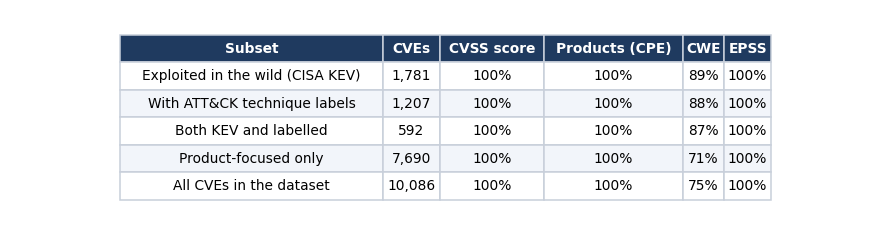

[figure saved] fig_dataset_severity.png


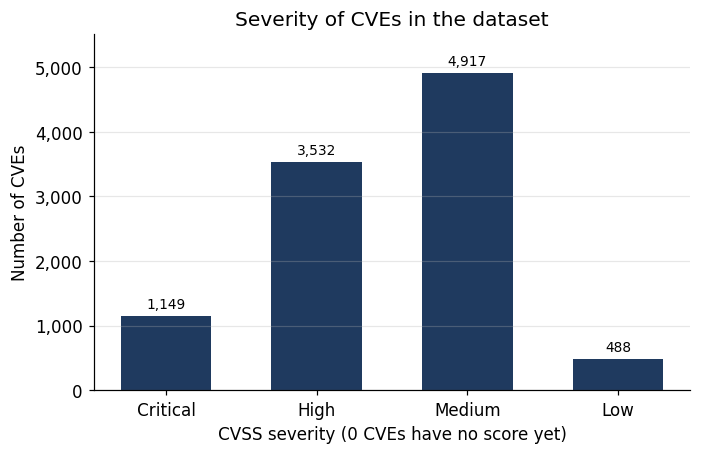

[figure saved] fig_dataset_cvss_hist.png


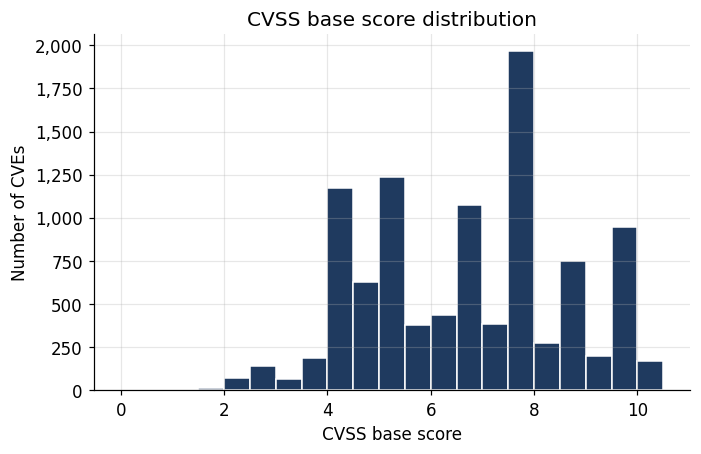

[figure saved] fig_dataset_top_cwe.png


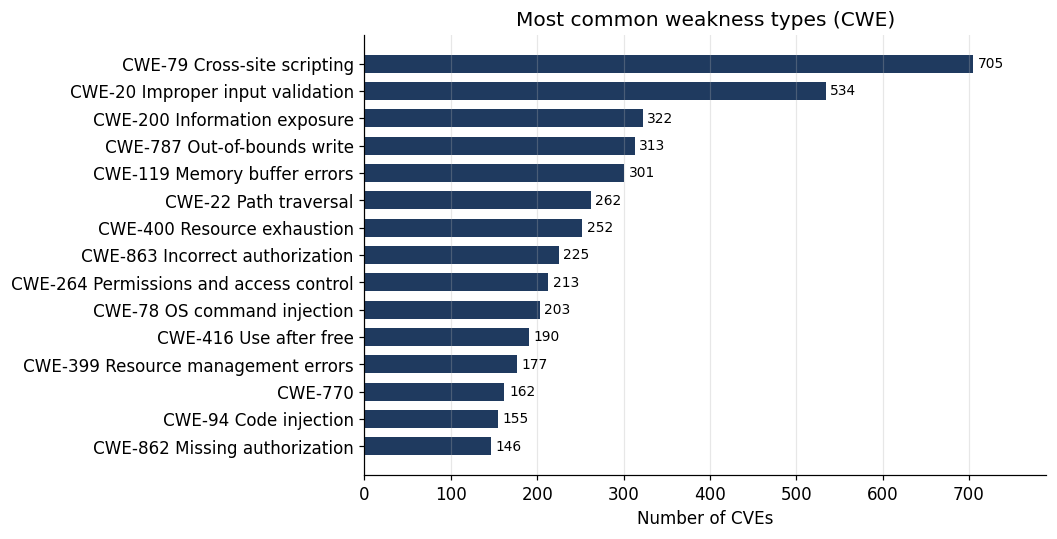

[figure saved] fig_dataset_top_products.png


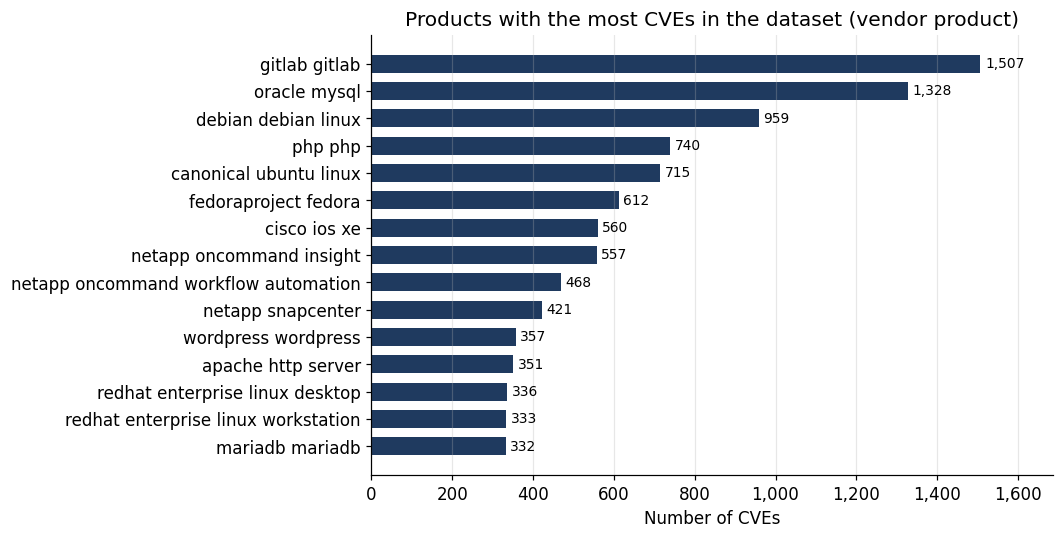

[figure saved] fig_dataset_pub_year.png


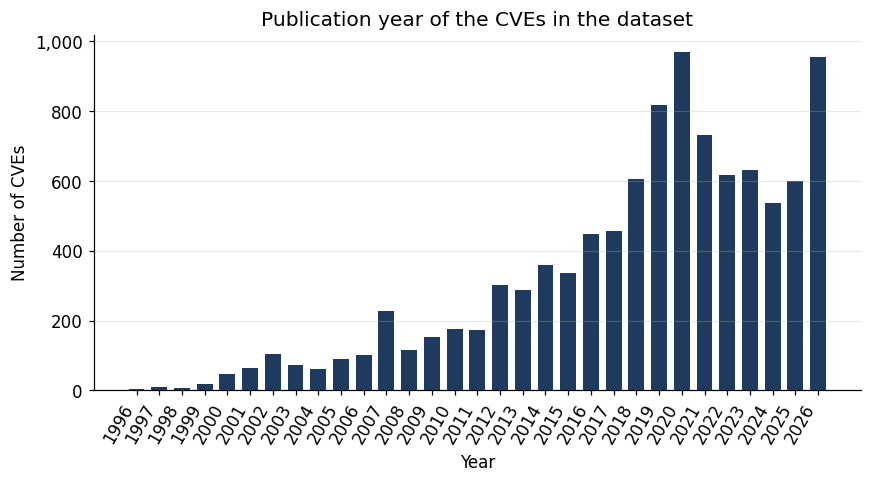

[figure saved] fig_nvd_cves_per_year.png


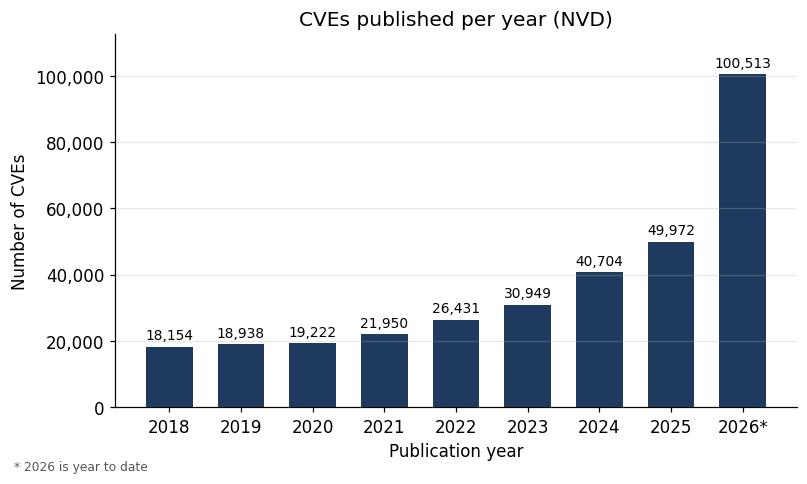


BLOCK 5 DONE


In [ ]:
# ============ BLOCK 5 : Parse NVD records into clean tables, join with KEV / EPSS / labels, make report figures ============
# Needs Block 1 and the data from Blocks 2-4 on Drive. CPU only, about 1-2 minutes. Parsed tables are cached on Drive.
import gzip, re
from collections import Counter, defaultdict
from matplotlib.ticker import FuncFormatter

FORCE_REPARSE = False                     # set True only if you want to re-parse the raw NVD files from scratch
NVD_DIR, PROC = DIRS['raw'] / 'nvd', DIRS['proc']
CVE_PATH, CWE_PATH, PROD_PATH = PROC / 'nvd_cves.parquet', PROC / 'nvd_cve_cwe.parquet', PROC / 'nvd_cve_products.parquet'
thousands = FuncFormatter(lambda x, _: f'{x:,.0f}')
vc = lambda s: {str(k): int(v) for k, v in s.items()}          # tidy printing of value counts
NAVY = '#1F3A5F'

CVSS_ORDER = [('cvssMetricV31', 'v31'), ('cvssMetricV40', 'v40'), ('cvssMetricV30', 'v30'), ('cvssMetricV2', 'v2')]

def pick(entries):
    """Several scores can exist per CVSS version (NVD's own + the vendor's): prefer the 'Primary' one."""
    if not entries: return None
    return sorted(entries, key=lambda e: e.get('type') != 'Primary')[0]

def parse_cpe(criteria):
    p = re.split(r'(?<!\\):', criteria or '')                    # CPE 2.3: cpe:2.3:part:vendor:product:version:...
    return {'part': p[2], 'vendor': p[3], 'product': p[4], 'version': p[5]} if len(p) >= 6 else None

def parse_record(c):
    row = {'cve_id': c['id'], 'published': c.get('published'), 'last_modified': c.get('lastModified'),
           'vuln_status': c.get('vulnStatus'), 'source_identifier': c.get('sourceIdentifier')}
    descs = c.get('descriptions', [])
    row['description'] = next((d['value'] for d in descs if d.get('lang') == 'en'), descs[0]['value'] if descs else None)
    row['desc_is_en'] = any(d.get('lang') == 'en' for d in descs)
    tags = []
    for t in c.get('cveTags') or []: tags += t.get('tags', []) if isinstance(t, dict) else [str(t)]
    row['cve_tags'] = '|'.join(sorted(set(tags)))
    metrics, used = c.get('metrics', {}), None
    for key, short in CVSS_ORDER:                                  # keep every available version, then choose one to rank by
        e = pick(metrics.get(key)); cd = (e or {}).get('cvssData', {})
        row[f'{short}_score'] = cd.get('baseScore')
        row[f'{short}_severity'] = (cd.get('baseSeverity') or (e or {}).get('baseSeverity') or None)
        row[f'{short}_vector'] = cd.get('vectorString')
        if used is None and e is not None and cd.get('baseScore') is not None: used = (short, e, cd)
    if used:
        short, e, cd = used
        row.update({'cvss_version_used': short, 'base_score': cd.get('baseScore'),
                    'severity': (row[f'{short}_severity'] or '').upper() or None,
                    'attack_vector': cd.get('attackVector') or cd.get('accessVector'),
                    'attack_complexity': cd.get('attackComplexity') or cd.get('accessComplexity'),
                    'privileges_required': cd.get('privilegesRequired'), 'user_interaction': cd.get('userInteraction'),
                    'exploitability_score': e.get('exploitabilityScore'), 'impact_score': e.get('impactScore')})
    refs = c.get('references', []); rtags = {t for r in refs for t in r.get('tags', [])}
    row.update({'n_references': len(refs), 'has_exploit_ref': 'Exploit' in rtags, 'has_patch_ref': 'Patch' in rtags,
                'has_vendor_advisory': 'Vendor Advisory' in rtags, 'cisa_exploit_add': c.get('cisaExploitAdd'),
                'cisa_action_due': c.get('cisaActionDue'), 'cisa_required_action': c.get('cisaRequiredAction'),
                'cisa_vuln_name': c.get('cisaVulnerabilityName')})
    cwes = [{'cve_id': c['id'], 'cwe_id': d.get('value'), 'source': w.get('source'), 'type': w.get('type')}
            for w in c.get('weaknesses', []) for d in w.get('description', []) if d.get('value')]
    prods = []
    for cf in c.get('configurations', []):
        for node in cf.get('nodes', []):
            for m in node.get('cpeMatch', []):
                if not m.get('vulnerable'): continue              # 'vulnerable: False' = platform it merely runs on, not affected
                p = parse_cpe(m.get('criteria'))
                if p: prods.append({'cve_id': c['id'], **p, 'v_start_incl': m.get('versionStartIncluding'), 'v_start_excl': m.get('versionStartExcluding'),
                                    'v_end_incl': m.get('versionEndIncluding'), 'v_end_excl': m.get('versionEndExcluding')})
    return row, cwes, prods

def parse_all():
    best, n_raw = {}, 0
    for p in sorted(NVD_DIR.glob('*.json.gz')):
        for v in json.load(gzip.open(p, 'rt'))['vulnerabilities']:
            n_raw += 1; c = v['cve']; lm = c.get('lastModified') or ''
            if c['id'] not in best or lm > best[c['id']][0]: best[c['id']] = (lm, c)   # same CVE in several shards: keep the newest
    rows, cwes, prods = [], [], []
    for _, c in best.values():
        r, w, p = parse_record(c); rows.append(r); cwes += w; prods += p
    cves = pd.DataFrame(rows)
    for col in ['v31_score', 'v40_score', 'v30_score', 'v2_score', 'base_score', 'exploitability_score', 'impact_score']:
        cves[col] = pd.to_numeric(cves[col], errors='coerce')
    for col in ['published', 'last_modified']: cves[col] = pd.to_datetime(cves[col], errors='coerce')
    cwe = pd.DataFrame(cwes).drop_duplicates(['cve_id', 'cwe_id', 'source']).reset_index(drop=True)
    prod = pd.DataFrame(prods).drop_duplicates().reset_index(drop=True)
    return cves, cwe, prod, n_raw

if CVE_PATH.exists() and CWE_PATH.exists() and PROD_PATH.exists() and not FORCE_REPARSE:
    print('[cache hit]  parsed NVD tables found on Drive')
    CVES, CWE, PROD = _load(CVE_PATH), _load(CWE_PATH), _load(PROD_PATH)
    N_RAW = int(_load(DIRS['results'] / 'nvd_parse_meta.json')['n_raw'])
else:
    t0 = time.time(); CVES, CWE, PROD, N_RAW = parse_all()
    _save(CVES, CVE_PATH); _save(CWE, CWE_PATH); _save(PROD, PROD_PATH); _save({'n_raw': N_RAW}, DIRS['results'] / 'nvd_parse_meta.json')
    print(f'[parsed]     {N_RAW:,} raw records -> {len(CVES):,} distinct CVEs in {time.time() - t0:.0f} s')

# ---------- Enrich: origin in the download, KEV, EPSS, ATT&CK labels, per-CVE counts ----------
idx = _load(NVD_DIR / '_index.json'); origin = defaultdict(set)
for name, ids in idx['shards'].items():
    tag = re.sub(r'_p\d{6}$', '', name)
    if tag.startswith('prod_'):
        for i in ids: origin[i].add(tag[5:])
KEV, EPSS, LAB = (_load(PROC / f'{n}.parquet') for n in ('kev', 'epss', 'cve_attack_labels'))
USABLE = LAB[LAB.status.isin(['ok', 'remapped'])]
C = CVES.copy()
rejected = (C.vuln_status == 'Rejected') | C.description.fillna('').str.startswith('** REJECT')
N_REJECTED = int(rejected.sum())
C = C[~rejected].reset_index(drop=True)
CWE, PROD = CWE[CWE.cve_id.isin(C.cve_id)], PROD[PROD.cve_id.isin(C.cve_id)]
C['queried_products'] = C.cve_id.map(lambda i: '|'.join(sorted(origin.get(i, []))))
C = C.merge(EPSS.rename(columns={'percentile': 'epss_percentile'}), on='cve_id', how='left')
C = C.merge(KEV[['cve_id', 'date_added', 'ransomware_use']].rename(columns={'date_added': 'kev_date_added'}), on='cve_id', how='left')
C = C.merge(USABLE.groupby('cve_id').technique_id.nunique().rename('n_techniques'), on='cve_id', how='left')
C['n_techniques'] = C.n_techniques.fillna(0).astype(int)
C['in_kev'], C['in_labelled'] = C.kev_date_added.notna(), C.n_techniques > 0
real_cwe = CWE[~CWE.cwe_id.str.startswith('NVD-CWE', na=False)]
C['n_cwe'] = C.cve_id.map(real_cwe.groupby('cve_id').cwe_id.nunique()).fillna(0).astype(int)
C['n_products'] = C.cve_id.map(PROD.assign(vp=PROD.vendor + ':' + PROD['product']).groupby('cve_id').vp.nunique()).fillna(0).astype(int)
C['has_cvss'], C['has_cpe'], C['has_cwe'], C['has_epss'] = C.base_score.notna(), C.n_products > 0, C.n_cwe > 0, C.epss.notna()
_save(C, PROC / 'cves_enriched.parquet')

def section(t): print(f'\n===== {t} =====')
section('Records')
print(f'raw records read   : {N_RAW:,} | distinct CVEs: {len(CVES):,} | duplicates merged: {N_RAW - len(CVES):,} | rejected CVEs dropped: {N_REJECTED} -> {len(C):,} kept')
print('NVD status         :', vc(C.vuln_status.value_counts(dropna=False)))
print('descriptions       : missing', int(C.description.isna().sum()), '| not in English:', int((~C.desc_is_en).sum()))
print('published          :', C.published.min().date(), '->', C.published.max().date())
print('CVE tags           :', dict(Counter(t for s in C.cve_tags for t in s.split('|') if t)))

section('Severity scores')
print('which CVSS version was used to rank:', vc(C.cvss_version_used.value_counts(dropna=False)))
print('CVEs with NO score at all          :', int((~C.has_cvss).sum()), '| by NVD status:', vc(C[~C.has_cvss].vuln_status.value_counts()))
print('severity           :', vc(C.severity.value_counts(dropna=False)))
print('attack vector      :', vc(C.attack_vector.value_counts(dropna=False)))

section('Weaknesses (CWE), products (CPE), exploitation signals')
print(f'CVEs with a real CWE id: {int(C.has_cwe.sum()):,} / {len(C):,} | placeholders only (NVD-CWE-Other/noinfo): {int(((C.n_cwe == 0) & C.cve_id.isin(CWE.cve_id)).sum())} | no CWE row at all: {int((~C.cve_id.isin(CWE.cve_id)).sum())}')
print(f'CVEs with >=1 vulnerable product (CPE): {int(C.has_cpe.sum()):,} / {len(C):,} | product rows: {len(PROD):,} | distinct vendor:product: {PROD.assign(k=PROD.vendor + ":" + PROD["product"]).k.nunique():,}')
print('CVE rows with exploit reference:', int(C.has_exploit_ref.sum()), '| with patch ref:', int(C.has_patch_ref.sum()))
print(f'EPSS available: {int(C.has_epss.sum()):,} / {len(C):,}')

section('Cross-checks')
k = C[C.in_kev]
m = pd.to_datetime(k.cisa_exploit_add, errors='coerce') == k.kev_date_added
print(f'KEV CVEs: {len(k):,} | NVD carries the CISA fields for {int(k.cisa_exploit_add.notna().sum()):,} | NVD date equals the KEV catalog date for {int(m.sum()):,}')
print(f'labelled CVEs: {int(C.in_labelled.sum()):,} | of them with CVSS {int((C.in_labelled & C.has_cvss).sum())}, CPE {int((C.in_labelled & C.has_cpe).sum())}, real CWE {int((C.in_labelled & C.has_cwe).sum())}')
pr = []
for name, v in _load(DIRS['cache'] / 'nvd_probe.json')['products'].items():
    if not v.get('total') or v['total'] > 5000: continue
    p = v['cpe'].split(':'); mine = PROD[(PROD.vendor == p[3]) & (PROD['product'] == p[4])].cve_id.nunique()
    pr.append({'product': name, 'NVD query total': v['total'], 'parsed (vulnerable only)': mine, 'share': f'{100 * mine / v["total"]:.0f}%'})
print('product check (parsed vs the Block 3 probe; <100% is expected: the query also matches platform-only entries):')
print(pd.DataFrame(pr).to_string(index=False))

section('Format notes (paste this part back to me)')
sample_ssvc, spath = None, DIRS['raw'] / 'nvd_sample_CVE-2021-44228.json'          # the Log4Shell sample is known to carry an SSVC block
if spath.exists(): sample_ssvc = (_load(spath)['vulnerabilities'][0]['cve'].get('metrics', {}).get('ssvcV203') or [None])[0]
print('ssvc sample   :', json.dumps(sample_ssvc)[:600] if sample_ssvc else 'not found in the saved sample')
print('metric keys   :', dict(Counter(k for s in sorted(NVD_DIR.glob('kev_p*.json.gz'))[:1] for v in json.load(gzip.open(s, 'rt'))['vulnerabilities'] for k in v['cve'].get('metrics', {}))))

# ---------- Report table: what the dataset contains ----------
def row(label, mask):
    s = C[mask]; pc = lambda col: f'{100 * s[col].mean():.0f}%' if len(s) else '-'
    return [label, f'{len(s):,}', pc('has_cvss'), pc('has_cpe'), pc('has_cwe'), pc('has_epss')]
comp = pd.DataFrame([row('Exploited in the wild (CISA KEV)', C.in_kev), row('With ATT&CK technique labels', C.in_labelled),
                     row('Both KEV and labelled', C.in_kev & C.in_labelled), row('Product-focused only', ~C.in_kev & ~C.in_labelled),
                     row('All CVEs in the dataset', C.cve_id.notna())],
                    columns=['Subset', 'CVEs', 'CVSS score', 'Products (CPE)', 'CWE', 'EPSS'])
save_table(comp, 'table_dataset_composition', 'Composition of the CVE dataset and completeness of each field (percent of CVEs in the subset)')

# ---------- Report figures (one figure per file) ----------
CWE_NAMES = {'CWE-79': 'Cross-site scripting', 'CWE-89': 'SQL injection', 'CWE-20': 'Improper input validation', 'CWE-22': 'Path traversal',
             'CWE-78': 'OS command injection', 'CWE-77': 'Command injection', 'CWE-787': 'Out-of-bounds write', 'CWE-125': 'Out-of-bounds read',
             'CWE-119': 'Memory buffer errors', 'CWE-416': 'Use after free', 'CWE-476': 'NULL pointer dereference', 'CWE-502': 'Unsafe deserialization',
             'CWE-94': 'Code injection', 'CWE-287': 'Improper authentication', 'CWE-306': 'Missing authentication', 'CWE-352': 'Cross-site request forgery',
             'CWE-434': 'Unrestricted file upload', 'CWE-200': 'Information exposure', 'CWE-269': 'Improper privilege management',
             'CWE-798': 'Hard-coded credentials', 'CWE-862': 'Missing authorization', 'CWE-863': 'Incorrect authorization', 'CWE-918': 'Server-side request forgery',
             'CWE-611': 'XML external entity', 'CWE-400': 'Resource exhaustion', 'CWE-190': 'Integer overflow', 'CWE-284': 'Improper access control',
             'CWE-264': 'Permissions and access control', 'CWE-399': 'Resource management errors', 'CWE-427': 'Uncontrolled search path',
             'CWE-122': 'Heap buffer overflow', 'CWE-121': 'Stack buffer overflow', 'CWE-668': 'Exposure of resource', 'CWE-444': 'HTTP request smuggling',
             'CWE-1321': 'Prototype pollution', 'CWE-843': 'Type confusion', 'CWE-59': 'Link following', 'CWE-312': 'Cleartext storage',
             'CWE-327': 'Broken cryptography', 'CWE-601': 'Open redirect', 'CWE-1188': 'Insecure default'}

sev_order = [s for s in ['CRITICAL', 'HIGH', 'MEDIUM', 'LOW', 'NONE'] if s in set(C.severity.dropna())]
sc = C.severity.value_counts().reindex(sev_order)
fig, ax = plt.subplots(figsize=(7, 4.2)); b = ax.bar([s.title() for s in sc.index], sc.values, color=NAVY, width=0.6)
ax.bar_label(b, labels=[f'{v:,}' for v in sc.values], padding=3, fontsize=9); ax.yaxis.set_major_formatter(thousands)
ax.set_title('Severity of CVEs in the dataset'); ax.set_ylabel('Number of CVEs'); ax.set_xlabel(f'CVSS severity ({int((~C.has_cvss).sum()):,} CVEs have no score yet)')
ax.grid(axis='x', visible=False); ax.set_ylim(0, sc.max() * 1.12)
save_fig(fig, 'fig_dataset_severity', 'Severity distribution of the CVEs in the dataset')

fig, ax = plt.subplots(figsize=(7, 4.2)); ax.hist(C.base_score.dropna(), bins=np.arange(0, 10.6, 0.5), color=NAVY, edgecolor='white')
ax.yaxis.set_major_formatter(thousands); ax.set_title('CVSS base score distribution'); ax.set_xlabel('CVSS base score'); ax.set_ylabel('Number of CVEs')
save_fig(fig, 'fig_dataset_cvss_hist', 'Distribution of CVSS base scores')

top = real_cwe.drop_duplicates(['cve_id', 'cwe_id']).cwe_id.value_counts().head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.2)); b = ax.barh([f'{i} {CWE_NAMES.get(i, "")}'.strip() for i in top.index], top.values, color=NAVY, height=0.65)
ax.bar_label(b, labels=[f'{v:,}' for v in top.values], padding=3, fontsize=9); ax.xaxis.set_major_formatter(thousands)
ax.set_title('Most common weakness types (CWE)'); ax.set_xlabel('Number of CVEs'); ax.grid(axis='y', visible=False); ax.set_xlim(0, top.max() * 1.12)
save_fig(fig, 'fig_dataset_top_cwe', 'The 15 most common CWE weakness types among the CVEs in the dataset')

pp = PROD.drop_duplicates(['cve_id', 'vendor', 'product']).assign(k=lambda d: d.vendor + ' ' + d['product']).k.value_counts().head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.2)); b = ax.barh(pp.index.str.replace('_', ' '), pp.values, color=NAVY, height=0.65)
ax.bar_label(b, labels=[f'{v:,}' for v in pp.values], padding=3, fontsize=9); ax.xaxis.set_major_formatter(thousands)
ax.set_title('Products with the most CVEs in the dataset (vendor product)'); ax.set_xlabel('Number of CVEs'); ax.grid(axis='y', visible=False); ax.set_xlim(0, pp.max() * 1.12)
save_fig(fig, 'fig_dataset_top_products', 'The 15 products with the most CVEs in the dataset')

yr = C.published.dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4.2)); b = ax.bar(yr.index.astype(str), yr.values, color=NAVY, width=0.7)
ax.yaxis.set_major_formatter(thousands); ax.set_title('Publication year of the CVEs in the dataset'); ax.set_xlabel('Year'); ax.set_ylabel('Number of CVEs')
ax.grid(axis='x', visible=False); plt.setp(ax.get_xticklabels(), rotation=60, ha='right')
save_fig(fig, 'fig_dataset_pub_year', 'Publication year of the CVEs in the dataset')

# redraw the Block 3 figure with thousands separators on the axis (the first version showed 20000 instead of 20,000)
yc = pd.Series({int(k): v for k, v in _load(DIRS['cache'] / 'nvd_probe.json')['year_counts'].items()}).sort_index(); cur = datetime.now().year
fig, ax = plt.subplots(figsize=(8, 4.4)); b = ax.bar([f'{y}*' if y == cur else str(y) for y in yc.index], yc.values, color=NAVY, width=0.65)
ax.bar_label(b, labels=[f'{v:,}' for v in yc.values], padding=3, fontsize=9); ax.yaxis.set_major_formatter(thousands)
ax.set_title('CVEs published per year (NVD)'); ax.set_xlabel('Publication year'); ax.set_ylabel('Number of CVEs'); ax.grid(axis='x', visible=False); ax.set_ylim(0, yc.max() * 1.12)
fig.text(0.01, -0.02, f'* {cur} is year to date', fontsize=8, color='#555555')
save_fig(fig, 'fig_nvd_cves_per_year', 'Number of CVEs published per year in the NVD')

_save({'cves': len(C), 'raw_records': N_RAW, 'with_cvss': int(C.has_cvss.sum()), 'with_cpe': int(C.has_cpe.sum()), 'with_cwe': int(C.has_cwe.sum()),
       'with_epss': int(C.has_epss.sum()), 'in_kev': int(C.in_kev.sum()), 'in_labelled': int(C.in_labelled.sum()), 'product_rows': len(PROD)},
      DIRS['results'] / 'nvd_summary.json')
print('\nBLOCK 5 DONE')

[raw pass]   10,087 CVE records read in 20 s

===== Loose end 1 : why did WordPress show only 61 % in Block 5? =====
CVEs where WordPress itself is vulnerable        : 357
CVEs where WordPress is only the platform        : 228   (a plugin or theme is the vulnerable part)
sum = 585 | NVD query total from Block 3 = 585 | explained: 100%  -> hypothesis CONFIRMED
what is vulnerable when WordPress is only the platform: {'cartpauj mingle-forum': 5, 'ithemes backupbuddy': 4, 'pressography wp_comment_remix_plugin': 3, 'roytanck wp-cumulus': 3, 'likno allwebmenus_plugin': 3, 'tom_braider count_per_day': 3, 'netweblogic login_with_ajax': 3, 'trioniclabs sentinel': 3, 'firestats firestats': 2, 'alex_rabe nextgen_gallery': 2}

===== Loose end 2 : CISA SSVC decisions =====
CVEs with an SSVC decision: 5,260 / 10,086  (version {'2.0.3': 5260})
  ssvc_exploitation     : {'none': 3215, 'active': 1776, 'poc': 269}
  ssvc_automatable      : {'no': 3843, 'yes': 1417}
  ssvc_technical_impact : {'partial': 

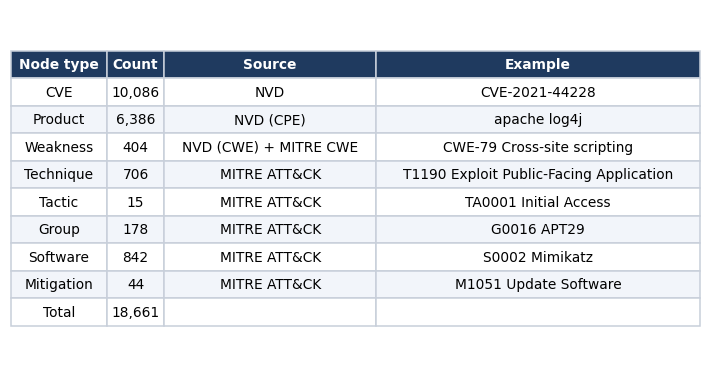

[table saved]  table_kg_edges.png  (+ .csv)


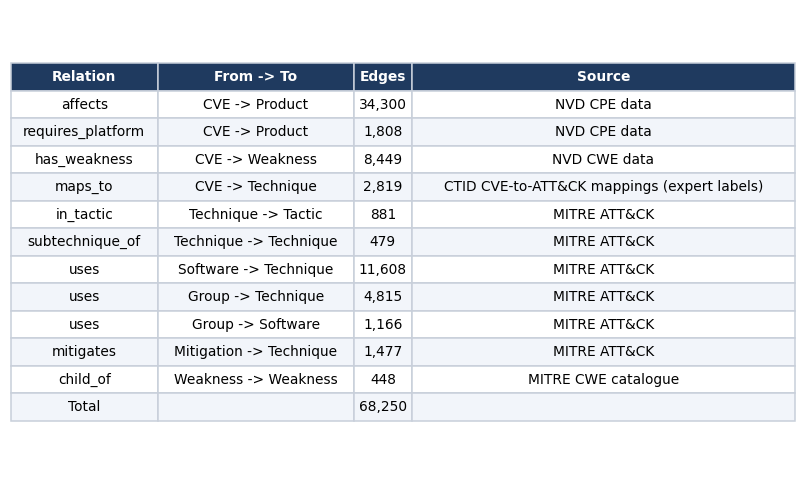

[figure saved] fig_graph_schema.png


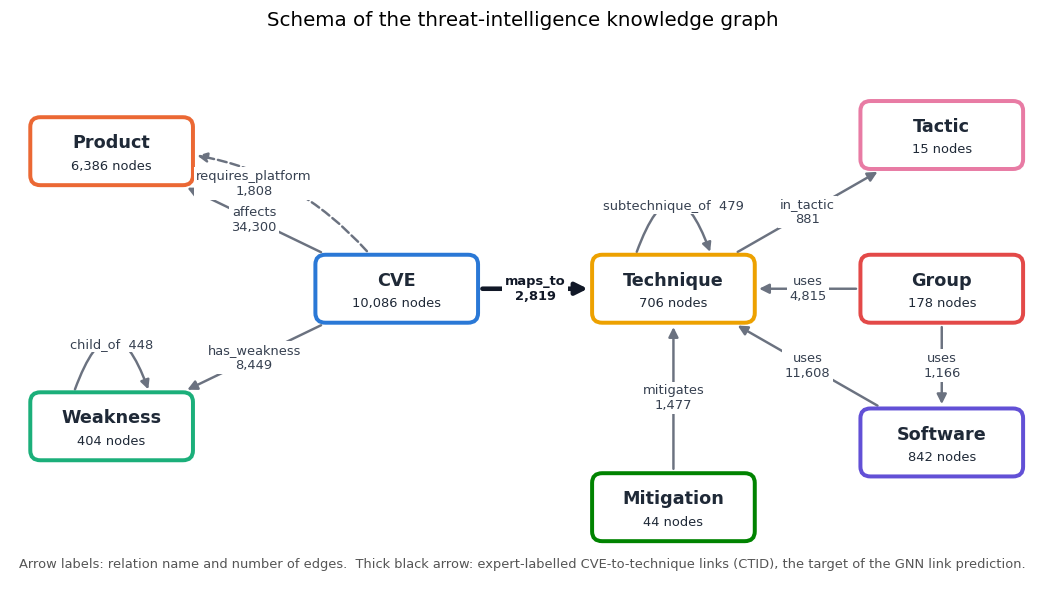

[figure saved] fig_graph_degree_ccdf.png


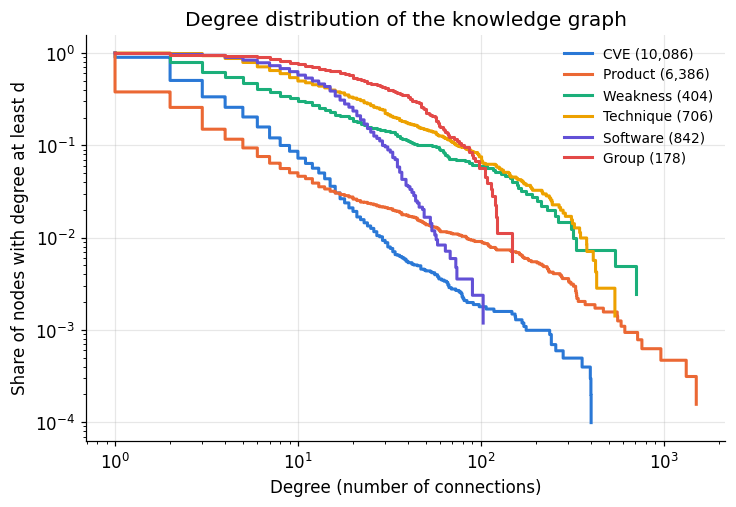

[figure saved] fig_graph_techniques_per_cve.png


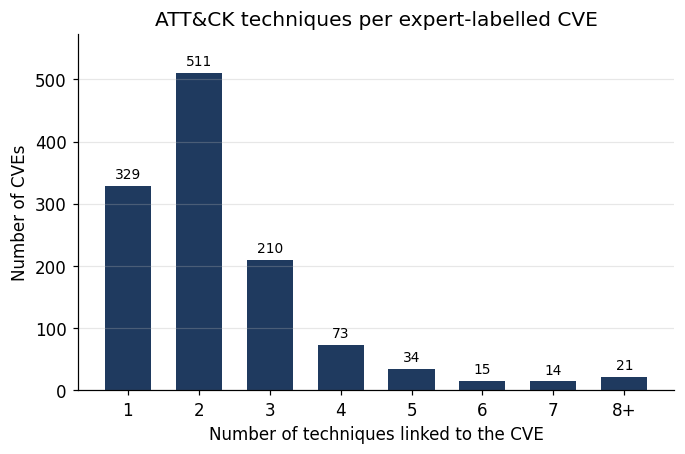

[figure saved] fig_graph_top_techniques.png


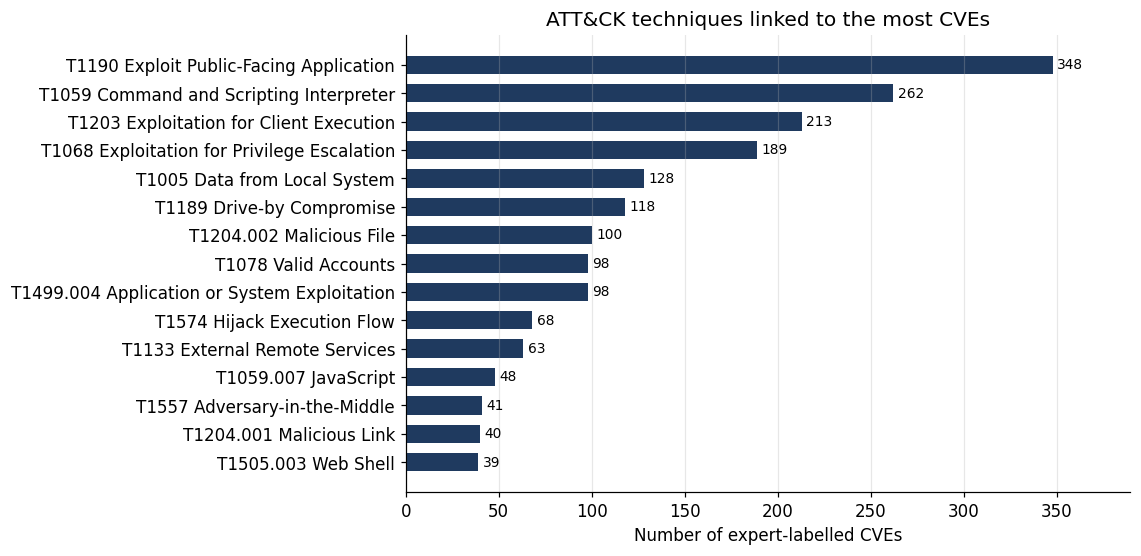


example subgraph around CVE-2021-44228
[figure saved] fig_graph_example_subgraph.png


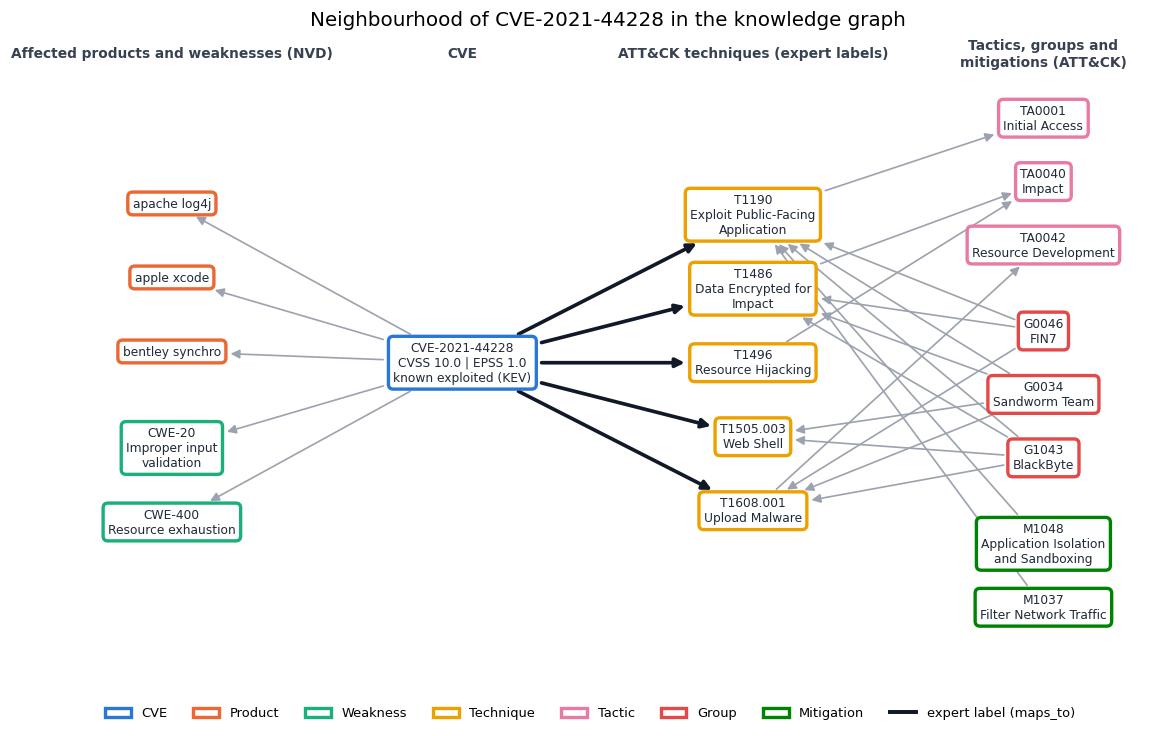

[figure saved] fig_graph_label_coverage.png


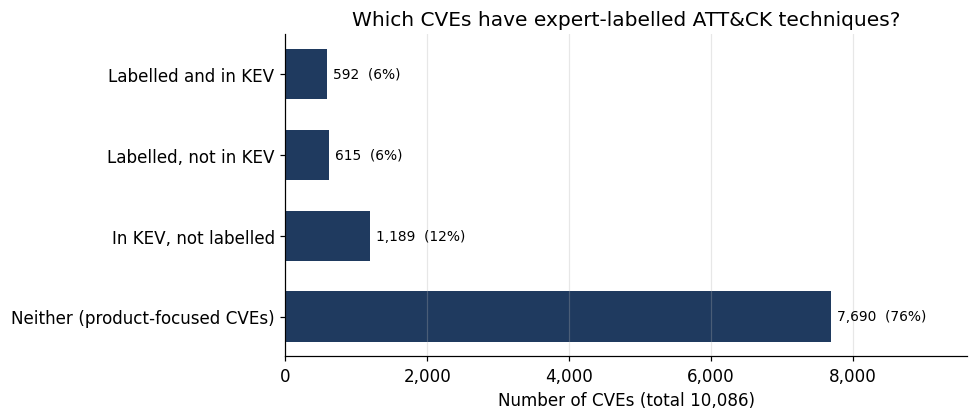

[figure saved] fig_dataset_top_cwe.png


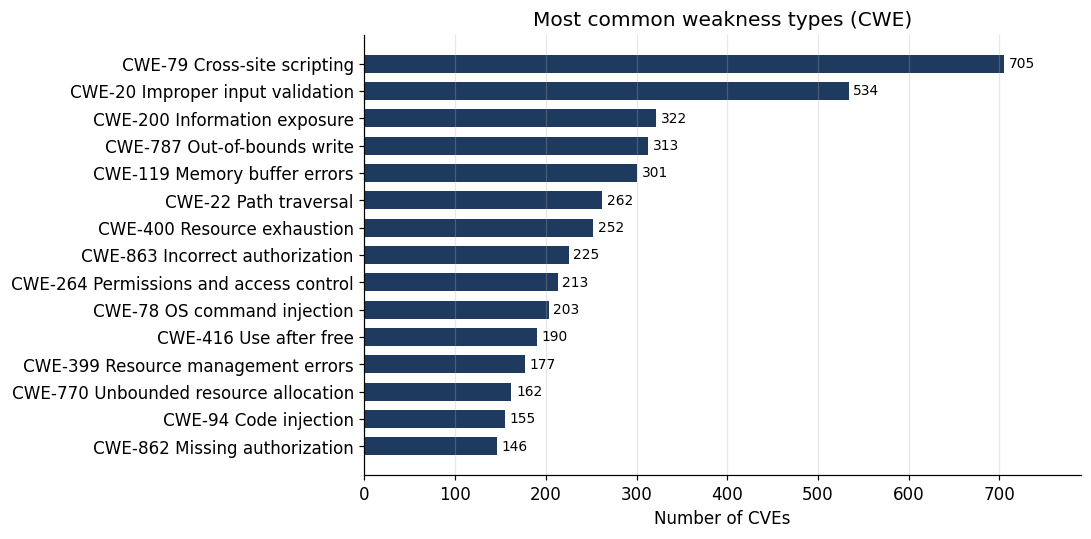

[figure saved] fig_dataset_severity.png


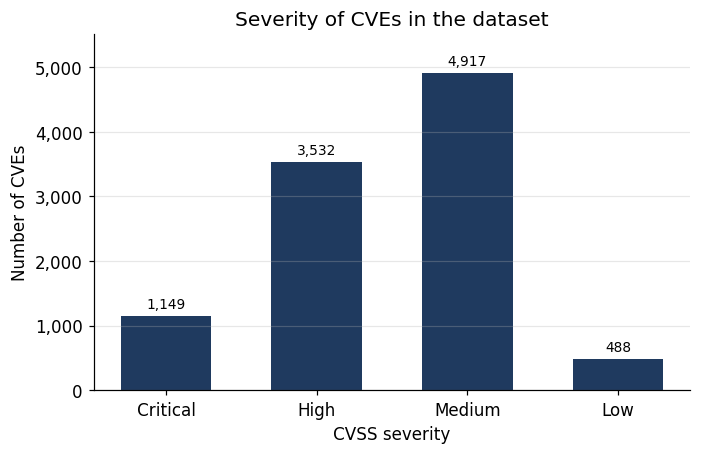


saved: kg_nodes.parquet (18,661 rows), kg_edges.parquet (68,250 rows), kg_stats.json | checks failed: none | 45 s

BLOCK 6 DONE


In [ ]:
# ============ BLOCK 6 : Build the knowledge graph, check it, describe it, make the report figures ============
# Needs Block 1 (helpers) and the tables from Blocks 2 and 5 on Drive. CPU only, about 2-4 minutes. Everything is cached on Drive.
if 'DIRS' not in globals(): raise RuntimeError('Run Block 1 first in this session (it defines the helper functions and the Drive folders).')
import gzip, re, zipfile, textwrap, xml.etree.ElementTree as ET
from collections import Counter
import requests
from scipy import sparse
from scipy.sparse.csgraph import connected_components, shortest_path
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Patch
from matplotlib.lines import Line2D

FORCE_REBUILD = False                         # True = redo the raw-file pass and the CWE download from scratch
PREFERRED_EXAMPLE = 'CVE-2021-44228'          # Log4Shell: the CVE drawn in the example-subgraph figure (a fallback is used if it is not suitable)
PROC, NVD_DIR, RAW = DIRS['proc'], DIRS['raw'] / 'nvd', DIRS['raw']
NAVY = '#1F3A5F'
thousands = FuncFormatter(lambda x, _: f'{x:,.0f}')
def section(t): print(f'\n===== {t} =====')
T0 = time.time()

# ------------------------------------------------------------------------------------------------------------
# PART 0 : two loose ends from Block 5  (SSVC decisions, the WordPress question) + names/hierarchy for weaknesses
# ------------------------------------------------------------------------------------------------------------
SSVC_PATH, PLAT_PATH, WP_PATH = PROC / 'nvd_ssvc.parquet', PROC / 'nvd_cve_platforms.parquet', DIRS['results'] / 'wordpress_check.json'
SSVC_COLS = ['ssvc_exploitation', 'ssvc_automatable', 'ssvc_technical_impact', 'ssvc_version', 'ssvc_role']
WP = ('wordpress', 'wordpress')

def parse_cpe(criteria):
    p = re.split(r'(?<!\\):', criteria or '')
    return {'part': p[2], 'vendor': p[3], 'product': p[4]} if len(p) >= 6 else None

def ssvc_of(c):
    """CISA's SSVC decision (exploitation / automatable / technical impact) as a flat dict, or None."""
    for key, arr in (c.get('metrics') or {}).items():
        if not key.lower().startswith('ssvc'): continue
        for e in sorted(arr or [], key=lambda e: (e.get('ssvcData') or {}).get('role') != 'CISA Coordinator'):
            d, opts = e.get('ssvcData') or {}, {}
            for o in d.get('options') or []:                         # real format: [{'exploitation': 'active'}, {'automatable': 'yes'}, ...]
                for k, v in o.items(): opts[re.sub('[^a-z]', '', k.lower())] = str(v).lower()
            if not opts:                                              # tolerate a flat dict as well
                for k, v in d.items():
                    if k.lower() in ('exploitation', 'automatable', 'technicalimpact'): opts[k.lower()] = str(v).lower()
            if opts:
                return {'ssvc_exploitation': opts.get('exploitation'), 'ssvc_automatable': opts.get('automatable'),
                        'ssvc_technical_impact': opts.get('technicalimpact'), 'ssvc_version': d.get('version'), 'ssvc_role': d.get('role')}
    return None

def raw_pass():
    """One pass over the raw NVD files (newest copy of every CVE): SSVC decisions, 'platform only' CPE entries, the WordPress check."""
    best = {}
    for p in sorted(NVD_DIR.glob('*.json.gz')):
        for v in json.load(gzip.open(p, 'rt'))['vulnerabilities']:
            c = v['cve']; lm = c.get('lastModified') or ''
            if c['id'] in best and lm <= best[c['id']][0]: continue
            vuln, plat = set(), set()
            for cf in c.get('configurations', []):
                for node in cf.get('nodes', []):
                    for m in node.get('cpeMatch', []):
                        q = parse_cpe(m.get('criteria'))
                        if q: (vuln if m.get('vulnerable') else plat).add((q['part'], q['vendor'], q['product']))
            best[c['id']] = (lm, ssvc_of(c), sorted(plat - vuln), sorted(vuln))
    ssvc = pd.DataFrame([{'cve_id': k, **v[1]} for k, v in best.items() if v[1]], columns=['cve_id'] + SSVC_COLS)
    plat = pd.DataFrame([{'cve_id': k, 'part': a, 'vendor': b, 'product': c_} for k, v in best.items() for a, b, c_ in v[2]],
                        columns=['cve_id', 'part', 'vendor', 'product'])
    wp_vuln = [k for k, v in best.items() if any(x[1:] == WP for x in v[3])]
    wp_plat = [k for k, v in best.items() if not any(x[1:] == WP for x in v[3]) and any(x[1:] == WP for x in v[2])]
    plugins = Counter(f'{x[1]} {x[2]}' for k in wp_plat for x in set(best[k][3]))
    meta = {'records': len(best), 'wordpress_vulnerable': len(wp_vuln), 'wordpress_platform_only': len(wp_plat),
            'top_vulnerable_products_when_wordpress_is_platform_only': dict(plugins.most_common(10))}
    return ssvc, plat, meta

if SSVC_PATH.exists() and PLAT_PATH.exists() and WP_PATH.exists() and not FORCE_REBUILD:
    print('[cache hit]  raw-file pass (SSVC, platforms, WordPress check)')
    SSVC, PLAT, WPM = _load(SSVC_PATH), _load(PLAT_PATH), _load(WP_PATH)
else:
    t = time.time(); SSVC, PLAT, WPM = raw_pass()
    _save(SSVC, SSVC_PATH); _save(PLAT, PLAT_PATH); _save(WPM, WP_PATH)
    print(f'[raw pass]   {WPM["records"]:,} CVE records read in {time.time() - t:.0f} s')

section('Loose end 1 : why did WordPress show only 61 % in Block 5?')
probe = (_load(DIRS['cache'] / 'nvd_probe.json')['products'].get('WordPress') or {}).get('total')
v, p = WPM['wordpress_vulnerable'], WPM['wordpress_platform_only']
print(f'CVEs where WordPress itself is vulnerable        : {v}')
print(f'CVEs where WordPress is only the platform        : {p}   (a plugin or theme is the vulnerable part)')
if probe: print(f'sum = {v + p} | NVD query total from Block 3 = {probe} | explained: {100 * (v + p) / probe:.0f}%  ->', 'hypothesis CONFIRMED' if (v + p) >= 0.97 * probe else 'hypothesis NOT fully confirmed')
print('what is vulnerable when WordPress is only the platform:', WPM['top_vulnerable_products_when_wordpress_is_platform_only'])

C = _load(PROC / 'cves_enriched.parquet')
C = C.drop(columns=[c for c in SSVC_COLS if c in C.columns]).merge(SSVC[['cve_id'] + SSVC_COLS], on='cve_id', how='left')
_save(C, PROC / 'cves_enriched.parquet')                                     # cves_enriched now also carries the SSVC columns

section('Loose end 2 : CISA SSVC decisions')
print(f'CVEs with an SSVC decision: {int(C.ssvc_exploitation.notna().sum()):,} / {len(C):,}  (version {dict(Counter(C.ssvc_version.dropna()))})')
for col in ['ssvc_exploitation', 'ssvc_automatable', 'ssvc_technical_impact']: print(f'  {col:22s}:', {str(k): int(n) for k, n in C[col].value_counts().items()})
ct = pd.crosstab(C.in_kev.map({True: 'in KEV', False: 'not in KEV'}), C.ssvc_exploitation.fillna('(no SSVC)'))
print('SSVC "exploitation" vs the CISA KEV catalogue:'); print(ct.to_string())

# ---- CWE names + hierarchy from the official MITRE catalogue (falls back to a small built-in list if the download fails) ----
CWE_URL = 'https://cwe.mitre.org/data/xml/cwec_latest.xml.zip'
CWE_ZIP, CAT_PATH, HIER_PATH = RAW / 'cwec_latest.xml.zip', PROC / 'cwe_catalog.parquet', PROC / 'cwe_hierarchy.parquet'

def load_cwe_catalog():
    if CAT_PATH.exists() and HIER_PATH.exists() and not FORCE_REBUILD: return _load(CAT_PATH), _load(HIER_PATH), 'cache'
    try:
        if not CWE_ZIP.exists() or FORCE_REBUILD:
            r = requests.get(CWE_URL, timeout=180); r.raise_for_status()
            tmp = CWE_ZIP.with_suffix('.tmp'); tmp.write_bytes(r.content); tmp.replace(CWE_ZIP)
        z = zipfile.ZipFile(CWE_ZIP)
        root = ET.fromstring(z.read(next(n for n in z.namelist() if n.lower().endswith('.xml'))))
        ns = root.tag.split('}')[0] + '}' if root.tag.startswith('{') else ''
        cat, hier = [], []
        for kind in ('Weakness', 'Category'):
            for el in root.iter(ns + kind):
                if not el.get('ID'): continue
                cat.append({'cwe_id': 'CWE-' + el.get('ID'), 'name': el.get('Name'), 'kind': kind.lower(), 'abstraction': el.get('Abstraction'), 'status': el.get('Status')})
                if kind == 'Weakness':
                    for rel in el.iter(ns + 'Related_Weakness'):
                        if rel.get('Nature') == 'ChildOf' and rel.get('View_ID') == '1000' and rel.get('CWE_ID'):   # view 1000 = "Research Concepts" tree
                            hier.append({'child': 'CWE-' + el.get('ID'), 'parent': 'CWE-' + rel.get('CWE_ID')})
        cat, hier = pd.DataFrame(cat).drop_duplicates('cwe_id'), pd.DataFrame(hier).drop_duplicates()
        if len(cat) < 500 or hier.empty: raise ValueError(f'catalogue looks incomplete ({len(cat)} entries)')
        _save(cat, CAT_PATH); _save(hier, HIER_PATH)
        return cat, hier, 'downloaded'
    except Exception as e:
        print('  WARNING: CWE catalogue not available (' + type(e).__name__ + ': ' + str(e)[:100] + ') -> built-in short names only, no weakness hierarchy')
        return pd.DataFrame(columns=['cwe_id', 'name', 'kind', 'abstraction', 'status']), pd.DataFrame(columns=['child', 'parent']), 'unavailable'

CAT, HIER, cat_src = load_cwe_catalog()
section('CWE catalogue')
print(f'source: {cat_src} | entries: {len(CAT):,} | parent links (research-concepts tree): {len(HIER):,}')

SHORT_CWE = {'CWE-79': 'Cross-site scripting', 'CWE-89': 'SQL injection', 'CWE-20': 'Improper input validation', 'CWE-22': 'Path traversal',
             'CWE-78': 'OS command injection', 'CWE-77': 'Command injection', 'CWE-787': 'Out-of-bounds write', 'CWE-125': 'Out-of-bounds read',
             'CWE-119': 'Memory buffer errors', 'CWE-416': 'Use after free', 'CWE-476': 'NULL pointer dereference', 'CWE-502': 'Unsafe deserialization',
             'CWE-94': 'Code injection', 'CWE-287': 'Improper authentication', 'CWE-306': 'Missing authentication', 'CWE-352': 'Cross-site request forgery',
             'CWE-434': 'Unrestricted file upload', 'CWE-200': 'Information exposure', 'CWE-269': 'Improper privilege management',
             'CWE-798': 'Hard-coded credentials', 'CWE-862': 'Missing authorization', 'CWE-863': 'Incorrect authorization', 'CWE-918': 'Server-side request forgery',
             'CWE-611': 'XML external entity', 'CWE-400': 'Resource exhaustion', 'CWE-190': 'Integer overflow', 'CWE-284': 'Improper access control',
             'CWE-264': 'Permissions and access control', 'CWE-399': 'Resource management errors', 'CWE-427': 'Uncontrolled search path',
             'CWE-122': 'Heap buffer overflow', 'CWE-121': 'Stack buffer overflow', 'CWE-668': 'Exposure of resource', 'CWE-444': 'HTTP request smuggling',
             'CWE-1321': 'Prototype pollution', 'CWE-843': 'Type confusion', 'CWE-59': 'Link following', 'CWE-312': 'Cleartext storage',
             'CWE-327': 'Broken cryptography', 'CWE-601': 'Open redirect', 'CWE-1188': 'Insecure default', 'CWE-770': 'Unbounded resource allocation',
             'CWE-74': 'Injection', 'CWE-120': 'Classic buffer overflow', 'CWE-295': 'Improper certificate validation', 'CWE-1333': 'Regex denial of service',
             'CWE-noinfo': 'Insufficient information'}
CAT_NAME = dict(zip(CAT.cwe_id, CAT['name']))
def short_cwe(cid):
    if cid in SHORT_CWE: return SHORT_CWE[cid]
    n = re.sub(r'\s*\(.*?\)', '', CAT_NAME.get(cid, '') or '').strip()
    return (n[:38] + '...') if len(n) > 40 else n

# ------------------------------------------------------------------------------------------------------------
# PART 1 : nodes
# ------------------------------------------------------------------------------------------------------------
def clean(v):                                  # make a value JSON-safe (numpy types, NaN, timestamps)
    if v is pd.NA or v is pd.NaT: return None
    if isinstance(v, pd.Timestamp): return None if pd.isna(v) else v.strftime('%Y-%m-%d')
    if isinstance(v, (np.bool_, bool)): return bool(v)
    if isinstance(v, (np.integer,)): return int(v)
    if isinstance(v, (np.floating, float)): return None if np.isnan(v) else round(float(v), 4)
    return None if v is None or v is pd.NaT else v

# NOTE for the GNN (Block 11): the labels (n_techniques / in_labelled / maps_to edges) are deliberately NOT stored as node attributes,
# and the KEV fields (in_kev, kev_date_added, ransomware_use) must be left out of the GNN's input features as well.
CVE_ATTRS = ['published', 'base_score', 'severity', 'cvss_version_used', 'attack_vector', 'attack_complexity', 'privileges_required', 'user_interaction',
             'epss', 'epss_percentile', 'in_kev', 'kev_date_added', 'ransomware_use', 'has_exploit_ref', 'has_patch_ref', 'has_vendor_advisory',
             'n_references', 'ssvc_exploitation', 'ssvc_automatable', 'ssvc_technical_impact', 'vuln_status']
CWE_T = _load(PROC / 'nvd_cve_cwe.parquet'); PROD = _load(PROC / 'nvd_cve_products.parquet')
TECH, TACT, ATT, GRP, SW, MIT = (_load(PROC / f'{n}.parquet') for n in ('attack_techniques', 'attack_tactics', 'attack_edges', 'attack_groups', 'attack_software', 'attack_mitigations'))
LAB = _load(PROC / 'cve_attack_labels.parquet'); USABLE = LAB[LAB.status.isin(['ok', 'remapped'])]
KEV = _load(PROC / 'kev.parquet')
cveset = set(C.cve_id)
CWE_T, PROD, PLAT = CWE_T[CWE_T.cve_id.isin(cveset)], PROD[PROD.cve_id.isin(cveset)], PLAT[PLAT.cve_id.isin(cveset)]   # drops the rejected CVE

def mk(frame, ntype, prefix, ext, name, text=None, attrs=None):
    n = len(frame)
    return pd.DataFrame({'node_id': prefix + frame[ext].astype(str), 'node_type': ntype, 'ext_id': frame[ext].astype(str),
                         'name': frame[name].astype(str) if isinstance(name, str) else name,
                         'text': (frame[text].fillna('') if text else ''), 'attrs': attrs if attrs is not None else ['{}'] * n})
dumps = lambda recs: [json.dumps({k: clean(v) for k, v in r.items()}, default=str) for r in recs]

n_cve = mk(C, 'CVE', 'cve:', 'cve_id', 'cve_id', text='description', attrs=dumps(C[CVE_ATTRS].to_dict('records')))

pk = PROD.drop_duplicates(['part', 'vendor', 'product']).copy()
cnt = PROD.drop_duplicates(['cve_id', 'part', 'vendor', 'product']).groupby(['part', 'vendor', 'product']).size().rename('n_cves').reset_index()
pk = pk[['part', 'vendor', 'product']].merge(cnt, on=['part', 'vendor', 'product'])
pk['ext'] = pk.part + ':' + pk.vendor + ':' + pk['product']
pk['nm'] = (pk.vendor + ' ' + pk['product']).str.replace('_', ' ').str.replace('\\', '', regex=False)
n_prod = mk(pk, 'Product', 'prod:', 'ext', pk['nm'], attrs=dumps(pk[['part', 'vendor', 'product', 'n_cves']].to_dict('records')))

real_cwe = CWE_T[~CWE_T.cwe_id.str.startswith('NVD-CWE', na=False)]
used = set(real_cwe.cwe_id)
parent_of = HIER.groupby('child').parent.apply(list).to_dict() if len(HIER) else {}
allw, frontier = set(used), set(used)
while frontier:                                                     # add the ancestors of every used weakness (so the tree is connected)
    frontier = {p for c in frontier for p in parent_of.get(c, [])} - allw; allw |= frontier
kind_of, abs_of = dict(zip(CAT.cwe_id, CAT.kind)), dict(zip(CAT.cwe_id, CAT.abstraction))
wk = pd.DataFrame({'cwe_id': sorted(allw)})
wk['nm'] = [CAT_NAME.get(c) or SHORT_CWE.get(c) or c for c in wk.cwe_id]
n_weak = mk(wk, 'Weakness', 'cwe:', 'cwe_id', wk['nm'], text=None,
            attrs=dumps([{'short': short_cwe(c), 'kind': kind_of.get(c), 'abstraction': abs_of.get(c), 'used_by_cves': c in used} for c in wk.cwe_id]))

n_tech = mk(TECH, 'Technique', 'tech:', 'technique_id', 'name', text='description',
            attrs=dumps(TECH[['is_sub', 'tactics', 'platforms']].to_dict('records')))
n_tact = mk(TACT, 'Tactic', 'tactic:', 'tactic_id', 'name', attrs=dumps(TACT[['shortname']].to_dict('records')))
n_grp = mk(GRP, 'Group', 'group:', 'group_id', 'name', text='description', attrs=dumps(GRP[['aliases']].to_dict('records')))
n_sw = mk(SW, 'Software', 'sw:', 'software_id', 'name', text='description', attrs=dumps(SW[['kind']].to_dict('records')))
n_mit = mk(MIT, 'Mitigation', 'mit:', 'mitigation_id', 'name', text='description')
NODES = pd.concat([n_cve, n_prod, n_weak, n_tech, n_tact, n_grp, n_sw, n_mit], ignore_index=True)
NTYPES = ['CVE', 'Product', 'Weakness', 'Technique', 'Tactic', 'Group', 'Software', 'Mitigation']
ntype = dict(zip(NODES.node_id, NODES.node_type)); nset = set(NODES.node_id)

# ------------------------------------------------------------------------------------------------------------
# PART 2 : edges
# ------------------------------------------------------------------------------------------------------------
def frame(src, rel, dst, source, attr=''):
    d = pd.DataFrame({'src': list(src), 'dst': list(dst)}); d['rel'] = rel
    d['source'] = source if isinstance(source, str) else list(source); d['attr'] = attr if isinstance(attr, str) else list(attr)
    return d[['src', 'rel', 'dst', 'source', 'attr']]
pid = lambda d: 'prod:' + d.part + ':' + d.vendor + ':' + d['product']
frames, notes = [], []

a = PROD.drop_duplicates(['cve_id', 'part', 'vendor', 'product'])
frames.append(frame('cve:' + a.cve_id, 'affects', pid(a), 'nvd_cpe'))

pl = PLAT.drop_duplicates(['cve_id', 'part', 'vendor', 'product']).copy(); pl['dst'] = pid(pl)
pl = pl[pl.dst.isin(nset)]                                              # platforms are linked only to products that already exist in the graph
pl = pl[~(('cve:' + pl.cve_id) + '|' + pl.dst).isin(set(frames[0].src + '|' + frames[0].dst))]
frames.append(frame('cve:' + pl.cve_id, 'requires_platform', pl.dst, 'nvd_cpe'))

w = real_cwe.groupby(['cve_id', 'cwe_id']).agg(attr=('type', lambda s: '|'.join(sorted(set(map(str, s)))))).reset_index()
frames.append(frame('cve:' + w.cve_id, 'has_weakness', 'cwe:' + w.cwe_id, 'nvd_cwe', w.attr))

lb = USABLE[USABLE.cve_id.isin(cveset) & USABLE.technique_id.isin(set(TECH.technique_id))]
notes.append(f'label rows dropped (CVE or technique not in the graph): {len(USABLE) - len(lb)}')
lb = lb.groupby(['cve_id', 'technique_id']).agg(source=('source', lambda s: '|'.join(sorted(set(map(str, s))))),
                                                attr=('mapping_type', lambda s: '|'.join(sorted(set(map(str, s)))))).reset_index()
frames.append(frame('cve:' + lb.cve_id, 'maps_to', 'tech:' + lb.technique_id, lb.source, lb.attr))

short2id, unk = dict(zip(TACT.shortname, TACT.tactic_id)), Counter()
tt = []
for r in TECH.itertuples():
    for s in (r.tactics or '').split('|'):
        if not s: continue
        if s in short2id: tt.append(('tech:' + r.technique_id, 'tactic:' + short2id[s]))
        else: unk[s] += 1
frames.append(frame([x for x, _ in tt], 'in_tactic', [y for _, y in tt], 'attack'))
notes.append(f'tactic names not found in the tactic table: {dict(unk) or 0}')

is_sub = dict(zip(TECH.technique_id, TECH.is_sub)); subs, swapped, bad = [], 0, 0
for r in ATT[ATT.rel == 'subtechnique-of'].itertuples():
    s, d = r.src_id, r.dst_id
    if is_sub.get(s) and not is_sub.get(d): subs.append((s, d))
    elif is_sub.get(d) and not is_sub.get(s): subs.append((d, s)); swapped += 1
    else: bad += 1
frames.append(frame(['tech:' + s for s, _ in subs], 'subtechnique_of', ['tech:' + d for _, d in subs], 'attack'))
notes.append(f'subtechnique_of edges: {len(subs)} (direction swapped for {swapped}, unusable {bad})')

for rel in ('uses', 'mitigates'):
    x = ATT[ATT.rel == rel]
    pre = {'technique': 'tech:', 'group': 'group:', 'software': 'sw:', 'mitigation': 'mit:'}
    frames.append(frame(x.src_type.map(pre) + x.src_id, rel, x.dst_type.map(pre) + x.dst_id, 'attack'))

hh = HIER[HIER.child.isin(allw) & HIER.parent.isin(allw)]
frames.append(frame('cwe:' + hh.child, 'child_of', 'cwe:' + hh.parent, 'mitre_cwe'))

EDGES = pd.concat(frames, ignore_index=True).drop_duplicates(['src', 'rel', 'dst'])
ok = EDGES.src.isin(nset) & EDGES.dst.isin(nset)
dangling = EDGES[~ok].rel.value_counts().to_dict()
EDGES = EDGES[ok].copy(); EDGES['src_type'], EDGES['dst_type'] = EDGES.src.map(ntype), EDGES.dst.map(ntype)
EDGES = EDGES[['src', 'rel', 'dst', 'src_type', 'dst_type', 'source', 'attr']].reset_index(drop=True)
RELS = ['affects', 'requires_platform', 'has_weakness', 'maps_to', 'in_tactic', 'subtechnique_of', 'uses', 'mitigates', 'child_of']

section('Knowledge graph built')
print(f'nodes: {len(NODES):,} | edges: {len(EDGES):,} | dangling edges dropped: {dangling or 0}')
for n_ in notes: print('  note:', n_)
print('nodes by type :', {t: int((NODES.node_type == t).sum()) for t in NTYPES})
print('edges by type :', {r: int((EDGES.rel == r).sum()) for r in RELS})
if cat_src != 'unavailable':
    miss = sorted(c for c in used if c not in CAT_NAME)
    print(f'weakness nodes: {len(n_weak):,} ({len(used)} used by CVEs + {len(allw) - len(used)} ancestors) | used CWE ids missing from the MITRE catalogue: {len(miss)} {miss[:8]}')

# ------------------------------------------------------------------------------------------------------------
# PART 3 : integrity checks
# ------------------------------------------------------------------------------------------------------------
section('Integrity checks')
SCHEMA = {('affects', 'CVE', 'Product'), ('requires_platform', 'CVE', 'Product'), ('has_weakness', 'CVE', 'Weakness'), ('maps_to', 'CVE', 'Technique'),
          ('in_tactic', 'Technique', 'Tactic'), ('subtechnique_of', 'Technique', 'Technique'), ('uses', 'Group', 'Technique'), ('uses', 'Group', 'Software'),
          ('uses', 'Software', 'Technique'), ('mitigates', 'Mitigation', 'Technique'), ('child_of', 'Weakness', 'Weakness')}
seen = set(map(tuple, EDGES[['rel', 'src_type', 'dst_type']].drop_duplicates().values))
deg = pd.concat([EDGES.src, EDGES.dst]).value_counts().reindex(NODES.node_id).fillna(0).astype(int)
deg.index = NODES.node_id
isolated = NODES[NODES.node_id.map(deg) == 0].node_type.value_counts().to_dict()
exp_e = EDGES[EDGES.rel == 'maps_to']
sub_e = EDGES[EDGES.rel == 'subtechnique_of']
techs_with_tactic = set(EDGES[EDGES.rel == 'in_tactic'].src)
kev_ok = set(KEV.cve_id) & cveset
checks = [
    ('node ids are unique', NODES.node_id.is_unique, f'{len(NODES):,} nodes'),
    ('no duplicate edges (src, rel, dst)', not EDGES.duplicated(['src', 'rel', 'dst']).any(), f'{len(EDGES):,} edges'),
    ('every edge endpoint is a node', EDGES.src.isin(nset).all() and EDGES.dst.isin(nset).all(), ''),
    ('only schema-allowed (relation, from-type, to-type) combinations', seen <= SCHEMA, '' if seen <= SCHEMA else f'unexpected: {sorted(seen - SCHEMA)}'),
    ('no self-loops', (EDGES.src != EDGES.dst).all(), ''),
    ('sub-technique -> parent technique direction is right', bool(len(sub_e)) and all(is_sub.get(s[5:]) and not is_sub.get(d[5:]) for s, d in zip(sub_e.src, sub_e.dst)), f'{len(sub_e)} edges'),
    ('every technique belongs to at least one tactic', set(TECH.technique_id.map(lambda x: 'tech:' + x)) <= techs_with_tactic, f'{len(techs_with_tactic)} of {len(TECH)}'),
    ('every labelled CVE has a maps_to edge', exp_e.src.nunique() == USABLE[USABLE.cve_id.isin(cveset)].cve_id.nunique(), f'{exp_e.src.nunique():,} CVEs, {len(exp_e):,} links'),
    ('every KEV CVE is a node', len(kev_ok) == len(set(KEV.cve_id)), f'{len(kev_ok):,} of {len(set(KEV.cve_id)):,}'),
    ('no label information stored in CVE node attributes', not ({'n_techniques', 'in_labelled'} & set(CVE_ATTRS)), 'labels live only in maps_to edges'),
    ('node types all known', set(NODES.node_type) == set(NTYPES), ''),
]
for name, ok_, detail in checks: print(f'  [{"PASS" if ok_ else "FAIL"}] {name}' + (f'   ({detail})' if detail else ''))
print('isolated nodes (degree 0) by type:', isolated or 0)
cve_n = NODES[NODES.node_type == 'CVE'].node_id
print(f'CVE nodes with no product link: {int((~cve_n.isin(set(EDGES[EDGES.rel == "affects"].src))).sum())} | with no weakness link: {int((~cve_n.isin(set(EDGES[EDGES.rel == "has_weakness"].src))).sum())} | with no technique label: {int((~cve_n.isin(set(exp_e.src))).sum()):,}')

# ------------------------------------------------------------------------------------------------------------
# PART 4 : graph statistics + can the planned multi-hop questions actually be answered?
# ------------------------------------------------------------------------------------------------------------
section('Graph statistics')
idx = {n: i for i, n in enumerate(NODES.node_id)}; N = len(NODES)
si, di = EDGES.src.map(idx).values, EDGES.dst.map(idx).values
A = sparse.coo_matrix((np.ones(len(si)), (si, di)), shape=(N, N)).tocsr(); A = ((A + A.T) > 0).astype(np.int8)
ncomp, lab = connected_components(A, directed=False); sizes = np.bincount(lab); order = np.argsort(-sizes)
big = np.where(lab == order[0])[0]
print(f'weakly connected components: {ncomp:,} | largest has {sizes[order[0]]:,} nodes ({100 * sizes[order[0]] / N:.1f}% of the graph) | next sizes: {sizes[order[1:6]].tolist()}')
iso_small = NODES[lab != order[0]].node_type.value_counts().to_dict()
print('nodes outside the largest component, by type:', iso_small or 0)
dens = len(EDGES) / (N * (N - 1)); print(f'average degree: {2 * len(EDGES) / N:.2f} | density: {dens:.5f}')
rng = np.random.default_rng(0); samp = rng.choice(big, size=min(200, len(big)), replace=False)
D = shortest_path(A.astype(float), method='D', directed=False, unweighted=True, indices=samp)
fin = D[np.isfinite(D) & (D > 0)]
print(f'hops between random node pairs in the main component: mean {fin.mean():.2f} | share within 3 hops {100 * (fin <= 3).mean():.0f}% | within 4 hops {100 * (fin <= 4).mean():.0f}% | longest seen {int(fin.max())}')
dstat = pd.DataFrame({'type': NODES.node_type.values, 'degree': deg.values, 'name': NODES['name'].values})
print('\ndegree by node type:')
print(dstat.groupby('type').degree.agg(['count', 'mean', 'median', 'max']).reindex(NTYPES).round(1).to_string())
print('\nbiggest hubs:'); print(dstat.sort_values('degree', ascending=False).head(8).to_string(index=False))

section('Can the planned multi-hop questions be answered? (paths that exist in the graph)')
aff = EDGES[EDGES.rel == 'affects'][['src', 'dst']].set_axis(['cve', 'prod'], axis=1)
ex = exp_e[['src', 'dst']].set_axis(['cve', 'tech'], axis=1).drop_duplicates()
tc = EDGES[EDGES.rel == 'in_tactic'][['src', 'dst']].set_axis(['tech', 'tactic'], axis=1)
gu = EDGES[(EDGES.rel == 'uses') & (EDGES.src_type == 'Group') & (EDGES.dst_type == 'Technique')][['src', 'dst']].set_axis(['grp', 'tech'], axis=1)
mi = EDGES[EDGES.rel == 'mitigates'][['src', 'dst']].set_axis(['mit', 'tech'], axis=1)
parent = dict(zip(sub_e.src, sub_e.dst)); fam = lambda s: s.map(lambda t: parent.get(t, t))
ex2, gu2, mi2 = ex.assign(fam=fam(ex.tech)), gu.assign(fam=fam(gu.tech)), mi.assign(fam=fam(mi.tech))
pc = aff.merge(ex[['cve']].drop_duplicates(), on='cve')
rows = []
def add(label, s): rows.append({'question pattern': label, 'start nodes with >=1 answer': int((s > 0).sum()), 'with >=3 answers': int((s >= 3).sum()), 'median answers': float(s[s > 0].median()) if (s > 0).any() else 0.0, 'max': int(s.max()) if len(s) else 0})
add('product -> labelled CVEs', pc.groupby('prod').cve.nunique())
add('product -> CVEs -> ATT&CK tactics', pc.merge(ex, on='cve').merge(tc, on='tech').groupby('prod').tactic.nunique())
add('product -> CVEs -> techniques -> groups (exact technique)', pc.merge(ex, on='cve').merge(gu, on='tech').groupby('prod').grp.nunique())
add('product -> CVEs -> techniques -> groups (via parent technique)', pc.merge(ex2, on='cve').merge(gu2, on='fam').groupby('prod').grp.nunique())
add('CVE -> techniques -> mitigations (exact technique)', ex.merge(mi, on='tech').groupby('cve').mit.nunique())
add('CVE -> techniques -> mitigations (via parent technique)', ex2.merge(mi2, on='fam').groupby('cve').mit.nunique())
add('CVE -> techniques -> groups (via parent technique)', ex2.merge(gu2, on='fam').groupby('cve').grp.nunique())
REACH = pd.DataFrame(rows); print(REACH.to_string(index=False))
top_p = pc.groupby('prod').cve.nunique().sort_values(ascending=False).head(15)
kev_set = set(C[C.in_kev].cve_id); allp = aff.assign(k=aff.cve.str[4:].isin(kev_set)).groupby('prod').agg(all_cves=('cve', 'nunique'), kev_cves=('k', 'sum'))
tp = pd.DataFrame({'product': [NODES.set_index('node_id')['name'][p] for p in top_p.index], 'labelled CVEs': top_p.values}); tp['KEV CVEs'] = allp.kev_cves.reindex(top_p.index).values; tp['all CVEs'] = allp.all_cves.reindex(top_p.index).values
print('\nproducts with the most ATT&CK-labelled CVEs (candidates for demo "server stacks"):'); print(tp.to_string(index=False))

# ------------------------------------------------------------------------------------------------------------
# PART 5 : save
# ------------------------------------------------------------------------------------------------------------
_save(NODES, PROC / 'kg_nodes.parquet'); _save(EDGES, PROC / 'kg_edges.parquet')
STATS = {'nodes': len(NODES), 'edges': len(EDGES), 'nodes_by_type': {t: int((NODES.node_type == t).sum()) for t in NTYPES}, 'edges_by_rel': {r: int((EDGES.rel == r).sum()) for r in RELS},
         'components': int(ncomp), 'largest_component_share': float(sizes[order[0]] / N), 'avg_degree': float(2 * len(EDGES) / N), 'mean_hops': float(fin.mean()),
         'share_within_3_hops': float((fin <= 3).mean()), 'cwe_catalogue': cat_src, 'reachability': REACH.to_dict('records'), 'checks_failed': [n for n, o, _ in checks if not o]}
_save(STATS, DIRS['results'] / 'kg_stats.json')

# ------------------------------------------------------------------------------------------------------------
# PART 6 : report tables and figures (one file each)
# ------------------------------------------------------------------------------------------------------------
# one colour per node type (fixed order from a colour-blind-checked palette); the colour is used on borders, lines and swatches, all text stays dark
TYPE_COLOR = {'CVE': '#2a78d6', 'Product': '#eb6834', 'Weakness': '#1baf7a', 'Technique': '#eda100', 'Tactic': '#e87ba4', 'Mitigation': '#008300', 'Software': '#6250d6', 'Group': '#e34948'}
INK, GREY, ACCENT = '#1F2937', '#6B7280', '#111827'          # ACCENT = the thick black line that marks the CVE-to-technique labels
def example(t, prefer=()):
    s = NODES[NODES.node_type == t]
    for p in prefer:
        m = s[s.ext_id == p]
        if len(m): s = m; break
    r = s.iloc[0]
    if t == 'Weakness': return f'{r.ext_id} {short_cwe(r.ext_id)}'
    return (r.ext_id + ' ' + r['name'] if t not in ('CVE', 'Product') else r['name'])[:48]

SRC_TXT = {'CVE': 'NVD', 'Product': 'NVD (CPE)', 'Weakness': 'NVD (CWE) + MITRE CWE', 'Technique': 'MITRE ATT&CK', 'Tactic': 'MITRE ATT&CK', 'Group': 'MITRE ATT&CK', 'Software': 'MITRE ATT&CK', 'Mitigation': 'MITRE ATT&CK'}
tn = pd.DataFrame([{'Node type': t, 'Count': f'{int((NODES.node_type == t).sum()):,}', 'Source': SRC_TXT[t],
                    'Example': example(t, {'CVE': [PREFERRED_EXAMPLE], 'Product': ['a:apache:log4j'], 'Weakness': ['CWE-79'], 'Technique': ['T1190'], 'Tactic': ['TA0001'], 'Group': ['G0016'], 'Software': ['S0002'], 'Mitigation': ['M1051']}.get(t, []))}
                   for t in NTYPES] + [{'Node type': 'Total', 'Count': f'{len(NODES):,}', 'Source': '', 'Example': ''}])
save_table(tn, 'table_kg_nodes', 'Node types of the knowledge graph')
REL_SRC = {'affects': 'NVD CPE data', 'requires_platform': 'NVD CPE data', 'has_weakness': 'NVD CWE data', 'maps_to': 'CTID CVE-to-ATT&CK mappings (expert labels)',
           'in_tactic': 'MITRE ATT&CK', 'subtechnique_of': 'MITRE ATT&CK', 'uses': 'MITRE ATT&CK', 'mitigates': 'MITRE ATT&CK', 'child_of': 'MITRE CWE catalogue'}
g = EDGES.groupby(['rel', 'src_type', 'dst_type']).size().rename('n').reset_index()
g['k'] = g.rel.map({r: i for i, r in enumerate(RELS)}); g = g.sort_values(['k', 'n'], ascending=[True, False])
te = pd.DataFrame({'Relation': g.rel, 'From -> To': g.src_type + ' -> ' + g.dst_type, 'Edges': g.n.map('{:,}'.format), 'Source': g.rel.map(REL_SRC)})
te.loc[len(te)] = ['Total', '', f'{len(EDGES):,}', '']
save_table(te, 'table_kg_edges', 'Relation types of the knowledge graph')

# ---- Figure: schema ----
def draw_schema():
    fig, ax = plt.subplots(figsize=(12, 6.4)); ax.set_xlim(-0.4, 11.8); ax.set_ylim(-3.6, 3.1); ax.axis('off')
    pos = {'Product': (0.8, 1.7), 'Weakness': (0.8, -1.7), 'CVE': (4.2, 0), 'Technique': (7.5, 0), 'Tactic': (10.7, 1.9), 'Group': (10.7, 0), 'Software': (10.7, -1.9), 'Mitigation': (7.5, -2.7)}
    patch = {}
    for t, (x, y) in pos.items():
        p_ = FancyBboxPatch((x - 0.95, y - 0.4), 1.9, 0.8, boxstyle='round,pad=0.02,rounding_size=0.12', fc='white', ec=TYPE_COLOR[t], lw=2.6, zorder=3); ax.add_patch(p_); patch[t] = p_
        ax.text(x, y + 0.1, t, ha='center', va='center', color=INK, fontsize=11.5, fontweight='bold', zorder=4)
        ax.text(x, y - 0.18, f'{int((NODES.node_type == t).sum()):,} nodes', ha='center', va='center', color=INK, fontsize=8.5, zorder=4)
    spec = [('affects', 'CVE', 'Product', 0.0), ('requires_platform', 'CVE', 'Product', 0.28), ('has_weakness', 'CVE', 'Weakness', 0.0), ('maps_to', 'CVE', 'Technique', 0.0),
            ('in_tactic', 'Technique', 'Tactic', 0.0), ('uses', 'Group', 'Technique', 0.0), ('uses', 'Software', 'Technique', 0.0), ('uses', 'Group', 'Software', 0.0), ('mitigates', 'Mitigation', 'Technique', 0.0)]
    for rel, s, d, rad in spec:
        n = int(((EDGES.rel == rel) & (EDGES.src_type == s) & (EDGES.dst_type == d)).sum())
        if n == 0: continue
        (xa, ya), (xb, yb) = pos[s], pos[d]; hot = rel == 'maps_to'
        ax.add_patch(FancyArrowPatch((xa, ya), (xb, yb), arrowstyle='-|>', mutation_scale=16 if hot else 13, lw=3 if hot else 1.6, color=ACCENT if hot else '#6B7280', ls='--' if rel == 'requires_platform' else '-',
                                     patchA=patch[s], patchB=patch[d], shrinkA=2, shrinkB=2, connectionstyle=f'arc3,rad={rad}', zorder=2))
        mx, my = (xa + xb) / 2, (ya + yb) / 2 + (rad * 1.6 if rad else 0)
        ax.text(mx, my, f'{rel}\n{n:,}', ha='center', va='center', fontsize=8.5, color=ACCENT if hot else '#374151', fontweight='bold' if hot else 'normal', bbox=dict(fc='white', ec='none', pad=1.5), zorder=5)
    for rel, t, dx in (('subtechnique_of', 'Technique', 0), ('child_of', 'Weakness', 0)):
        n = int(((EDGES.rel == rel)).sum())
        if n == 0: continue
        x, y = pos[t]
        ax.add_patch(FancyArrowPatch((x - 0.45, y + 0.42), (x + 0.45, y + 0.42), arrowstyle='-|>', mutation_scale=12, lw=1.6, color='#6B7280', connectionstyle='arc3,rad=-1.4', zorder=2))
        ax.text(x, y + 1.02, f'{rel}  {n:,}', ha='center', va='center', fontsize=8.5, color='#374151', bbox=dict(fc='white', ec='none', pad=1.0), zorder=5)
    ax.text(-0.3, -3.45, 'Arrow labels: relation name and number of edges.  Thick black arrow: expert-labelled CVE-to-technique links (CTID), the target of the GNN link prediction.', fontsize=8.5, color='#555555')
    ax.set_title('Schema of the threat-intelligence knowledge graph', fontsize=13, pad=8)
    return fig
save_fig(draw_schema(), 'fig_graph_schema', 'Schema of the knowledge graph: node types, relations and edge counts')

# ---- Figure: degree distribution (CCDF) ----
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for t in ['CVE', 'Product', 'Weakness', 'Technique', 'Software', 'Group']:
    d_ = np.sort(dstat[(dstat.type == t) & (dstat.degree > 0)].degree.values)
    if len(d_) < 2: continue
    ax.step(d_, 1 - np.arange(len(d_)) / len(d_), where='post', color=TYPE_COLOR[t], lw=2, label=f'{t} ({len(d_):,})')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('Degree (number of connections)'); ax.set_ylabel('Share of nodes with degree at least d')
ax.set_title('Degree distribution of the knowledge graph'); ax.legend(frameon=False, fontsize=9)
save_fig(fig, 'fig_graph_degree_ccdf', 'Complementary cumulative degree distribution by node type (log-log)')

# ---- Figure: techniques per labelled CVE ----
tpc = exp_e.groupby('src').dst.nunique(); cap = 8
vals = tpc.clip(upper=cap).value_counts().reindex(range(1, cap + 1), fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4.2)); b = ax.bar([str(i) if i < cap else f'{cap}+' for i in vals.index], vals.values, color=NAVY, width=0.65)
ax.bar_label(b, labels=[f'{v:,}' for v in vals.values], padding=3, fontsize=9); ax.set_ylim(0, vals.max() * 1.12); ax.grid(axis='x', visible=False)
ax.set_title('ATT&CK techniques per expert-labelled CVE'); ax.set_xlabel('Number of techniques linked to the CVE'); ax.set_ylabel('Number of CVEs'); ax.yaxis.set_major_formatter(thousands)
save_fig(fig, 'fig_graph_techniques_per_cve', 'How many ATT&CK techniques the expert labels link to each CVE')

# ---- Figure: most frequent techniques ----
tn_ = dict(zip(TECH.technique_id, TECH['name'])); tc_ = exp_e.groupby('dst').src.nunique().sort_values(ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.4)); b = ax.barh([f'{i[5:]} {tn_.get(i[5:], "")}'[:46] for i in tc_.index], tc_.values, color=NAVY, height=0.65)
ax.bar_label(b, labels=[f'{v:,}' for v in tc_.values], padding=3, fontsize=9); ax.xaxis.set_major_formatter(thousands); ax.set_xlim(0, tc_.max() * 1.12); ax.grid(axis='y', visible=False)
ax.set_title('ATT&CK techniques linked to the most CVEs'); ax.set_xlabel('Number of expert-labelled CVEs')
save_fig(fig, 'fig_graph_top_techniques', 'The 15 ATT&CK techniques linked to the most CVEs')

# ---- Figure: example subgraph around one CVE ----
def pick_example():
    has = lambda rel: set(EDGES[EDGES.rel == rel].src)
    pref = 'cve:' + PREFERRED_EXAMPLE
    if pref in set(exp_e.src) and pref in has('affects'): return pref
    k = C[C.in_kev & C.in_labelled].copy(); k['nt'] = k.cve_id.map(lambda c: tpc.get('cve:' + c, 0))
    k = k[k.nt.between(2, 5) & k.cve_id.map(lambda c: 'cve:' + c in has('affects') and 'cve:' + c in has('has_weakness'))]
    return 'cve:' + k.sort_values('epss', ascending=False).cve_id.iloc[0]

def draw_example(cid):
    ed = lambda rel: EDGES[EDGES.rel == rel]
    e_ex = ed('maps_to'); e_ex = e_ex[e_ex.src == cid].copy(); e_ex['pri'] = ~e_ex.attr.str.contains('exploitation_technique'); techs = list(e_ex.sort_values(['pri', 'dst']).dst.head(5))
    prods = sorted(ed('affects')[lambda d: d.src == cid].dst)[:3]; cwes = sorted(ed('has_weakness')[lambda d: d.src == cid].dst)[:2]
    tacs = list(ed('in_tactic')[lambda d: d.src.isin(techs)].dst.value_counts().head(3).index)
    grps = list(gu.assign(g=lambda d: 'x')[lambda d: d.tech.isin(techs)].grp.value_counts().head(3).index)
    mits = list(mi[mi.tech.isin(techs)].mit.value_counts().head(2).index)
    nm = dict(zip(NODES['node_id'], NODES['name'])); at = dict(zip(NODES['node_id'], NODES['attrs']))
    def label(n):
        t = ntype[n]
        if t == 'CVE': a_ = json.loads(at[n]); return f'{n[4:]}\nCVSS {a_.get("base_score")} | EPSS {a_.get("epss")}\n' + ('known exploited (KEV)' if a_.get('in_kev') else 'not in KEV')
        if t == 'Weakness': return f'{n[4:]}\n{textwrap.fill(json.loads(at[n]).get("short") or nm[n], 24)}'
        if t in ('Technique', 'Tactic', 'Group', 'Software', 'Mitigation'): return f'{n.split(":")[1]}\n{textwrap.fill(nm[n], 24)}'
        return textwrap.fill(nm[n], 24)
    fig, ax = plt.subplots(figsize=(13, 7.2)); ax.set_xlim(-0.55, 4.6); ax.set_ylim(-4.5, 5.1); ax.axis('off'); fig.subplots_adjust(bottom=0.1)
    xs = [0.0, 1.35, 2.7, 4.05]; place, texts = {}, {}
    def stack(groups, x, top=3.8, step=1.15, gap=0.35):          # put several groups of nodes one below the other in a column; spacing shrinks if the column would be too tall
        n_ = sum(len(g_) for g_ in groups); ng = sum(1 for g_ in groups if g_)
        step = min(step, (2 * top - gap * (ng - 1)) / max(n_ - 1, 1)); y = (step * (n_ - 1) + gap * (ng - 1)) / 2
        for g_ in groups:
            for m in g_: place[m] = (x, y); y -= step
            if g_: y -= gap
    stack([prods, cwes], xs[0]); place[cid] = (xs[1], 0.0); stack([techs], xs[2])
    nbrs = {}                                                  # right-hand column is sorted by the height of its techniques, so that lines cross as little as possible
    for a_, b_ in tc[['tech', 'tactic']].values: nbrs.setdefault(b_, []).append(a_)
    for a_, b_ in gu[['grp', 'tech']].values: nbrs.setdefault(a_, []).append(b_)
    for a_, b_ in mi[['mit', 'tech']].values: nbrs.setdefault(a_, []).append(b_)
    order = lambda g_: sorted(g_, key=lambda m: -np.mean([place[t][1] for t in nbrs.get(m, []) if t in place] or [0]))
    stack([order(tacs), order(grps), order(mits)], xs[3])
    for n, (x, y) in place.items():
        texts[n] = ax.text(x, y, label(n), ha='center', va='center', fontsize=8, color=INK, zorder=4, bbox=dict(boxstyle='round,pad=0.4', fc='white', ec=TYPE_COLOR[ntype[n]], lw=2.2))
    fig.canvas.draw(); inv = ax.transData.inverted(); ext = {}
    for n, t_ in texts.items():
        bb = t_.get_bbox_patch().get_window_extent(); (x0, y0), (x1, y1) = inv.transform((bb.x0, bb.y0)), inv.transform((bb.x1, bb.y1)); ext[n] = ((x1 - x0) / 2, (y1 - y0) / 2)
    def edge_pt(a_, b_):                                 # point where the line a->b leaves the box of a
        (ax_, ay_), (bx_, by_) = place[a_], place[b_]; dx, dy = bx_ - ax_, by_ - ay_; hw, hh = ext[a_]
        s = min(hw / abs(dx) if dx else 1e9, hh / abs(dy) if dy else 1e9) * 1.03; return ax_ + dx * s, ay_ + dy * s
    shown = {'affects', 'has_weakness', 'maps_to', 'in_tactic', 'uses', 'mitigates'}
    sub = EDGES[EDGES.src.isin(place) & EDGES.dst.isin(place) & EDGES.rel.isin(shown)]
    for r in sub.itertuples():
        hot = r.rel == 'maps_to'
        ax.add_patch(FancyArrowPatch(edge_pt(r.src, r.dst), edge_pt(r.dst, r.src), arrowstyle='-|>', mutation_scale=12, lw=2.4 if hot else 1.1, color=ACCENT if hot else '#9CA3AF', zorder=2))
    for t_x, txt in zip(xs, ['Affected products and weaknesses (NVD)', 'CVE', 'ATT&CK techniques (expert labels)', 'Tactics, groups and\nmitigations (ATT&CK)']): ax.text(t_x, 4.8, txt, ha='center', va='center', fontsize=9, color='#374151', fontweight='bold')
    fig.legend(handles=[Patch(fc='white', ec=TYPE_COLOR[t], lw=2.2, label=t) for t in NTYPES if any(ntype[n] == t for n in place)] + [Line2D([0], [0], color=ACCENT, lw=2.6, label='expert label (maps_to)')],
               loc='lower center', ncol=9, frameon=False, fontsize=8.5, bbox_to_anchor=(0.5, 0.0))
    ax.set_title(f'Neighbourhood of {cid[4:]} in the knowledge graph', fontsize=13, pad=6)
    return fig
ex_id = pick_example(); print('\nexample subgraph around', ex_id[4:])
save_fig(draw_example(ex_id), 'fig_graph_example_subgraph', f'Example neighbourhood of {ex_id[4:]}: products, weakness, ATT&CK techniques, tactics, groups and mitigations')

# ---- Figure: how many CVEs carry expert labels (this is why a link-prediction model is needed) ----
lab_set, kev_all = set(exp_e.src.str[4:]), set(C[C.in_kev].cve_id)
cov = pd.Series({'Labelled and in KEV': len(lab_set & kev_all), 'Labelled, not in KEV': len(lab_set - kev_all),
                 'In KEV, not labelled': len(kev_all - lab_set), 'Neither (product-focused CVEs)': len(set(C.cve_id) - lab_set - kev_all)})
assert cov.sum() == len(C), 'coverage groups do not add up'
fig, ax = plt.subplots(figsize=(8, 3.8)); b = ax.barh(cov.index[::-1], cov.values[::-1], color=NAVY, height=0.62)
ax.bar_label(b, labels=[f'{v:,}  ({100 * v / len(C):.0f}%)' for v in cov.values[::-1]], padding=4, fontsize=9)
ax.xaxis.set_major_formatter(thousands); ax.set_xlim(0, cov.max() * 1.25); ax.grid(axis='y', visible=False)
ax.set_title('Which CVEs have expert-labelled ATT&CK techniques?'); ax.set_xlabel(f'Number of CVEs (total {len(C):,})')
save_fig(fig, 'fig_graph_label_coverage', 'Share of CVEs with expert CVE-to-ATT&CK labels: the unlabelled majority is what the GNN has to cover')

# ---- Re-save two Block 5 figures (fixes: CWE-770 had no name, the severity axis note was awkward) ----
top = real_cwe.drop_duplicates(['cve_id', 'cwe_id']).cwe_id.value_counts().head(15)[::-1]
fig, ax = plt.subplots(figsize=(8.4, 5.2)); b = ax.barh([f'{i} {short_cwe(i)}'.strip() for i in top.index], top.values, color=NAVY, height=0.65)
ax.bar_label(b, labels=[f'{v:,}' for v in top.values], padding=3, fontsize=9); ax.xaxis.set_major_formatter(thousands)
ax.set_title('Most common weakness types (CWE)'); ax.set_xlabel('Number of CVEs'); ax.grid(axis='y', visible=False); ax.set_xlim(0, top.max() * 1.12)
save_fig(fig, 'fig_dataset_top_cwe', 'The 15 most common CWE weakness types among the CVEs in the dataset')

sev_order = [x for x in ['CRITICAL', 'HIGH', 'MEDIUM', 'LOW', 'NONE'] if x in set(C.severity.dropna())]
sc = C.severity.value_counts().reindex(sev_order); n_noscore = int(C.severity.isna().sum())
fig, ax = plt.subplots(figsize=(7, 4.2)); b = ax.bar([x.title() for x in sc.index], sc.values, color=NAVY, width=0.6)
ax.bar_label(b, labels=[f'{v:,}' for v in sc.values], padding=3, fontsize=9); ax.yaxis.set_major_formatter(thousands)
ax.set_title('Severity of CVEs in the dataset'); ax.set_ylabel('Number of CVEs'); ax.grid(axis='x', visible=False); ax.set_ylim(0, sc.max() * 1.12)
ax.set_xlabel('CVSS severity' + (f'  ({n_noscore:,} CVEs without a score are not shown)' if n_noscore else ''))
save_fig(fig, 'fig_dataset_severity', 'Severity distribution of the CVEs in the dataset')

print(f'\nsaved: kg_nodes.parquet ({len(NODES):,} rows), kg_edges.parquet ({len(EDGES):,} rows), kg_stats.json | checks failed: {STATS["checks_failed"] or "none"} | {time.time() - T0:.0f} s')
print('\nBLOCK 6 DONE')


===== Sanity check of the three ranking signals (KEV, EPSS, CVSS) =====
CVE-2021-44228: EPSS 1.0 | CVSS 10.0 | in KEV: True
median EPSS: KEV CVEs 0.5330 | other CVEs 0.0194 | CVEs with EPSS >= 0.9999: 69

products usable in stack questions: 369 | products with 5-200 KEV CVEs (usable in counting questions): 384 | labelled CVEs: 1,207

===== Generating questions =====
  A1  Techniques mapped to a CVE                 12 questions  (12 tries)
  A2  KEV CVEs of a product (count)              12 questions  (13 tries)
  B1  Tactics reachable via a CVE                12 questions  (19 tries)
  B2  Mitigations for the techniques of a CVE    12 questions  (17 tries)
  B3  Groups using all techniques of a CVE       12 questions  (49 tries)
  C1  Tactics reachable via a product stack      12 questions  (41 tries)
  C2  Top-3 groups for a product stack           12 questions  (39 tries)
  C3  KEV CVEs of a stack in one tactic          12 questions  (16 tries)
  D1  Patch-first top-3 CVEs of a stac

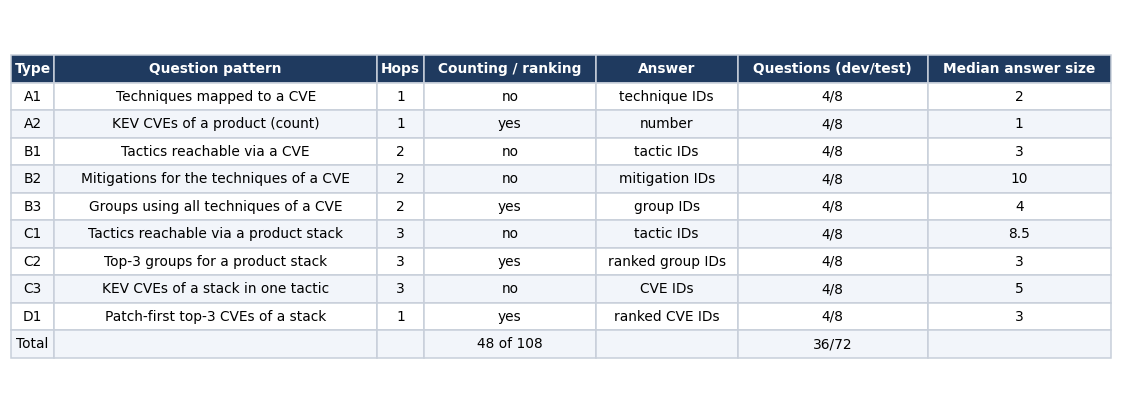


BLOCK 7 DONE


In [ ]:
# ============ BLOCK 7 : Question benchmark (the answers are computed from the knowledge graph, no LLM involved) ============
# Needs Block 1 (helpers) and Block 6 (kg_nodes / kg_edges on Drive). CPU only, about 1 minute. Nothing here calls an LLM.
if 'DIRS' not in globals(): raise RuntimeError('Run Block 1 first in this session (it defines the helper functions and the Drive folders).')
import itertools
from collections import Counter, defaultdict

PER_TEMPLATE = 12            # questions per question type (9 types -> 108 questions)
DEV_SHARE = 1 / 3            # this share of every type is the DEV set (used to tune prompts); the rest is the TEST set that goes into the report
BENCH_SEED = 7
PROC = DIRS['proc']
def section(t): print(f'\n===== {t} =====')
for f in ('kg_nodes.parquet', 'kg_edges.parquet'):
    if not (PROC / f).exists(): raise RuntimeError(f'{f} not found on Drive: run Block 6 first.')
NODES, EDGES, C = _load(PROC / 'kg_nodes.parquet'), _load(PROC / 'kg_edges.parquet'), _load(PROC / 'cves_enriched.parquet')
nm = dict(zip(NODES.node_id, NODES['name']))
rng = np.random.default_rng(BENCH_SEED)
pick = lambda L: L[int(rng.integers(len(L)))]

# ------------------------------------------------------------------------------------------------------------
# PART 1 : the facts the questions are built from
# ------------------------------------------------------------------------------------------------------------
r4 = lambda v: None if pd.isna(v) else round(float(v), 4)         # the same 4-decimal rounding that is stored in the graph
F = C.set_index('cve_id')
EP = {k: r4(v) for k, v in F.epss.items()}; CV = {k: float(v) for k, v in F.base_score.items()}
KEV = set(C[C.in_kev].cve_id)
section('Sanity check of the three ranking signals (KEV, EPSS, CVSS)')
l4 = 'CVE-2021-44228'
print(f'{l4}: EPSS {EP.get(l4)} | CVSS {CV.get(l4)} | in KEV: {l4 in KEV}')
print(f'median EPSS: KEV CVEs {np.median([EP[c] for c in KEV]):.4f} | other CVEs {np.median([v for c, v in EP.items() if c not in KEV]):.4f} | CVEs with EPSS >= 0.9999: {sum(v >= 0.9999 for v in EP.values())}')

def tab(rel, a, b, pa, pb, st=None, dt=None):                      # one relation as a small table of plain ids (prefix cut off)
    e = EDGES[EDGES.rel == rel]
    if st: e = e[(e.src_type == st) & (e.dst_type == dt)]
    return pd.DataFrame({a: e.src.str[pa:] if pa else e.src.values, b: e.dst.str[pb:] if pb else e.dst.values})
aff = tab('affects', 'cve', 'prod', 4, 0)                          # product keys keep their 'prod:' prefix
mp = tab('maps_to', 'cve', 'tech', 4, 5)                           # expert CVE -> technique labels
tt = tab('in_tactic', 'tech', 'tactic', 5, 7)
gu = tab('uses', 'grp', 'tech', 6, 5, 'Group', 'Technique')
mi = tab('mitigates', 'mit', 'tech', 4, 5)
sets = lambda df, k, v: df.groupby(k)[v].apply(set).to_dict()
cves_of_p, techs_of_c = sets(aff, 'prod', 'cve'), sets(mp, 'cve', 'tech')
tactics_of_t, groups_of_t, mits_of_t = sets(tt, 'tech', 'tactic'), sets(gu, 'tech', 'grp'), sets(mi, 'tech', 'mit')
union = lambda it: set().union(*it) if it else set()
LAB = set(techs_of_c); LAB_LIST = sorted(LAB)
tactics_of_c = {c: union([tactics_of_t.get(t, set()) for t in ts]) for c, ts in techs_of_c.items()}
mits_of_c = {c: union([mits_of_t.get(t, set()) for t in ts]) for c, ts in techs_of_c.items()}
pname_n = Counter(nm[p] for p in NODES[NODES.node_type == 'Product'].node_id)
fam = lambda p: ' '.join(nm[p].split()[:2])                        # 'microsoft windows server 2016' -> 'microsoft windows'
PROD_OK = [p for p, s in cves_of_p.items() if len(s & LAB) >= 3 and pname_n[nm[p]] == 1]       # products with some expert labels and an unambiguous name
KEVP = [p for p, s in cves_of_p.items() if 5 <= len(s & KEV) <= 200 and pname_n[nm[p]] == 1]
pw = np.sqrt([len(cves_of_p[p] & LAB) for p in PROD_OK]); pw = pw / pw.sum()
print(f'\nproducts usable in stack questions: {len(PROD_OK)} | products with 5-200 KEV CVEs (usable in counting questions): {len(KEVP)} | labelled CVEs: {len(LAB):,}')

def sample_stack(k):
    st = [PROD_OK[i] for i in rng.choice(len(PROD_OK), size=k, replace=False, p=pw)]
    if len({fam(p) for p in st}) < k: return None                  # no two Windows versions (or two Debian packages) in one stack
    ss = [cves_of_p[p] for p in st]
    if any(len(a & b) / len(a | b) >= 0.5 for a, b in itertools.combinations(ss, 2)): return None     # products must not share most of their CVEs
    cves = union(ss); lab = cves & LAB
    if len(cves) < 10 or len(lab) < 6: return None
    return {'stack': st, 'cves': cves, 'lab': lab, 'techs': union([techs_of_c[c] for c in lab])}
stack_text = lambda st: ', '.join(nm[p] for p in st[:-1]) + ' and ' + nm[st[-1]] if len(st) > 1 else nm[st[0]]
STACK_INTRO = ['A server stack consists of these products (named as in the NVD product list): {s}.', 'An organisation runs the following products (names as in NVD): {s}.']
ONLY_LABELLED = 'Consider only CVEs that affect at least one of these products (product listed as vulnerable) and have an expert ATT&CK mapping.'
SPEC = {'technique_ids': 'a JSON list of ATT&CK technique IDs, e.g. ["T1190", "T1059.001"]', 'tactic_ids': 'a JSON list of ATT&CK tactic IDs, e.g. ["TA0001", "TA0004"]',
        'mitigation_ids': 'a JSON list of ATT&CK mitigation IDs, e.g. ["M1051"]', 'group_ids': 'a JSON list of ATT&CK group IDs, e.g. ["G0016"]',
        'group_ids_ranked': 'a JSON list of exactly three ATT&CK group IDs, best first', 'cve_ids': 'a JSON list of CVE IDs',
        'cve_ids_ranked': 'a JSON list of exactly three CVE IDs, patch first = first', 'number': 'a single integer'}

# ------------------------------------------------------------------------------------------------------------
# PART 2 : question types.  Each generator returns one question or None (rejected by a quality filter).
# ------------------------------------------------------------------------------------------------------------
def Q(key, question, kind, gold, entities, hops, agg):
    return {'key': key, 'question': question, 'answer_kind': kind, 'answer_spec': SPEC[kind], 'gold': gold, 'entities': entities, 'hops': hops, 'needs_aggregation': agg}

def g_A1():                                                          # CVE -> techniques
    c = pick(LAB_LIST); ts = techs_of_c[c]
    if not 1 <= len(ts) <= 6: return None
    q = pick(['Which ATT&CK techniques is {c} mapped to (as exploitation technique, primary impact or secondary impact)?', 'List every ATT&CK technique that the expert CVE-to-ATT&CK mapping links to {c}.'])
    return Q(c, q.format(c=c), 'technique_ids', sorted(ts), {'cves': [c]}, 1, False)

def g_A2():                                                          # product -> CVEs -> count KEV
    p = pick(KEVP); n = len(cves_of_p[p] & KEV)
    q = pick(['How many CVEs that affect {p} are listed in the CISA Known Exploited Vulnerabilities (KEV) catalogue? Count only CVEs for which this product is listed as vulnerable.',
              'Count the CVEs in the CISA KEV catalogue that list {p} among their vulnerable products.'])
    return Q(p, q.format(p=nm[p]), 'number', n, {'products': [p]}, 1, True)

def g_B1():                                                          # CVE -> techniques -> tactics
    c = pick(LAB_LIST); ta = tactics_of_c[c]
    if not 2 <= len(ta) <= 8: return None
    q = pick(['Through which ATT&CK tactics can an attacker use the techniques that {c} is mapped to? List all tactics.', 'Which ATT&CK tactics are covered by the techniques linked to {c}?'])
    return Q(c, q.format(c=c), 'tactic_ids', sorted(ta), {'cves': [c]}, 2, False)

def g_B2():                                                          # CVE -> techniques -> mitigations
    c = pick(LAB_LIST); m = mits_of_c[c]
    if not 3 <= len(m) <= 20: return None
    q = pick(['Which ATT&CK mitigations are recorded for the techniques that {c} is mapped to?', 'List the ATT&CK mitigations that defend against the techniques linked to {c}.'])
    return Q(c, q.format(c=c), 'mitigation_ids', sorted(m), {'cves': [c]}, 2, False)

def g_B3():                                                          # CVE -> techniques -> groups using ALL of them
    c = pick(LAB_LIST); ts = techs_of_c[c]
    if not 2 <= len(ts) <= 3: return None
    g = set.intersection(*[groups_of_t.get(t, set()) for t in ts])
    if not 1 <= len(g) <= 15: return None
    q = pick(['Which ATT&CK groups are recorded as using ALL of the techniques that {c} is mapped to?', 'Name the ATT&CK groups that use every technique linked to {c}.'])
    return Q(c, q.format(c=c), 'group_ids', sorted(g), {'cves': [c]}, 2, True)

def stack_q(k, template, body, kind, gold_fn, hops, agg):
    s = sample_stack(k)
    if s is None: return None
    r = gold_fn(s)
    if r is None: return None
    gold, extra = r
    intro = pick(STACK_INTRO).format(s=stack_text(s['stack']))
    return Q('|'.join(sorted(s['stack'])) + '|' + str(extra.get('tactic', '')), f'{intro} {body(extra)}', kind, gold, {'products': s['stack'], **extra}, hops, agg)

def g_C1():                                                          # stack -> CVEs -> techniques -> tactics
    def gold(s):
        ta = union([tactics_of_t.get(t, set()) for t in s['techs']])
        return (sorted(ta), {}) if 4 <= len(ta) <= 10 else None          # not 'almost every tactic', that would be too easy to guess
    return stack_q(int(rng.integers(2, 4)), 'C1', lambda e: ONLY_LABELLED + ' Which ATT&CK tactics can an attacker reach through these CVEs?', 'tactic_ids', gold, 3, False)

def g_C2():                                                          # stack -> CVEs -> techniques -> groups, ranked by overlap
    def gold(s):
        cnt = sorted(Counter(g for t in s['techs'] for g in groups_of_t.get(t, ())).items(), key=lambda kv: (-kv[1], kv[0]))
        if len(cnt) < 4 or cnt[2][1] == cnt[3][1]: return None       # the 3rd and 4th group must differ, so the top three are unambiguous
        return [g for g, _ in cnt[:3]], {}
    return stack_q(int(rng.integers(2, 4)), 'C2', lambda e: ONLY_LABELLED + ' Collect the ATT&CK techniques those CVEs are mapped to, then rank ATT&CK groups by how many of these technique IDs they are recorded as using (count every technique ID separately, no roll-up to parent techniques). Which three groups rank highest?',
                   'group_ids_ranked', gold, 3, True)

def g_C3():                                                          # stack -> KEV CVEs -> tactic filter
    def gold(s):
        by = defaultdict(set)
        for c in s['lab'] & KEV:
            for ta in tactics_of_c[c]: by[ta].add(c)
        ok = sorted(t for t, v in by.items() if 3 <= len(v) <= 12)
        if not ok: return None
        ta = pick(ok); return sorted(by[ta]), {'tactic': ta}
    body = lambda e: f'Consider only CVEs that affect at least one of these products (product listed as vulnerable), are listed in the CISA KEV catalogue and have an expert ATT&CK mapping. Which of these CVEs are mapped to at least one technique of the ATT&CK tactic {nm["tactic:" + e["tactic"]]} ({e["tactic"]})?'
    return stack_q(int(rng.integers(2, 4)), 'C3', body, 'cve_ids', gold, 3, False)

def g_D1():                                                          # stack -> all CVEs -> patch priority
    def gold(s):
        if len(s['cves'] & KEV) < 3: return None
        d = pd.DataFrame({'cve': sorted(s['cves'])}); d['k'] = d.cve.isin(KEV); d['e'] = d.cve.map(EP); d['v'] = d.cve.map(CV)
        d = d.sort_values(['k', 'e', 'v', 'cve'], ascending=[False, False, False, True]).reset_index(drop=True)
        if tuple(d.loc[2, ['k', 'e', 'v']]) == tuple(d.loc[3, ['k', 'e', 'v']]): return None       # a tie at the cut-off would make the top three ambiguous
        return list(d.cve[:3]), {}
    body = lambda e: ('Patch-priority rule: (1) CVEs listed in the CISA KEV catalogue come first; (2) then the higher EPSS score (compared at 4 decimals); (3) then the higher CVSS base score; (4) then the alphabetically first CVE id. '
                      'Consider every CVE that affects at least one of these products (product listed as vulnerable), whether or not it has an ATT&CK mapping. Which three CVEs should be patched first? List them in priority order.')
    return stack_q(int(rng.integers(2, 4)), 'D1', body, 'cve_ids_ranked', gold, 1, True)

TEMPLATES = [  # id, generator, short description, answer type
    ('A1', g_A1, 'Techniques mapped to a CVE', 'technique IDs'), ('A2', g_A2, 'KEV CVEs of a product (count)', 'number'),
    ('B1', g_B1, 'Tactics reachable via a CVE', 'tactic IDs'), ('B2', g_B2, 'Mitigations for the techniques of a CVE', 'mitigation IDs'),
    ('B3', g_B3, 'Groups using all techniques of a CVE', 'group IDs'),
    ('C1', g_C1, 'Tactics reachable via a product stack', 'tactic IDs'), ('C2', g_C2, 'Top-3 groups for a product stack', 'ranked group IDs'),
    ('C3', g_C3, 'KEV CVEs of a stack in one tactic', 'CVE IDs'), ('D1', g_D1, 'Patch-first top-3 CVEs of a stack', 'ranked CVE IDs')]

section('Generating questions')
BENCH = []
for tid, gen, desc, kind in TEMPLATES:
    seen, out, tries = set(), [], 0
    while len(out) < PER_TEMPLATE and tries < 20000:
        tries += 1; q = gen()
        if q is None or q['key'] in seen: continue
        seen.add(q['key']); q['template'] = tid; out.append(q)
    if len(out) < PER_TEMPLATE: print(f'  WARNING: {tid} ({desc}) produced only {len(out)} of {PER_TEMPLATE} questions after {tries:,} tries')
    order = rng.permutation(len(out)); n_dev = int(round(len(out) * DEV_SHARE))
    for rank, i in enumerate(order): out[i]['split'] = 'dev' if rank < n_dev else 'test'
    for i, q in enumerate(out): q['id'] = f'{tid}-{i + 1:02d}'; del q['key']
    BENCH += out; print(f'  {tid}  {desc:42s} {len(out):2d} questions  ({tries:,} tries)')
NAMEOF = {'technique_ids': lambda x: nm['tech:' + x], 'tactic_ids': lambda x: nm['tactic:' + x], 'mitigation_ids': lambda x: nm['mit:' + x], 'group_ids': lambda x: nm['group:' + x],
          'group_ids_ranked': lambda x: nm['group:' + x], 'cve_ids': lambda x: x, 'cve_ids_ranked': lambda x: x}
for q in BENCH:                                                       # human-readable names next to the ids (the scorer accepts either)
    q['gold_names'] = [NAMEOF[q['answer_kind']](x) for x in q['gold']] if q['answer_kind'] != 'number' else []
    q['entity_names'] = {k: [nm[x] if x.startswith('prod:') else x for x in v] if isinstance(v, list) else v for k, v in q['entities'].items()}

# ------------------------------------------------------------------------------------------------------------
# PART 3 : independent verification.  The answers above were built with table joins; here every answer is recomputed by walking the
#          graph edge by edge (a different code path). Every single question must agree.
# ------------------------------------------------------------------------------------------------------------
section('Verification (answers recomputed by graph traversal)')
adj, radj = defaultdict(lambda: defaultdict(set)), defaultdict(lambda: defaultdict(set))
for s_, r_, d_ in zip(EDGES.src.values, EDGES.rel.values, EDGES.dst.values): adj[r_][s_].add(d_); radj[r_][d_].add(s_)
V_techs = lambda c: {d[5:] for d in adj['maps_to'].get('cve:' + c, ())}
V_tactics = lambda ts: {d[7:] for t in ts for d in adj['in_tactic'].get('tech:' + t, ())}
V_groups = lambda t: {s[6:] for s in radj['uses'].get('tech:' + t, ()) if s.startswith('group:')}
V_mits = lambda ts: {s[4:] for t in ts for s in radj['mitigates'].get('tech:' + t, ())}
V_cves = lambda st: {s[4:] for p in st for s in radj['affects'].get(p, ())}
def expected(q):
    t, e = q['template'], q['entities']
    if t in ('A1', 'B1', 'B2', 'B3'):
        ts = V_techs(e['cves'][0])
        return {'A1': lambda: sorted(ts), 'B1': lambda: sorted(V_tactics(ts)), 'B2': lambda: sorted(V_mits(ts)), 'B3': lambda: sorted(set.intersection(*[V_groups(x) for x in ts]))}[t]()
    cves = V_cves(e['products'])
    if t == 'A2': return len(cves & KEV)
    if t == 'D1': return sorted(cves, key=lambda c: (c not in KEV, -EP[c], -CV[c], c))[:3]
    lab = {c for c in cves if V_techs(c)}; techs = set().union(*[V_techs(c) for c in lab])
    if t == 'C1': return sorted(V_tactics(techs))
    if t == 'C2': return [g for g, _ in sorted(Counter(g for x in techs for g in V_groups(x)).items(), key=lambda kv: (-kv[1], kv[0]))[:3]]
    if t == 'C3': return sorted(c for c in lab & KEV if e['tactic'] in V_tactics(V_techs(c)))
bad = [q['id'] for q in BENCH if expected(q) != q['gold']]
print(f'{len(BENCH) - len(bad)} of {len(BENCH)} answers confirmed by the second method | mismatches: {bad or "none"}')
assert not bad, 'ground truth disagrees between the two methods'
sizes = lambda q: 1 if q['answer_kind'] == 'number' else len(q['gold'])
print('empty answers:', [q['id'] for q in BENCH if q['answer_kind'] != 'number' and not q['gold']] or 'none',
      '| duplicate questions:', len(BENCH) - len({q['question'] for q in BENCH}), '| ids unique:', len({q['id'] for q in BENCH}) == len(BENCH))

# ------------------------------------------------------------------------------------------------------------
# PART 4 : save + describe
# ------------------------------------------------------------------------------------------------------------
_save(BENCH, PROC / 'benchmark.json')
dfb = pd.DataFrame([{'id': q['id'], 'template': q['template'], 'split': q['split'], 'hops': q['hops'], 'counting': q['needs_aggregation'], 'gold_size': sizes(q),
                     'n_products': len(q['entities'].get('products', [])), 'question_words': len(q['question'].split())} for q in BENCH])
print(f'\nsaved benchmark.json: {len(BENCH)} questions | dev {int((dfb.split == "dev").sum())} / test {int((dfb.split == "test").sum())} | '
      f'need counting/ranking/intersection: {int(dfb.counting.sum())} | median question length {int(dfb.question_words.median())} words')
print('\none example per type (gold answer shortened):')
for tid, _, desc, _ in TEMPLATES:
    q = next((x for x in BENCH if x['template'] == tid), None)
    if q: print(f'\n[{q["id"]}] {q["question"]}\n   -> {q["gold"] if q["answer_kind"] == "number" else (str(q["gold"])[:150])}   ({sizes(q)} item(s))')

info = []
for tid, _, desc, kind in TEMPLATES:
    d = dfb[dfb.template == tid]
    info.append({'Type': tid, 'Question pattern': desc, 'Hops': int(d.hops.iloc[0]) if len(d) else '', 'Counting / ranking': 'yes' if len(d) and d.counting.iloc[0] else 'no', 'Answer': kind,
                 'Questions (dev/test)': f'{int((d.split == "dev").sum())}/{int((d.split == "test").sum())}', 'Median answer size': f'{d.gold_size.median():g}' if len(d) else ''})
info.append({'Type': 'Total', 'Question pattern': '', 'Hops': '', 'Counting / ranking': f'{int(dfb.counting.sum())} of {len(dfb)}', 'Answer': '', 'Questions (dev/test)': f'{int((dfb.split == "dev").sum())}/{int((dfb.split == "test").sum())}', 'Median answer size': ''})
save_table(pd.DataFrame(info), 'table_benchmark', 'The nine question types of the benchmark, with hop count and answer size')
print('\nBLOCK 7 DONE')


===== Text corpus =====
18,661 pages -> 23,427 chunks | words per chunk: mean 77, median 74, longest 313 | corpus fingerprint 5605aa39aa | 8 s

example: the first chunk of the page for CVE-2021-44228
----------------------------------------------------------------------------------------------------
CVE-2021-44228 (CVE record)
Description: Apache Log4j2 2.0-beta9 through 2.15.0 (excluding security releases 2.12.2, 2.12.3, and 2.3.1) JNDI features used in configuration, log messages, and parameters do not protect against attacker controlled LDAP and other JNDI related endpoints. An attacker who can control log messages or log message parameters can execute arbitrary code loaded from LDAP servers when message lookup substitution is enabled. From log4j 2.15.0, this behavior has been disabled by default. From version 2.16.0 (along with 2.12.2, 2.12.3, and 2.3.1), this functionality has been completely removed. Note that this vulnerability is specific to log4j-core and does not affect log4

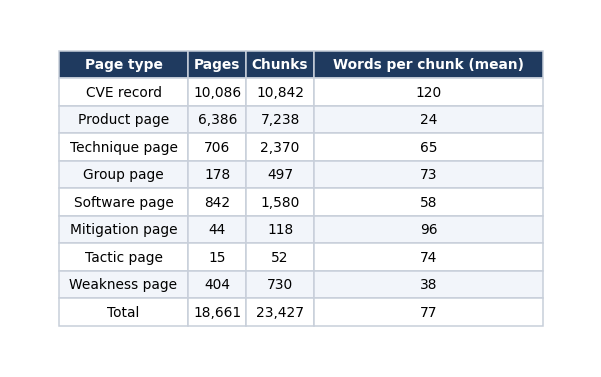


===== Fact coverage: is every graph edge written down in the text of both of its pages? =====
  affects 34,300 | requires_platform 1,808 | has_weakness 8,449 | maps_to 2,819 | in_tactic 881 | subtechnique_of 479 | uses 17,589 | mitigates 1,477 | child_of 448
  [PASS] 68,250 graph edges checked in both directions | edges missing from the text: none
  [PASS] every graph node has a page (18,661 nodes) | no empty chunk: True

===== Search indexes =====
keyword index (BM25): 39,386 distinct terms (ids such as CVE-2021-44228 or T1190 are single terms)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

embedding model BAAI/bge-small-en-v1.5 on GPU | 23,427 chunks in 12 pieces | already on Drive: 0 | to compute: 12
  piece 1/12 done | 343 chunks/s | about 1.1 min left
  piece 2/12 done | 343 chunks/s | about 1.0 min left
  piece 3/12 done | 392 chunks/s | about 0.8 min left
  piece 4/12 done | 420 chunks/s | about 0.6 min left
  piece 5/12 done | 426 chunks/s | about 0.5 min left
  piece 6/12 done | 446 chunks/s | about 0.4 min left
  piece 7/12 done | 492 chunks/s | about 0.3 min left
  piece 8/12 done | 504 chunks/s | about 0.3 min left
  piece 9/12 done | 503 chunks/s | about 0.2 min left
  piece 10/12 done | 505 chunks/s | about 0.1 min left
  piece 11/12 done | 520 chunks/s | about 0.1 min left
  piece 12/12 done | 547 chunks/s | about 0.0 min left
embedding index: 23,427 x 384 | unit length: True | 105 s since start

===== Retrieval diagnostics on the 108 benchmark questions =====
hybrid search, top 10 chunks as context (evidence recall = share of needed facts present):
  1-hop 

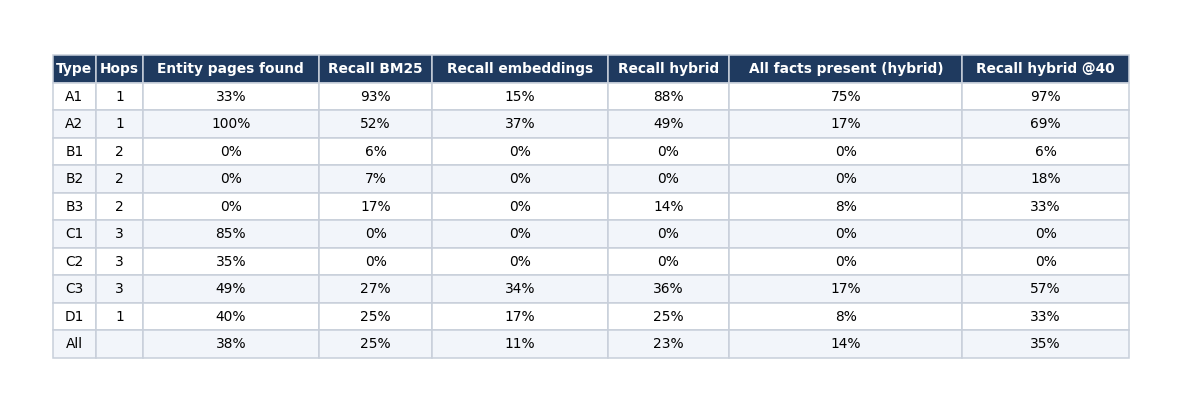

[figure saved] fig_rag_recall_by_type.png


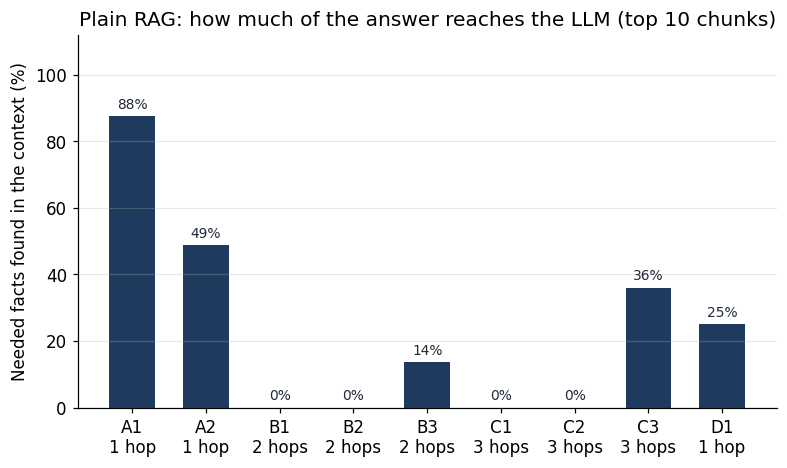

[figure saved] fig_rag_retriever_comparison.png


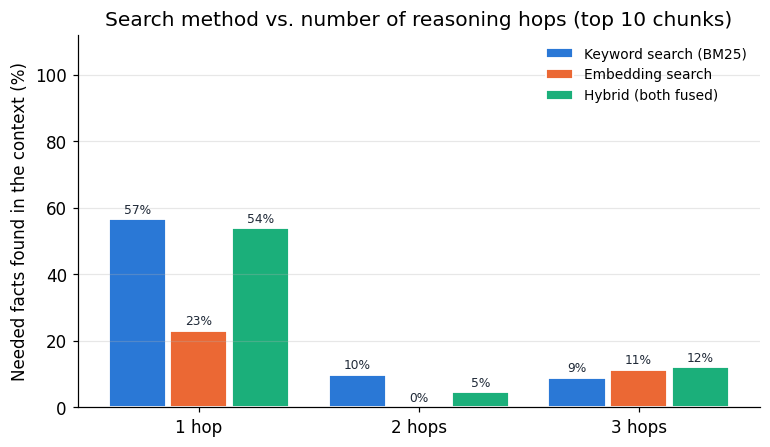

[figure saved] fig_rag_recall_vs_k.png


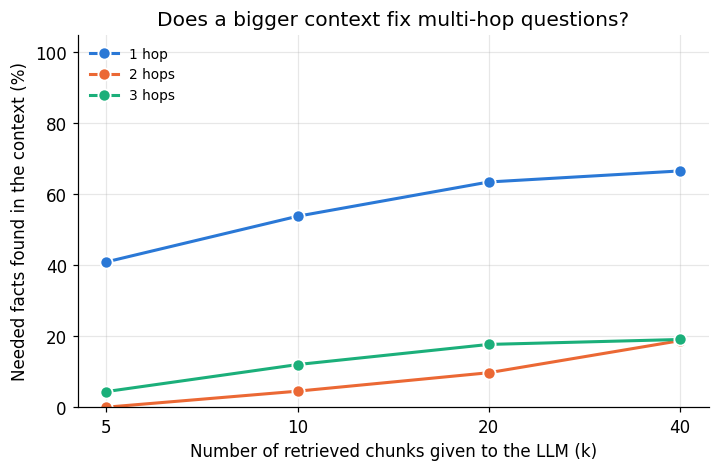


BLOCK 8 DONE | 108 s


In [ ]:
# ============ BLOCK 8 : Plain-RAG baseline, part 1: text corpus, search index (keywords + embeddings), retrieval diagnostics ============
# Needs Block 1 (helpers), Block 6 (kg_nodes / kg_edges) and Block 7 (benchmark.json). No LLM is called here.
# Use a GPU runtime for this block (Runtime > Change runtime type > T4 GPU), run Block 1 again, then this block: the embeddings take ~1-3 min on a GPU, ~20 min on CPU.
# Everything is saved to Drive in pieces, so if the session dies you simply run Block 1 and this block again and it continues.
if 'DIRS' not in globals(): raise RuntimeError('Run Block 1 first in this session (it defines the helper functions and the Drive folders).')
import re, hashlib
from collections import Counter, defaultdict
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

EMBED_MODEL = 'BAAI/bge-small-en-v1.5'       # small, strong, free embedding model (384 numbers per text)
QUERY_PREFIX = 'Represent this sentence for searching relevant passages: '      # the recommended prefix for this model, used on questions only
MAX_TOKENS = 512                             # longest text the embedding model reads
LIST_PER_CHUNK = 25                          # long lists (CVE ids, products, techniques ...) are cut into pieces of this many items
DESC_WORDS = 100                             # descriptions are shortened to this many words
SHARD = 2000                                 # embeddings are saved to Drive in pieces of this many chunks
RRF_K, POOL = 60, 100                        # hybrid search: reciprocal-rank-fusion constant, and how many hits of each search are fused
KS, K_MAIN = (5, 10, 20, 40), 10             # context sizes evaluated; K_MAIN = the size used for the headline numbers
NAVY, INK, GREY = '#1F3A5F', '#1F2937', '#6B7280'
PROC = DIRS['proc']
def section(t): print(f'\n===== {t} =====')
for f in ('kg_nodes.parquet', 'kg_edges.parquet', 'benchmark.json'):
    if not (PROC / f).exists(): raise RuntimeError(f'{f} not found on Drive: run Blocks 6 and 7 first.')
T0 = time.time()
NODES, EDGES, BENCH = _load(PROC / 'kg_nodes.parquet'), _load(PROC / 'kg_edges.parquet'), _load(PROC / 'benchmark.json')
nm, EXT, TXT = dict(zip(NODES.node_id, NODES['name'])), dict(zip(NODES.node_id, NODES.ext_id)), dict(zip(NODES.node_id, NODES['text']))
ATTR = {n: json.loads(a) for n, a in zip(NODES.node_id, NODES['attrs'])}

# ------------------------------------------------------------------------------------------------------------
# PART 1 : the text corpus.  One "page" per graph node, written the way a normal document collection would be (NVD record, ATT&CK page, ...),
#          cut into chunks of at most ~200 words. Every chunk starts with the title of its page. The corpus states exactly the same facts as the graph.
# ------------------------------------------------------------------------------------------------------------
def rel_map(rel, key, st=None, dt=None):                              # key='src': {src: [(dst, attr)]}, key='dst': {dst: [(src, attr)]}
    e = EDGES[EDGES.rel == rel]
    if st: e = e[(e.src_type == st) & (e.dst_type == dt)]
    a, b = (e.src, e.dst) if key == 'src' else (e.dst, e.src)
    out = defaultdict(list)
    for x, y, at in zip(a, b, e['attr']): out[x].append((y, at))
    return out
prod_of_cve, plat_of_cve, cve_of_prod, platcve_of_prod = rel_map('affects', 'src'), rel_map('requires_platform', 'src'), rel_map('affects', 'dst'), rel_map('requires_platform', 'dst')
cwe_of_cve, cve_of_cwe, parent_of_cwe, child_of_cwe = rel_map('has_weakness', 'src'), rel_map('has_weakness', 'dst'), rel_map('child_of', 'src'), rel_map('child_of', 'dst')
tech_of_cve, cve_of_tech = rel_map('maps_to', 'src'), rel_map('maps_to', 'dst')
tactic_of_tech, tech_of_tactic = rel_map('in_tactic', 'src'), rel_map('in_tactic', 'dst')
parent_of_tech, subs_of_tech = rel_map('subtechnique_of', 'src'), rel_map('subtechnique_of', 'dst')
group_of_tech, sw_of_tech = rel_map('uses', 'dst', 'Group', 'Technique'), rel_map('uses', 'dst', 'Software', 'Technique')
tech_of_group, sw_of_group = rel_map('uses', 'src', 'Group', 'Technique'), rel_map('uses', 'src', 'Group', 'Software')
tech_of_sw, group_of_sw = rel_map('uses', 'src', 'Software', 'Technique'), rel_map('uses', 'dst', 'Group', 'Software')
mit_of_tech, tech_of_mit = rel_map('mitigates', 'dst'), rel_map('mitigates', 'src')

def clean_text(t, max_words=DESC_WORDS):                              # strip markdown links, citations and html from the ATT&CK / NVD descriptions
    t = re.sub(r'\[([^\]]+)\]\(https?://[^)]*\)', r'\1', t or ''); t = re.sub(r'\(Citation:[^)]*\)', '', t); t = re.sub(r'</?code>', '', t)
    w = t.split(); return ' '.join(w[:max_words]) + (' ...' if len(w) > max_words else '')
lab = lambda n: nm[n] if n.startswith('prod:') else (EXT[n] if nm[n] == EXT[n] else f'{EXT[n]} {nm[n]}')      # 'T1190 Exploit Public-Facing Application', 'CVE-2021-44228'
labs = lambda lst: sorted({lab(n) for n, _ in lst})
ids_ = lambda lst: sorted({EXT[n] for n, _ in lst})
val = lambda v, none='unknown': none if v is None or (isinstance(v, float) and np.isnan(v)) else v

CH = []                                                               # (doc_id, doc type, text)
def add_doc(doc_id, dtype, title, head, lists):
    """first chunk = title + head lines + the first `inline` items of each list; the rest of every long list goes into follow-up chunks"""
    main, extra = [title] + [h for h in head if h], []
    for label_, items, inline in lists:
        if not items: continue
        first, rest, n = items[:inline], items[inline:], len(items)
        if first: main.append(f'{label_} ({n}): ' + '; '.join(first) if not rest else f'{label_} (items 1-{len(first)} of {n}): ' + '; '.join(first))
        for s in range(0, len(rest), LIST_PER_CHUNK):
            part = rest[s:s + LIST_PER_CHUNK]; a_ = len(first) + s + 1
            extra.append(f'{title}\n{label_} (items {a_}-{a_ + len(part) - 1} of {n}): ' + '; '.join(part))
    CH.append((doc_id, dtype, '\n'.join(main)))
    CH.extend((doc_id, dtype, x) for x in extra)

PART_NAME = {'a': 'application', 'o': 'operating system', 'h': 'hardware'}
for r in NODES.itertuples():
    n, t, a = r.node_id, r.node_type, ATTR[r.node_id]
    if t == 'CVE':
        kev = (f"CISA KEV (Known Exploited Vulnerabilities) catalogue: LISTED, added {val(a.get('kev_date_added'))}; known ransomware campaign use: {val(a.get('ransomware_use'))}."
               if a.get('in_kev') else 'CISA KEV (Known Exploited Vulnerabilities) catalogue: not listed.')
        ssvc = (f"CISA SSVC decision: exploitation {a['ssvc_exploitation']}, automatable {val(a.get('ssvc_automatable'))}, technical impact {val(a.get('ssvc_technical_impact'))}."
                if a.get('ssvc_exploitation') else '')
        maps = sorted(tech_of_cve.get(n, []), key=lambda x: x[0])
        mapped = [lab(x) + (f" ({at.replace('_', ' ').replace('|', ' / ')})" if at else '') for x, at in maps]
        add_doc(n, 'CVE record', f'{r.name} (CVE record)',
                [f"Description: {clean_text(r.text) or 'not available'}",
                 f"Published {val(a.get('published'))}. Severity {val(a.get('severity'))} (CVSS base score {val(a.get('base_score'))}, version {val(a.get('cvss_version_used'))}). "
                 f"Attack vector {val(a.get('attack_vector'))}, attack complexity {val(a.get('attack_complexity'))}, privileges required {val(a.get('privileges_required'))}, user interaction {val(a.get('user_interaction'))}.",
                 f"EPSS exploit-prediction score: {val(a.get('epss'), 'not available')} (percentile {val(a.get('epss_percentile'), 'not available')}).", kev, ssvc,
                 '' if mapped else 'Expert ATT&CK mapping: none recorded for this CVE.'],
                [('Weaknesses (CWE)', labs(cwe_of_cve.get(n, [])), 99), ('Expert ATT&CK mapping (technique and role of the CVE)', mapped, 99),
                 ('Vulnerable products', labs(prod_of_cve.get(n, [])), 10), ('Required platform (not itself vulnerable)', labs(plat_of_cve.get(n, [])), 10)])
    elif t == 'Product':
        add_doc(n, 'Product page', f"{r.name} (NVD product, {PART_NAME.get(a.get('part'), 'product')})", [f"Vendor {a.get('vendor')}, product {a.get('product')}."],
                [('CVEs that list this product as vulnerable', ids_(cve_of_prod.get(n, [])), 20), ('CVEs that need this product only as platform (not itself vulnerable)', ids_(platcve_of_prod.get(n, [])), 20)])
    elif t == 'Technique':
        par = parent_of_tech.get(n, [])
        add_doc(n, 'Technique page', f'{lab(n)} (ATT&CK {"sub-technique" if a.get("is_sub") else "technique"})',
                [f'Sub-technique of {lab(par[0][0])}.' if par else '', 'Tactics: ' + '; '.join(labs(tactic_of_tech.get(n, []))) + '.' if tactic_of_tech.get(n) else '',
                 f"Platforms: {a['platforms'].replace('|', ', ')}." if a.get('platforms') else '', f'Description: {clean_text(r.text)}' if r.text else ''],
                [('Sub-techniques', labs(subs_of_tech.get(n, [])), 99), ('Mitigations', labs(mit_of_tech.get(n, [])), 99), ('Groups that use this technique', labs(group_of_tech.get(n, [])), 0),
                 ('Software that uses this technique', labs(sw_of_tech.get(n, [])), 0), ('CVEs with an expert ATT&CK mapping to this technique', ids_(cve_of_tech.get(n, [])), 0)])
    elif t == 'Group':
        add_doc(n, 'Group page', f'{lab(n)} (ATT&CK group)', [f"Also known as: {a['aliases'].replace('|', ', ')}." if a.get('aliases') else '', f'Description: {clean_text(r.text)}' if r.text else ''],
                [('Techniques used', labs(tech_of_group.get(n, [])), 5), ('Software used', labs(sw_of_group.get(n, [])), 5)])
    elif t == 'Software':
        add_doc(n, 'Software page', f"{lab(n)} (ATT&CK {a.get('kind') or 'software'})", [f'Description: {clean_text(r.text)}' if r.text else ''],
                [('Techniques used', labs(tech_of_sw.get(n, [])), 5), ('Groups that use it', labs(group_of_sw.get(n, [])), 10)])
    elif t == 'Mitigation':
        add_doc(n, 'Mitigation page', f'{lab(n)} (ATT&CK mitigation)', [f'Description: {clean_text(r.text)}' if r.text else ''], [('Techniques it mitigates', labs(tech_of_mit.get(n, [])), 5)])
    elif t == 'Tactic':
        add_doc(n, 'Tactic page', f'{lab(n)} (ATT&CK tactic)', [f"Short name: {a.get('shortname')}."], [('Techniques in this tactic', labs(tech_of_tactic.get(n, [])), 10)])
    elif t == 'Weakness':
        add_doc(n, 'Weakness page', f'{lab(n)} (weakness type)', [f"{(a.get('kind') or 'weakness').title()}, abstraction level {a.get('abstraction') or 'unknown'}."],
                [('Parent weaknesses', labs(parent_of_cwe.get(n, [])), 99), ('Child weaknesses', labs(child_of_cwe.get(n, [])), 99), ('CVEs with this weakness', ids_(cve_of_cwe.get(n, [])), 10)])
CORP = pd.DataFrame(CH, columns=['doc_id', 'doc_type', 'text']); CORP.insert(0, 'chunk_id', np.arange(len(CORP))); CORP['n_words'] = CORP.text.str.split().str.len()
texts, N = list(CORP.text), len(CORP)
doc_of = list(CORP.doc_id)
CORP_HASH = hashlib.md5(('\n'.join(texts) + EMBED_MODEL + str(MAX_TOKENS)).encode()).hexdigest()[:10]
_save(CORP, PROC / 'rag_chunks.parquet')
section('Text corpus')
byt = CORP.groupby('doc_type').agg(pages=('doc_id', 'nunique'), chunks=('chunk_id', 'size'), words=('n_words', 'mean')).reindex(['CVE record', 'Product page', 'Technique page', 'Group page', 'Software page', 'Mitigation page', 'Tactic page', 'Weakness page'])
print(f'{CORP.doc_id.nunique():,} pages -> {N:,} chunks | words per chunk: mean {CORP.n_words.mean():.0f}, median {CORP.n_words.median():.0f}, longest {CORP.n_words.max()} | corpus fingerprint {CORP_HASH} | {time.time() - T0:.0f} s')
ex_id = 'cve:CVE-2021-44228' if 'cve:CVE-2021-44228' in set(doc_of) else doc_of[0]
print(f'\nexample: the first chunk of the page for {ex_id[4:] if ex_id.startswith("cve:") else ex_id}\n' + '-' * 100 + f'\n{CORP.text[doc_of.index(ex_id)]}\n' + '-' * 100)
tab_c = byt.reset_index().rename(columns={'doc_type': 'Page type'}); tab_c['pages'] = tab_c.pages.map('{:,}'.format); tab_c['chunks'] = tab_c.chunks.map('{:,}'.format); tab_c['words'] = tab_c.words.map('{:.0f}'.format)
tab_c.columns = ['Page type', 'Pages', 'Chunks', 'Words per chunk (mean)']
tab_c.loc[len(tab_c)] = ['Total', f'{CORP.doc_id.nunique():,}', f'{N:,}', f'{CORP.n_words.mean():.0f}']
save_table(tab_c, 'table_rag_corpus', 'The text corpus that the plain-RAG baseline searches (same facts as the knowledge graph)')

# ------------------------------------------------------------------------------------------------------------
# PART 2 : checks that the text states the same facts as the graph (a fair baseline must not be starved of information)
# ------------------------------------------------------------------------------------------------------------
TOK_RE = re.compile(r'cve-\d{4}-\d{4,}|cwe-\d+|\b(?:ta\d{4}|[tgsm]\d{4}(?:\.\d{3})?)\b|[a-z0-9]+')        # ids (CVE-2021-44228, T1059.001, TA0001, G0016 ...) stay in one piece
ID_RE = re.compile(r'^(?:cve-\d{4}-\d{4,}|cwe-\d+|ta\d{4}|[tgsm]\d{4}(?:\.\d{3})?)$')
tok = lambda s: TOK_RE.findall(s.lower())
STOP_Q = set(ENGLISH_STOP_WORDS) | {'att', 'ck', 'attack', 'list', 'name', 'count', 'consider', 'listed', 'catalogue', 'mapped', 'mapping', 'expert'}      # words that occur in every question
chunk_tok = [tok(x) for x in texts]
DESC_LINE = re.compile(r'^Description: .*$', re.M)                    # ids that are only mentioned inside a description do not count as written-down facts
chunk_ids = [frozenset(t for t in tok(DESC_LINE.sub('', x)) if ID_RE.match(t)) for x in texts]
doc_ids, doc_txt = defaultdict(set), defaultdict(list)
for d_, ci, x in zip(doc_of, chunk_ids, texts): doc_ids[d_] |= ci; doc_txt[d_].append(x.lower())
doc_txt = {d_: ' '.join(v) for d_, v in doc_txt.items()}
section('Fact coverage: is every graph edge written down in the text of both of its pages?')
miss = Counter(); tot = Counter()
for rel, s_, d_ in zip(EDGES.rel, EDGES.src, EDGES.dst):
    for a_, b_ in ((s_, d_), (d_, s_)):
        tot[rel] += 1
        if not ((nm[b_].lower() in doc_txt[a_]) if b_.startswith('prod:') else (EXT[b_].lower() in doc_ids[a_])): miss[rel] += 1
print('  ' + ' | '.join(f'{r} {tot[r] // 2:,}' for r in tot))
print(f'  [{"PASS" if not miss else "FAIL"}] {sum(tot.values()) // 2:,} graph edges checked in both directions | edges missing from the text: {dict(miss) or "none"}')
assert sum(miss.values()) <= 0.01 * sum(tot.values()), 'more than 1% of the graph facts are missing from the text corpus'
nodoc = set(NODES.node_id) - set(doc_of)
print(f'  [{"PASS" if not nodoc else "FAIL"}] every graph node has a page ({len(NODES):,} nodes) | no empty chunk: {bool((CORP.n_words > 0).all())}')
assert not nodoc, 'some graph nodes have no page in the text corpus'

# ------------------------------------------------------------------------------------------------------------
# PART 3 : keyword index (BM25) and embedding index
# ------------------------------------------------------------------------------------------------------------
section('Search indexes')
cv = CountVectorizer(tokenizer=tok, lowercase=False, token_pattern=None, dtype=np.float32)
X = cv.fit_transform(texts).tocsr()
dl = np.asarray(X.sum(1)).ravel(); dfreq = np.bincount(X.indices, minlength=X.shape[1])
idf = np.log(1 + (N - dfreq + 0.5) / (dfreq + 0.5)); rows_ = np.repeat(np.arange(N), np.diff(X.indptr)); K1, B = 1.2, 0.75
W = X.copy(); W.data = (idf[X.indices] * X.data * (K1 + 1) / (X.data + K1 * (1 - B + B * dl[rows_] / dl.mean()))).astype(np.float32)
print(f'keyword index (BM25): {X.shape[1]:,} distinct terms (ids such as CVE-2021-44228 or T1190 are single terms)')

def get_embedder():
    if 'EMBEDDER_OVERRIDE' in globals(): return globals()['EMBEDDER_OVERRIDE'], 'test stand-in'
    try:
        import torch; gpu = torch.cuda.is_available()
    except Exception: gpu = False
    try: from sentence_transformers import SentenceTransformer
    except ImportError:
        import subprocess; subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'sentence-transformers']); from sentence_transformers import SentenceTransformer
    m = SentenceTransformer(EMBED_MODEL, device='cuda' if gpu else 'cpu'); m.max_seq_length = MAX_TOKENS
    if gpu: m.half()
    bs = 128 if gpu else 32
    def embed(xs, query=False):
        if query: xs = [QUERY_PREFIX + x for x in xs]
        return np.asarray(m.encode(list(xs), batch_size=bs, normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False), dtype=np.float32)
    return embed, ('GPU' if gpu else 'CPU')
embed, device = get_embedder()
EMB_DIR = DIRS['cache'] / f'rag_emb_{CORP_HASH}'; EMB_DIR.mkdir(parents=True, exist_ok=True)
n_sh = (N + SHARD - 1) // SHARD; todo = [s for s in range(n_sh) if not (EMB_DIR / f'shard_{s:04d}.npy').exists()]
print(f'embedding model {EMBED_MODEL} on {device} | {N:,} chunks in {n_sh} pieces | already on Drive: {n_sh - len(todo)} | to compute: {len(todo)}')
if device == 'CPU' and todo: print(f'  NOTE: no GPU found, so this will take roughly {len(todo) * 1.5:.0f} min. It is safe to stop and restart: finished pieces stay on Drive.')
t1 = time.time()
for k_, s in enumerate(todo):
    E_ = embed(texts[s * SHARD:(s + 1) * SHARD]); tmp = EMB_DIR / f'shard_{s:04d}.tmp'
    with open(tmp, 'wb') as f: np.save(f, E_.astype(np.float16))
    os.replace(tmp, EMB_DIR / f'shard_{s:04d}.npy')
    el = time.time() - t1; print(f'  piece {s + 1}/{n_sh} done | {SHARD * (k_ + 1) / el:,.0f} chunks/s | about {el / (k_ + 1) * (len(todo) - k_ - 1) / 60:.1f} min left')
E = np.concatenate([np.load(EMB_DIR / f'shard_{s:04d}.npy') for s in range(n_sh)]).astype(np.float32)
assert E.shape[0] == N and np.isfinite(E).all(), 'embedding matrix has the wrong shape or contains NaN'
print(f'embedding index: {E.shape[0]:,} x {E.shape[1]} | unit length: {bool(np.allclose(np.linalg.norm(E, axis=1), 1, atol=1e-2))} | {time.time() - T0:.0f} s since start')

def search_ranked(queries, method='hybrid'):
    """for every query text: chunk numbers, best first (up to POOL, or 2*POOL for hybrid). method: 'bm25', 'dense' or 'hybrid' (reciprocal rank fusion of the two)"""
    qs = [queries] if isinstance(queries, str) else list(queries); out = {}
    Qb = cv.transform([' '.join(w for w in tok(x) if w not in STOP_Q) for x in qs]); Qb.data[:] = 1       # keyword side: filler words of the question are dropped, ids and names are kept
    S_bm = (W @ Qb.T).toarray().T
    S_de = embed(qs, query=True) @ E.T
    top = lambda S: [np.argsort(-s, kind='stable')[:POOL] for s in S]
    out['bm25'], out['dense'] = top(S_bm), top(S_de)
    def fuse(a, b):
        sc = defaultdict(float)
        for L in (a, b):
            for r, c in enumerate(L): sc[int(c)] += 1 / (RRF_K + r + 1)
        return np.array([c for c, _ in sorted(sc.items(), key=lambda kv: (-kv[1], kv[0]))])
    out['hybrid'] = [fuse(a, b) for a, b in zip(out['bm25'], out['dense'])]
    return out[method] if method != 'all' else out
rag_search = lambda query, k=K_MAIN, method='hybrid': [(int(c), texts[int(c)]) for c in search_ranked(query, method)[0][:k]]      # used by the later blocks and the demo

# ------------------------------------------------------------------------------------------------------------
# PART 4 : what does the search find for the benchmark questions?  Measured without any LLM:
#          "evidence recall" = share of the facts that the correct answer consists of that are present in the retrieved chunks (an upper bound for any answer generator)
# ------------------------------------------------------------------------------------------------------------
section('Retrieval diagnostics on the 108 benchmark questions')
cves_of_p = {p: {c[4:] for c, _ in v} for p, v in cve_of_prod.items()}
KEV = {n[4:] for n in NODES.node_id[NODES.node_type == 'CVE'] if ATTR[n].get('in_kev')}
KEVCH = {i for i, x in enumerate(texts) if 'catalogue: LISTED' in x}     # chunks that state "this CVE is in the KEV catalogue"
def support(q):                                                       # the facts that must reach the context for the question to be answerable
    if q['answer_kind'] == 'number': return [('kev', 'cve:' + c) for c in sorted(cves_of_p.get(q['entities']['products'][0], set()) & KEV)]      # every KEV CVE to be counted: its page must show the KEV line
    return [('id', g.lower()) for g in q['gold']]                     # every id that the correct answer consists of
def found(sup, top):
    got = set().union(*[chunk_ids[c] for c in top]); kev = {doc_of[c] for c in top if c in KEVCH}
    return [(s_[1] in kev) if s_[0] == 'kev' else (s_[1] in got) for s_ in sup]
anchors = lambda q: ['cve:' + c for c in q['entities'].get('cves', [])] + list(q['entities'].get('products', []))
RK = search_ranked([q['question'] for q in BENCH], 'all')
rows = []
for method in ('bm25', 'dense', 'hybrid'):
    for q, rk in zip(BENCH, RK[method]):
        sup, anc = support(q), anchors(q)
        for k in KS:
            top = rk[:k]; docs = {doc_of[c] for c in top}
            rec = float(np.mean(found(sup, top))) if sup else 1.0
            rows.append({'id': q['id'], 'template': q['template'], 'hops': q['hops'], 'split': q['split'], 'method': method, 'k': k, 'recall': rec, 'complete': rec == 1.0, 'anchor': float(np.mean([a in docs for a in anc]))})
R = pd.DataFrame(rows)
_save({q['id']: {m: [int(c) for c in RK[m][i][:max(KS)]] for m in ('bm25', 'dense', 'hybrid')} for i, q in enumerate(BENCH)}, PROC / 'rag_retrieval.json')
h = R[(R.method == 'hybrid') & (R.k == K_MAIN)]
print(f'hybrid search, top {K_MAIN} chunks as context (evidence recall = share of needed facts present):')
for hp, d in h.groupby('hops'): print(f'  {hp}-hop questions ({len(d)}): evidence recall {100 * d.recall.mean():.0f}% | all needed facts present in {100 * d.complete.mean():.0f}% of questions | entity pages found {100 * d.anchor.mean():.0f}%')
print('  by search method at the same context size (all questions): ' + ' | '.join(f'{m} {100 * R[(R.method == m) & (R.k == K_MAIN)].recall.mean():.0f}%' for m in ('bm25', 'dense', 'hybrid')))
print('  hybrid, test set only: ' + ' | '.join(f'{hp}-hop {100 * d.recall.mean():.0f}%' for hp, d in h[h.split == 'test'].groupby('hops')))
a1 = h[h.template == 'A1']
print(f'  A1 (the answer sits on the CVE page itself): page of the CVE found in {100 * a1.anchor.mean():.0f}% of the questions, evidence recall {100 * a1.recall.mean():.0f}%')
oracle = [np.mean(found(support(q), [i for i in range(N) if doc_of[i] == 'cve:' + q['entities']['cves'][0]])) for q in BENCH if q['template'] == 'A1']
print(f'  [{"PASS" if min(oracle) == 1 else "FAIL"}] oracle: with the CVE page itself as context, every A1 answer is fully contained ({len(oracle)} of {len(oracle)} questions)')
assert min(oracle) == 1, 'the CVE page does not contain the A1 answer: corpus or metric is wrong'
shown = {q['template']: (q, rk) for q, rk in zip(BENCH, RK['hybrid'])}
for tid in ('A1', 'C1'):
    q, rk = shown[tid]; r_ = h[h.id == q['id']].iloc[0]
    print(f'\n[{q["id"]}] top-5 chunks found for: {q["question"][:110]}...\n   recall {100 * r_.recall:.0f}% at k={K_MAIN} | ' + ' | '.join(texts[int(c)].split('\n')[0][:48] for c in rk[:5]))

TL = {t: i for i, t in enumerate(sorted({q['template'] for q in BENCH}))}
def pct(x): return f'{100 * x:.0f}%'
tr = []
for tid in TL:
    d = R[(R.template == tid) & (R.k == K_MAIN)]; hy = d[d.method == 'hybrid']
    tr.append({'Type': tid, 'Hops': int(hy.hops.iloc[0]), 'Entity pages found': pct(hy.anchor.mean()), 'Recall BM25': pct(d[d.method == 'bm25'].recall.mean()), 'Recall embeddings': pct(d[d.method == 'dense'].recall.mean()),
               'Recall hybrid': pct(hy.recall.mean()), 'All facts present (hybrid)': pct(hy.complete.mean()), f'Recall hybrid @{max(KS)}': pct(R[(R.template == tid) & (R.method == 'hybrid') & (R.k == max(KS))].recall.mean())})
d = R[R.k == K_MAIN]; hy = d[d.method == 'hybrid']
tr.append({'Type': 'All', 'Hops': '', 'Entity pages found': pct(hy.anchor.mean()), 'Recall BM25': pct(d[d.method == 'bm25'].recall.mean()), 'Recall embeddings': pct(d[d.method == 'dense'].recall.mean()),
           'Recall hybrid': pct(hy.recall.mean()), 'All facts present (hybrid)': pct(hy.complete.mean()), f'Recall hybrid @{max(KS)}': pct(R[(R.method == 'hybrid') & (R.k == max(KS))].recall.mean())})
save_table(pd.DataFrame(tr), 'table_rag_retrieval', f'Plain-RAG retrieval on the benchmark: share of the needed facts found in the top {K_MAIN} chunks (top {max(KS)} in the last column)')

# ---- figures (one per file) ----
CAT3 = {'bm25': '#2a78d6', 'dense': '#eb6834', 'hybrid': '#1baf7a'}; MNAME = {'bm25': 'Keyword search (BM25)', 'dense': 'Embedding search', 'hybrid': 'Hybrid (both fused)'}
hop_lab = {1: '1 hop', 2: '2 hops', 3: '3 hops'}
byT = h.groupby('template').agg(rec=('recall', 'mean'), hops=('hops', 'first')).loc[list(TL)]
fig, ax = plt.subplots(figsize=(8.2, 4.4)); b = ax.bar([f'{t}\n{hop_lab[int(x)]}' for t, x in zip(byT.index, byT.hops)], 100 * byT.rec.values, color=NAVY, width=0.62)
ax.bar_label(b, labels=[f'{100 * v:.0f}%' for v in byT.rec.values], padding=3, fontsize=9, color=INK); ax.set_ylim(0, 112); ax.set_yticks(range(0, 101, 20)); ax.grid(axis='x', visible=False)
ax.set_ylabel('Needed facts found in the context (%)'); ax.set_title(f'Plain RAG: how much of the answer reaches the LLM (top {K_MAIN} chunks)')
save_fig(fig, 'fig_rag_recall_by_type', 'Evidence recall of the hybrid plain-RAG retriever per question type')
g = R[R.k == K_MAIN].groupby(['hops', 'method']).recall.mean().unstack()
fig, ax = plt.subplots(figsize=(8, 4.4)); w = 0.26; xs = np.arange(len(g))
for i, m in enumerate(('bm25', 'dense', 'hybrid')):
    bb = ax.bar(xs + (i - 1) * (w + 0.02), 100 * g[m].values, w, color=CAT3[m], label=MNAME[m], edgecolor='white', linewidth=1.2)
    ax.bar_label(bb, labels=[f'{100 * v:.0f}%' for v in g[m].values], padding=2, fontsize=8, color=INK)
ax.set_xticks(xs); ax.set_xticklabels([hop_lab[int(x)] for x in g.index]); ax.set_ylim(0, 112); ax.set_yticks(range(0, 101, 20)); ax.grid(axis='x', visible=False)
ax.set_ylabel('Needed facts found in the context (%)'); ax.set_title(f'Search method vs. number of reasoning hops (top {K_MAIN} chunks)'); ax.legend(frameon=False, fontsize=9, loc='upper right')
save_fig(fig, 'fig_rag_retriever_comparison', 'Evidence recall of BM25, embedding and hybrid retrieval by hop count')
g = R[R.method == 'hybrid'].groupby(['hops', 'k']).recall.mean().unstack(0)
fig, ax = plt.subplots(figsize=(7.4, 4.4))
for hp, c_ in zip(g.columns, ('#2a78d6', '#eb6834', '#1baf7a')):
    ax.plot(g.index, 100 * g[hp].values, marker='o', ms=8, lw=2, color=c_, label=hop_lab[int(hp)], markeredgecolor='white', markeredgewidth=1.2)
ax.set_xscale('log'); ax.set_xticks(list(KS)); ax.set_xticklabels([str(k) for k in KS]); ax.minorticks_off(); ax.set_ylim(0, 105); ax.legend(frameon=False, fontsize=9, loc='upper left')
ax.set_xlabel('Number of retrieved chunks given to the LLM (k)'); ax.set_ylabel('Needed facts found in the context (%)'); ax.set_title('Does a bigger context fix multi-hop questions?')
save_fig(fig, 'fig_rag_recall_vs_k', 'Evidence recall of hybrid retrieval as the context grows, by hop count')
print(f'\nBLOCK 8 DONE | {time.time() - T0:.0f} s')

In [ ]:
# ============ BLOCK 9 : LLM client, answer scorer, and the plain-RAG baseline (run on the DEV questions) ============
# Needs Block 1 (helpers), Block 6 (kg_nodes), Block 7 (benchmark.json) and Block 8 (rag_chunks.parquet, rag_retrieval.json on Drive). CPU runtime is enough, nothing is trained here.
# The LLM is called through Groq (key = Colab secret GROQ_API_KEY). Every call is saved to Drive, so re-running this block never spends tokens twice and a stopped run continues where it ended.
if 'DIRS' not in globals(): raise RuntimeError('Run Block 1 first in this session (it defines the helper functions and the Drive folders).')
import re, hashlib
from collections import Counter, defaultdict, deque
try: import requests
except ImportError:
    import subprocess; subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'requests']); import requests

# ---------------------------------------------- settings ----------------------------------------------
GROQ_MODELS = ['openai/gpt-oss-120b', 'openai/gpt-oss-20b', 'qwen/qwen3.8-27b']      # first one that your key can use is taken (the probe below prints what is available)
GROQ_BASE = globals().get('GROQ_BASE_OVERRIDE', 'https://api.groq.com/openai/v1')
LIMITS = {'tpm': 8000, 'tpd': 200000, 'rpm': 30}      # Groq free plan as listed in Nov 2026 for these models (tokens/minute, tokens/day, requests/minute); the probe prints the live numbers of your key
LIMITS.update(globals().get('LIMITS_OVERRIDE', {}))
REASONING_EFFORT = 'low'                              # gpt-oss models think before answering; 'low' keeps the token bill small ('medium' / 'high' = better answers, more tokens)
RUN_SPLITS = ('dev',)                                 # which questions to answer now: the 36 DEV questions (prompt tuning). The 72 TEST questions are only run for the final results.
RAG_PROMPT_TOKEN_CAP = 3500                           # the context given to the LLM is never longer than this (estimated tokens)
RAG_K_CHOICES, RAG_METHODS = (5, 10, 20), ('bm25', 'dense', 'hybrid')
PROC, RES = DIRS['proc'], DIRS['results']
def section(t): print(f'\n===== {t} =====')
for f in ('kg_nodes.parquet', 'benchmark.json', 'rag_chunks.parquet', 'rag_retrieval.json'):
    if not (PROC / f).exists(): raise RuntimeError(f'{f} not found on Drive: run Blocks 6, 7 and 8 first.')
NODES, BENCH, CORP, RETR = _load(PROC / 'kg_nodes.parquet'), _load(PROC / 'benchmark.json'), _load(PROC / 'rag_chunks.parquet'), _load(PROC / 'rag_retrieval.json')
texts = list(CORP.text); BQ = {q['id']: q for q in BENCH}

# ------------------------------------------------------------------------------------------------------------
# PART 1 : the LLM client  (OpenAI-style chat API; works for Groq now and for a local model later: only CFG changes)
# ------------------------------------------------------------------------------------------------------------
class QuotaExhausted(Exception): pass
CFG = {'backend': 'groq', 'base': GROQ_BASE, 'key': get_secret('GROQ_API_KEY'), 'model': None, 'effort': REASONING_EFFORT}
if not CFG['key']: raise RuntimeError('Colab secret GROQ_API_KEY not found: add it under the key icon on the left and switch "Notebook access" on.')
HDR = lambda: {'Authorization': f"Bearer {CFG['key']}", 'Content-Type': 'application/json'}
LLM_LOG = DIRS['cache'] / 'llm_calls.jsonl'
def _read_log():
    out = {}
    if LLM_LOG.exists():
        with open(LLM_LOG) as f:
            for line in f:
                try: r = json.loads(line); out[r['key']] = r
                except Exception: pass                                # a half-written last line after a crash is ignored
    return out
CALLS = _read_log()
EST = {'chars': 1.0, 'tokens': 0.33}                                  # running estimate of tokens per character (ids such as CVE-2021-44228 cost many tokens)
SENT = deque()                                                        # (time, tokens, requests) of the last minute, for pacing
LAST_RL = {}
def est_tokens(messages, tools):
    chars = sum(len(str(m.get('content') or '')) + len(json.dumps(m.get('tool_calls') or '')) for m in messages) + (len(json.dumps(tools)) if tools else 0)
    return int(chars * EST['tokens'] / EST['chars']) + 20 * len(messages)
def used_last_24h():
    now = time.time(); return sum(r.get('pt', 0) + r.get('ct', 0) for r in CALLS.values() if now - r.get('ts', 0) < 86400 and r.get('model') == CFG['model'])
def _pace(est):
    while True:
        now = time.time()
        while SENT and now - SENT[0][0] > 60: SENT.popleft()
        if not SENT or (sum(s[1] for s in SENT) + est <= 0.9 * LIMITS['tpm'] and len(SENT) < LIMITS['rpm'] - 2): break
        time.sleep(max(0.5, 60 - (now - SENT[0][0]) + 0.2))
    SENT.append([time.time(), est])
def _wait_from(resp):
    ra = resp.headers.get('retry-after')
    if ra:
        try: return float(ra) + 0.5
        except ValueError: pass
    m = re.search(r'try again in\s+(?:(\d+)m)?\s*([\d.]+)?\s*(ms|s)?', resp.text)
    if m and (m.group(1) or m.group(2)):
        s = (int(m.group(1)) * 60 if m.group(1) else 0) + (float(m.group(2)) / (1000 if m.group(3) == 'ms' else 1) if m.group(2) else 0); return s + 0.5
    return 10.0
def chat(messages, tools=None, max_tokens=700, temperature=0.0):
    """one LLM call -> {'content', 'tool_calls', 'finish', 'pt', 'ct', 'lat', 'cached'}; identical calls are answered from the Drive cache"""
    if CFG['model'] is None: raise RuntimeError('no model selected: run the probe part of this block first')
    key = hashlib.md5(json.dumps([CFG['backend'], CFG['model'], CFG['effort'], messages, tools, max_tokens, temperature], sort_keys=True).encode()).hexdigest()
    if key in CALLS: return {**CALLS[key], 'cached': True}
    est = est_tokens(messages, tools) + max_tokens
    if CFG['backend'] == 'groq' and used_last_24h() + est > 0.97 * LIMITS['tpd']:
        raise QuotaExhausted(f"daily token budget almost used ({used_last_24h():,} of {LIMITS['tpd']:,} tokens in the last 24 h)")
    body = {'model': CFG['model'], 'messages': messages, 'temperature': temperature, 'max_completion_tokens' if CFG['backend'] == 'groq' else 'max_tokens': max_tokens}
    if tools: body['tools'], body['tool_choice'] = tools, 'auto'
    if CFG['effort'] and 'gpt-oss' in CFG['model']: body['reasoning_effort'] = CFG['effort']
    for attempt in range(10):
        _pace(est); t0 = time.time()
        try: resp = requests.post(f"{CFG['base']}/chat/completions", headers=HDR(), json=body, timeout=180)
        except requests.RequestException as e:
            print(f'  (network problem: {type(e).__name__}; retrying)'); time.sleep(min(60, 3 * 2 ** attempt)); continue
        lat = time.time() - t0
        if resp.status_code == 200: break
        msg = ''
        try: msg = resp.json().get('error', {}).get('message', '')
        except Exception: msg = resp.text[:300]
        if resp.status_code == 429:
            if re.search(r'per day|\bTPD\b|\bRPD\b', msg): raise QuotaExhausted(re.sub(r'organization `[^`]*`', 'your organisation', msg)[:300])
            w = min(120, _wait_from(resp)); print(f'  (rate limit: waiting {w:.0f} s)'); time.sleep(w); continue
        if resp.status_code == 413: raise ValueError(f'request too large for the plan ({est:,} tokens estimated): {msg[:200]}')
        if resp.status_code == 400 and 'reasoning_effort' in msg and 'reasoning_effort' in body: body.pop('reasoning_effort'); CFG['effort'] = None; continue      # this model does not take the setting: stop sending it
        if resp.status_code == 400 and 'max_completion_tokens' in body and 'max_completion_tokens' in msg: body['max_tokens'] = body.pop('max_completion_tokens'); continue
        if resp.status_code >= 500 or resp.status_code in (408, 409): print(f'  (server problem {resp.status_code}; retrying)'); time.sleep(min(60, 3 * 2 ** attempt)); continue
        raise RuntimeError(f'LLM call failed ({resp.status_code}): {msg[:300]}')
    else: raise RuntimeError('LLM call failed after 10 attempts')
    j = resp.json(); ch = j['choices'][0]; m = ch['message']; u = j.get('usage', {})
    LAST_RL.update({k: v for k, v in resp.headers.items() if k.lower().startswith('x-ratelimit')})
    pt, ct = int(u.get('prompt_tokens', 0)), int(u.get('completion_tokens', 0))
    if SENT: SENT[-1][1] = pt + ct
    if pt: EST['chars'] += sum(len(str(x.get('content') or '')) for x in messages); EST['tokens'] += pt                  # keep the characters-per-token estimate honest
    rec = {'key': key, 'ts': time.time(), 'model': CFG['model'], 'content': m.get('content') or '', 'tool_calls': m.get('tool_calls'), 'finish': ch.get('finish_reason'), 'pt': pt, 'ct': ct, 'lat': round(lat, 2)}
    with open(LLM_LOG, 'a') as f: f.write(json.dumps(rec) + '\n')
    CALLS[key] = rec
    if rec['finish'] == 'length' and not rec['content'].strip() and not rec['tool_calls'] and max_tokens < 2400:       # the model used all tokens for thinking: ask again with more room
        return chat(messages, tools, max_tokens * 2, temperature)
    return {**rec, 'cached': False}

section('Probe: which models can your Groq key use, and what are its limits?')
r_ = requests.get(f"{GROQ_BASE}/models", headers=HDR(), timeout=60); r_.raise_for_status()
AVAILABLE = sorted(m['id'] for m in r_.json().get('data', []))
CFG['model'] = next((m for m in GROQ_MODELS if m in AVAILABLE), None)
print(f'models on your key ({len(AVAILABLE)}): ' + ', '.join(AVAILABLE))
if CFG['model'] is None: raise RuntimeError(f'none of {GROQ_MODELS} is available on your key: put one of the models listed above into GROQ_MODELS at the top of this block.')
MODEL_TAG = re.sub(r'[^A-Za-z0-9]+', '-', CFG['model']).strip('-')
pr = chat([{'role': 'user', 'content': 'Reply with the single word OK.'}], max_tokens=200)
print(f"model used: {CFG['model']} (reasoning effort {CFG['effort']}) | test call: '{pr['content'].strip()[:20]}' in {pr['lat']:.1f} s, {pr['pt'] + pr['ct']} tokens" + (' (from cache)' if pr['cached'] else ''))
if LAST_RL: print('limits reported by Groq for this key: ' + ' | '.join(f'{k.lower().replace("x-ratelimit-", "")} {v}' for k, v in sorted(LAST_RL.items())))
print(f"tokens used with this model in the last 24 h (from the saved call log): {used_last_24h():,} of about {LIMITS['tpd']:,} per day")

# ------------------------------------------------------------------------------------------------------------
# PART 2 : the scorer.  Reads the model's reply (JSON, ids or names), maps it to ids, compares it with the gold answer.
# ------------------------------------------------------------------------------------------------------------
ID_PAT = {'technique_ids': r'\bT\d{4}(?:\.\d{3})?\b', 'tactic_ids': r'\bTA\d{4}\b', 'mitigation_ids': r'\bM\d{4}\b', 'group_ids': r'\bG\d{4}\b', 'group_ids_ranked': r'\bG\d{4}\b',
          'cve_ids': r'\bCVE-\d{4}-\d{4,}\b', 'cve_ids_ranked': r'\bCVE-\d{4}-\d{4,}\b'}
PREFIX = {'technique_ids': 'tech:', 'tactic_ids': 'tactic:', 'mitigation_ids': 'mit:', 'group_ids': 'group:', 'group_ids_ranked': 'group:', 'cve_ids': 'cve:', 'cve_ids_ranked': 'cve:'}
VALID = {k: {n[len(p):] for n in NODES.node_id if n.startswith(p)} for k, p in PREFIX.items()}
NAME2ID = {}
for k, p in PREFIX.items():
    d, bad = {}, set()
    for r in NODES[NODES.node_id.str.startswith(p)].itertuples():
        names = [r.name] + ([a for a in json.loads(r.attrs).get('aliases', '').split('|') if a] if p == 'group:' else [])
        for nme in names:
            if nme.lower() in d and d[nme.lower()] != r.ext_id: bad.add(nme.lower())
            d[nme.lower()] = r.ext_id
    NAME2ID[k] = {a: b for a, b in d.items() if a not in bad}          # names that belong to two ids are not used

def to_ids(kind, items):
    out = []
    for it in items:
        s = str(it).strip(); m = re.findall(ID_PAT[kind], s, flags=re.I)
        out += [x.upper() for x in m] if m else [NAME2ID[kind].get(s.lower(), s)]
    return list(dict.fromkeys(out))
def parse_answer(text, kind):
    """-> (value, how): value = int/None for counting questions, list of ids otherwise; how = 'json' | 'text' | 'none'"""
    t = re.sub(r'<think>.*?</think>', '', text or '', flags=re.S).strip(); t = re.sub(r'^```(?:json)?\s*|\s*```$', '', t).strip()
    obj, how = None, 'none'
    for cand in (t, *[t[t.find(a):t.rfind(b) + 1] for a, b in (('{', '}'), ('[', ']')) if a in t and b in t]):
        try: obj = json.loads(cand); how = 'json'; break
        except Exception: pass
    if isinstance(obj, dict): obj = obj.get('answer', obj.get('Answer', next(iter(obj.values()), None)))
    if kind == 'number':
        if isinstance(obj, list) and len(obj) == 1: obj = obj[0]
        if isinstance(obj, (int, float)) and not isinstance(obj, bool): return int(round(obj)), 'json'
        m = re.search(r'-?\d[\d,]*', str(obj) if obj is not None else t)
        return (int(m.group(0).replace(',', '')) if m else None), ('json' if how == 'json' and m else 'text' if m else 'none')
    if isinstance(obj, str): obj = re.findall(ID_PAT[kind], obj, flags=re.I) or [x for x in re.split(r'[,;\n]', obj) if x.strip()]
    if isinstance(obj, list): return to_ids(kind, obj), 'json'
    ids = re.findall(ID_PAT[kind], t, flags=re.I)
    return (to_ids(kind, ids), 'text') if ids else ([], 'none')
def score_answer(q, val):
    kind, gold = q['answer_kind'], q['gold']
    if kind == 'number': return {'score': float(val == gold), 'strict': val == gold, 'abs_err': None if val is None else abs(val - gold), 'invalid': 0, 'n_pred': 0 if val is None else 1}
    pred = list(val); g = set(gold); inval = sum(p not in VALID[kind] for p in pred)
    if kind.endswith('_ranked'):                                      # exactly three ids, order counts for the strict score; the soft score is the top-3 overlap
        return {'score': len(set(pred[:3]) & g) / 3, 'strict': pred == gold, 'invalid': inval, 'n_pred': len(pred)}
    tp = len(set(pred) & g); P, Rc = tp / len(set(pred)) if pred else 0.0, tp / len(g)
    return {'score': 2 * P * Rc / (P + Rc) if tp else 0.0, 'strict': set(pred) == g, 'precision': P, 'recall': Rc, 'invalid': inval, 'n_pred': len(pred)}

section('Scorer self-test (known cases)')
_t = lambda tid: next(q for q in BENCH if q['template'] == tid)
_a1, _a2, _c2 = _t('A1'), _t('A2'), _t('C2')
tests = [(_a1, json.dumps({'answer': _a1['gold']}), 1.0, True), (_a1, '```json\n' + json.dumps(_a1['gold']) + '\n```', 1.0, True), (_a1, json.dumps({'answer': [x + ' something' for x in _a1['gold'][:1]]}), 2 * 1 * (1 / len(_a1['gold'])) / (1 + 1 / len(_a1['gold'])), len(_a1['gold']) == 1),
         (_a1, '<think>hmm</think> ' + ', '.join(_a1['gold']), 1.0, True), (_a1, 'I do not know', 0.0, False), (_a2, json.dumps({'answer': _a2['gold']}), 1.0, True), (_a2, f'The count is {_a2["gold"] + 1}.', 0.0, False),
         (_c2, json.dumps({'answer': _c2['gold'][::-1]}), 1.0, False), (_c2, json.dumps({'answer': _c2['gold'][:2] + ['G9999']}), 2 / 3, False)]
for q, txt, exp_s, exp_strict in tests:
    v, how = parse_answer(txt, q['answer_kind']); s = score_answer(q, v)
    assert abs(s['score'] - exp_s) < 1e-9 and s['strict'] == exp_strict, (q['id'], txt[:60], v, s)
nm_q = next((q for q in BENCH if q['template'] == 'B1'), None)
if nm_q:                                                              # names instead of ids must be accepted
    names = [NODES.loc[NODES.node_id == 'tactic:' + x, 'name'].iloc[0] for x in nm_q['gold']]
    assert score_answer(nm_q, parse_answer(json.dumps({'answer': names}), 'tactic_ids')[0])['strict'], 'tactic names are not mapped to ids'
print(f'  [PASS] {len(tests) + 1} cases: json / fenced json / thinking text / plain text / names / wrong count / reversed ranking / invalid id')

# ------------------------------------------------------------------------------------------------------------
# PART 3 : the runner that every system (plain RAG now, GraphRAG and the agent later) goes through
# ------------------------------------------------------------------------------------------------------------
def run_system(name, answer_fn, splits=RUN_SPLITS, limit=None):
    """answer_fn(question dict) -> {'text', 'pt', 'ct', 'calls', 'lat', 'meta'}; results are saved after every question and finished questions are skipped on a re-run"""
    path = RES / f'answers_{name}__{MODEL_TAG}.json'; done = _load(path) if path.exists() else {}
    todo = [q for q in BENCH if q['split'] in splits and q['id'] not in done][:limit]; t0 = time.time()
    print(f'{name}: {sum(q["split"] in splits for q in BENCH)} questions in {splits} | already answered: {sum(q["split"] in splits and q["id"] in done for q in BENCH)} | to do: {len(todo)}')
    for i, q in enumerate(todo):
        try: r = answer_fn(q)
        except QuotaExhausted as e:
            print(f'\n  STOPPED: {e}\n  Everything answered so far is saved. Run this block again after the quota resets (or switch the model); it continues with the next question.'); break
        val, how = parse_answer(r['text'], q['answer_kind']); sc = score_answer(q, val)
        done[q['id']] = {'id': q['id'], 'template': q['template'], 'split': q['split'], 'hops': q['hops'], 'raw': r['text'], 'parsed': val, 'parse': how, **sc, 'pt': r['pt'], 'ct': r['ct'], 'calls': r.get('calls', 1), 'lat': round(r['lat'], 1), 'meta': r.get('meta', {})}
        _save(done, path)
        if i < 3 or (i + 1) % 6 == 0 or i == len(todo) - 1: print(f"  [{i + 1}/{len(todo)}] {q['id']}  score {sc['score']:.2f}  strict {sc['strict']}  | {r['pt'] + r['ct']:,} tokens, {r['lat']:.1f} s | {(time.time() - t0) / 60:.1f} min")
    return done
def summarize(done, label):
    d = pd.DataFrame([v for v in done.values()])
    if d.empty: print('no answers yet'); return d
    g = d.groupby('template').agg(n=('id', 'size'), hops=('hops', 'first'), score=('score', 'mean'), strict=('strict', 'mean'), parse_fail=('parse', lambda s: (s == 'none').mean()), invalid_ids=('invalid', 'sum'),
                                  tokens=('pt', 'mean'), lat=('lat', 'mean'))
    all_ = pd.DataFrame({'n': [len(d)], 'hops': [''], 'score': [d.score.mean()], 'strict': [d.strict.mean()], 'parse_fail': [(d.parse == 'none').mean()], 'invalid_ids': [d.invalid.sum()], 'tokens': [d.pt.mean()], 'lat': [d.lat.mean()]}, index=['ALL'])
    out = pd.concat([g, all_]); out['score'] = (100 * out.score).round(0).astype(int).astype(str) + '%'; out['strict'] = (100 * out.strict).round(0).astype(int).astype(str) + '%'
    out['parse_fail'] = (100 * out.parse_fail.astype(float)).round(0).astype(int).astype(str) + '%'; out['tokens'] = out.tokens.round(0).astype(int); out['lat'] = out.lat.round(1)
    out.columns = ['questions', 'hops', 'avg score', 'exactly right', 'unreadable', 'invented ids', 'prompt tokens', 'seconds']
    print(f'\n{label}  (avg score = F1 / top-3 overlap / exact count; exactly right = whole answer correct)'); print(out.to_string()); return d

# ------------------------------------------------------------------------------------------------------------
# PART 4 : plain RAG.  Retrieval settings (search method, number of chunks) are chosen on the DEV questions by evidence recall, then frozen.
# ------------------------------------------------------------------------------------------------------------
section('Plain RAG: choosing the retrieval settings on the dev questions')
DESC = re.compile(r'^Description: .*$', re.M); ANY_ID = re.compile(r'CVE-\d{4}-\d{4,}|CWE-\d+|TA\d{4}|[TGSM]\d{4}(?:\.\d{3})?')
ids_in = {}
def chunk_ids_of(c):
    if c not in ids_in: ids_in[c] = set(ANY_ID.findall(DESC.sub('', texts[c])))
    return ids_in[c]
dev = [q for q in BENCH if q['split'] == 'dev' and q['answer_kind'] != 'number']          # counting questions have a different evidence rule; they are left out of this choice
rows = []
for m_ in RAG_METHODS:
    for k_ in RAG_K_CHOICES:
        rec = [np.mean([g in set().union(*[chunk_ids_of(c) for c in RETR[q['id']][m_][:k_]]) for g in q['gold']]) for q in dev]
        rows.append({'search': m_, 'chunks': k_, 'dev recall': np.mean(rec)})
SEL = pd.DataFrame(rows); print((SEL.assign(**{'dev recall': (100 * SEL['dev recall']).round(1).astype(str) + '%'})).pivot(index='search', columns='chunks', values='dev recall').to_string())
cap_ok = SEL.sort_values(['dev recall', 'chunks'], ascending=[False, True]).iloc[0]
RAG_METHOD, RAG_K = cap_ok.search, int(cap_ok.chunks)
print(f'-> chosen: {RAG_METHOD} search, top {RAG_K} chunks (best evidence recall on {len(dev)} dev questions; ties go to the smaller context)')

SYSTEM_RAG = ('You are a cybersecurity analyst. Answer the question using ONLY the numbered context passages. Use exact identifiers (CVE ids, ATT&CK ids) as they appear in the passages. '
              'If the passages do not contain enough information, give the best answer you can from them (an empty list, or 0 for a count, if there is nothing). '
              'Reply with ONLY one JSON object of the form {"answer": ...} and nothing else.')
def rag_messages(q, chunk_list):
    kept, budget = [], RAG_PROMPT_TOKEN_CAP - 400 - est_tokens([{'content': q['question'] + q['answer_spec']}], None)
    for c in chunk_list:
        cost = est_tokens([{'content': texts[c]}], None)
        if budget - cost < 0: break
        kept.append(c); budget -= cost
    ctx = '\n\n'.join(f'[{i + 1}] {texts[c]}' for i, c in enumerate(kept))
    return [{'role': 'system', 'content': SYSTEM_RAG}, {'role': 'user', 'content': f"Context passages:\n{ctx}\n\nQuestion: {q['question']}\n\nAnswer format: {q['answer_spec']}.\nReply with only the JSON object."}], kept
def plain_rag(q):
    for kk in (RAG_K, max(RAG_K // 2, 3)):                            # if the plan refuses the request as too large, retry with half the chunks
        msgs, kept = rag_messages(q, RETR[q['id']][RAG_METHOD][:kk])
        try: r = chat(msgs, max_tokens=700); break
        except ValueError as e: print(f'  ({e}); retrying with fewer chunks')
    else: raise RuntimeError('request too large even with few chunks')
    return {'text': r['content'], 'pt': r['pt'], 'ct': r['ct'], 'calls': 1, 'lat': r['lat'], 'meta': {'chunks': [int(c) for c in kept], 'search': RAG_METHOD, 'k': RAG_K, 'cached': r['cached']}}

section('Plain RAG: answering the questions')
n_todo = sum(q['split'] in RUN_SPLITS for q in BENCH)
est_total = sum(est_tokens(rag_messages(q, RETR[q['id']][RAG_METHOD][:RAG_K])[0], None) + 250 for q in BENCH if q['split'] in RUN_SPLITS)
print(f"{n_todo} questions in {RUN_SPLITS}: about {est_total:,} tokens if nothing is cached yet (your daily allowance for this model is about {LIMITS['tpd']:,}); at {LIMITS['tpm']:,} tokens per minute this takes roughly {est_total / (0.8 * LIMITS['tpm']):.0f} min")
RAG_DONE = run_system('plain_rag', plain_rag)
DF = summarize({k: v for k, v in RAG_DONE.items() if v['split'] in RUN_SPLITS}, f'Plain RAG ({CFG["model"]}) on the {"/".join(RUN_SPLITS)} questions')

section('What the model saw and answered (one example each)')
for tid in ('A1', 'C1'):
    v = next((x for x in RAG_DONE.values() if x['template'] == tid), None)
    if not v: continue
    q = BQ[v['id']]; msgs, _ = rag_messages(q, v['meta']['chunks'])
    print(f"\n[{q['id']}] {q['question'][:230]}\nprompt: {len(msgs[1]['content']):,} characters, {v['pt']:,} tokens | first 350 characters of the context: {msgs[1]['content'][:350]!r}\nmodel reply: {v['raw'][:300]!r}\nparsed: {str(v['parsed'])[:150]} | gold: {str(q['gold'])[:150]} | score {v['score']:.2f}")
if len(DF):
    print(f"\nfailure modes over {len(DF)} answers: unreadable replies {int((DF.parse == 'none').sum())} | empty answers {int((DF.n_pred == 0).sum())} | invented ids (not in the graph) {int(DF.invalid.sum())} | "
          f"tokens {int((DF.pt + DF.ct).sum()):,} | median latency {DF.lat.median():.1f} s")
print(f'\nsaved: results/answers_plain_rag__{MODEL_TAG}.json | LLM call log: cache/llm_calls.jsonl ({len(CALLS):,} calls) | tokens used with this model in the last 24 h: {used_last_24h():,}')
print('\nBLOCK 9 DONE' if all(q['id'] in RAG_DONE for q in BENCH if q['split'] in RUN_SPLITS) else '\nBLOCK 9 PARTLY DONE: the daily token budget ran out. Run this block again later (or tomorrow); it continues where it stopped.')


===== Probe: which models can your Groq key use, and what are its limits? =====
models on your key (11): allam-2-7b, canopylabs/orpheus-arabic-saudi, canopylabs/orpheus-v1-english, meta-llama/llama-prompt-guard-2-22m, meta-llama/llama-prompt-guard-2-86m, openai/gpt-oss-120b, openai/gpt-oss-20b, openai/gpt-oss-safeguard-20b, qwen/qwen3.8-27b, whisper-large-v3, whisper-large-v3-turbo
model used: openai/gpt-oss-120b (reasoning effort low) | test call: 'OK' in 0.4 s, 97 tokens (from cache)
tokens used with this model in the last 24 h (from the saved call log): 91,713 of about 200,000 per day

===== Scorer self-test (known cases) =====
  [PASS] 10 cases: json / fenced json / thinking text / plain text / names / wrong count / reversed ranking / invalid id

===== Plain RAG: choosing the retrieval settings on the dev questions =====
chunks     5      10     20
search                     
bm25    10.8%  23.1%  26.6%
dense   14.6%  16.9%  25.8%
hybrid  15.6%  21.0%  29.1%
-> chosen: hybrid sear

In [ ]:
# ============ BLOCK 10 : a local LLM on the Colab GPU (Ollama + gpt-oss-20b): no daily token limit ============
# Needs Block 1 and Block 9 run in THIS session (Block 9 is quick when its answers are already on Drive). Runtime: T4 GPU (Runtime > Change runtime type > T4 GPU).
# Why: the Groq free plan allows about 200,000 tokens per day per model; the full comparison of three systems needs several million. The same open model family (gpt-oss) runs on the free T4, with no limit.
if 'chat' not in globals() or 'CFG' not in globals() or 'run_system' not in globals(): raise RuntimeError('Run Block 1 and then Block 9 first in this session.')
import subprocess, shutil

LOCAL_MODEL = 'gpt-oss:20b'                  # about 12 GB download, fits the 16 GB T4. If it does not fit or is too slow, try 'qwen3:8b' here (and tell me).
LOCAL_BASE = globals().get('LOCAL_BASE_OVERRIDE', 'http://localhost:11434')
LOCAL_CTX = 16384                            # context window of the local model (tokens)
TESTING = 'LOCAL_BASE_OVERRIDE' in globals()
def section(t): print(f'\n===== {t} =====')
try:
    import torch; HAS_GPU = torch.cuda.is_available()
except Exception: HAS_GPU = False
if not HAS_GPU and not TESTING: raise RuntimeError('No GPU found: use Runtime > Change runtime type > T4 GPU, then run Block 1, Block 9 and this block again.')
GPU_NAME = torch.cuda.get_device_name(0) if HAS_GPU else 'test'

# ------------------------------------------------------------------------------------------------------------
# PART 1 : install and start Ollama, download the model
# ------------------------------------------------------------------------------------------------------------
section('Starting the local model server')
sh = lambda cmd: subprocess.run(cmd, shell=True, capture_output=True, text=True)
def server_up():
    try: return requests.get(f'{LOCAL_BASE}/api/version', timeout=3).ok
    except Exception: return False
if not server_up():
    if TESTING: raise RuntimeError('the test server is not running')
    if not shutil.which('ollama'):
        print('installing Ollama (1-2 min) ...'); sh('apt-get install -y -qq zstd pciutils lshw'); r = sh('curl -fsSL https://ollama.com/install.sh | sh')
        if not shutil.which('ollama'): raise RuntimeError('Ollama installation failed:\n' + (r.stdout + r.stderr)[-1500:])
    env = {**os.environ, 'OLLAMA_CONTEXT_LENGTH': str(LOCAL_CTX), 'OLLAMA_KEEP_ALIVE': '24h', 'OLLAMA_NUM_PARALLEL': '1', 'OLLAMA_FLASH_ATTENTION': '1', 'OLLAMA_HOST': '127.0.0.1:11434'}
    subprocess.Popen(['ollama', 'serve'], env=env, stdout=open('/tmp/ollama_serve.log', 'w'), stderr=subprocess.STDOUT, start_new_session=True)
    for _ in range(90):
        if server_up(): break
        time.sleep(1)
    else: raise RuntimeError('the Ollama server did not start:\n' + open('/tmp/ollama_serve.log').read()[-1500:])
print('Ollama server running, version', requests.get(f'{LOCAL_BASE}/api/version', timeout=10).json().get('version'), '| GPU:', GPU_NAME)
have = {m['name'] for m in requests.get(f'{LOCAL_BASE}/api/tags', timeout=10).json().get('models', [])}
if LOCAL_MODEL not in have:
    print(f'downloading {LOCAL_MODEL} (about 12 GB for gpt-oss:20b, usually 3-8 min) ...'); last, t1 = -1, time.time()
    with requests.post(f'{LOCAL_BASE}/api/pull', json={'model': LOCAL_MODEL, 'stream': True}, stream=True, timeout=3600) as r:
        r.raise_for_status()
        for line in r.iter_lines():
            if not line: continue
            j = json.loads(line)
            if 'error' in j: raise RuntimeError('download failed: ' + j['error'])
            if j.get('total', 0) > 1e8:
                pc = int(100 * j.get('completed', 0) / j['total'])
                if pc // 10 > last // 10: print(f'  {pc}% ({time.time() - t1:.0f} s)'); last = pc
    print('download finished')
else: print(f'{LOCAL_MODEL} is already on this machine')

def direct(prompt, max_tokens=200):                                   # one call straight to the server (no cache), to measure speed
    t = time.time(); r = requests.post(f'{LOCAL_BASE}/v1/chat/completions', timeout=1800, json={'model': LOCAL_MODEL, 'messages': [{'role': 'user', 'content': prompt}], 'max_tokens': max_tokens, 'temperature': 0, 'reasoning_effort': REASONING_EFFORT})
    r.raise_for_status(); j = r.json(); return j['choices'][0]['message'].get('content') or '', j.get('usage', {}), time.time() - t
t0 = time.time(); txt, u, dt = direct('Name the seven days of the week, separated by commas.'); print(f'first call (includes loading the model into GPU memory): {dt:.0f} s')
txt, u, dt = direct('Name the twelve months of the year, separated by commas.', 300)
print(f"speed check: {u.get('completion_tokens', 0)} tokens in {dt:.1f} s = {u.get('completion_tokens', 0) / max(dt, 1e-6):.0f} tokens/s | reply: {txt[:80]!r}")
ps = requests.get(f'{LOCAL_BASE}/api/ps', timeout=10).json().get('models', [])
if ps:
    m_ = ps[0]; pct = 100 * m_.get('size_vram', 0) / max(m_.get('size', 1), 1)
    print(f"model in memory: {m_.get('size', 0) / 1e9:.1f} GB, of which on the GPU: {pct:.0f}%" + ('' if pct >= 90 else '  <- WARNING: part of the model runs on the CPU, so it will be slow. Try LOCAL_MODEL = "qwen3:8b".'))

# ------------------------------------------------------------------------------------------------------------
# PART 2 : switch the LLM client of Block 9 to the local model and run plain RAG on the dev questions again
# ------------------------------------------------------------------------------------------------------------
GROQ_TAG = MODEL_TAG
CFG.update({'backend': 'ollama', 'base': LOCAL_BASE + '/v1', 'key': 'ollama', 'model': LOCAL_MODEL, 'effort': REASONING_EFFORT})
LIMITS.update({'tpm': 10 ** 9, 'rpm': 10 ** 6})                       # no rate limits locally
MODEL_TAG = re.sub(r'[^A-Za-z0-9]+', '-', LOCAL_MODEL).strip('-')
EST.update({'chars': 1e6, 'tokens': 0.33e6}); SENT.clear()           # token estimate: start from 0.33 tokens per character and do not let tiny test calls distort it
_save({'backend': 'ollama', 'model': LOCAL_MODEL, 'context_tokens': LOCAL_CTX, 'reasoning_effort': REASONING_EFFORT, 'gpu': GPU_NAME, 'tokens_per_second_check': round(u.get('completion_tokens', 0) / max(dt, 1e-6), 1)}, RES / 'llm_backend.json')

section('Plain RAG on the dev questions with the local model')
print(f'model {LOCAL_MODEL} | search {RAG_METHOD}, top {RAG_K} chunks (same retrieval as in Block 9) | reasoning effort {REASONING_EFFORT}')
LOCAL_DONE = run_system('plain_rag', plain_rag)
DFL = summarize({k: v for k, v in LOCAL_DONE.items() if v['split'] in RUN_SPLITS}, f'Plain RAG ({LOCAL_MODEL}, local) on the {"/".join(RUN_SPLITS)} questions')

section('Local model vs. Groq 120B model, same questions, same retrieval')
gp = RES / f'answers_plain_rag__{GROQ_TAG}.json'
if gp.exists():
    G_ = pd.DataFrame(list(_load(gp).values())); G_ = G_[G_.split.isin(RUN_SPLITS)]
    cmp_ = pd.DataFrame({f'Groq {GROQ_TAG.replace("openai-", "")}': G_.groupby('template').score.mean(), f'local {LOCAL_MODEL}': DFL.groupby('template').score.mean()})
    cmp_.loc['ALL'] = [G_.score.mean(), DFL.score.mean()]; cmp_ = (100 * cmp_).round(0).astype(int).astype(str) + '%'
    print('average score per question type:'); print(cmp_.to_string())
    print(f"\nempty answers: Groq {int((G_.n_pred == 0).sum())} | local {int((DFL.n_pred == 0).sum())}  ||  invented ids: Groq {int(G_.invalid.sum())} | local {int(DFL.invalid.sum())}  ||  "
          f"median seconds per question: Groq {G_.lat.median():.1f} | local {DFL.lat.median():.1f}")
else: print('(no Groq results file found to compare with)')
if len(DFL):
    ex = next((x for x in LOCAL_DONE.values() if x['template'] == 'A2'), None)
    if ex: print(f"\nexample local reply [{ex['id']}]: {ex['raw'][:200]!r} | parsed {ex['parsed']} | gold {BQ[ex['id']]['gold']} | {ex['pt']:,} prompt tokens, {ex['ct']} completion tokens, {ex['lat']:.1f} s")
    print(f"\nfailure modes over {len(DFL)} answers: unreadable {int((DFL.parse == 'none').sum())} | empty {int((DFL.n_pred == 0).sum())} | invented ids {int(DFL.invalid.sum())} | tokens {int((DFL.pt + DFL.ct).sum()):,}")
print(f'\nThe client is now switched to the local model (backend {CFG["backend"]}). Keep this session open for the next blocks.')
print('\nBLOCK 10 DONE')


===== Starting the local model server =====
installing Ollama (1-2 min) ...
Ollama server running, version 0.40.16 | GPU: Tesla T4
downloading gpt-oss:20b (about 12 GB for gpt-oss:20b, usually 3-8 min) ...
  0% (2 s)
  10% (12 s)
  20% (23 s)
  30% (35 s)
  40% (41 s)
  50% (47 s)
  60% (55 s)
  70% (60 s)
  80% (66 s)
  90% (73 s)
download finished
first call (includes loading the model into GPU memory): 237 s
speed check: 37 tokens in 1.1 s = 35 tokens/s | reply: 'January, February, March, April, May, June, July, August, September, October, No'
model in memory: 12.8 GB, of which on the GPU: 100%

===== Plain RAG on the dev questions with the local model =====
model gpt-oss:20b | search hybrid, top 20 chunks (same retrieval as in Block 9) | reasoning effort low
plain_rag: 36 questions in ('dev',) | already answered: 36 | to do: 0

Plain RAG (gpt-oss:20b, local) on the dev questions  (avg score = F1 / top-3 overlap / exact count; exactly right = whole answer correct)
     questions ho

In [ ]:
# ============ BLOCK 11 : GraphRAG (knowledge-graph retrieval + one LLM call), run on the DEV questions ============
# Needs Block 1, Block 9 and Block 10 run in THIS session (same GPU runtime, the local model must be running), plus Blocks 6 and 7 on Drive. Nothing is trained here.
# GraphRAG = (1) find the entities of the question in the knowledge graph, (2) pull their neighbourhood (products -> CVEs -> ATT&CK techniques -> tactics / mitigations / groups) with
# fixed rules, (3) write it as compact facts within the same context budget as plain RAG, (4) one LLM call. No iteration yet: that is the agent (next block).
if 'run_system' not in globals() or 'plain_rag' not in globals(): raise RuntimeError('Run Block 1, Block 9 and Block 10 first in this session.')
print(f"LLM backend: {CFG['backend']} / {CFG['model']}" + ('' if CFG['backend'] == 'ollama' else '   <- NOTE: not the local model; run Block 10 first for the final numbers'))
GRAPH_CTX_TOKENS = 3600           # context budget (estimated tokens): the same size as plain RAG's 3,500
TOK_PER_CHAR = 0.55               # estimate for lines full of ids
PRIORITY_ROWS = 15                # rows of the "highest exploitation priority" view
tk = lambda s: int(len(s) * TOK_PER_CHAR)
EDGES = _load(PROC / 'kg_edges.parquet')
ATTR = {n: json.loads(a) for n, a in zip(NODES.node_id, NODES['attrs'])}
EXT, NM = dict(zip(NODES.node_id, NODES.ext_id)), dict(zip(NODES.node_id, NODES['name']))

# ------------------------------------------------------------------------------------------------------------
# PART 1 : fast lookup tables from the graph
# ------------------------------------------------------------------------------------------------------------
def erel(rel, st=None, dt=None):
    e = EDGES[EDGES.rel == rel]
    return e[(e.src_type == st) & (e.dst_type == dt)] if st else e
cves_of_p, n_prod_of_c, techs_of_c, cwe_of_c = defaultdict(set), Counter(), defaultdict(list), defaultdict(list)
tactics_of_t, mits_of_t, groups_of_t = defaultdict(list), defaultdict(list), defaultdict(list)
for s, d in zip(*[erel('affects')[c] for c in ('src', 'dst')]): cves_of_p[d].add(EXT[s]); n_prod_of_c[EXT[s]] += 1
for s, d, a in zip(*[erel('maps_to')[c] for c in ('src', 'dst', 'attr')]): techs_of_c[EXT[s]].append((EXT[d], a or ''))
for s, d in zip(*[erel('has_weakness')[c] for c in ('src', 'dst')]): cwe_of_c[EXT[s]].append(EXT[d])
for s, d in zip(*[erel('in_tactic')[c] for c in ('src', 'dst')]): tactics_of_t[EXT[s]].append(EXT[d])
for s, d in zip(*[erel('mitigates')[c] for c in ('src', 'dst')]): mits_of_t[EXT[d]].append(EXT[s])
for s, d in zip(*[erel('uses', 'Group', 'Technique')[c] for c in ('src', 'dst')]): groups_of_t[EXT[d]].append(EXT[s])
TNAME = {EXT[n]: NM[n] for n in NODES.node_id if n.startswith('tech:')}
TACNAME = {EXT[n]: NM[n] for n in NODES.node_id if n.startswith('tactic:')}
CVE_SET = {EXT[n] for n in NODES.node_id if n.startswith('cve:')}
r4 = lambda v: None if v is None or (isinstance(v, float) and np.isnan(v)) else round(float(v), 4)
def cinfo(c):
    a = ATTR['cve:' + c]; return {'epss': r4(a.get('epss')), 'cvss': r4(a.get('base_score')), 'sev': a.get('severity'), 'kev': bool(a.get('in_kev')), 'a': a}
CI = {c: cinfo(c) for c in CVE_SET}
prio = lambda c: (not CI[c]['kev'], -(CI[c]['epss'] if CI[c]['epss'] is not None else -1), -(CI[c]['cvss'] if CI[c]['cvss'] is not None else -1), c)       # KEV first, then EPSS, then CVSS, then id
print(f'graph tables ready: {len(CVE_SET):,} CVEs, {len(cves_of_p):,} products with CVEs, {len(techs_of_c):,} CVEs with an ATT&CK mapping')

# ------------------------------------------------------------------------------------------------------------
# PART 2 : find the entities of a question in the graph
# ------------------------------------------------------------------------------------------------------------
by_name = defaultdict(list)
for n in NODES.node_id[NODES.node_type == 'Product']: by_name[NM[n].lower()].append(n)
NAMES_LONGEST_FIRST = sorted((n for n in by_name if len(n) >= 4), key=len, reverse=True)
def link_products(text):
    text, out = ' ' + text.lower() + ' ', []
    for n in NAMES_LONGEST_FIRST:
        if n not in text: continue
        m = re.search(r'(?<![a-z0-9])' + re.escape(n) + r'(?![a-z0-9])', text)
        if m:
            out.append(max(by_name[n], key=lambda p: len(cves_of_p.get(p, ())))); text = text[:m.start()] + ' ' * (m.end() - m.start()) + text[m.end():]     # longest names first, matched text is blanked
    return out
def link(text):
    cves = [c for c in dict.fromkeys(re.findall(r'CVE-\d{4}-\d{4,}', text)) if c in CVE_SET]
    tacs = [t for t in dict.fromkeys(re.findall(r'\bTA\d{4}\b', text)) if t in TACNAME]
    return {'cves': cves, 'products': link_products(text), 'tactics': tacs}
ok_cve = [link(q['question'])['cves'] == q['entities']['cves'] for q in BENCH if 'cves' in q['entities']]
ok_prod = [set(link(q['question'])['products']) == set(q['entities']['products']) for q in BENCH if 'products' in q['entities']]
section('Entity linking check on all 108 questions')
print(f'  [{"PASS" if all(ok_cve) else "FAIL"}] CVE ids found in {sum(ok_cve)} of {len(ok_cve)} questions | [{"PASS" if all(ok_prod) else "FAIL"}] products found in {sum(ok_prod)} of {len(ok_prod)} questions')

# ------------------------------------------------------------------------------------------------------------
# PART 3 : write the neighbourhood as compact facts
# ------------------------------------------------------------------------------------------------------------
role = lambda a: a.replace('_', ' ').replace('|', ' / ')
LEGEND = 'Tactic IDs: ' + '; '.join(f'{k} {v}' for k, v in sorted(TACNAME.items())) + '.'
def cve_card(c, group_budget=900):
    a, ci = ATTR['cve:' + c], CI[c]
    kev = f"yes (added {a.get('kev_date_added')}, ransomware use: {a.get('ransomware_use')})" if ci['kev'] else 'no'
    L = [f'== {c} ==', f"CVSS {ci['cvss']} ({ci['sev']}); EPSS {ci['epss']}; CISA KEV: {kev}; SSVC exploitation: {a.get('ssvc_exploitation') or 'n/a'}; weaknesses: {', '.join(sorted(cwe_of_c.get(c, []))) or 'n/a'}; affects {n_prod_of_c.get(c, 0)} products."]
    ts = sorted(techs_of_c.get(c, []))
    if not ts: return L + ['Expert ATT&CK mapping: none recorded.']
    L.append('Expert ATT&CK mapping (technique; role of the CVE; tactics; mitigations):')
    for t, r_ in ts: L.append(f"  {t} {TNAME.get(t, '')} ({role(r_)}); tactics {', '.join(sorted(tactics_of_t.get(t, []))) or 'n/a'}; mitigations {', '.join(sorted(mits_of_t.get(t, []))) or 'none'}")
    per = max(8, group_budget // max(len(ts), 1) // 4)                # groups listed per technique, within the budget (about 4 tokens per id)
    L.append('Groups recorded as using each technique (IDs):')
    for t, _ in ts:
        g = sorted(groups_of_t.get(t, [])); L.append(f"  {t} ({len(g)} groups): {', '.join(g[:per])}" + (f' ... (showing {per} of {len(g)})' if len(g) > per else ''))
    return L
def stack_block(prods, budget):
    names = [NM[p] for p in prods]; sets_ = [cves_of_p.get(p, set()) for p in prods]; allc = set().union(*sets_)
    kev, lab = {c for c in allc if CI[c]['kev']}, {c for c in allc if c in techs_of_c}
    L = ['== Products ==']
    for p, s_ in zip(prods, sets_): L.append(f'{NM[p]}: {len(s_)} CVEs list it as vulnerable; {len(s_ & kev)} of them are in the CISA KEV catalogue; {len(s_ & lab)} have an expert ATT&CK mapping.')
    if len(prods) > 1: L.append(f'All these products together: {len(allc)} distinct CVEs; {len(kev)} in the KEV catalogue; {len(lab)} with an expert ATT&CK mapping.')
    top = sorted(allc, key=prio)[:PRIORITY_ROWS]
    L += [f'== View 1: highest exploitation priority among these CVEs (KEV first, then EPSS, then CVSS); showing {len(top)} of {len(allc)} ==', 'CVE | KEV | EPSS | CVSS | ATT&CK techniques']
    L += [f"{c} | {'KEV' if CI[c]['kev'] else '-'} | {CI[c]['epss']} | {CI[c]['cvss']} | {','.join(sorted({t for t, _ in techs_of_c.get(c, [])})) or '-'}" for c in top]
    used = tk('\n'.join(L)); gl = lambda t: f"{t} {TNAME.get(t, '')} -> {', '.join(sorted(tactics_of_t.get(t, []))) or 'n/a'}"
    techs = {t for c in top for t, _ in techs_of_c.get(c, [])}                   # techniques already in the glossary (those of the priority rows)
    left = budget - used - tk(LEGEND) - sum(tk(gl(t)) for t in techs) - 100
    labl = sorted(lab, key=lambda c: (not CI[c]['kev'], c)); rows = []
    for c in labl:
        ts = {t for t, _ in techs_of_c[c]}; cost = tk(f'{c} | KEV | ' + ','.join(sorted(ts))) + sum(tk(gl(t)) for t in ts - techs)
        if cost > left: break
        rows.append(c); techs |= ts; left -= cost
    L += [f'== View 2: CVEs with an expert ATT&CK mapping (KEV first); showing {len(rows)} of {len(lab)} ==', 'CVE | KEV | ATT&CK techniques'] + [f"{c} | {'KEV' if CI[c]['kev'] else '-'} | {','.join(sorted({t for t, _ in techs_of_c[c]}))}" for c in rows]
    L += ['== Technique -> tactic (for the techniques above) =='] + [gl(t) for t in sorted(techs)]
    return L
def build_context(text):
    ent = link(text); parts = []
    if ent['cves']:
        for c in ent['cves'][:3]: parts += cve_card(c, 900 // len(ent['cves'][:3]))
    if ent['products']: parts += stack_block(ent['products'][:4], GRAPH_CTX_TOKENS - tk('\n'.join(parts)))
    if not parts: parts = ['No entity of the question was found in the knowledge graph.']
    parts.append(LEGEND)
    return '\n'.join(parts), ent

SYSTEM_GRAPH = ('You are a cybersecurity analyst. Answer the question using ONLY the knowledge-graph facts below (NVD, CISA KEV, EPSS, MITRE ATT&CK and expert CVE-to-ATT&CK mappings). Use exact identifiers as given. '
                'Lists marked "showing N of M" are shortened. Work through the relevant facts carefully before answering. '
                'If the facts do not contain enough information, give the best answer you can from them (an empty list, or 0 for a count, if there is nothing). Reply with ONLY one JSON object of the form {"answer": ...} and nothing else.')
def graph_messages(q):
    ctx, ent = build_context(q['question'])
    return [{'role': 'system', 'content': SYSTEM_GRAPH}, {'role': 'user', 'content': f"Knowledge-graph facts:\n{ctx}\n\nQuestion: {q['question']}\n\nAnswer format: {q['answer_spec']}.\nReply with only the JSON object."}], ctx, ent
def graphrag(q):
    msgs, ctx, ent = graph_messages(q); r = chat(msgs, max_tokens=900)
    return {'text': r['content'], 'pt': r['pt'], 'ct': r['ct'], 'calls': 1, 'lat': r['lat'], 'meta': {'ctx_chars': len(ctx), 'entities': {k: v[:4] for k, v in ent.items()}, 'cached': r['cached']}}

# ------------------------------------------------------------------------------------------------------------
# PART 4 : does the answer reach the LLM?  (no LLM needed) Plain RAG vs GraphRAG on all 108 questions
# ------------------------------------------------------------------------------------------------------------
section('Does the needed evidence reach the LLM?  share of the answer items that are present in the context (all 108 questions, no LLM)')
CTX = {q['id']: build_context(q['question'])[0] for q in BENCH}
def ev_graph(q):
    ids = set(ANY_ID.findall(CTX[q['id']]))
    if q['answer_kind'] == 'number': return float(f"; {q['gold']} of them are in the CISA KEV" in CTX[q['id']])
    return float(np.mean([g in ids for g in q['gold']]))
def ev_rag(q):
    if q['answer_kind'] == 'number': return np.nan
    got = set().union(*[chunk_ids_of(c) for c in RETR[q['id']][RAG_METHOD][:RAG_K]]); return float(np.mean([g in got for g in q['gold']]))
EV = pd.DataFrame([{'template': q['template'], 'hops': q['hops'], 'plain RAG': ev_rag(q), 'GraphRAG': ev_graph(q), 'ctx_tokens': tk(CTX[q['id']])} for q in BENCH])
evt = EV.groupby('template').agg(hops=('hops', 'first'), rag=('plain RAG', 'mean'), graph=('GraphRAG', 'mean'), ctx=('ctx_tokens', 'mean'))
evt.loc['ALL'] = ['', EV['plain RAG'].mean(), EV['GraphRAG'].mean(), EV.ctx_tokens.mean()]
show = evt.copy(); show['rag'] = show.rag.map(lambda v: 'n/a (count)' if pd.isna(v) else f'{100 * float(v):.0f}%'); show['graph'] = show.graph.map(lambda v: f'{100 * float(v):.0f}%'); show['ctx'] = show.ctx.map(lambda v: f'{float(v):,.0f}')
show.columns = ['hops', 'plain RAG', 'GraphRAG', 'GraphRAG context tokens (est.)']; print(show.to_string())
print('(A2 is a count: for GraphRAG the cell is the share of questions where the context states the correct KEV count; plain RAG cannot state a count.)')
_save({q['id']: CTX[q['id']] for q in BENCH}, PROC / 'graphrag_contexts.json')

# ------------------------------------------------------------------------------------------------------------
# PART 5 : answer the dev questions with GraphRAG and compare with plain RAG (same model, same scorer)
# ------------------------------------------------------------------------------------------------------------
section('GraphRAG: answering the questions')
ex = next(q for q in BENCH if q['template'] == 'D1' and q['split'] == 'dev'); ex2 = next(q for q in BENCH if q['template'] == 'B2' and q['split'] == 'dev')
for e_ in (ex2, ex):
    c_ = CTX[e_['id']]; print(f"\nexample context for [{e_['id']}] ({len(c_):,} characters, about {tk(c_):,} tokens); first 1,100 characters:\n" + '-' * 100 + f'\n{c_[:1100]}\n' + '-' * 100)
GR_DONE = run_system('graphrag', graphrag)
DFG = summarize({k: v for k, v in GR_DONE.items() if v['split'] in RUN_SPLITS}, f'GraphRAG ({CFG["model"]}) on the {"/".join(RUN_SPLITS)} questions')

section('GraphRAG vs plain RAG (same LLM, dev questions)')
pp = RES / f'answers_plain_rag__{MODEL_TAG}.json'
if pp.exists():
    P_ = pd.DataFrame(list(_load(pp).values())); P_ = P_[P_.split.isin(RUN_SPLITS)]
    cmp_ = pd.DataFrame({'plain RAG': P_.groupby('template').score.mean(), 'GraphRAG': DFG.groupby('template').score.mean()}); cmp_.insert(0, 'hops', DFG.groupby('template').hops.first())
    cmp_.loc['ALL'] = ['', P_.score.mean(), DFG.score.mean()]
    for c in ('plain RAG', 'GraphRAG'): cmp_[c] = cmp_[c].map(lambda v: f'{100 * float(v):.0f}%')
    print('average score per question type:'); print(cmp_.to_string())
    print(f"\nexactly right: plain RAG {100 * P_.strict.mean():.0f}% | GraphRAG {100 * DFG.strict.mean():.0f}%   ||   empty answers: {int((P_.n_pred == 0).sum())} | {int((DFG.n_pred == 0).sum())}   ||   invented ids: {int(P_.invalid.sum())} | {int(DFG.invalid.sum())}   ||   "
          f"median seconds: {P_.lat.median():.1f} | {DFG.lat.median():.1f}   ||   mean prompt tokens: {P_.pt.mean():,.0f} | {DFG.pt.mean():,.0f}")
if len(DFG):
    worst = DFG.sort_values('score').iloc[0]; v = GR_DONE[worst['id']]; q = BQ[worst['id']]
    print(f"\nlowest-scoring answer [{q['id']}]: reply {v['raw'][:220]!r} | parsed {str(v['parsed'])[:120]} | gold {str(q['gold'])[:120]}")
print(f'\nsaved: results/answers_graphrag__{MODEL_TAG}.json, data/processed/graphrag_contexts.json')
print('\nBLOCK 11 DONE' if all(q['id'] in GR_DONE for q in BENCH if q['split'] in RUN_SPLITS) else '\nBLOCK 11 PARTLY DONE (the LLM stopped early): run it again.')

LLM backend: ollama / gpt-oss:20b
graph tables ready: 10,086 CVEs, 6,386 products with CVEs, 1,207 CVEs with an ATT&CK mapping

===== Entity linking check on all 108 questions =====
  [PASS] CVE ids found in 48 of 48 questions | [PASS] products found in 60 of 60 questions

===== Does the needed evidence reach the LLM?  share of the answer items that are present in the context (all 108 questions, no LLM) =====
         hops    plain RAG GraphRAG GraphRAG context tokens (est.)
template                                                          
A1          1          97%     100%                            787
A2          1  n/a (count)     100%                            817
B1          2           6%     100%                            713
B2          2           7%     100%                            754
B3          2          17%     100%                            764
C1          3           0%     100%                          1,669
C2          3           0%       0%                

In [ ]:
# ============ BLOCK 12 : Agentic GraphRAG (the LLM queries the knowledge graph step by step with tools), run on the DEV questions ============
# Needs Block 1, 9, 10 and 11 run in THIS session (same GPU runtime, local model running; Block 11 is quick when its answers are already on Drive). Nothing is trained here.
# Agentic GraphRAG = the LLM gets a small set of graph tools (follow a hop, filter, sort, describe), calls them one after another, sees each result, and decides what to do next.
# Unlike GraphRAG (one fixed context, one LLM call) the agent can aggregate (count links, intersect, rank) over the whole graph, so nothing has to fit into a prompt.
if 'graphrag' not in globals() or 'by_name' not in globals(): raise RuntimeError('Run Block 1, 9, 10 and 11 first in this session.')
print(f"LLM backend: {CFG['backend']} / {CFG['model']}" + ('' if CFG['backend'] == 'ollama' else '   <- NOTE: not the local model; run Block 10 first for the final numbers'))
MAX_STEPS = 8                     # at most this many LLM calls with tools per question; then the agent must answer
PREVIEW = 25                      # items shown per tool result (the rest stays in the set and can be paged with `show`)
AG_MAX_TOKENS = 700

# ------------------------------------------------------------------------------------------------------------
# PART 1 : the tools.  Results are numbered SETS (S1, S2, ...) kept for the question; every result shows the size and a preview.
# ------------------------------------------------------------------------------------------------------------
def rev(d):
    r = defaultdict(set)
    for k, vs in d.items():
        for v in vs: r[v].add(k)
    return r
def names_of(prefix): return {EXT[n]: str(NM[n] or '') for n in NODES.node_id if n.startswith(prefix)}
GNAME, MNAME, WNAME = names_of('group:'), names_of('mit:'), names_of('cwe:')
PNAME = {n: str(NM[n]) for n in NODES.node_id if n.startswith('prod:')}
cve_techs = {c: {t for t, _ in v} for c, v in techs_of_c.items()}
prods_of_c = rev(cves_of_p)
HOPS = {  # hop name: (type of the source items, type of the result items, lookup table, meaning)
    'product_to_cves': ('Product', 'CVE', cves_of_p, 'CVEs that list the product as vulnerable'),
    'cve_to_products': ('CVE', 'Product', prods_of_c, 'products listed as vulnerable in the CVE'),
    'cve_to_techniques': ('CVE', 'Technique', cve_techs, 'ATT&CK techniques the expert mapping links to the CVE'),
    'technique_to_cves': ('Technique', 'CVE', rev(cve_techs), 'CVEs mapped to the technique'),
    'technique_to_tactics': ('Technique', 'Tactic', tactics_of_t, 'ATT&CK tactics the technique belongs to'),
    'tactic_to_techniques': ('Tactic', 'Technique', rev(tactics_of_t), 'techniques of the tactic'),
    'technique_to_mitigations': ('Technique', 'Mitigation', {t: set(m) for t, m in mits_of_t.items()}, 'ATT&CK mitigations for the technique'),
    'technique_to_groups': ('Technique', 'Group', {t: set(g) for t, g in groups_of_t.items()}, 'ATT&CK groups recorded as using the technique'),
    'group_to_techniques': ('Group', 'Technique', rev({t: set(g) for t, g in groups_of_t.items()}), 'techniques used by the group'),
    'cve_to_weaknesses': ('CVE', 'Weakness', {c: set(w) for c, w in cwe_of_c.items()}, 'CWE weaknesses of the CVE')}
VALID_ID = {'CVE': CVE_SET, 'Technique': set(TNAME), 'Tactic': set(TACNAME), 'Group': set(GNAME), 'Mitigation': set(MNAME), 'Weakness': set(WNAME), 'Product': set(PNAME)}
ID_RE = [('CVE', r'CVE-\d{4}-\d{4,}'), ('Technique', r'T\d{4}(?:\.\d{3})?'), ('Tactic', r'TA\d{4}'), ('Group', r'G\d{4}'), ('Mitigation', r'M\d{4}'), ('Weakness', r'CWE-\d+')]
def id_type(x):
    if x.startswith('prod:'): return 'Product'
    return next((t for t, p in ID_RE if re.fullmatch(p, x)), None)
def label(x, typ_):
    if typ_ == 'CVE': ci = CI[x]; return f"{x} | {'KEV' if ci['kev'] else 'not in KEV'} | EPSS {ci['epss']} | CVSS {ci['cvss']}"
    if typ_ == 'Product': return f'{x} | {PNAME[x]} | {len(cves_of_p.get(x, ()))} CVEs'
    return f"{x} {({'Technique': TNAME, 'Tactic': TACNAME, 'Group': GNAME, 'Mitigation': MNAME, 'Weakness': WNAME}[typ_]).get(x, '')}".strip()

class Sess:                                                    # the sets of ONE question
    def __init__(s): s.H, s.n = {}, 0
    def new(s, typ_, items, via='', cnt=None, src_n=1):
        s.n += 1; s.H[f'S{s.n}'] = {'type': typ_, 'items': list(items), 'via': via, 'cnt': cnt or {}, 'src_n': src_n}; return f'S{s.n}'
    def items_of(s, source, expect=None):
        src = str(source).strip()
        if re.fullmatch(r'S\d+', src, re.I):
            k = src.upper()
            if k not in s.H: raise ValueError(f'there is no set {k}; existing sets: {", ".join(s.H) or "none"}')
            h = s.H[k]; items, typ_ = h['items'], h['type']
        else:
            items = [x if x.startswith('prod:') else x.upper() for x in re.split(r'[,;\s]+', src) if x]
            if not items: raise ValueError('source is empty: give a set name such as S1 or an ID')
            types = {id_type(x) for x in items}
            if len(types) != 1 or None in types: raise ValueError(f'could not read these as IDs of one kind: {src[:80]} (products need their prod:... id: use find_product)')
            typ_ = types.pop()
            for x in items:
                if x not in VALID_ID[typ_]: raise ValueError(f'unknown {typ_} id {x}' + (' (use find_product to look a product up by name)' if typ_ == 'Product' else ''))
        if expect and typ_ != expect: raise ValueError(f'this needs {expect} items but {src} holds {typ_} items')
        return items
    def show(s, k, offset=0, n=PREVIEW):
        h = s.H[k]; it = h['items']; typ_ = h['type']
        head = f"{k}: {len(it)} {typ_} item(s)" + (f" ({h['via']})" if h['via'] else '')
        if not it: return head + ' - the set is empty.'
        rows = [label(x, typ_) + (f"   [linked to {h['cnt'][x]} of {h['src_n']} source items]" if h['cnt'] else '') for x in it[offset:offset + n]]
        more = len(it) - offset - len(rows)
        return head + f"; showing {offset + 1}-{offset + len(rows)}:\n" + '\n'.join(rows) + (f'\n... {more} more (use show with offset {offset + len(rows)})' if more > 0 else '')

def t_find_product(ses, name):
    q_ = str(name).lower().strip(); cand = sorted(by_name.get(q_, []), key=lambda p: -len(cves_of_p.get(p, ())))
    if not cand:
        toks = re.findall(r'[a-z0-9]+', q_)
        cand = sorted((p for n_, ps in by_name.items() if toks and all(t_ in n_ for t_ in toks) for p in ps), key=lambda p: (len(PNAME[p]), -len(cves_of_p.get(p, ()))))
    k = ses.new('Product', cand[:5], f'products matching "{name}"')
    return ses.show(k) if cand else f'{k}: no product matches "{name}".'
def t_neighbors(ses, source, hop, min_links=1):
    if hop not in HOPS: raise ValueError(f'unknown hop "{hop}". Hops: ' + ', '.join(HOPS))
    st, tt, table, _ = HOPS[hop]; src = ses.items_of(source, st); cnt = Counter()
    for x in src:
        for y in set(table.get(x, ())): cnt[y] += 1
    need = len(src) if str(min_links).strip().lower() == 'all' else int(float(min_links))
    items = sorted((y for y, c in cnt.items() if c >= need), key=lambda y: (-cnt[y], y))
    k = ses.new(tt, items, f'{hop} from {len(src)} source item(s)' + (f', linked to at least {need}' if need > 1 else ''), {y: cnt[y] for y in items} if len(src) > 1 else {}, len(src))
    return ses.show(k)
def t_filter_cves(ses, source, kev=None, min_epss=None, min_cvss=None, via_tactic=None):
    src = ses.items_of(source, 'CVE'); out = list(src); how = []
    if kev not in (None, ''):
        want = str(kev).strip().lower() in ('true', '1', 'yes'); out = [c for c in out if CI[c]['kev'] == want]; how.append('in the CISA KEV catalogue' if want else 'not in the KEV catalogue')
    if min_epss not in (None, ''): out = [c for c in out if (CI[c]['epss'] if CI[c]['epss'] is not None else -1) >= float(min_epss)]; how.append(f'EPSS >= {min_epss}')
    if min_cvss not in (None, ''): out = [c for c in out if (CI[c]['cvss'] if CI[c]['cvss'] is not None else -1) >= float(min_cvss)]; how.append(f'CVSS >= {min_cvss}')
    if via_tactic not in (None, ''):
        ta = str(via_tactic).strip().upper()
        if ta not in TACNAME: raise ValueError(f'unknown tactic id {ta}')
        out = [c for c in out if any(ta in tactics_of_t.get(t_, ()) for t_ in cve_techs.get(c, ()))]; how.append(f'mapped to at least one technique of tactic {ta}')
    if not how: raise ValueError('give at least one condition: kev, min_epss, min_cvss or via_tactic')
    return ses.show(ses.new('CVE', sorted(out), 'filter from ' + str(source) + ': ' + ', '.join(how)))
def t_sort_cves(ses, source, by='kev,epss,cvss', n=3):
    src = ses.items_of(source, 'CVE'); keys = [k.strip().lower() for k in (by if isinstance(by, list) else str(by).split(',')) if k.strip()]
    if not keys or any(k not in ('kev', 'epss', 'cvss') for k in keys): raise ValueError('by must list some of: kev, epss, cvss (each sorted best first; ties by CVE id)')
    kf = {'kev': lambda c: not CI[c]['kev'], 'epss': lambda c: -(CI[c]['epss'] if CI[c]['epss'] is not None else -1), 'cvss': lambda c: -(CI[c]['cvss'] if CI[c]['cvss'] is not None else -1)}
    top = sorted(src, key=lambda c: tuple(kf[k](c) for k in keys) + (c,))[:max(1, int(n))]
    return ses.show(ses.new('CVE', top, f'top {len(top)} of {len(src)} CVEs sorted by {", ".join(keys)} (best first)'))
def t_show(ses, source, offset=0, n=PREVIEW):
    k = str(source).strip().upper()
    if k not in ses.H: raise ValueError(f'there is no set {k}; existing sets: {", ".join(ses.H) or "none"}')
    return ses.show(k, max(0, int(offset)), min(60, max(1, int(n))))
def t_describe(ses, ids):
    out = []
    for x in [x if x.startswith('prod:') else x.upper() for x in re.split(r'[,;\s]+', str(ids)) if x][:5]:
        typ_ = id_type(x)
        if typ_ is None or x not in VALID_ID[typ_]: out.append(f'{x}: unknown id'); continue
        if typ_ == 'CVE':
            a, ci = ATTR['cve:' + x], CI[x]
            out.append(f"{x}: CVSS {ci['cvss']} ({ci['sev']}); EPSS {ci['epss']}; KEV {'yes, added ' + str(a.get('kev_date_added')) if ci['kev'] else 'no'}; SSVC exploitation {a.get('ssvc_exploitation') or 'n/a'}; weaknesses {', '.join(sorted(cwe_of_c.get(x, []))) or 'n/a'}; "
                       f"affects {n_prod_of_c.get(x, 0)} products; techniques {', '.join(sorted(cve_techs.get(x, []))) or 'none (no expert mapping)'}")
        elif typ_ == 'Technique': out.append(f"{x} {TNAME[x]}: tactics {', '.join(sorted(tactics_of_t.get(x, []))) or 'n/a'}; {len(mits_of_t.get(x, []))} mitigations; used by {len(groups_of_t.get(x, []))} groups; mapped from {len(HOPS['technique_to_cves'][2].get(x, ()))} CVEs")
        elif typ_ == 'Product': out.append(f"{x}: {PNAME[x]}; {len(cves_of_p.get(x, ()))} CVEs list it as vulnerable, {sum(CI[c]['kev'] for c in cves_of_p.get(x, ()))} of them in KEV")
        else: out.append(label(x, typ_))
    return '\n'.join(out) or 'no ids given'
TOOL_FUNCS = {'find_product': t_find_product, 'neighbors': t_neighbors, 'filter_cves': t_filter_cves, 'sort_cves': t_sort_cves, 'show': t_show, 'describe': t_describe}
TOOL_USAGE = {'find_product': '{"name": "..."}', 'neighbors': '{"source": "S1", "hop": "cve_to_techniques", "min_links": "all" (optional)}', 'filter_cves': '{"source": "S2", "kev": true, "min_epss": 0.5, "min_cvss": 7, "via_tactic": "TA0001"} (any of the conditions)',
              'sort_cves': '{"source": "S2", "by": "kev,epss,cvss", "n": 3}', 'show': '{"source": "S3", "offset": 25}', 'describe': '{"ids": "CVE-2021-1234, T1190"}'}
def tool_def(name, desc, props, req): return {'type': 'function', 'function': {'name': name, 'description': desc, 'parameters': {'type': 'object', 'properties': props, 'required': req}}}
STR = lambda d: {'type': 'string', 'description': d}
SRC = STR('a set name such as S1, or one or more IDs separated by commas')
TOOLS = [
    tool_def('find_product', 'Look up product nodes by (part of) a product name when a product of the question was not found automatically. Returns a set of up to 5 candidates with their prod:... ids.', {'name': STR('product name or part of it')}, ['name']),
    tool_def('neighbors', 'Follow one hop of the knowledge graph from every item of a set and return the set of items reached. When the source has several items, every result shows how many source items are linked to it and the results are sorted by that number (highest first, ties by ID).',
             {'source': SRC, 'hop': {'type': 'string', 'enum': list(HOPS), 'description': '; '.join(f'{k}: {v[3]}' for k, v in HOPS.items())},
              'min_links': STR('optional: keep only results linked to at least this many source items; "all" keeps only results linked to every source item (an intersection). Default 1')}, ['source', 'hop']),
    tool_def('filter_cves', 'Keep the CVEs of a set that satisfy all given conditions.', {'source': SRC, 'kev': {'type': 'boolean', 'description': 'true = only CVEs in the CISA KEV catalogue, false = only CVEs not in it'},
             'min_epss': {'type': 'number', 'description': 'minimum EPSS score'}, 'min_cvss': {'type': 'number', 'description': 'minimum CVSS base score'},
             'via_tactic': STR('ATT&CK tactic ID such as TA0001: keep CVEs mapped to at least one technique of that tactic')}, ['source']),
    tool_def('sort_cves', 'Sort the CVEs of a set and keep the best n. Sort keys are applied in the order given (kev: KEV-listed first; epss: higher first; cvss: higher first); ties are broken by the alphabetically first CVE ID.',
             {'source': SRC, 'by': STR('comma-separated keys from: kev, epss, cvss'), 'n': {'type': 'integer', 'description': 'how many CVEs to keep'}}, ['source', 'by', 'n']),
    tool_def('show', 'Show more items of a set (paging).', {'source': STR('set name'), 'offset': {'type': 'integer', 'description': 'index of the first item to show (0-based)'}, 'n': {'type': 'integer', 'description': 'how many items (max 60)'}}, ['source']),
    tool_def('describe', 'Show the facts of up to 5 nodes (CVE scores, KEV status, techniques; technique tactics; product CVE counts).', {'ids': STR('IDs separated by commas')}, ['ids'])]

def run_tool(ses, name, args):
    if name not in TOOL_FUNCS: return f"ERROR: unknown tool '{name}'. Tools: {', '.join(TOOL_FUNCS)}."
    try:
        a = json.loads(args) if isinstance(args, str) and args.strip() else (args or {})
        if not isinstance(a, dict): raise ValueError('not an object')
    except Exception: return f'ERROR: the arguments are not a valid JSON object. Expected: {TOOL_USAGE[name]}'
    try: return TOOL_FUNCS[name](ses, **a)
    except TypeError as e: return f'ERROR: wrong arguments for {name} ({str(e)[:120]}). Expected: {TOOL_USAGE[name]}'
    except Exception as e: return f'ERROR: {str(e)[:300]}'

# ------------------------------------------------------------------------------------------------------------
# PART 2 : the agent loop.  One LLM call per step; every tool call is executed and its result is shown to the model; the last message must be the JSON answer.
# ------------------------------------------------------------------------------------------------------------
def agent_chat(messages, tools, max_tokens=AG_MAX_TOKENS):
    """like chat() but made for tool calls: a server error (the local server sometimes cannot parse a tool call) is retried at once with a slightly different temperature, not after minutes of waiting; same Drive cache"""
    key = hashlib.md5(json.dumps([CFG['backend'], CFG['model'], CFG['effort'], messages, tools, max_tokens, 0.0], sort_keys=True).encode()).hexdigest()
    if key in CALLS: return {**CALLS[key], 'cached': True}
    t0, err = time.time(), ''
    for temp in (0.0, 0.3, 0.7):
        body = {'model': CFG['model'], 'messages': messages, 'temperature': temp, 'max_tokens': max_tokens}
        if tools: body['tools'] = tools
        if CFG['effort'] and 'gpt-oss' in CFG['model']: body['reasoning_effort'] = CFG['effort']
        try: resp = requests.post(f"{CFG['base']}/chat/completions", headers=HDR(), json=body, timeout=600)
        except requests.RequestException as e: err = type(e).__name__; time.sleep(3); continue
        if resp.status_code == 200: break
        err = f'HTTP {resp.status_code}: ' + resp.text[:200]
        if resp.status_code < 500 and resp.status_code != 408: raise RuntimeError('LLM call failed: ' + err)
    else: return {'content': '', 'tool_calls': None, 'finish': 'error', 'error': err, 'pt': 0, 'ct': 0, 'lat': time.time() - t0, 'cached': False}
    lat = time.time() - t0; j = resp.json(); ch = j['choices'][0]; m = ch['message']; u = j.get('usage', {})
    rec = {'key': key, 'ts': time.time(), 'model': CFG['model'], 'content': m.get('content') or '', 'tool_calls': m.get('tool_calls') or None, 'finish': ch.get('finish_reason'), 'pt': int(u.get('prompt_tokens', 0)), 'ct': int(u.get('completion_tokens', 0)), 'lat': round(lat, 2)}
    with open(LLM_LOG, 'a') as f: f.write(json.dumps(rec) + '\n')
    CALLS[key] = rec
    if rec['finish'] == 'length' and not rec['content'].strip() and not rec['tool_calls'] and max_tokens < 2400: return agent_chat(messages, tools, max_tokens * 2)
    return {**rec, 'cached': False}

SYSTEM_AGENT = ('You are a cybersecurity analyst who answers questions by querying a knowledge graph with tools (data: NVD CVEs, CISA KEV, EPSS, MITRE ATT&CK, expert CVE-to-ATT&CK mappings). '
                'Every tool result is a numbered set (S1, S2, ...) with its size and a preview; later tool calls take a set name as `source`. Entities found in the question are already loaded as sets. '
                'Plan the shortest chain of tool calls, use ONLY what the tools return, use exact IDs, and follow every rule stated in the question exactly. '
                'Call neighbors() with several source items to see how many of them each result is linked to (sorted by that number); min_links="all" keeps only results linked to every source item. '
                'When you are done, reply with ONLY one JSON object {"answer": ...}. For a list answer you can submit a whole set by name, e.g. {"answer": "S4"} (for a ranked answer the first three items of the set are used). For a count give the integer.')
def entity_sets(ses, text):
    ent = link(text); lines = []
    if ent['products']: lines.append(ses.show(ses.new('Product', ent['products'][:4], 'products found in the question')))
    if ent['cves']: lines.append(ses.show(ses.new('CVE', ent['cves'], 'CVEs found in the question')))
    return '\n'.join(lines) or 'no entity of the question was recognised: use find_product or give IDs yourself'
def resolve_answer(ses, text, kind):                          # {"answer": "S4"}: submit a whole set by name
    m = re.search(r'"answer"\s*:\s*\[?\s*"(S\d+)"\s*\]?', text or '') or re.fullmatch(r'\s*(S\d+)\s*', text or '')
    if not m or m.group(1) not in ses.H: return text, None
    k, items = m.group(1), ses.H[m.group(1)]['items']
    val = len(items) if kind == 'number' else items[:3] if kind.endswith('ranked') else items
    return json.dumps({'answer': val}), k
def agent(q):
    ses = Sess(); ents = entity_sets(ses, q['question']); n_ent = ses.n
    msgs = [{'role': 'system', 'content': SYSTEM_AGENT}, {'role': 'user', 'content': f"Question: {q['question']}\n\nAnswer format: {q['answer_spec']}.\n\nEntities found in the question:\n{ents}"}]
    pt = ct = 0; lat = 0.0; calls = errors = 0; trace = []; final = None; forced = False
    for step in range(MAX_STEPS + 1):
        if step == MAX_STEPS: forced = True; msgs.append({'role': 'user', 'content': 'You have used all your tool steps. Give your final answer now as {"answer": ...}.'})
        r = agent_chat(msgs, None if forced else TOOLS); calls += 1; pt += r['pt']; ct += r['ct']; lat += r['lat']
        if r['finish'] == 'error':
            errors += 1; trace.append(['LLM error', '', r.get('error', '')[:100]]); msgs.append({'role': 'user', 'content': 'Your last message could not be processed. Call one tool again with simple arguments, or give the final JSON answer.'}); continue
        if r['tool_calls'] and not forced:
            msgs.append({'role': 'assistant', 'content': r['content'] or '', 'tool_calls': r['tool_calls']})
            for tc in r['tool_calls']:
                fn_, args_ = tc['function']['name'], tc['function'].get('arguments'); res = run_tool(ses, fn_, args_); errors += res.startswith('ERROR')
                msgs.append({'role': 'tool', 'tool_call_id': tc.get('id') or fn_, 'content': res}); trace.append([fn_, args_ if isinstance(args_, str) else json.dumps(args_), res[:170]])
            continue
        final = r['content']; break
    text, handle = resolve_answer(ses, final or '', q['answer_kind'])
    return {'text': text, 'pt': pt, 'ct': ct, 'calls': calls, 'lat': lat, 'meta': {'steps': calls, 'tool_errors': int(errors), 'forced': forced, 'handle': handle, 'trace': trace, 'entity_sets': n_ent}}

# ------------------------------------------------------------------------------------------------------------
# PART 3 : can the tools solve the questions at all?  A scripted check (no LLM): the ideal tool sequence for each question type must give the gold answer.
# ------------------------------------------------------------------------------------------------------------
def scripted(q):
    ses = Sess(); entity_sets(ses, q['question']); t_ = q['template']
    def go(name, **a):
        res = run_tool(ses, name, json.dumps(a))
        if res.startswith('ERROR'): raise RuntimeError(res)
        return f'S{ses.n}'
    s = 'S1'
    if t_ == 'A1': s = go('neighbors', source=s, hop='cve_to_techniques')
    elif t_ == 'A2': s = go('filter_cves', source=go('neighbors', source=s, hop='product_to_cves'), kev=True)
    elif t_ in ('B1', 'B2', 'B3'): s = go('neighbors', source=go('neighbors', source=s, hop='cve_to_techniques'), hop={'B1': 'technique_to_tactics', 'B2': 'technique_to_mitigations', 'B3': 'technique_to_groups'}[t_], **({'min_links': 'all'} if t_ == 'B3' else {}))
    elif t_ in ('C1', 'C2'): s = go('neighbors', source=go('neighbors', source=go('neighbors', source=s, hop='product_to_cves'), hop='cve_to_techniques'), hop='technique_to_tactics' if t_ == 'C1' else 'technique_to_groups')
    elif t_ == 'C3': s = go('filter_cves', source=go('neighbors', source=s, hop='product_to_cves'), kev=True, via_tactic=q['entities']['tactic'])
    elif t_ == 'D1': s = go('sort_cves', source=go('neighbors', source=s, hop='product_to_cves'), by='kev,epss,cvss', n=3)
    text, _ = resolve_answer(ses, json.dumps({'answer': s}), q['answer_kind'])
    return score_answer(q, parse_answer(text, q['answer_kind'])[0])['strict']
section('Tool check: do the tools contain what each question needs?  (scripted tool sequences, no LLM)')
SC = pd.DataFrame([{'template': q['template'], 'ok': bool(scripted(q))} for q in BENCH]); scg = SC.groupby('template').ok.agg(['sum', 'size'])
print('  ' + '  '.join(f"{t_}: {int(r['sum'])}/{int(r['size'])}" for t_, r in scg.iterrows()))
print(f"  [{'PASS' if SC.ok.all() else 'FAIL'}] the ideal tool sequence gives the exact gold answer for {int(SC.ok.sum())} of {len(SC)} questions" + ('' if SC.ok.all() else '   <- tell me, a tool is wrong'))
ex_q = next(q for q in BENCH if q['template'] == 'C2' and q['split'] == 'dev'); _s = Sess(); entity_sets(_s, ex_q['question'])
print('\nexample of what the model sees after its first tool call (question', ex_q['id'] + '):'); print(t_neighbors(_s, 'S1', 'product_to_cves')[:600])

# ------------------------------------------------------------------------------------------------------------
# PART 4 : the agent answers the dev questions; compare with plain RAG and GraphRAG (same model, same scorer)
# ------------------------------------------------------------------------------------------------------------
section('Agentic GraphRAG: answering the questions (the LLM chooses the tool calls)')
AG_DONE = run_system('agentic', agent)
DFA = summarize({k: v for k, v in AG_DONE.items() if v['split'] in RUN_SPLITS}, f'Agentic GraphRAG ({CFG["model"]}) on the {"/".join(RUN_SPLITS)} questions (prompt tokens = summed over all LLM calls of the question)')
if len(DFA):
    DFA['steps'] = DFA.meta.map(lambda m: m.get('steps', 0)); DFA['errs'] = DFA.meta.map(lambda m: m.get('tool_errors', 0)); DFA['forced'] = DFA.meta.map(lambda m: bool(m.get('forced')))
    print('\nbehaviour per question type: LLM calls per question | tool errors | answers forced by the step limit | submitted a set by name')
    print(DFA.groupby('template').agg(calls=('steps', 'mean'), tool_errors=('errs', 'sum'), forced=('forced', 'sum'), by_set_name=('meta', lambda s: sum(bool(m.get('handle')) for m in s))).round(1).to_string())
    used = Counter(t_[0] for v in AG_DONE.values() if v['split'] in RUN_SPLITS for t_ in v['meta'].get('trace', [])); print('tool usage:', dict(used.most_common()))

section('Plain RAG vs GraphRAG vs Agentic GraphRAG (same LLM, dev questions)')
tab = {}
for nm_, fn_ in (('plain RAG', 'plain_rag'), ('GraphRAG', 'graphrag')):
    p_ = RES / f'answers_{fn_}__{MODEL_TAG}.json'
    if p_.exists(): d_ = pd.DataFrame(list(_load(p_).values())); tab[nm_] = d_[d_.split.isin(RUN_SPLITS)]
tab['Agentic GraphRAG'] = DFA
cmp_ = pd.DataFrame({k: v.groupby('template').score.mean() for k, v in tab.items()}); cmp_.insert(0, 'hops', DFA.groupby('template').hops.first()); cmp_.loc['ALL'] = [''] + [v.score.mean() for v in tab.values()]
for c in tab: cmp_[c] = cmp_[c].map(lambda v: f'{100 * float(v):.0f}%')
print('average score per question type:'); print(cmp_.to_string())
print('\n' + '  |  '.join(f"{k}: exactly right {100 * v.strict.mean():.0f}%, invented ids {int(v.invalid.sum())}, empty {int((v.n_pred == 0).sum())}, prompt tokens {v.pt.mean():,.0f}, LLM calls {(v['calls'].mean() if 'calls' in v else 1):.1f}, seconds {v.lat.mean():.1f}" for k, v in tab.items()))
if len(DFA):
    worst = DFA.sort_values('score').iloc[0]; v = AG_DONE[worst['id']]; q = BQ[worst['id']]
    print(f"\nlowest-scoring answer [{q['id']}] (score {worst['score']:.2f}): reply {v['raw'][:200]!r} | gold {str(q['gold'])[:120]}\n  tool trace:")
    for t_ in v['meta']['trace']: print(f"    {t_[0]} {t_[1][:110]}  ->  {t_[2][:110]!r}")
print(f'\nsaved: results/answers_agentic__{MODEL_TAG}.json')
print('\nBLOCK 12 DONE' if all(q['id'] in AG_DONE for q in BENCH if q['split'] in RUN_SPLITS) else '\nBLOCK 12 PARTLY DONE (the LLM stopped early): run it again.')

LLM backend: ollama / gpt-oss:20b

===== Tool check: do the tools contain what each question needs?  (scripted tool sequences, no LLM) =====
  A1: 12/12  A2: 12/12  B1: 12/12  B2: 12/12  B3: 12/12  C1: 12/12  C2: 12/12  C3: 12/12  D1: 12/12
  [PASS] the ideal tool sequence gives the exact gold answer for 108 of 108 questions

example of what the model sees after its first tool call (question C2-01):
S2: 239 CVE item(s) (product_to_cves from 2 source item(s)); showing 1-25:
CVE-2014-0195 | not in KEV | EPSS 0.9998 | CVSS 6.8   [linked to 1 of 2 source items]
CVE-2014-0221 | not in KEV | EPSS 0.8789 | CVSS 4.3   [linked to 1 of 2 source items]
CVE-2014-3470 | not in KEV | EPSS 0.8578 | CVSS 4.3   [linked to 1 of 2 source items]
CVE-2015-1283 | not in KEV | EPSS 0.1831 | CVSS 6.8   [linked to 1 of 2 source items]
CVE-2015-3195 | not in KEV | EPSS 0.3871 | CVSS 5.3   [linked to 1 of 2 source items]
CVE-2015-4116 | not in KEV | EPSS 0.0547 | CVSS 9.8   [linked to 1 of 2 source items]
CVE-20

LLM backend: ollama / gpt-oss:20b

===== Agent instructions: version 1 (Block 12) against version 2, on the DEV questions =====
agentic_v2: 36 questions in ('dev',) | already answered: 0 | to do: 36
  [1/36] A1-05  score 1.00  strict True  | 4,183 tokens, 7.1 s | 0.1 min
  [2/36] A1-07  score 1.00  strict True  | 2,883 tokens, 7.6 s | 0.2 min
  [3/36] A1-09  score 1.00  strict True  | 2,687 tokens, 3.6 s | 0.3 min
  [6/36] A2-09  score 1.00  strict True  | 2,902 tokens, 3.4 s | 0.5 min
  [12/36] B1-09  score 1.00  strict True  | 4,169 tokens, 5.3 s | 1.0 min
  [18/36] B3-07  score 1.00  strict True  | 5,776 tokens, 9.0 s | 1.6 min
  [24/36] C1-11  score 1.00  strict True  | 12,155 tokens, 11.0 s | 2.5 min
  [30/36] C3-04  score 1.00  strict True  | 6,579 tokens, 9.6 s | 4.0 min
  [36/36] D1-09  score 0.67  strict False  | 8,761 tokens, 13.1 s | 5.4 min
         version 1 version 2
template                    
A1             90%      100%
A2            100%      100%
B1            100% 

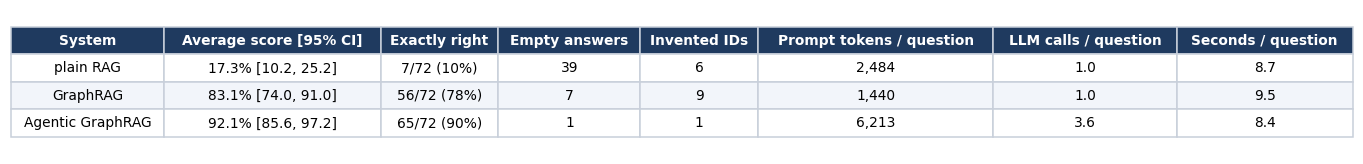


average score per question type (in brackets: answers that are exactly right / questions)
Type                        Question Hops  plain RAG    GraphRAG Agentic GraphRAG
  A1             techniques of a CVE    1  70% (4/8)  100% (8/8)       100% (8/8)
  A2          KEV count of a product    1  38% (3/8)   88% (7/8)        75% (6/8)
  B1               tactics via a CVE    2  27% (0/8)  100% (8/8)       100% (8/8)
  B2           mitigations via a CVE    2   0% (0/8)  100% (7/8)       100% (8/8)
  B3     groups using all techniques    2   0% (0/8)   98% (7/8)       100% (8/8)
  C1             tactics via a stack    3  20% (0/8)   88% (7/8)       100% (8/8)
  C2        top-3 groups for a stack    3   0% (0/8)    0% (0/8)        88% (7/8)
  C3 KEV CVEs of a stack in a tactic    3   2% (0/8)   75% (5/8)        88% (7/8)
  D1               patch-first top 3    1   0% (0/8)  100% (7/8)        79% (5/8)
 ALL                                      17% (7/72) 83% (56/72)      92% (65/72)
[table 

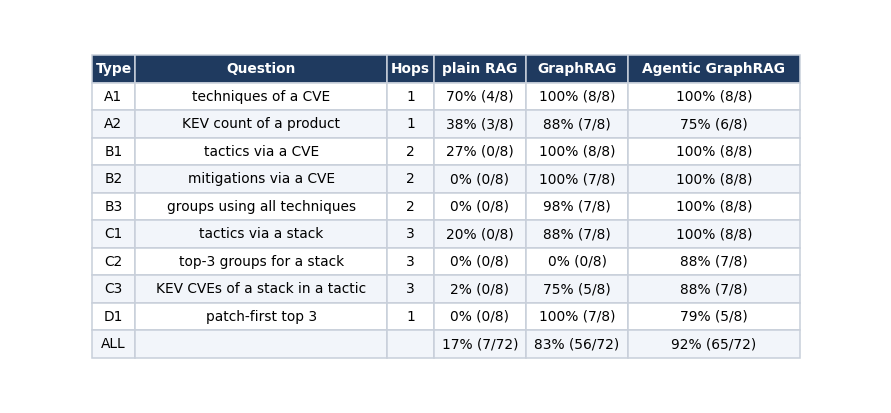


average score by number of hops
 Hops  Questions plain RAG GraphRAG Agentic GraphRAG
    1         24       36%      96%              85%
    2         24        9%      99%             100%
    3         24        7%      54%              92%

outcome of the test answers (number of questions)
outcome           exactly right  partly right  wrong  empty answer
system                                                            
plain RAG                     7            11     15            39
GraphRAG                     56             5      4             7
Agentic GraphRAG             65             2      4             1
[table saved]  table_qa_outcomes.png  (+ .csv)


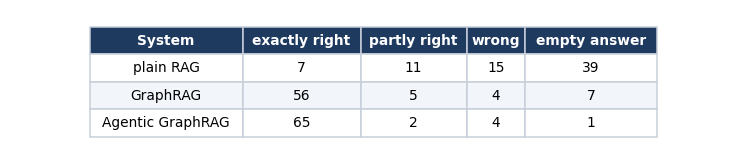


paired comparison on the same test questions (difference in average score, 95% bootstrap interval; questions better / worse / equal):
  GraphRAG - plain RAG: +65.8 points [+55.0, +75.5] | better 54, worse 1, equal 17
  Agentic GraphRAG - GraphRAG: +9.0 points [-1.4, +19.2] | better 14, worse 6, equal 52
  Agentic GraphRAG - plain RAG: +74.8 points [+65.7, +83.0] | better 60, worse 0, equal 12
[figure saved] fig_qa_score_by_type.png


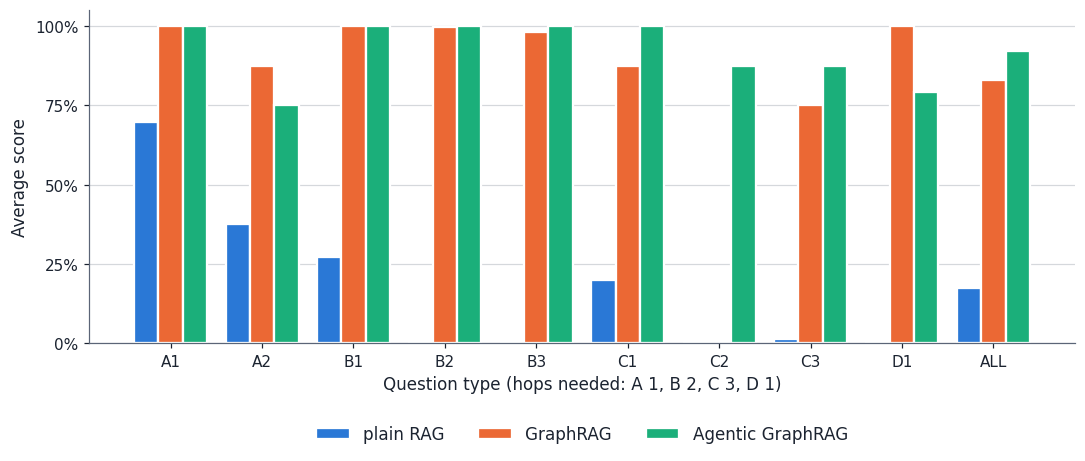

[figure saved] fig_qa_score_by_hops.png


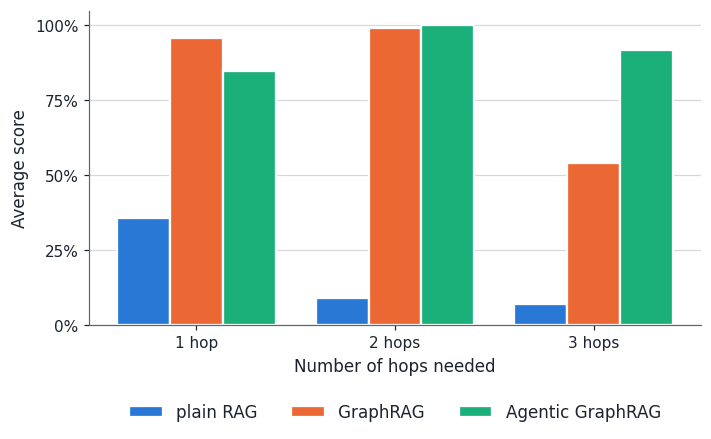

[figure saved] fig_qa_cost_accuracy.png


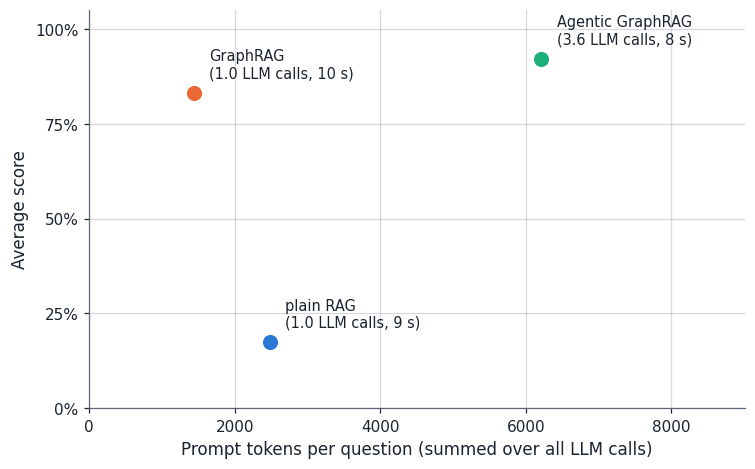


===== Ablation: GraphRAG with its priority table in CVE-id order instead of (KEV, EPSS, CVSS) order, question type D1 (dev + test) =====
  D1 average score (12 questions): GraphRAG with the priority table 100% | GraphRAG with the table in CVE-id order 22% | Agentic GraphRAG 78%

===== Weakest Agentic GraphRAG answers on the test questions =====
  tool errors per question 0.35 | answers forced by the step limit 0 | questions answered by submitting a set 5

  [A2-08] score 0.00: Count the CVEs in the CISA KEV catalogue that list netapp h410s firmware among their vulnerable products....
    reply 15 | gold 12
      filter_cves {"source":"S1","kev":true,"min_cvss":0,"min_epss":0,"via_tactic":""}  ->  'ERROR: this needs CVE items but S1 holds Product items'
      neighbors {"hop":"product_to_cves","min_links":"all","source":"S1"}  ->  'S2: 37 CVE item(s) (product_to_cves from 1 source item(s)); showing 1-25:\nCVE-2018-25032 |'
      show {"n":60,"offset":0,"source":"S2"}  ->  'S2: 37 CVE i

In [ ]:
# ============ BLOCK 13 : FINAL question-answering evaluation on the TEST questions (plain RAG vs GraphRAG vs Agentic GraphRAG) ============
# Needs Block 1, 9, 10, 11 and 12 run in THIS session (same GPU runtime, local model running). Runtime: about 40-60 minutes, nothing to do while it runs; every answer is saved on Drive, so a stopped run continues where it stopped.
# Protocol: every design choice so far was made on the 36 DEV questions. The 72 TEST questions are answered once here, with frozen settings, and are the numbers of the report.
if 'agent' not in globals() or 'graphrag' not in globals() or 'plain_rag' not in globals(): raise RuntimeError('Run Block 1, 9, 10, 11 and 12 first in this session.')
print(f"LLM backend: {CFG['backend']} / {CFG['model']}" + ('' if CFG['backend'] == 'ollama' else '   <- NOTE: not the local model; run Block 10 first'))
N_BOOT = 2000
SYS = ['plain RAG', 'GraphRAG', 'Agentic GraphRAG']
COL = {'plain RAG': '#2a78d6', 'GraphRAG': '#eb6834', 'Agentic GraphRAG': '#1baf7a'}
INK, INK2 = '#1B2330', '#5B6577'
TDESC = {'A1': 'techniques of a CVE', 'A2': 'KEV count of a product', 'B1': 'tactics via a CVE', 'B2': 'mitigations via a CVE', 'B3': 'groups using all techniques', 'C1': 'tactics via a stack', 'C2': 'top-3 groups for a stack', 'C3': 'KEV CVEs of a stack in a tactic', 'D1': 'patch-first top 3'}
TEMPL = sorted(TDESC)
HOPS_OF = {q['template']: q['hops'] for q in BENCH}
def boot_ci(x, n=N_BOOT, seed=0):
    x = np.asarray(x, float); m = np.random.default_rng(seed).choice(x, size=(n, len(x))).mean(1); return np.percentile(m, [2.5, 97.5])
def boot_diff(a, b, n=N_BOOT, seed=1):                                       # paired: same questions, same order
    d = np.asarray(a, float) - np.asarray(b, float); m = np.random.default_rng(seed).choice(d, size=(n, len(d))).mean(1); return d.mean(), np.percentile(m, [2.5, 97.5])
pct = lambda v: f'{100 * float(v):.0f}%'

# ------------------------------------------------------------------------------------------------------------
# PART 1 : last design choice, made on DEV only: one extra sentence in the agent's instructions (the weakest dev answer picked CVEs from an unsorted preview instead of calling sort_cves)
# ------------------------------------------------------------------------------------------------------------
section('Agent instructions: version 1 (Block 12) against version 2, on the DEV questions')
SYSTEM_AGENT_V1 = globals().get('SYSTEM_AGENT_V1', SYSTEM_AGENT)
SYSTEM_AGENT_V2 = SYSTEM_AGENT_V1 + (' Important: a preview shows only the first items of a set in ID order, not the best ones, so never rank, pick or count from a preview: use sort_cves to rank, filter_cves to select, '
                                     'and the size on the first line of a result (for example "S3: 41 CVE item(s)") to count. Every item of your answer must come from a tool result.')
SYSTEM_AGENT = SYSTEM_AGENT_V1; D1_ = pd.DataFrame(list(_load(RES / f'answers_agentic__{MODEL_TAG}.json').values())); D1_ = D1_[D1_.split == 'dev']
SYSTEM_AGENT = SYSTEM_AGENT_V2; V2_DONE = run_system('agentic_v2', agent, splits=('dev',)); D2_ = pd.DataFrame([v for v in V2_DONE.values() if v['split'] == 'dev'])
cmpv = pd.DataFrame({'version 1': D1_.groupby('template').score.mean(), 'version 2': D2_.groupby('template').score.mean()}); cmpv.loc['ALL'] = [D1_.score.mean(), D2_.score.mean()]
print((cmpv.map(pct)).to_string()); USE_V2 = D2_.score.mean() >= D1_.score.mean()
SYSTEM_AGENT = SYSTEM_AGENT_V2 if USE_V2 else SYSTEM_AGENT_V1
print(f"\nfrozen for the test run: agent instructions version {'2' if USE_V2 else '1'} (dev average {100 * (D2_ if USE_V2 else D1_).score.mean():.1f}%). Nothing about the agent, GraphRAG or plain RAG is changed after this line.")

# ------------------------------------------------------------------------------------------------------------
# PART 2 : the final runs (dev + test for each system; dev answers that exist are reused)
# ------------------------------------------------------------------------------------------------------------
section('Final runs on the TEST questions')
for nm_, fn_, spl in (('plain_rag', plain_rag, ('test',)), ('graphrag', graphrag, ('test',)), ('agentic_final', agent, ('dev', 'test'))):
    print(f'\n--- {nm_} ---'); run_system(nm_, fn_, splits=spl)
def load_sys(name, label):
    d = pd.DataFrame(list(_load(RES / f'answers_{name}__{MODEL_TAG}.json').values())); d['system'] = label; return d
FIN = pd.concat([load_sys('plain_rag', 'plain RAG'), load_sys('graphrag', 'GraphRAG'), load_sys('agentic_final', 'Agentic GraphRAG')], ignore_index=True)
TEST = FIN[FIN.split == 'test']; n_test = {s: int((TEST.system == s).sum()) for s in SYS}; n_all_test = sum(q['split'] == 'test' for q in BENCH)
section('Check')
print(f'  answered test questions per system: {n_test} (expected {n_all_test} each)')
if any(v != n_all_test for v in n_test.values()): print('  A run stopped early: run this block again, it continues. The tables below are NOT final.')
FIN.drop(columns=['meta', 'raw', 'parsed'], errors='ignore').to_csv(RES / 'qa_final_per_question.csv', index=False)

# ------------------------------------------------------------------------------------------------------------
# PART 3 : tables
# ------------------------------------------------------------------------------------------------------------
section('Results on the test questions')
rows = []
for s in SYS:
    d = TEST[TEST.system == s]
    if d.empty: continue
    lo, hi = boot_ci(d.score); k = int(d.strict.sum())
    rows.append({'System': s, 'Average score [95% CI]': f'{100 * d.score.mean():.1f}% [{100 * lo:.1f}, {100 * hi:.1f}]', 'Exactly right': f'{k}/{len(d)} ({100 * k / len(d):.0f}%)', 'Empty answers': int((d.n_pred == 0).sum()),
                 'Invented IDs': int(d.invalid.sum()), 'Prompt tokens / question': f'{d.pt.mean():,.0f}', 'LLM calls / question': f'{d.calls.mean():.1f}', 'Seconds / question': f'{d.lat.mean():.1f}'})
T_SUM = pd.DataFrame(rows); print(T_SUM.to_string(index=False))
save_table(T_SUM, 'table_qa_summary', f'Final results on the {n_all_test} test questions (average score with 95% bootstrap confidence interval over questions).')

by = {s: TEST[TEST.system == s].groupby('template') for s in SYS if (TEST.system == s).any()}
T_TYPE = pd.DataFrame([{'Type': t, 'Question': TDESC[t], 'Hops': HOPS_OF[t], **{s: f"{pct(by[s].score.mean()[t])} ({int(by[s].strict.sum()[t])}/{int(by[s].size()[t])})" for s in by}} for t in TEMPL]
                      + [{'Type': 'ALL', 'Question': '', 'Hops': '', **{s: f"{pct(TEST[TEST.system == s].score.mean())} ({int(TEST[TEST.system == s].strict.sum())}/{int((TEST.system == s).sum())})" for s in by}}])
print('\naverage score per question type (in brackets: answers that are exactly right / questions)'); print(T_TYPE.to_string(index=False))
save_table(T_TYPE, 'table_qa_by_type', 'Average score per question type on the test questions (in brackets: exactly right answers / questions).')

T_HOP = pd.DataFrame([{'Hops': h, 'Questions': int(((TEST.system == SYS[0]) & (TEST.hops == h)).sum()), **{s: pct(TEST[(TEST.system == s) & (TEST.hops == h)].score.mean()) for s in by}} for h in sorted(TEST.hops.unique())])
print('\naverage score by number of hops'); print(T_HOP.to_string(index=False))

def outcome(r): return 'exactly right' if r.strict else 'empty answer' if r.n_pred == 0 else 'partly right' if r.score > 0 else 'wrong'
OUT = TEST.assign(outcome=TEST.apply(outcome, axis=1)); T_OUT = pd.crosstab(OUT.system, OUT.outcome).reindex(SYS).reindex(columns=['exactly right', 'partly right', 'wrong', 'empty answer'], fill_value=0)
print('\noutcome of the test answers (number of questions)'); print(T_OUT.to_string())
T_OUT_S = T_OUT.reset_index().rename(columns={'system': 'System'}); save_table(T_OUT_S, 'table_qa_outcomes', 'Outcome of the answers on the test questions.')

print('\npaired comparison on the same test questions (difference in average score, 95% bootstrap interval; questions better / worse / equal):')
PW = {}
for a, b in (('GraphRAG', 'plain RAG'), ('Agentic GraphRAG', 'GraphRAG'), ('Agentic GraphRAG', 'plain RAG')):
    if a in by and b in by:
        A_, B_ = TEST[TEST.system == a].set_index('id').score, TEST[TEST.system == b].set_index('id').score; ids = sorted(set(A_.index) & set(B_.index)); m, (lo, hi) = boot_diff(A_[ids], B_[ids])
        PW[f'{a} - {b}'] = {'diff': float(m), 'lo': float(lo), 'hi': float(hi)}
        print(f'  {a} - {b}: {100 * m:+.1f} points [{100 * lo:+.1f}, {100 * hi:+.1f}] | better {int((A_[ids] > B_[ids]).sum())}, worse {int((A_[ids] < B_[ids]).sum())}, equal {int((A_[ids] == B_[ids]).sum())}')

# ------------------------------------------------------------------------------------------------------------
# PART 4 : figures (one chart per file)
# ------------------------------------------------------------------------------------------------------------
def style(ax):
    ax.set_facecolor('white'); ax.grid(axis='y', alpha=0.25, color=INK2); ax.grid(axis='x', visible=False); ax.set_axisbelow(True)
    for s_ in ('top', 'right'): ax.spines[s_].set_visible(False)
    for s_ in ('left', 'bottom'): ax.spines[s_].set_color(INK2)
    ax.tick_params(colors=INK, labelsize=10)
def grouped_bars(groups, vals, ylabel, xlabel, name, caption, figsize=(10, 4.4)):
    fig, ax = plt.subplots(figsize=figsize); n = len(vals); w = 0.8 / n; x0 = np.arange(len(groups))
    for i, s in enumerate(vals): ax.bar(x0 + (i - (n - 1) / 2) * w, vals[s], width=w, color=COL[s], edgecolor='white', linewidth=1.5, label=s)
    ax.set_xticks(x0); ax.set_xticklabels(groups); ax.set_ylim(0, 1.05); ax.set_yticks([0, .25, .5, .75, 1]); ax.set_yticklabels(['0%', '25%', '50%', '75%', '100%'])
    ax.set_ylabel(ylabel, color=INK); ax.set_xlabel(xlabel, color=INK); style(ax)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=n, frameon=False, labelcolor=INK); fig.tight_layout(); save_fig(fig, name, caption)
S_ = [s for s in SYS if s in by]
grouped_bars(TEMPL + ['ALL'], {s: [by[s].score.mean()[t] for t in TEMPL] + [TEST[TEST.system == s].score.mean()] for s in S_}, 'Average score', 'Question type (hops needed: A 1, B 2, C 3, D 1)', 'fig_qa_score_by_type',
             'Average score per question type on the test questions, for the three systems.')
grouped_bars([f'{h} hop' + ('s' if h > 1 else '') for h in sorted(TEST.hops.unique())], {s: [TEST[(TEST.system == s) & (TEST.hops == h)].score.mean() for h in sorted(TEST.hops.unique())] for s in S_}, 'Average score', 'Number of hops needed', 'fig_qa_score_by_hops',
             'Average score by number of graph hops needed to answer the question (test questions).', figsize=(6.6, 4.2))
fig, ax = plt.subplots(figsize=(7, 4.4))
for s in S_:
    d = TEST[TEST.system == s]; ax.scatter(d.pt.mean(), d.score.mean(), s=130, color=COL[s], edgecolor='white', linewidth=1.5, zorder=3)
    ax.annotate(f'{s}\n({d.calls.mean():.1f} LLM calls, {d.lat.mean():.0f} s)', (d.pt.mean(), d.score.mean()), textcoords='offset points', xytext=(10, 10), fontsize=9.5, color=INK)
ax.set_xlabel('Prompt tokens per question (summed over all LLM calls)', color=INK); ax.set_ylabel('Average score', color=INK); ax.set_ylim(0, 1.05); ax.set_yticks([0, .25, .5, .75, 1]); ax.set_yticklabels(['0%', '25%', '50%', '75%', '100%'])
ax.set_xlim(0, max(TEST.groupby('system').pt.mean()) * 1.45); style(ax); ax.grid(axis='x', alpha=0.25, color=INK2); fig.tight_layout(); save_fig(fig, 'fig_qa_cost_accuracy', 'Accuracy against cost: average score and prompt tokens per question (test questions).')

# ------------------------------------------------------------------------------------------------------------
# PART 5 : ablation: GraphRAG's patch-priority table is ordered by the same rule as question type D1 (KEV, then EPSS, then CVSS). How much does D1 depend on that?
# ------------------------------------------------------------------------------------------------------------
section('Ablation: GraphRAG with its priority table in CVE-id order instead of (KEV, EPSS, CVSS) order, question type D1 (dev + test)')
_prio = prio; rows_ = []
try:
    prio = lambda c: (c,)
    for q in [q for q in BENCH if q['template'] == 'D1']:
        r = graphrag(q); val, how = parse_answer(r['text'], q['answer_kind']); rows_.append({'id': q['id'], 'split': q['split'], **score_answer(q, val)})
finally: prio = _prio
AB = pd.DataFrame(rows_); full_ = FIN[(FIN.system == 'GraphRAG') & (FIN.template == 'D1')]; ag_ = FIN[(FIN.system == 'Agentic GraphRAG') & (FIN.template == 'D1')]
print(f"  D1 average score ({len(AB)} questions): GraphRAG with the priority table {pct(full_.score.mean())} | GraphRAG with the table in CVE-id order {pct(AB.score.mean())} | Agentic GraphRAG {pct(ag_.score.mean())}")

# ------------------------------------------------------------------------------------------------------------
# PART 6 : the weakest agent answers on the test questions (for the discussion in the report)
# ------------------------------------------------------------------------------------------------------------
section('Weakest Agentic GraphRAG answers on the test questions')
AGD = load_sys('agentic_final', 'Agentic GraphRAG'); AGT = AGD[AGD.split == 'test']
meta_ = {r['id']: r['meta'] for r in _load(RES / f'answers_agentic_final__{MODEL_TAG}.json').values()}
print(f"  tool errors per question {np.mean([meta_[i].get('tool_errors', 0) for i in AGT.id]):.2f} | answers forced by the step limit {sum(bool(meta_[i].get('forced')) for i in AGT.id)} | questions answered by submitting a set {sum(bool(meta_[i].get('handle')) for i in AGT.id)}")
for _, w in AGT.sort_values('score').head(4).iterrows():
    if w.score >= 1: break
    q = BQ[w['id']]; print(f"\n  [{q['id']}] score {w.score:.2f}: {q['question'][:150]}...\n    reply {str(w['parsed'])[:120]} | gold {str(q['gold'])[:120]}")
    for t_ in meta_[w['id']]['trace']: print(f"      {t_[0]} {t_[1][:100]}  ->  {t_[2][:90]!r}")

_save({'n_test': n_test, 'summary': T_SUM.to_dict('records'), 'paired': PW, 'agent_instructions_version': 2 if USE_V2 else 1, 'd1_ablation': {'graphrag_priority': float(full_.score.mean()), 'graphrag_id_order': float(AB.score.mean()), 'agentic': float(ag_.score.mean())}}, RES / 'qa_final.json')
print('\nsaved: results/qa_final.json, results/qa_final_per_question.csv, 3 figures, 2 tables in report_assets')
print('\nBLOCK 13 DONE' if all(v == n_all_test for v in n_test.values()) else '\nBLOCK 13 PARTLY DONE (a run stopped early): run it again.')


====== Load tables ======
CVEs: 10,086 | labelled CVEs: 1,207 (12.0%) | label pairs (CVE, technique): 2,819 | distinct techniques used: 192 of 706 in the graph | techniques per labelled CVE: 2.34
  [PASS] the labelled CVEs of the table agree with the maps_to edges of the graph

====== EDA 1 : missing values ======
                 Column  Missing Share
         kev_date_added     8305 82.3%
         ransomware_use     8305 82.3%
      ssvc_exploitation     4826 47.8%
       ssvc_automatable     4826 47.8%
  ssvc_technical_impact     4826 47.8%
       user_interaction     2437 24.2%
    privileges_required     2437 24.2%
         weakness (CWE)        4  0.0%
affected products (CPE)        3  0.0%
columns without any missing value: epss, attack_vector, base_score, attack_complexity, severity, description
[table saved]  table_eda_missing.png  (+ .csv)


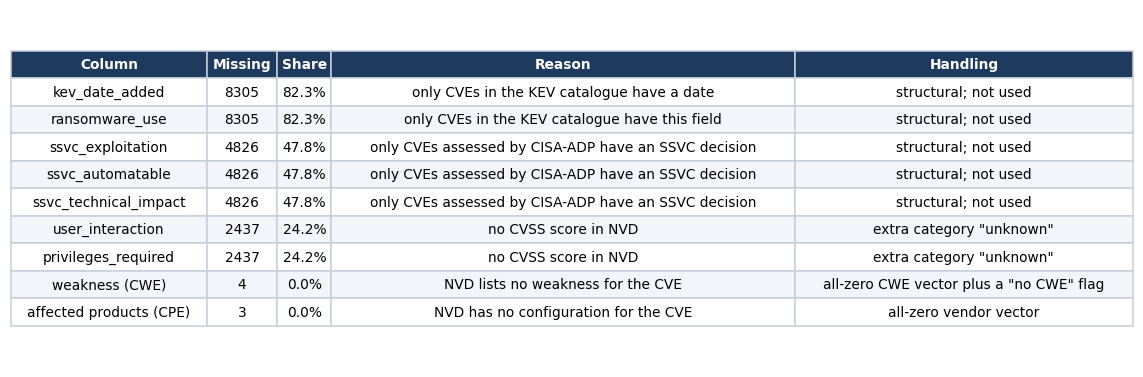

[figure saved] fig_eda_missing_values.png


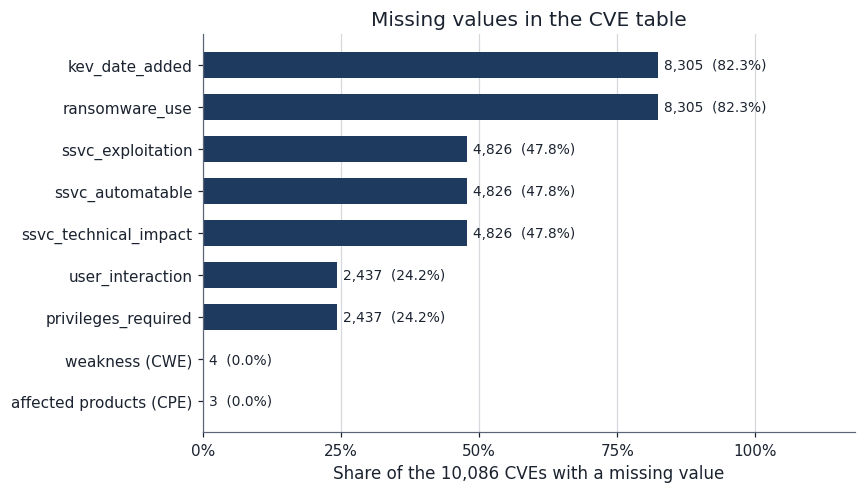


====== EDA 2 : descriptive statistics ======
                 Variable  count   mean    std    min median    max
          CVSS base score  10086   6.64   1.92   1.20   6.50  10.00
               EPSS score  10086 0.1531 0.2765 0.0006 0.0247 1.0000
       References per CVE  10086  14.19  24.99   1.00   6.00 606.00
Affected products per CVE  10086   3.40  11.58 0.0000   1.00 400.00
 Weaknesses (CWE) per CVE  10086   1.15 0.3766 0.0000   1.00   6.00
         Publication year  10086   2018   6.15   1996   2020   2026
[table saved]  table_eda_describe.png  (+ .csv)


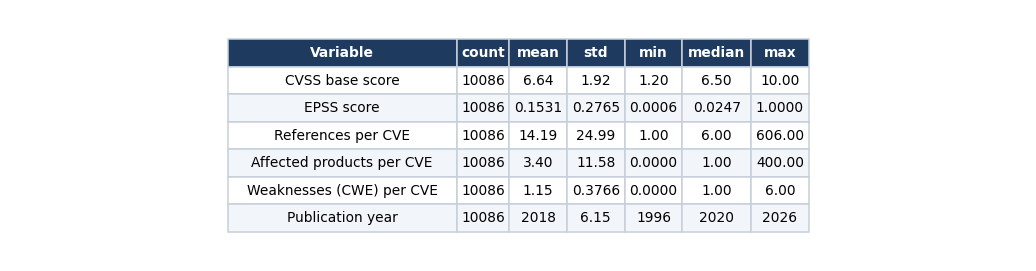


====== EDA 3 : bivariate analysis (CVSS vs EPSS, KEV vs EPSS) and correlation ======
CVSS base score vs EPSS: Spearman rho = +0.36 (n = 10,086) | EPSS median: KEV 0.533 vs not KEV 0.0194 | KEV CVEs: 1,781
[figure saved] fig_eda_cvss_vs_epss.png


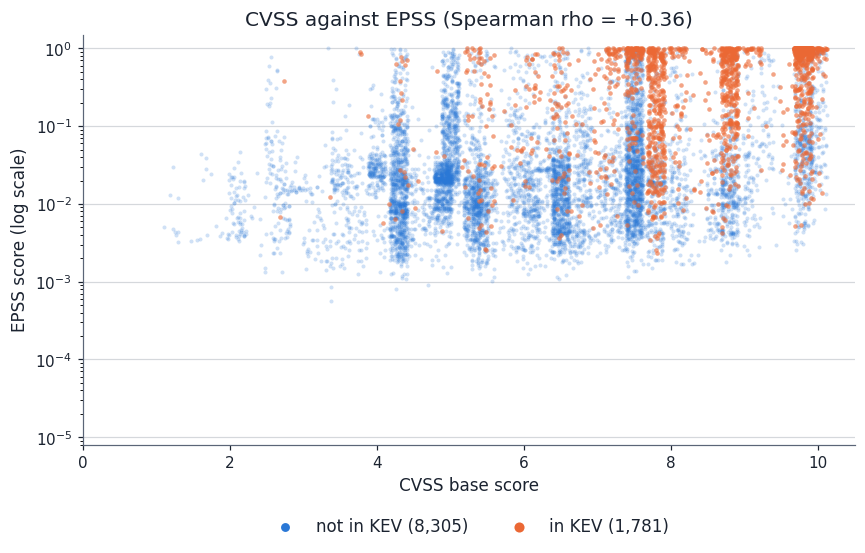

[figure saved] fig_eda_epss_by_kev.png


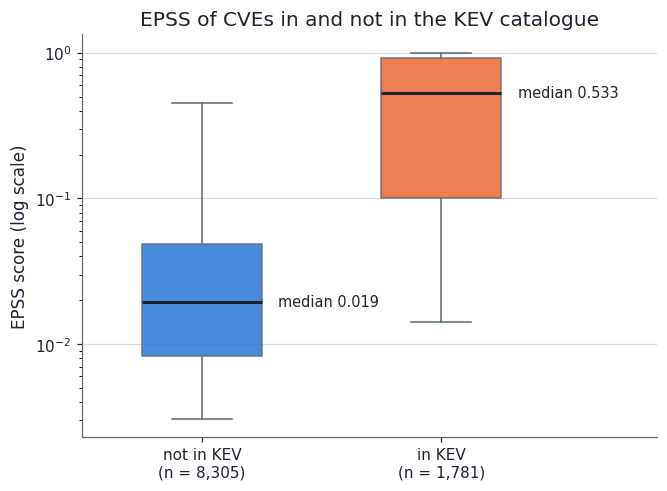

[figure saved] fig_eda_correlation.png


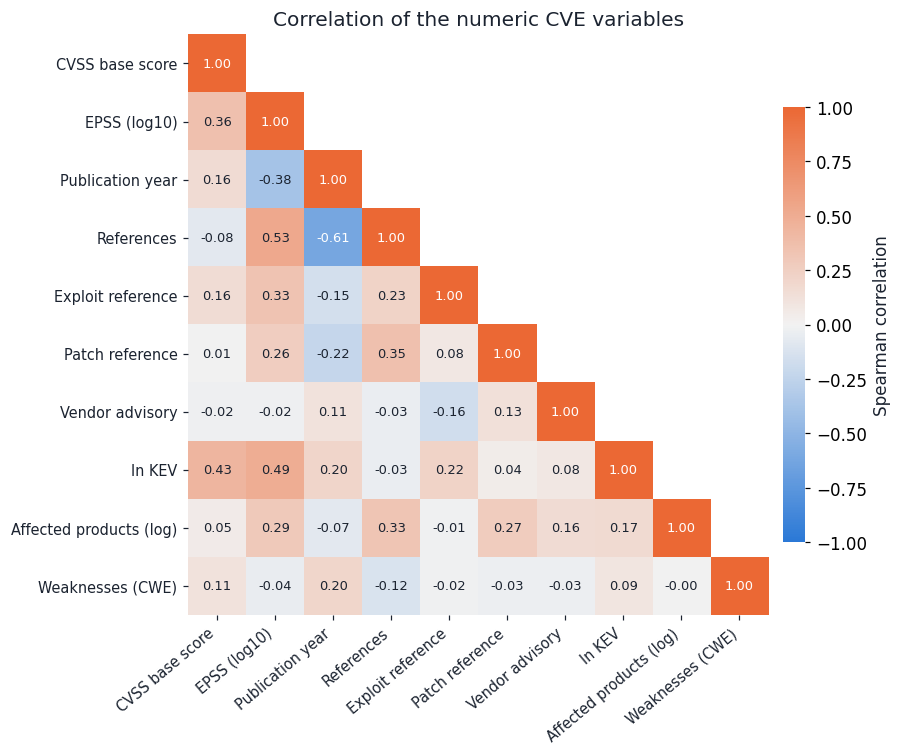

strongest correlations: References / Publication year: -0.61; References / EPSS (log10): +0.53; In KEV / EPSS (log10): +0.49; In KEV / CVSS base score: +0.43

====== EDA 4 : the labels (techniques of the labelled CVEs) ======
192 techniques occur in at least one labelled CVE | 63 (33%) occur in exactly one CVE | the 10 most frequent techniques make 58% of all label pairs | 8 techniques make half of them
[figure saved] fig_lp_technique_frequency.png


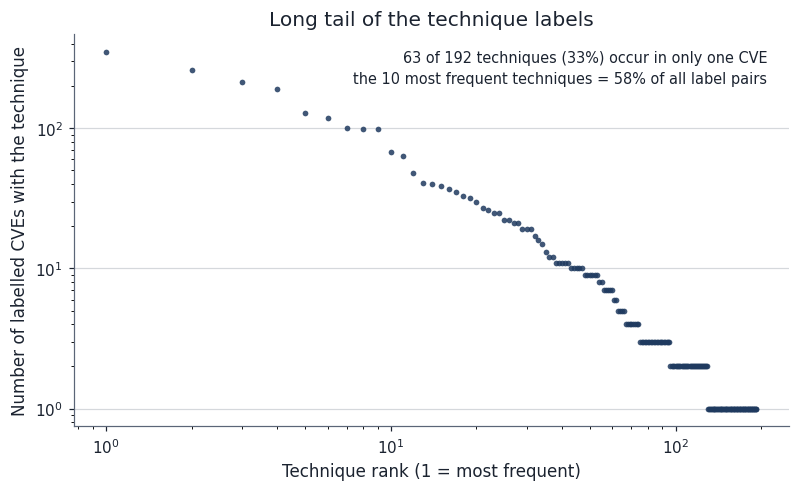

[figure saved] fig_lp_labels_by_tactic.png


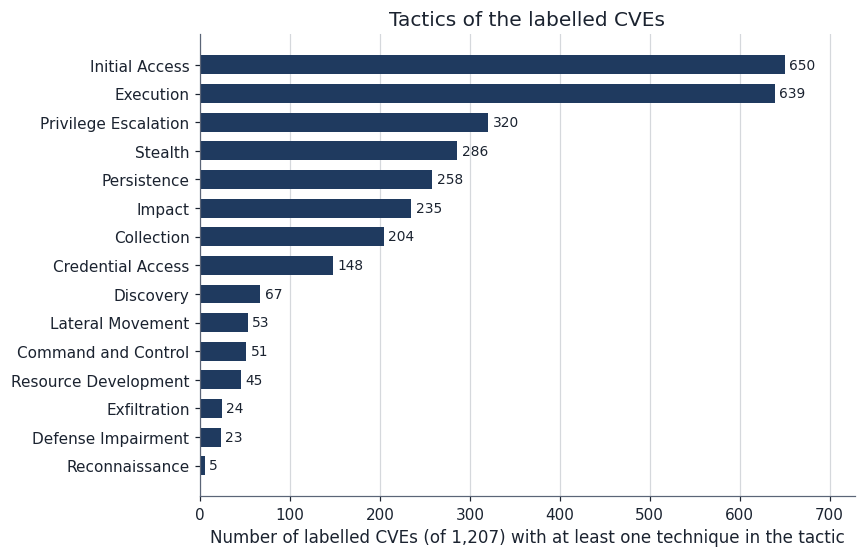

most common tactics: {'Initial Access': 650, 'Execution': 639, 'Privilege Escalation': 320, 'Stealth': 286}

====== Cold-start split of the labelled CVEs ======
     Split  CVEs  Label pairs  Distinct techniques Techniques per CVE Pairs with technique seen in training In KEV
  Training   845         1980                  179               2.34                                  100%    49%
Validation   181          422                   84               2.33                                   98%    51%
      Test   181          417                   80               2.30                                   99%    45%
[table saved]  table_lp_split.png  (+ .csv)


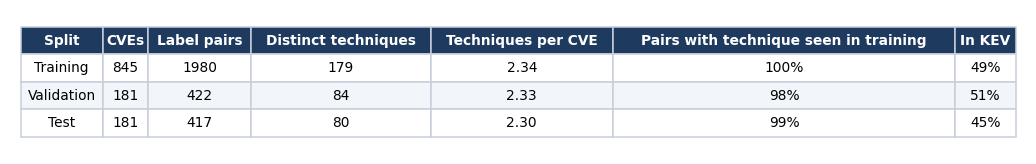

ceiling: a model that can only predict techniques seen in training can reach at most 99% recall on the test pairs (techniques with no training CVE cannot be learned)

====== Features ======
description embeddings (BAAI/bge-small-en-v1.5): 10,086 texts in 11 pieces | already on Drive: 11 | to compute: 0
TEXT   : 10,086 x 384 (unit-length vectors: True)
CWE    : 89 columns (88 weakness ids with >= 15 CVEs + a "no CWE" flag) | CVEs with at least one kept CWE: 94%
  CVSS vectors (scope, confidentiality, integrity, availability):  read from nvd_cves.parquet
CVSS   : 33 columns
VENDOR : 103 columns (100 vendors cover 92% of the CVEs)
META   : 8 columns
  [PASS] no KEV / EPSS / SSVC / label-derived column among the features
   Group Columns
    TEXT     384
     CWE      89
    CVSS      33
  VENDOR     103
    META       8
not used       -
[table saved]  table_lp_features.png  (+ .csv)


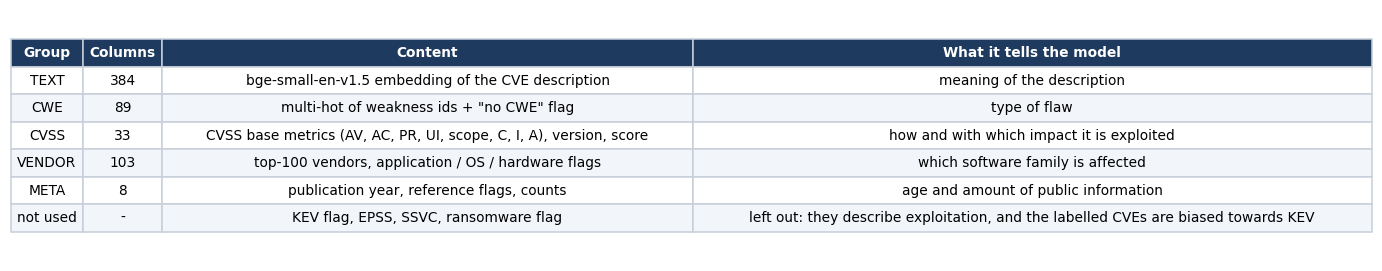

nearest training CVE by description, for the 181 test CVEs: median cosine 0.84 | share >= 0.90: 27% | share >= 0.95: 14%
test CVEs whose exact description also occurs in training: 4

====== Save ======
saved in data/processed: lp_features.npz, lp_feature_names.json, lp_labels.parquet | results/lp_data_summary.json
10,086 CVEs | 1,207 labelled (845 train / 181 val / 181 test) | 617 feature columns | 49 s

BLOCK 14 DONE


In [ ]:
# ============ BLOCK 14 : Link-prediction data: extra EDA, cold-start split, feature matrices ============
# Needs Block 1 and the data of Blocks 2-8 on Drive (it does NOT need the language model or Blocks 9-13).
# First run: about 3-6 min on a GPU runtime (it embeds 10,086 CVE descriptions), 10-15 min on CPU. Finished pieces stay on Drive.
import re, hashlib
from collections import Counter
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LinearSegmentedColormap

PROC = DIRS['proc']; T0 = time.time()
INK, INK2, NAVY = '#1B2330', '#5B6577', '#1F3A5F'
BLUE, ORANGE, GREEN = '#2a78d6', '#eb6834', '#1baf7a'
EMBED_MODEL = 'BAAI/bge-small-en-v1.5'
SPLIT_SEED, SPLIT_FRAC = 42, (0.70, 0.15, 0.15)      # cold-start split of the labelled CVEs: train / validation / test
MIN_CWE, N_VENDORS = 15, 100                            # keep CWE ids that occur in >= 15 CVEs and the 100 most frequent vendors
thousands = FuncFormatter(lambda x, _: f'{x:,.0f}')
def section(t): print('\n' + '=' * 6, t, '=' * 6)
def style(ax, grid='y'):
    ax.set_facecolor('white'); ax.set_axisbelow(True)
    ax.grid(axis=grid, alpha=0.25, color=INK2); ax.grid(axis='x' if grid == 'y' else 'y', visible=False)
    for s_ in ('top', 'right'): ax.spines[s_].set_visible(False)
    for s_ in ('left', 'bottom'): ax.spines[s_].set_color(INK2)
    ax.tick_params(colors=INK, labelsize=10)
    ax.xaxis.label.set_color(INK); ax.yaxis.label.set_color(INK); ax.title.set_color(INK)

# ------------------------------------------------------------------------------------------------------------
# PART 1 : load the tables and check that they agree with each other
# ------------------------------------------------------------------------------------------------------------
section('Load tables')
C = _load(PROC / 'cves_enriched.parquet').reset_index(drop=True)
EDG = _load(PROC / 'kg_edges.parquet'); NOD = _load(PROC / 'kg_nodes.parquet')
CWE = _load(PROC / 'nvd_cve_cwe.parquet'); PROD = _load(PROC / 'nvd_cve_products.parquet')
N = len(C); ids = C.cve_id.tolist(); idx = {c: i for i, c in enumerate(ids)}
assert C.cve_id.is_unique, 'duplicate CVE ids in cves_enriched'

LAB = EDG[EDG.rel == 'maps_to'][['src', 'dst']].drop_duplicates().copy()          # the labels = expert CVE -> technique edges of the knowledge graph
LAB['cve_id'] = LAB.src.str[4:]; LAB['technique_id'] = LAB.dst.str[5:]; LAB = LAB[['cve_id', 'technique_id']].reset_index(drop=True)
LAB['parent_id'] = LAB.technique_id.str.split('.').str[0]
assert LAB.cve_id.isin(idx).all(), 'a labelled CVE is missing from cves_enriched'
lab_cves = sorted(LAB.cve_id.unique())
print(f'CVEs: {N:,} | labelled CVEs: {len(lab_cves):,} ({100 * len(lab_cves) / N:.1f}%) | label pairs (CVE, technique): {len(LAB):,} | distinct techniques used: {LAB.technique_id.nunique()} of {int((NOD.node_type == "Technique").sum())} in the graph | techniques per labelled CVE: {len(LAB) / len(lab_cves):.2f}')
same = set(C[C.in_labelled].cve_id) == set(lab_cves)
print(f'  [{"PASS" if same else "WARN"}] the labelled CVEs of the table agree with the maps_to edges of the graph')

# ------------------------------------------------------------------------------------------------------------
# PART 2 : extra EDA (report chapter 4): missing values, descriptive statistics, bivariate analysis, correlation
# ------------------------------------------------------------------------------------------------------------
section('EDA 1 : missing values')
n_prod = PROD.assign(p=PROD.vendor.astype(str) + ':' + PROD['product'].astype(str)).groupby('cve_id').p.nunique().reindex(ids).fillna(0).astype(int)
n_cwe = CWE.groupby('cve_id').cwe_id.nunique().reindex(ids).fillna(0).astype(int)
cvss_cols = ['base_score', 'severity', 'attack_vector', 'attack_complexity', 'privileges_required', 'user_interaction']
M = {c: int(C[c].isna().sum()) for c in cvss_cols + ['epss', 'kev_date_added', 'ransomware_use', 'ssvc_exploitation', 'ssvc_automatable', 'ssvc_technical_impact'] if c in C}
M['affected products (CPE)'] = int((n_prod == 0).sum()); M['weakness (CWE)'] = int((n_cwe == 0).sum())
M['description'] = int(C.description.isna().sum() + (C.description.fillna('').str.strip() == '').sum())
WHY = {'base_score': ('NVD has no CVSS score for the CVE', 'kept missing; model features: 0 plus a "no CVSS" flag'),
       'epss': ('no EPSS score published for the CVE', 'kept missing; EPSS is not a model feature'),
       'kev_date_added': ('only CVEs in the KEV catalogue have a date', 'structural; not used'),
       'ransomware_use': ('only CVEs in the KEV catalogue have this field', 'structural; not used'),
       'affected products (CPE)': ('NVD has no configuration for the CVE', 'all-zero vendor vector'),
       'weakness (CWE)': ('NVD lists no weakness for the CVE', 'all-zero CWE vector plus a "no CWE" flag'),
       'description': ('empty text', 'embedding of an empty text')}
for c in ('severity', 'attack_vector', 'attack_complexity', 'privileges_required', 'user_interaction'): WHY[c] = ('no CVSS score in NVD', 'extra category "unknown"')
for c in ('ssvc_exploitation', 'ssvc_automatable', 'ssvc_technical_impact'): WHY[c] = ('only CVEs assessed by CISA-ADP have an SSVC decision', 'structural; not used')
MV = pd.DataFrame([{'Column': k, 'Missing': v, 'Share': f'{100 * v / N:.1f}%', 'Reason': WHY.get(k, ('not provided',))[0], 'Handling': WHY.get(k, ('', 'kept missing'))[1]} for k, v in M.items()])
MV = MV.sort_values('Missing', ascending=False).reset_index(drop=True)
print(MV[MV.Missing > 0][['Column', 'Missing', 'Share']].to_string(index=False)); print('columns without any missing value:', ', '.join(MV[MV.Missing == 0].Column))
MV = MV[MV.Missing > 0].reset_index(drop=True)
if len(MV): save_table(MV, 'table_eda_missing', 'Missing values per column of the CVE table, why they are missing and how they are handled')
mv_plot = MV.iloc[::-1]
if len(mv_plot):
    fig, ax = plt.subplots(figsize=(8, max(2.6, 0.38 * len(mv_plot) + 1.2)))
    b = ax.barh(mv_plot.Column, 100 * mv_plot.Missing / N, color=NAVY, height=0.62)
    ax.bar_label(b, labels=[f'{v:,}  ({s})' for v, s in zip(mv_plot.Missing, mv_plot.Share)], padding=4, fontsize=9, color=INK)
    ax.set_xlim(0, 118); ax.set_xticks([0, 25, 50, 75, 100]); ax.set_xticklabels(['0%', '25%', '50%', '75%', '100%'])
    ax.set_xlabel(f'Share of the {N:,} CVEs with a missing value'); ax.set_title('Missing values in the CVE table'); style(ax, 'x'); fig.tight_layout()
    save_fig(fig, 'fig_eda_missing_values', 'Share of CVEs with a missing value, per column')
else: print('no missing values found in the listed columns -> no figure')

section('EDA 2 : descriptive statistics')
year = C.published.dt.year
NUM = pd.DataFrame({'CVSS base score': C.base_score, 'EPSS score': C.epss.astype(float), 'References per CVE': C.n_references, 'Affected products per CVE': n_prod.values, 'Weaknesses (CWE) per CVE': n_cwe.values, 'Publication year': year})
DS = NUM.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].rename(columns={'50%': 'median'})
DS = DS.reset_index().rename(columns={'index': 'Variable'}); DS['count'] = DS['count'].astype(int)
fmt = lambda v: f'{v:.4f}' if abs(v) < 1 else f'{v:,.2f}'
for c in ('mean', 'std', 'min', 'median', 'max'): DS[c] = [str(int(round(v))) if var == 'Publication year' and c != 'std' else fmt(v) for var, v in zip(DS.Variable, DS[c])]
print(DS.to_string(index=False)); save_table(DS, 'table_eda_describe', 'Descriptive statistics of the numeric CVE variables')

section('EDA 3 : bivariate analysis (CVSS vs EPSS, KEV vs EPSS) and correlation')
from scipy.stats import spearmanr
d = C[['base_score', 'epss', 'in_kev']].dropna().copy(); d['epss'] = d.epss.astype(float).clip(lower=1e-5)
rho = spearmanr(d.base_score, d.epss)[0]
rng_ = np.random.default_rng(0); jit = rng_.uniform(-0.12, 0.12, len(d)); k_ = d.in_kev.values
print(f'CVSS base score vs EPSS: Spearman rho = {rho:+.2f} (n = {len(d):,}) | EPSS median: KEV {d[d.in_kev].epss.median():.3f} vs not KEV {d[~d.in_kev].epss.median():.4f} | KEV CVEs: {int(k_.sum()):,}')
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.scatter(d.base_score[~k_] + jit[~k_], d.epss[~k_], s=7, color=BLUE, alpha=0.22, linewidths=0, label=f'not in KEV ({int((~k_).sum()):,})')
ax.scatter(d.base_score[k_] + jit[k_], d.epss[k_], s=9, color=ORANGE, alpha=0.6, linewidths=0, label=f'in KEV ({int(k_.sum()):,})')
ax.set_yscale('log'); ax.set_ylim(8e-6, 1.5); ax.set_xlim(0, 10.5); ax.set_xlabel('CVSS base score'); ax.set_ylabel('EPSS score (log scale)')
ax.set_title(f'CVSS against EPSS (Spearman rho = {rho:+.2f})'); style(ax, 'y'); ax.grid(axis='x', visible=False)
leg = ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, markerscale=2.2, labelcolor=INK); [h.set_alpha(1) for h in (getattr(leg, 'legend_handles', None) or getattr(leg, 'legendHandles', []))]
fig.tight_layout(); save_fig(fig, 'fig_eda_cvss_vs_epss', 'CVSS base score against EPSS score (log scale) for every CVE; KEV CVEs in orange')

fig, ax = plt.subplots(figsize=(6.2, 4.6)); grp = [d[~d.in_kev].epss.values, d[d.in_kev].epss.values]
bp = ax.boxplot(grp, patch_artist=True, whis=(5, 95), showfliers=False, widths=0.5, medianprops=dict(color=INK, lw=2))
for p_, c_ in zip(bp['boxes'], (BLUE, ORANGE)): p_.set_facecolor(c_); p_.set_alpha(0.85); p_.set_edgecolor(INK2)
for w_ in bp['whiskers'] + bp['caps']: w_.set_color(INK2)
for i_, g_ in enumerate(grp): ax.text(i_ + 1.32, np.median(g_), f'median {np.median(g_):.3f}', va='center', fontsize=9.5, color=INK)
ax.set_xticks([1, 2]); ax.set_xticklabels([f'not in KEV\n(n = {len(grp[0]):,})', f'in KEV\n(n = {len(grp[1]):,})']); ax.set_yscale('log'); ax.set_ylabel('EPSS score (log scale)'); ax.set_xlim(0.5, 2.9)
ax.set_title('EPSS of CVEs in and not in the KEV catalogue'); style(ax, 'y'); fig.tight_layout()
save_fig(fig, 'fig_eda_epss_by_kev', 'EPSS score of CVEs that are / are not in the CISA KEV catalogue (box = quartiles, whiskers = 5th to 95th percentile)')

CORR = pd.DataFrame({'CVSS base score': C.base_score, 'EPSS (log10)': np.log10(C.epss.astype(float).clip(lower=1e-5)), 'Publication year': year, 'References': C.n_references,
                     'Exploit reference': C.has_exploit_ref.astype(float), 'Patch reference': C.has_patch_ref.astype(float), 'Vendor advisory': C.has_vendor_advisory.astype(float),
                     'In KEV': C.in_kev.astype(float), 'Affected products (log)': np.log1p(n_prod.values), 'Weaknesses (CWE)': n_cwe.values}).corr(method='spearman')
mask = np.triu(np.ones_like(CORR, dtype=bool), k=1); show = CORR.where(~mask)
fig, ax = plt.subplots(figsize=(8.6, 7)); cm = LinearSegmentedColormap.from_list('div', [BLUE, '#F2F2F2', ORANGE])
im = ax.imshow(show.values, cmap=cm, vmin=-1, vmax=1)
for i_ in range(len(CORR)):
    for j_ in range(i_ + 1):
        v_ = CORR.values[i_, j_]; ax.text(j_, i_, f'{v_:.2f}', ha='center', va='center', fontsize=8.5, color='white' if abs(v_) > 0.6 else INK)
ax.set_xticks(range(len(CORR))); ax.set_xticklabels(CORR.columns, rotation=40, ha='right'); ax.set_yticks(range(len(CORR))); ax.set_yticklabels(CORR.columns)
ax.grid(False); [s_.set_visible(False) for s_ in ax.spines.values()]; ax.tick_params(colors=INK, labelsize=9.5)
cb = fig.colorbar(im, ax=ax, shrink=0.75, pad=0.02); cb.set_label('Spearman correlation', color=INK); cb.outline.set_visible(False); ax.set_title('Correlation of the numeric CVE variables', color=INK)
fig.tight_layout(); save_fig(fig, 'fig_eda_correlation', 'Spearman rank correlation between numeric CVE variables')
pairs = CORR.where(~mask & (np.eye(len(CORR)) == 0)).stack().sort_values(key=abs, ascending=False).head(4)
print('strongest correlations:', '; '.join(f'{a} / {b}: {v:+.2f}' for (a, b), v in pairs.items()))

section('EDA 4 : the labels (techniques of the labelled CVEs)')
freq = LAB.groupby('technique_id').cve_id.nunique().sort_values(ascending=False)
once = int((freq == 1).sum()); top10 = freq.head(10).sum() / len(LAB); half = int((freq.cumsum() / len(LAB) < 0.5).sum()) + 1
print(f'{len(freq)} techniques occur in at least one labelled CVE | {once} ({100 * once / len(freq):.0f}%) occur in exactly one CVE | the 10 most frequent techniques make {100 * top10:.0f}% of all label pairs | {half} techniques make half of them')
fig, ax = plt.subplots(figsize=(7.4, 4.6)); r_ = np.arange(1, len(freq) + 1)
ax.scatter(r_, freq.values, s=14, color=NAVY, alpha=0.85, linewidths=0); ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('Technique rank (1 = most frequent)'); ax.set_ylabel('Number of labelled CVEs with the technique')
ax.set_title('Long tail of the technique labels'); style(ax, 'y')
ax.text(0.97, 0.96, f'{once} of {len(freq)} techniques ({100 * once / len(freq):.0f}%) occur in only one CVE\nthe 10 most frequent techniques = {100 * top10:.0f}% of all label pairs', transform=ax.transAxes, ha='right', va='top', fontsize=9.5, color=INK, linespacing=1.5)
fig.tight_layout(); save_fig(fig, 'fig_lp_technique_frequency', 'Number of labelled CVEs per technique, techniques ranked by frequency (log-log)')

TAC = NOD[NOD.node_type == 'Tactic'].set_index('node_id').name.to_dict()
INT = EDG[EDG.rel == 'in_tactic'][['src', 'dst']].assign(technique_id=lambda x: x.src.str[5:], tactic=lambda x: x.dst.map(TAC))
tc = LAB.merge(INT[['technique_id', 'tactic']], on='technique_id').drop_duplicates(['cve_id', 'tactic']).groupby('tactic').cve_id.nunique().sort_values()
fig, ax = plt.subplots(figsize=(8, 5.2)); b = ax.barh(tc.index, tc.values, color=NAVY, height=0.66)
ax.bar_label(b, labels=[f'{v:,}' for v in tc.values], padding=3, fontsize=9, color=INK); ax.set_xlim(0, tc.max() * 1.12); ax.xaxis.set_major_formatter(thousands)
ax.set_xlabel(f'Number of labelled CVEs (of {len(lab_cves):,}) with at least one technique in the tactic'); ax.set_title('Tactics of the labelled CVEs'); style(ax, 'x'); fig.tight_layout()
save_fig(fig, 'fig_lp_labels_by_tactic', 'Number of labelled CVEs per ATT&CK tactic (a CVE counts once per tactic)')
print('most common tactics:', {k: int(v) for k, v in tc.sort_values(ascending=False).head(4).items()})

# ------------------------------------------------------------------------------------------------------------
# PART 3 : the cold-start split (a labelled CVE with ALL its labels is in exactly one of train / validation / test)
# ------------------------------------------------------------------------------------------------------------
section('Cold-start split of the labelled CVEs')
rng = np.random.default_rng(SPLIT_SEED); perm = rng.permutation(len(lab_cves)); n_tr = int(round(SPLIT_FRAC[0] * len(lab_cves))); n_va = int(round(SPLIT_FRAC[1] * len(lab_cves)))
SPL = {}
for k, p in enumerate(perm): SPL[lab_cves[p]] = 'train' if k < n_tr else 'val' if k < n_tr + n_va else 'test'
LAB['split'] = LAB.cve_id.map(SPL)
assert LAB.split.notna().all() and set(SPL) == set(lab_cves) and len(set(LAB[LAB.split == 'train'].cve_id) & set(LAB[LAB.split == 'test'].cve_id)) == 0
tr_t = set(LAB[LAB.split == 'train'].technique_id)
rows = []
for s in ('train', 'val', 'test'):
    L = LAB[LAB.split == s]; seen = L.technique_id.isin(tr_t)
    rows.append({'Split': {'train': 'Training', 'val': 'Validation', 'test': 'Test'}[s], 'CVEs': L.cve_id.nunique(), 'Label pairs': len(L), 'Distinct techniques': L.technique_id.nunique(),
                 'Techniques per CVE': f'{len(L) / L.cve_id.nunique():.2f}', 'Pairs with technique seen in training': f'{100 * seen.mean():.0f}%',
                 'In KEV': f'{100 * C.set_index("cve_id").loc[sorted(L.cve_id.unique()), "in_kev"].mean():.0f}%'})
SP = pd.DataFrame(rows); print(SP.to_string(index=False)); save_table(SP, 'table_lp_split', 'Cold-start split of the labelled CVEs')
print(f'ceiling: a model that can only predict techniques seen in training can reach at most {SP.iloc[2]["Pairs with technique seen in training"]} recall on the test pairs (techniques with no training CVE cannot be learned)')

# ------------------------------------------------------------------------------------------------------------
# PART 4 : features.  Groups: TEXT (description embedding), CWE, CVSS, VENDOR, META.   Left out on purpose: KEV, EPSS, SSVC and everything derived from the labels.
# ------------------------------------------------------------------------------------------------------------
section('Features')
# ---- TEXT : sentence embeddings of the CVE descriptions (cached in pieces on Drive) ----
desc = C.description.fillna('').astype(str).tolist()
H = hashlib.md5((EMBED_MODEL + '\n'.join(desc)).encode()).hexdigest()[:10]; EMB_DIR = DIRS['cache'] / f'lp_desc_emb_{H}'; EMB_DIR.mkdir(parents=True, exist_ok=True); SHARD = 1000
def get_embedder():
    if 'EMBEDDER_OVERRIDE' in globals(): return globals()['EMBEDDER_OVERRIDE'], 'test stand-in'
    try:
        import torch; gpu = torch.cuda.is_available()
    except Exception: gpu = False
    try: from sentence_transformers import SentenceTransformer
    except ImportError:
        import subprocess; subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'sentence-transformers']); from sentence_transformers import SentenceTransformer
    m = SentenceTransformer(EMBED_MODEL, device='cuda' if gpu else 'cpu'); m.max_seq_length = 256
    if gpu: m.half()
    return (lambda xs: np.asarray(m.encode(list(xs), batch_size=128 if gpu else 32, normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False), dtype=np.float32)), ('GPU' if gpu else 'CPU')
n_sh = (N + SHARD - 1) // SHARD; todo = [s for s in range(n_sh) if not (EMB_DIR / f'shard_{s:03d}.npy').exists()]
print(f'description embeddings ({EMBED_MODEL}): {N:,} texts in {n_sh} pieces | already on Drive: {n_sh - len(todo)} | to compute: {len(todo)}')
if todo:
    embed, device = get_embedder(); t1 = time.time(); print('  device:', device)
    if device == 'CPU': print(f'  NOTE: no GPU, this takes roughly {len(todo) * 1.2:.0f} min. You can stop and restart: finished pieces stay on Drive.')
    for k_, s in enumerate(todo):
        E_ = embed(desc[s * SHARD:(s + 1) * SHARD]); tmp = EMB_DIR / f'shard_{s:03d}.tmp'
        with open(tmp, 'wb') as f: np.save(f, E_.astype(np.float16))
        os.replace(tmp, EMB_DIR / f'shard_{s:03d}.npy'); el = time.time() - t1
        print(f'  piece {s + 1}/{n_sh} done | about {el / (k_ + 1) * (len(todo) - k_ - 1) / 60:.1f} min left')
X_text = np.concatenate([np.load(EMB_DIR / f'shard_{s:03d}.npy') for s in range(n_sh)]).astype(np.float32)
assert X_text.shape[0] == N and np.isfinite(X_text).all(), 'embedding matrix has the wrong shape or contains NaN'
print(f'TEXT   : {X_text.shape[0]:,} x {X_text.shape[1]} (unit-length vectors: {bool(np.allclose(np.linalg.norm(X_text, axis=1), 1, atol=2e-2))})')

# ---- CWE : one column per frequent weakness id ----
cc = CWE.drop_duplicates(['cve_id', 'cwe_id']).groupby('cwe_id').cve_id.nunique(); cwe_keep = sorted(cc[cc >= MIN_CWE].index)
cwe_i = {c: j for j, c in enumerate(cwe_keep)}; X_cwe = np.zeros((N, len(cwe_keep) + 1), np.float32)
for cve, cw in zip(CWE.cve_id, CWE.cwe_id):
    if cve in idx and cw in cwe_i: X_cwe[idx[cve], cwe_i[cw]] = 1
X_cwe[:, -1] = (n_cwe.values == 0)
names_cwe = cwe_keep + ['no CWE']
print(f'CWE    : {X_cwe.shape[1]} columns ({len(cwe_keep)} weakness ids with >= {MIN_CWE} CVEs + a "no CWE" flag) | CVEs with at least one kept CWE: {100 * (X_cwe[:, :-1].sum(1) > 0).mean():.0f}%')

# ---- CVSS : base metrics from the table, the other metrics (scope, C, I, A) from the vector strings if the parsed NVD table is on Drive ----
def onehot(series, name, order=None):
    s = series.fillna('unknown').astype(str).str.upper(); cats = order or sorted(s.unique()); cats = [c for c in cats if c in set(s)] + (['UNKNOWN'] if 'UNKNOWN' not in cats and (s == 'UNKNOWN').any() else [])
    return np.stack([(s == c).values for c in cats], 1).astype(np.float32), [f'{name}={c.lower()}' for c in cats]
blocks, names_cvss = [], []
for col, nm in (('attack_vector', 'AV'), ('attack_complexity', 'AC'), ('privileges_required', 'PR'), ('user_interaction', 'UI'), ('cvss_version_used', 'version')):
    a, n_ = onehot(C[col], nm); blocks.append(a); names_cvss += n_
VEC_PATH = PROC / 'nvd_cves.parquet'; have_vec = False
if VEC_PATH.exists():
    V = _load(VEC_PATH); vc_ = [c for c in V.columns if c.endswith('_vector')]
    if vc_:
        V = V.drop_duplicates('cve_id').set_index('cve_id').reindex(ids); ver = C.cvss_version_used.fillna('').values
        def vec_of(i): v = V[f'{ver[i]}_vector'].iloc[i] if f'{ver[i]}_vector' in V else None; return v if isinstance(v, str) else ''
        P = [dict(kv.split(':', 1) for kv in vec_of(i).split('/') if ':' in kv) for i in range(N)]
        def metric(p, key3, key4=None): return p.get(key3) or (p.get(key4) if key4 else None)
        mp = {'P': 'L', 'C': 'H'}                                  # CVSS v2 impact levels None / Partial / Complete -> N / L / H
        comp = {'S': [metric(p, 'S') for p in P], 'C': [], 'I': [], 'A': []}
        for p, v in zip(P, ver):
            for k4, k in (('VC', 'C'), ('VI', 'I'), ('VA', 'A')):
                x = metric(p, k, k4); comp[k].append(mp.get(x, x) if v == 'v2' else x)
        for k in ('S', 'C', 'I', 'A'):
            a, n_ = onehot(pd.Series(comp[k]), {'S': 'scope', 'C': 'conf', 'I': 'integ', 'A': 'avail'}[k]); blocks.append(a); names_cvss += n_
        have_vec = True
print(f'  CVSS vectors (scope, confidentiality, integrity, availability): ', 'read from nvd_cves.parquet' if have_vec else 'nvd_cves.parquet not found or without vectors -> these 4 metrics are skipped')
cvss_score = C.base_score.fillna(0).values.astype(np.float32)[:, None]; cvss_miss = C.base_score.isna().values.astype(np.float32)[:, None]
X_cvss = np.hstack(blocks + [cvss_score, cvss_miss]); names_cvss += ['base_score', 'no CVSS']
print(f'CVSS   : {X_cvss.shape[1]} columns')

# ---- VENDOR : most frequent vendors, plus application / OS / hardware flags ----
pv = PROD.drop_duplicates(['cve_id', 'vendor']); vcount = pv.groupby('vendor').cve_id.nunique().sort_values(ascending=False); vend = list(vcount.head(N_VENDORS).index)
vi = {v: j for j, v in enumerate(vend)}; parts = ['a', 'o', 'h']; X_vendor = np.zeros((N, len(vend) + len(parts)), np.float32)
for cve, v in zip(pv.cve_id, pv.vendor):
    if cve in idx and v in vi: X_vendor[idx[cve], vi[v]] = 1
for cve, p_ in zip(PROD.drop_duplicates(['cve_id', 'part']).cve_id, PROD.drop_duplicates(['cve_id', 'part']).part):
    if cve in idx and p_ in parts: X_vendor[idx[cve], len(vend) + parts.index(p_)] = 1
names_vendor = [f'vendor={v}' for v in vend] + [f'part={p_}' for p_ in parts]
print(f'VENDOR : {X_vendor.shape[1]} columns ({len(vend)} vendors cover {100 * (X_vendor[:, :len(vend)].sum(1) > 0).mean():.0f}% of the CVEs)')

# ---- META : year, reference flags, counts ----
words = C.description.fillna('').str.split().str.len()
X_meta = np.stack([(year - 2000).fillna(year.median() - 2000).values / 10, C.has_exploit_ref.astype(float), C.has_patch_ref.astype(float), C.has_vendor_advisory.astype(float),
                   np.log1p(C.n_references), np.log1p(n_prod.values), np.log1p(n_cwe.values), np.log1p(words)], 1).astype(np.float32)
names_meta = ['year', 'exploit reference', 'patch reference', 'vendor advisory', 'log references', 'log products', 'log weaknesses', 'log description words']
print(f'META   : {X_meta.shape[1]} columns')

GROUPS = {'TEXT': (X_text, [f'emb{j}' for j in range(X_text.shape[1])]), 'CWE': (X_cwe, names_cwe), 'CVSS': (X_cvss, names_cvss), 'VENDOR': (X_vendor, names_vendor), 'META': (X_meta, names_meta)}
bad = [n_ for _, (_, nm) in GROUPS.items() for n_ in nm if re.search(r'kev|epss|ssvc|ransom|n_tech|labelled', n_, re.I)]
assert not bad, f'a leaking column slipped in: {bad}'
print('  [PASS] no KEV / EPSS / SSVC / label-derived column among the features')
DESC = {'TEXT': ('bge-small-en-v1.5 embedding of the CVE description', 'meaning of the description'), 'CWE': ('multi-hot of weakness ids + "no CWE" flag', 'type of flaw'),
        'CVSS': ('CVSS base metrics (AV, AC, PR, UI, scope, C, I, A), version, score' + ('' if have_vec else ' (scope / C / I / A not available)'), 'how and with which impact it is exploited'),
        'VENDOR': ('top-100 vendors, application / OS / hardware flags', 'which software family is affected'), 'META': ('publication year, reference flags, counts', 'age and amount of public information')}
FT = pd.DataFrame([{'Group': g, 'Columns': a.shape[1], 'Content': DESC[g][0], 'What it tells the model': DESC[g][1]} for g, (a, _) in GROUPS.items()])
FT.loc[len(FT)] = {'Group': 'not used', 'Columns': '-', 'Content': 'KEV flag, EPSS, SSVC, ransomware flag', 'What it tells the model': 'left out: they describe exploitation, and the labelled CVEs are biased towards KEV'}
print(FT[['Group', 'Columns']].to_string(index=False)); save_table(FT, 'table_lp_features', 'Feature groups used for link prediction')

# ---- a quick look at how similar test CVEs are to training CVEs (matters for k-nearest-neighbour methods and for how hard the task is) ----
sp_arr = np.array([SPL.get(c, 'none') for c in ids]); tr_i, te_i = np.where(sp_arr == 'train')[0], np.where(sp_arr == 'test')[0]
S_ = X_text[te_i] @ X_text[tr_i].T; nn = S_.max(1)
print(f'nearest training CVE by description, for the {len(te_i)} test CVEs: median cosine {np.median(nn):.2f} | share >= 0.90: {100 * (nn >= 0.90).mean():.0f}% | share >= 0.95: {100 * (nn >= 0.95).mean():.0f}%')
same_text = len({desc[i] for i in te_i} & {desc[i] for i in tr_i}); print(f'test CVEs whose exact description also occurs in training: {same_text}')

# ------------------------------------------------------------------------------------------------------------
# PART 5 : save everything for Block 15
# ------------------------------------------------------------------------------------------------------------
section('Save')
arrs = {f'X_{g.lower()}': a for g, (a, _) in GROUPS.items()}
tmp = PROC / 'lp_features.tmp.npz'; np.savez_compressed(tmp, cve_ids=np.array(ids), split=sp_arr, **arrs); os.replace(tmp, PROC / 'lp_features.npz')
_save({g: nm for g, (_, nm) in GROUPS.items()}, PROC / 'lp_feature_names.json'); _save(LAB, PROC / 'lp_labels.parquet')
_save({'split_seed': SPLIT_SEED, 'fractions': SPLIT_FRAC, 'n_labelled_cves': len(lab_cves), 'n_label_pairs': len(LAB), 'n_techniques_used': int(LAB.technique_id.nunique()), 'embed_model': EMBED_MODEL,
       'groups': {g: a.shape[1] for g, (a, _) in GROUPS.items()}, 'vectors_available': have_vec}, DIRS['results'] / 'lp_data_summary.json')
print('saved in data/processed: lp_features.npz, lp_feature_names.json, lp_labels.parquet | results/lp_data_summary.json')
chk = np.load(PROC / 'lp_features.npz'); assert chk['X_text'].shape[0] == N and list(chk['cve_ids'][:3]) == ids[:3]
print(f'{N:,} CVEs | {len(lab_cves):,} labelled ({int((sp_arr == "train").sum())} train / {int((sp_arr == "val").sum())} val / {int((sp_arr == "test").sum())} test) | {sum(a.shape[1] for a, _ in GROUPS.values()):,} feature columns | {time.time() - T0:.0f} s')
print('\nBLOCK 14 DONE')

CVSS version used per CVE: {'v31': 6514, 'v2': 2437, 'v30': 1133, 'v40': 2}
CVEs without a privileges_required value: 2,437 | of them scored with CVSS v2 only: 100%
[table saved]  table_eda_missing.png  (+ .csv)


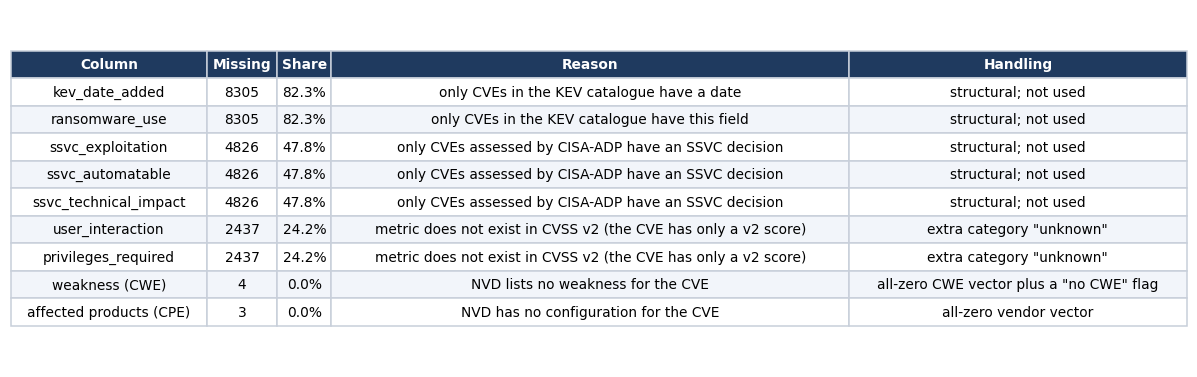

[table saved]  table_eda_describe.png  (+ .csv)


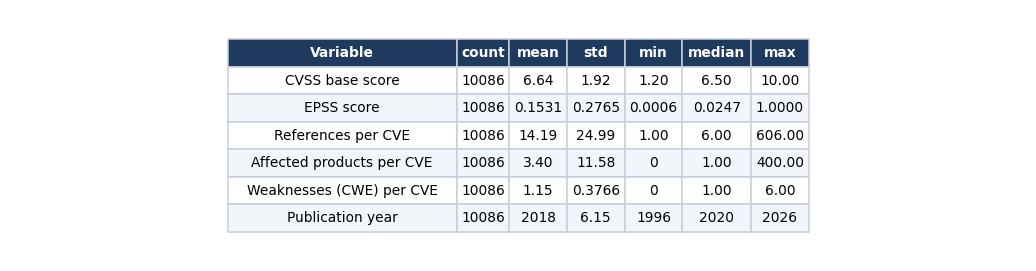

BLOCK 14b DONE


In [ ]:
# ============ BLOCK 14b (small fix, about 10 seconds): correct the reason for the two CVSS metrics in the missing-value table, tidy the statistics table ============
PROC = DIRS['proc']
C = _load(PROC / 'cves_enriched.parquet'); MV = pd.read_csv(DIRS['tables'] / 'table_eda_missing.csv', dtype=str)
pr_missing = C.privileges_required.isna(); v2_only = C.cvss_version_used.astype(str).str.lower().eq('v2')
share = float((pr_missing & v2_only).sum() / max(int(pr_missing.sum()), 1))
print('CVSS version used per CVE:', C.cvss_version_used.value_counts(dropna=False).to_dict())
print(f'CVEs without a privileges_required value: {int(pr_missing.sum()):,} | of them scored with CVSS v2 only: {100 * share:.0f}%')
why = 'metric does not exist in CVSS v2 (the CVE has only a v2 score)' if share >= 0.95 else 'metric not given in the CVSS data of NVD for this CVE'
for c in ('user_interaction', 'privileges_required', 'attack_vector', 'attack_complexity'):
    MV.loc[MV.Column == c, 'Reason'] = why
save_table(MV, 'table_eda_missing', 'Missing values per column of the CVE table, why they are missing and how they are handled')
DS = pd.read_csv(DIRS['tables'] / 'table_eda_describe.csv', dtype=str).replace({'0.0000': '0'})
save_table(DS, 'table_eda_describe', 'Descriptive statistics of the numeric CVE variables')
print('BLOCK 14b DONE')


====== Data ======
CVEs: train 845 / val 181 / test 181 | techniques to rank: 179 (training) and 186 (training + validation) | feature columns: 617
[PASS] metric self-test: perfect scores -> NDCG@10 1.00, random scores -> 0.02

====== Hyperparameter tuning (selection metric: NDCG@10 on the validation CVEs) ======
[cache hit]  tuning result from Drive (set FORCE_RETUNE = True to search again)
Model Val. NDCG@10 (default)                                                                                  Best setting Val. NDCG@10 (tuned)
   LR                  0.635                                                                                         C 0.3                0.637
  kNN                  0.591                                                     k 20; similarity power 3; text weight 2.0                0.637
  SVM                  0.603                                                                               kernel rbf; C 1                0.603
   RF                  0.614

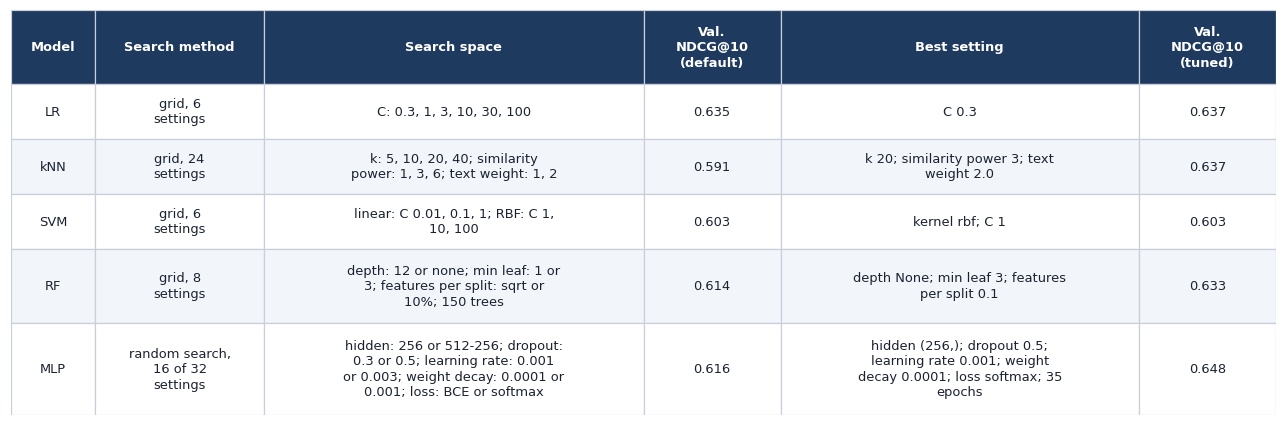

[figure saved] fig_lp_tuning.png


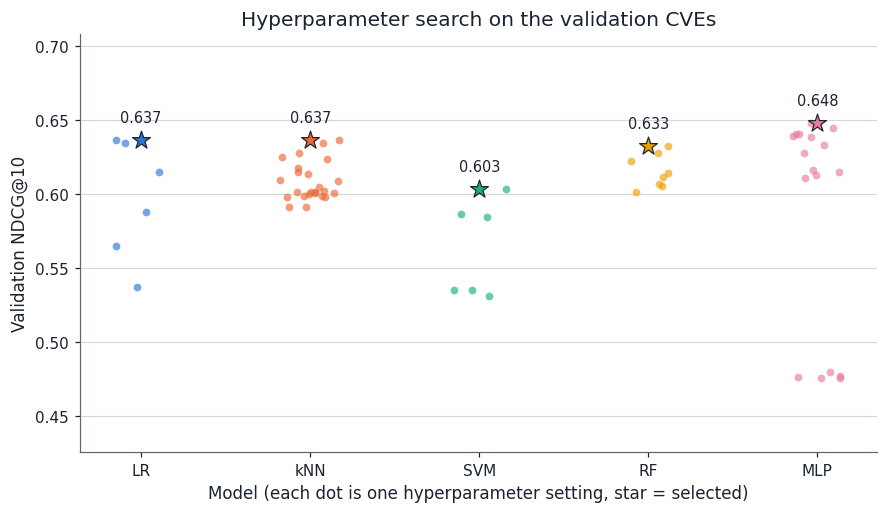

[figure saved] fig_lp_mlp_training.png


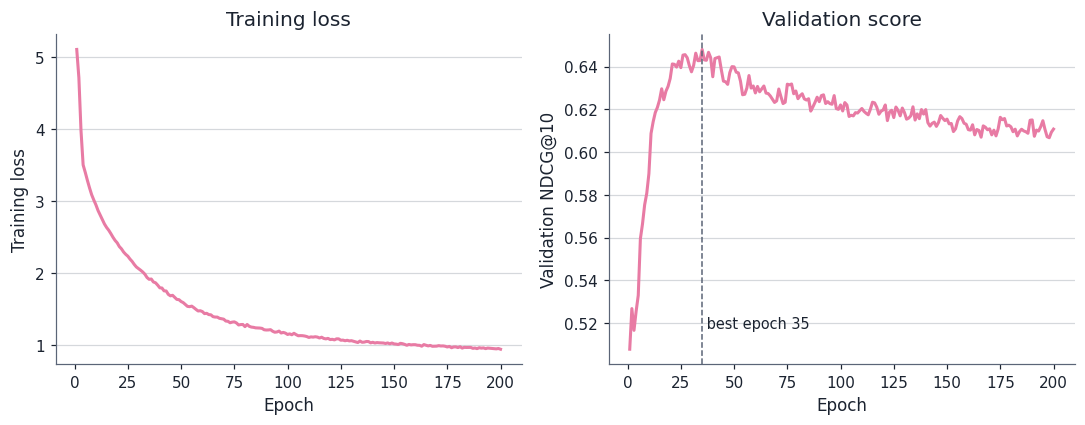

MLP: (256,) hidden units | trainable parameters 204,211 | best epoch 35

====== Final models: fitted on training + validation CVEs, evaluated once on the test CVEs ======
  LR   fitted and applied to all 10,086 CVEs in 36 s
  kNN  fitted and applied to all 10,086 CVEs in 1 s
  SVM  fitted and applied to all 10,086 CVEs in 171 s
  RF   fitted and applied to all 10,086 CVEs in 24 s
  MLP  fitted and applied to all 10,086 CVEs in 2 s
ranking metrics on the test CVEs:
                 Model Hits@1 Hits@3 Hits@5 Hits@10       MRR [95% CI]   NDCG@10 [95% CI]   MAP
   popularity baseline  0.304  0.547  0.691   0.856 0.474 [0.42, 0.53] 0.446 [0.41, 0.49] 0.357
   logistic regression  0.525  0.773  0.823   0.906 0.664 [0.61, 0.72] 0.596 [0.55, 0.64] 0.517
  k-nearest neighbours  0.481  0.735  0.834   0.950 0.632 [0.58, 0.69] 0.604 [0.56, 0.65] 0.513
support vector machine  0.536  0.779  0.801   0.884 0.663 [0.61, 0.72] 0.597 [0.55, 0.64] 0.509
         random forest  0.481  0.773  0.856   0.901

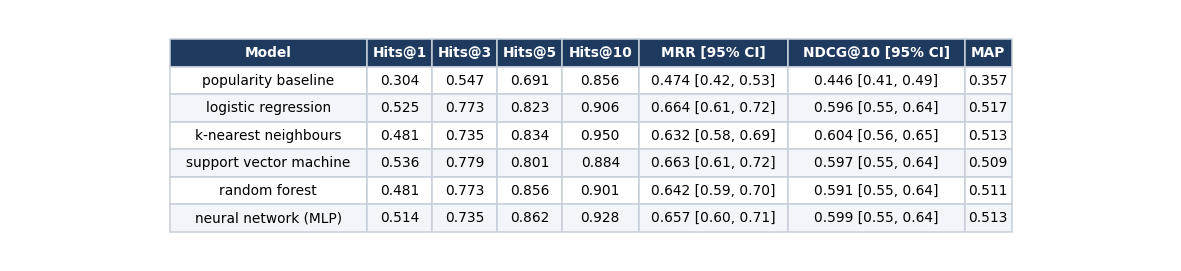


classification-style metrics on the test CVEs (top-3 predicted techniques per CVE):
                 Model Precision@3 Recall@3  F1@3 ROC-AUC (micro) ROC-AUC (macro) PR-AUC (micro)
   popularity baseline       0.215    0.281 0.244           0.910           0.500          0.159
   logistic regression       0.361    0.470 0.408           0.937           0.754          0.369
  k-nearest neighbours       0.352    0.458 0.398           0.933           0.713          0.331
support vector machine       0.357    0.465 0.404           0.822           0.746          0.370
         random forest       0.354    0.460 0.400           0.931           0.714          0.367
  neural network (MLP)       0.333    0.434 0.377           0.936           0.761          0.315
[table saved]  table_lp_classification.png  (+ .csv)


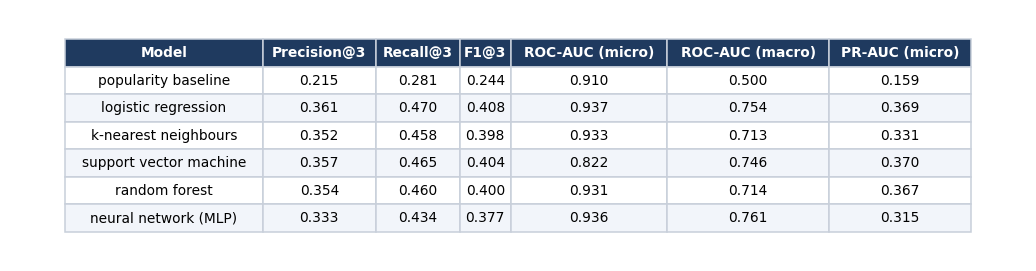


share of true test links whose technique has no training or validation CVE (cannot be found by any model): 1.4%
model selected on the VALIDATION CVEs: MLP | best on the test CVEs: kNN
  NDCG@10 MLP - popularity: +0.153 [+0.106, +0.199] | better on 111 CVEs, worse on 43
  NDCG@10 MLP - kNN: -0.004 [-0.034, +0.024] | better on 61 CVEs, worse on 62
[figure saved] fig_lp_hits_at_k.png


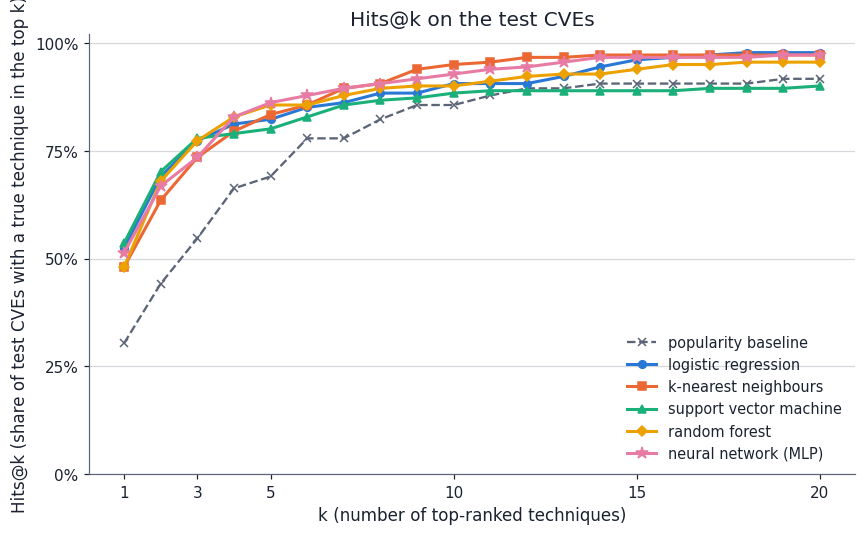


====== Save ======
saved: data/processed/lp_predictions.parquet (201,720 rows: top 20 techniques of the selected model for every CVE) | results/lp_tuning.json | results/lp_test_results.json
total time 293 s

BLOCK 15 DONE


In [2]:
# ============ BLOCK 15 : Link prediction - five models, hyperparameter tuning, final test results ============
# Needs Block 1 and Block 14 (files lp_features.npz, lp_labels.parquet on Drive). CPU is enough; a GPU makes the neural network a little faster.
# First run: about 6-12 min (the tuning result is cached on Drive, so a rerun takes about 2-4 min). It does NOT need the language model.
import re, warnings, itertools, copy, hashlib, textwrap
warnings.filterwarnings('ignore')
import torch, torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import roc_auc_score, average_precision_score

PROC = DIRS['proc']; T0 = time.time(); FORCE_RETUNE = False        # True = ignore the cached tuning result and search again
INK, INK2, NAVY = '#1B2330', '#5B6577', '#1F3A5F'
COLORS = {'popularity': INK2, 'LR': '#2a78d6', 'kNN': '#eb6834', 'SVM': '#1baf7a', 'RF': '#eda100', 'MLP': '#e87ba4'}     # fixed colour per model in every figure
MARK = {'popularity': 'x', 'LR': 'o', 'kNN': 's', 'SVM': '^', 'RF': 'D', 'MLP': '*'}
KS = (1, 3, 5, 10, 20); SELECT = 'ndcg@10'; N_BOOT = 2000
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
def section(t): print('\n' + '=' * 6, t, '=' * 6)
def style(ax, grid='y'):
    ax.set_facecolor('white'); ax.set_axisbelow(True)
    ax.grid(axis=grid, alpha=0.25, color=INK2); ax.grid(axis='x' if grid == 'y' else 'y', visible=False)
    for s_ in ('top', 'right'): ax.spines[s_].set_visible(False)
    for s_ in ('left', 'bottom'): ax.spines[s_].set_color(INK2)
    ax.tick_params(colors=INK, labelsize=10); ax.xaxis.label.set_color(INK); ax.yaxis.label.set_color(INK); ax.title.set_color(INK)

def save_table_wrapped(df, name, caption, wrap):
    """table image with line-wrapped cells (wrap = max characters per line for every column)"""
    cols = list(df.columns); w = np.array([wrap[c] for c in cols], float) + 2; fr = w / w.sum()
    cells = [[textwrap.fill(str(v), wrap[c]) for c, v in zip(cols, r)] for r in df.values]; heads = [textwrap.fill(c, wrap[c]) for c in cols]
    nl = lambda t: t.count('\n') + 1; hh = max(nl(h) for h in heads); rh = [max(nl(t) for t in r) for r in cells]; unit, pad = 0.17, 0.16
    total = (hh + sum(rh)) * unit + pad * (len(rh) + 1); fig = plt.figure(figsize=(11.5, total)); ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 1); ax.set_ylim(0, total); ax.axis('off'); y = total
    def row(texts, height, face, bold, color):
        nonlocal y
        x = 0
        for t, f in zip(texts, fr):
            ax.add_patch(plt.Rectangle((x, y - height), f, height, facecolor=face, edgecolor='#C8CFDA', lw=0.8)); ax.text(x + f / 2, y - height / 2, t, ha='center', va='center', fontsize=8.5, color=color, weight='bold' if bold else 'normal', linespacing=1.25); x += f
        y -= height
    row(heads, hh * unit + pad, '#1F3A5F', True, 'white')
    for i, (r, n) in enumerate(zip(cells, rh)): row(r, n * unit + pad, '#F2F5FA' if i % 2 else 'white', False, INK)
    df.to_csv(DIRS['tables'] / f'{name}.csv', index=False); path = DIRS['tables'] / f'{name}.png'; fig.savefig(path, dpi=300, bbox_inches='tight', facecolor='white'); _register('tables', name, caption)
    print(f'[table saved]  {path.name}  (+ .csv)'); plt.show()

# ------------------------------------------------------------------------------------------------------------
# PART 1 : data, label matrices and the ranking metrics
# ------------------------------------------------------------------------------------------------------------
section('Data')
Z = np.load(PROC / 'lp_features.npz'); GN = _load(PROC / 'lp_feature_names.json'); LAB = _load(PROC / 'lp_labels.parquet')
ids = Z['cve_ids'].astype(str); SP = Z['split'].astype(str); G = ['TEXT', 'CWE', 'CVSS', 'VENDOR', 'META']; XG = {g: Z['X_' + g.lower()].astype(np.float32) for g in G}
assert all(XG[g].shape[1] == len(GN[g]) for g in G), 'feature names do not match the matrices'
true_sets = LAB.groupby('cve_id').technique_id.apply(set).to_dict()
rows_of = lambda *s: np.where(np.isin(SP, s))[0]
TR, VA, TE = rows_of('train'), rows_of('val'), rows_of('test'); TRVA = np.concatenate([TR, VA]); NALL = len(ids)
try:
    TNAME = _load(PROC / 'attack_techniques.parquet').set_index('technique_id').name.to_dict()
except Exception: TNAME = {}
label_space = lambda rows: sorted({t for r in rows for t in true_sets[ids[r]]})
def Ymat(rows, L):
    li = {t: j for j, t in enumerate(L)}; Y = np.zeros((len(rows), len(L)), np.float32)
    for i, r in enumerate(rows):
        for t in true_sets[ids[r]]:
            if t in li: Y[i, li[t]] = 1
    return Y
L_TR, L_TRVA = label_space(TR), label_space(TRVA)
print(f'CVEs: train {len(TR)} / val {len(VA)} / test {len(TE)} | techniques to rank: {len(L_TR)} (training) and {len(L_TRVA)} (training + validation) | feature columns: {sum(XG[g].shape[1] for g in G)}')

IDCG = {k: np.cumsum(1 / np.log2(np.arange(k) + 2)) for k in KS}
def per_cve(S, rows, L):
    """ranking metrics for every CVE. S: scores (CVEs x techniques of L). True techniques that are not in L can never be found; they count as misses."""
    n, nl = S.shape; li = {t: j for j, t in enumerate(L)}
    order = np.argsort(-S, axis=1, kind='stable'); rank = np.empty_like(order); rank[np.arange(n)[:, None], order] = np.arange(nl)[None, :]
    Y = np.zeros((n, nl), bool); n_all = np.zeros(n)
    for i, r in enumerate(rows):
        T = true_sets[ids[r]]; n_all[i] = len(T)
        for t in T:
            if t in li: Y[i, li[t]] = True
    first = np.where(Y, rank, nl + 5).min(1) + 1
    o = {'mrr': np.where(first <= nl, 1.0 / first, 0.0)}
    for k in KS: o[f'hits@{k}'] = (first <= k).astype(float)
    for k in (1, 3, 5, 10, 20):
        tp = (Y & (rank < k)).sum(1); o[f'p@{k}'] = tp / k; o[f'r@{k}'] = tp / n_all; o[f'tp@{k}'] = tp
    disc = 1 / np.log2(rank + 2.0)
    for k in (5, 10, 20):
        dcg = (disc * (Y & (rank < k))).sum(1); ide = np.cumsum(1 / np.log2(np.arange(k) + 2)); o[f'ndcg@{k}'] = dcg / ide[np.minimum(n_all, k).astype(int) - 1]
    ap = np.zeros(n)
    for i in range(n):
        rk = np.sort(rank[i][Y[i]]) + 1; ap[i] = (np.arange(1, len(rk) + 1) / rk).sum() / n_all[i] if len(rk) else 0.0
    o['ap'] = ap; o['n_all'] = n_all; o['n_reach'] = Y.sum(1); o['_Y'] = Y; o['_rank'] = rank; o['_first'] = first
    return o
def summarize(S, rows, L):
    o = per_cve(S, rows, L); Y = o['_Y']; s = {k: float(np.mean(v)) for k, v in o.items() if not k.startswith('_') and k not in ('n_all', 'n_reach') and not k.startswith('tp@')}
    tp3 = o['tp@3'].sum(); s['micro_p@3'] = tp3 / (3 * len(S)); s['micro_r@3'] = tp3 / o['n_all'].sum(); s['micro_f1@3'] = 2 * s['micro_p@3'] * s['micro_r@3'] / max(s['micro_p@3'] + s['micro_r@3'], 1e-12)
    yv, sv = Y.ravel().astype(int), S.ravel()
    s['roc_auc_micro'] = float(roc_auc_score(yv, sv)) if 0 < yv.sum() < len(yv) else float('nan'); s['pr_auc_micro'] = float(average_precision_score(yv, sv)) if yv.sum() else float('nan')
    ok = [j for j in range(Y.shape[1]) if 0 < Y[:, j].sum() < len(Y)]; s['roc_auc_macro'] = float(np.mean([roc_auc_score(Y[:, j], S[:, j]) for j in ok])) if ok else float('nan')
    s['unreachable_share'] = float(1 - o['n_reach'].sum() / o['n_all'].sum())
    return s, o
# self-test of the metric code: perfect scores must give perfect metrics; random scores must give low ones
_rows = TR[:60]; _Y = Ymat(_rows, L_TR); _s, _o = summarize(_Y + 1e-3 * np.random.default_rng(0).random(_Y.shape), _rows, L_TR); _r, _ = summarize(np.random.default_rng(1).random(_Y.shape), _rows, L_TR)
assert _s['mrr'] > 0.99 and _s['ndcg@10'] > 0.99 and _s['hits@1'] > 0.99 and _r['ndcg@10'] < 0.3, 'metric self-test failed'
print(f'[PASS] metric self-test: perfect scores -> NDCG@10 {_s["ndcg@10"]:.2f}, random scores -> {_r["ndcg@10"]:.2f}')

# ------------------------------------------------------------------------------------------------------------
# PART 2 : feature preparation (every group gets the same total weight; statistics are fitted on the fitting rows only)
# ------------------------------------------------------------------------------------------------------------
class Prep:
    def __init__(self, fit_rows, gw=None):
        self.gw = {g: 1.0 for g in G}; self.gw.update(gw or {}); self.st = {}
        for g in G:
            A = XG[g][fit_rows].astype(np.float64); mu = A.mean(0) if g in ('TEXT', 'META') else 0; sd = A.std(0) + 1e-6 if g == 'META' else 1
            B = self._base(g, A, mu, sd); self.st[g] = (mu, sd, float(np.sqrt(max((B ** 2).sum(1).mean(), 1e-12))))
    def _base(self, g, A, mu, sd):
        B = (A - mu) / sd
        if g == 'CVSS': B = B.copy(); B[:, GN['CVSS'].index('base_score')] /= 10.0
        return B
    def transform(self, rows):
        out = [self._base(g, XG[g][rows].astype(np.float64), *self.st[g][:2]) / self.st[g][2] * self.gw[g] for g in G if self.gw[g] > 0]
        return np.hstack(out).astype(np.float32)
_PC = {}
def prep_for(fit_rows, gw=None, key=None):
    k = (key, tuple(sorted((gw or {}).items())))
    if k not in _PC: _PC[k] = Prep(fit_rows, gw)
    return _PC[k]

# ------------------------------------------------------------------------------------------------------------
# PART 3 : the models.  Each fit_predict(cfg, Xtr, Ytr, Xte) returns (scores, info): one score per technique for every row of Xte.
# ------------------------------------------------------------------------------------------------------------
def popularity_scores(Ytr, n): return np.tile(Ytr.mean(0), (n, 1)).astype(np.float32)
def fp_lr(cfg, Xtr, Ytr, Xte, **kw):
    S = np.full((len(Xte), Ytr.shape[1]), -50.0, np.float32)
    for j in range(Ytr.shape[1]):
        y = Ytr[:, j]
        if y.sum() == 0 or y.sum() == len(y): continue
        S[:, j] = LogisticRegression(C=cfg['C'], max_iter=300).fit(Xtr, y).decision_function(Xte)
    return S, {}
def fp_svm(cfg, Xtr, Ytr, Xte, **kw):
    S = np.full((len(Xte), Ytr.shape[1]), -50.0, np.float32)
    for j in range(Ytr.shape[1]):
        y = Ytr[:, j]
        if y.sum() == 0 or y.sum() == len(y): continue
        S[:, j] = SVC(kernel=cfg['kernel'], C=cfg['C'], gamma='scale').fit(Xtr, y).decision_function(Xte)
    return S, {}
def fp_knn(cfg, Xtr, Ytr, Xte, **kw):
    A = Xte / (np.linalg.norm(Xte, axis=1, keepdims=True) + 1e-9); B = Xtr / (np.linalg.norm(Xtr, axis=1, keepdims=True) + 1e-9); sim = A @ B.T
    k = min(cfg['k'], len(B)); nb = np.argpartition(-sim, k - 1, axis=1)[:, :k]; w = np.clip(np.take_along_axis(sim, nb, 1), 0, None) ** cfg['p']
    S = np.stack([w[i] @ Ytr[nb[i]] for i in range(len(A))]).astype(np.float32)
    return S + 1e-6 * Ytr.mean(0), {}
def fp_rf(cfg, Xtr, Ytr, Xte, **kw):
    rf = RandomForestRegressor(n_estimators=cfg.get('trees', 150), max_depth=cfg['depth'], min_samples_leaf=cfg['leaf'], max_features=cfg['mf'], n_jobs=-1, random_state=SEED).fit(Xtr, Ytr)
    S = rf.predict(Xte).astype(np.float32); del rf
    return S + 1e-6 * Ytr.mean(0), {}
def build_mlp(d_in, hidden, p, n_out):
    layers, d = [], d_in
    for h in hidden: layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(p)]; d = h
    return nn.Sequential(*layers, nn.Linear(d, n_out))
def fp_mlp(cfg, Xtr, Ytr, Xte, monitor=None, epochs=None, max_epochs=200, patience=10, history=None, **kw):
    """monitor(scores) -> validation score (tuning: early stopping picks the epoch). epochs=n: train exactly n epochs without validation (final fit)."""
    torch.manual_seed(SEED); np.random.seed(SEED)
    net = build_mlp(Xtr.shape[1], cfg['hidden'], cfg['dropout'], Ytr.shape[1]).to(dev); opt = torch.optim.Adam(net.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    Xt, Yt = torch.tensor(Xtr, device=dev), torch.tensor(Ytr, device=dev); Xe = torch.tensor(Xte, device=dev); Tn = Yt / Yt.sum(1, keepdim=True).clamp(min=1)
    bce = nn.BCEWithLogitsLoss(); n = len(Xt); best, best_ep, best_state, bad = -1.0, 0, None, 0; total = epochs or max_epochs
    def predict():
        net.eval()
        with torch.no_grad(): return net(Xe).cpu().numpy()
    for ep in range(1, total + 1):
        net.train(); perm = torch.randperm(n, device=dev); tot = 0.0
        for i in range(0, n, 64):
            b = perm[i:i + 64]; out = net(Xt[b])
            loss = bce(out, Yt[b]) if cfg['loss'] == 'bce' else -(Tn[b] * torch.log_softmax(out, 1)).sum(1).mean()
            opt.zero_grad(); loss.backward(); opt.step(); tot += float(loss) * len(b)
        if monitor is not None and (ep % 5 == 0 or history is not None):
            v = monitor(predict())
            if history is not None: history.append((ep, tot / n, v))
            if v > best + 1e-9: best, best_ep, bad = v, ep, 0; best_state = copy.deepcopy(net.state_dict())
            elif ep % 5 == 0:
                bad += 1
                if bad >= patience and history is None: break
    if monitor is not None and best_state is not None: net.load_state_dict(best_state)
    S = predict().astype(np.float32); n_par = int(sum(p.numel() for p in net.parameters() if p.requires_grad))
    return S, {'best_epoch': best_ep if monitor is not None else epochs, 'params': n_par}
FIT = {'LR': fp_lr, 'kNN': fp_knn, 'SVM': fp_svm, 'RF': fp_rf, 'MLP': fp_mlp}

rng_s = np.random.default_rng(SEED)
GRID = {'LR': [{'C': c} for c in (0.3, 1, 3, 10, 30, 100)],
        'kNN': [{'k': k, 'p': p, 'wt': wt} for k in (5, 10, 20, 40) for p in (1, 3, 6) for wt in (1.0, 2.0)],
        'SVM': [{'kernel': 'linear', 'C': c} for c in (0.01, 0.1, 1)] + [{'kernel': 'rbf', 'C': c} for c in (1, 10, 100)],
        'RF': [{'depth': d, 'leaf': l, 'mf': m} for d in (12, None) for l in (1, 3) for m in ('sqrt', 0.1)]}
mlp_all = [{'hidden': h, 'dropout': dr, 'lr': lr, 'wd': wd, 'loss': ls} for h in ((256,), (512, 256)) for dr in (0.3, 0.5) for lr in (1e-3, 3e-3) for wd in (1e-4, 1e-3) for ls in ('bce', 'softmax')]
GRID['MLP'] = [mlp_all[i] for i in sorted(rng_s.choice(len(mlp_all), 16, replace=False))]             # random search: 16 of the 32 combinations
DEFAULT = {'LR': {'C': 1}, 'kNN': {'k': 10, 'p': 1, 'wt': 1.0}, 'SVM': {'kernel': 'rbf', 'C': 1}, 'RF': {'depth': None, 'leaf': 1, 'mf': 'sqrt'}, 'MLP': {'hidden': (256,), 'dropout': 0.3, 'lr': 1e-3, 'wd': 1e-4, 'loss': 'bce'}}
for m in DEFAULT:
    if DEFAULT[m] not in GRID[m]: GRID[m].insert(0, DEFAULT[m])
SPACE = {'LR': 'C: 0.3, 1, 3, 10, 30, 100', 'kNN': 'k: 5, 10, 20, 40; similarity power: 1, 3, 6; text weight: 1, 2', 'SVM': 'linear: C 0.01, 0.1, 1; RBF: C 1, 10, 100',
         'RF': 'depth: 12 or none; min leaf: 1 or 3; features per split: sqrt or 10%; 150 trees', 'MLP': 'hidden: 256 or 512-256; dropout: 0.3 or 0.5; learning rate: 0.001 or 0.003; weight decay: 0.0001 or 0.001; loss: BCE or softmax'}
METHOD = {'LR': 'grid, 6 settings', 'kNN': 'grid, 24 settings', 'SVM': 'grid, 6 settings', 'RF': 'grid, 8 settings', 'MLP': 'random search, 16 of 32 settings'}
PRETTY = {'C': 'C', 'k': 'k', 'p': 'similarity power', 'wt': 'text weight', 'kernel': 'kernel', 'depth': 'depth', 'leaf': 'min leaf', 'mf': 'features per split', 'hidden': 'hidden', 'dropout': 'dropout', 'lr': 'learning rate', 'wd': 'weight decay', 'loss': 'loss'}

# ------------------------------------------------------------------------------------------------------------
# PART 4 : hyperparameter tuning on the validation CVEs (the test CVEs are not touched here)
# ------------------------------------------------------------------------------------------------------------
section('Hyperparameter tuning (selection metric: NDCG@10 on the validation CVEs)')
def run_cfg(model, cfg, fit_rows, eval_rows, L, key, monitor=None, epochs=None, history=None):
    P = prep_for(fit_rows, {'TEXT': cfg.get('wt', 1.0)}, key); Xtr, Xev = P.transform(fit_rows), P.transform(eval_rows); Ytr = Ymat(fit_rows, L)
    return FIT[model](cfg, Xtr, Ytr, Xev, monitor=monitor, epochs=epochs, history=history)
val_metric = lambda S: float(per_cve(S, VA, L_TR)[SELECT].mean())
TUNE_PATH = DIRS['results'] / 'lp_tuning.json'; sig = hashlib.md5((str(len(TR)) + str(len(VA)) + str(GRID) + str(SEED)).encode()).hexdigest()[:10]
TUNE = _load(TUNE_PATH) if TUNE_PATH.exists() and not FORCE_RETUNE else None
if TUNE and TUNE.get('sig') == sig: print('[cache hit]  tuning result from Drive (set FORCE_RETUNE = True to search again)')
else:
    TUNE = {'sig': sig, 'models': {}}
    for m in ('LR', 'kNN', 'SVM', 'RF', 'MLP'):
        t1 = time.time(); res = []
        for cfg in GRID[m]:
            S, info = run_cfg(m, cfg, TR, VA, L_TR, 'tr', monitor=val_metric if m == 'MLP' else None)
            res.append({'cfg': {k: (list(v) if isinstance(v, tuple) else v) for k, v in cfg.items()}, 'val': val_metric(S), **{k: v for k, v in info.items() if k == 'best_epoch'}})
        TUNE['models'][m] = res; print(f'  {m:4s}: {len(res)} settings in {time.time() - t1:.0f} s | best validation NDCG@10 {max(r["val"] for r in res):.3f}')
    _save(TUNE, TUNE_PATH)
def as_cfg(c): return {k: (tuple(v) if isinstance(v, list) else v) for k, v in c.items()}
BEST, BEST_EP, ROWS_T = {}, {}, []
for m in ('LR', 'kNN', 'SVM', 'RF', 'MLP'):
    res = TUNE['models'][m]; b = max(res, key=lambda r: r['val']); BEST[m] = as_cfg(b['cfg']); BEST_EP[m] = b.get('best_epoch')
    d = next(r for r in res if as_cfg(r['cfg']) == DEFAULT[m]); ROWS_T.append({'Model': m, 'Search method': METHOD[m], 'Search space': SPACE[m], 'Val. NDCG@10 (default)': f'{d["val"]:.3f}',
        'Best setting': '; '.join(f'{PRETTY[k]} {v}' for k, v in BEST[m].items()) + (f'; {BEST_EP[m]} epochs' if m == 'MLP' else ''), 'Val. NDCG@10 (tuned)': f'{b["val"]:.3f}'})
TT = pd.DataFrame(ROWS_T); print(TT[['Model', 'Val. NDCG@10 (default)', 'Best setting', 'Val. NDCG@10 (tuned)']].to_string(index=False))
save_table_wrapped(TT, 'table_lp_tuning', 'Hyperparameter search space, best setting and validation score of every model', {'Model': 6, 'Search method': 14, 'Search space': 34, 'Val. NDCG@10 (default)': 11, 'Best setting': 32, 'Val. NDCG@10 (tuned)': 11})

fig, ax = plt.subplots(figsize=(8.2, 4.8)); rg = np.random.default_rng(3)
for i, m in enumerate(('LR', 'kNN', 'SVM', 'RF', 'MLP')):
    v = np.array([r['val'] for r in TUNE['models'][m]]); ax.scatter(i + rg.uniform(-0.18, 0.18, len(v)), v, s=26, color=COLORS[m], alpha=0.65, linewidths=0)
    j = int(np.argmax(v)); ax.scatter(i, v[j], s=150, color=COLORS[m], marker='*', edgecolor=INK, linewidths=0.8, zorder=5)
    ax.text(i, v[j] + 0.012, f'{v[j]:.3f}', ha='center', fontsize=9.5, color=INK)
ax.set_xticks(range(5)); ax.set_xticklabels(['LR', 'kNN', 'SVM', 'RF', 'MLP']); ax.set_ylabel('Validation NDCG@10'); ax.set_xlabel('Model (each dot is one hyperparameter setting, star = selected)')
ax.set_title('Hyperparameter search on the validation CVEs'); style(ax); lo = min(r['val'] for m in TUNE['models'] for r in TUNE['models'][m]); hi = max(r['val'] for m in TUNE['models'] for r in TUNE['models'][m]); ax.set_ylim(max(0, lo - 0.05), hi + 0.06)
fig.tight_layout(); save_fig(fig, 'fig_lp_tuning', 'Validation NDCG@10 of every tried hyperparameter setting; the selected setting of each model is marked with a star')

# ---- training curve of the selected neural network ----
hist = []; _ = run_cfg('MLP', BEST['MLP'], TR, VA, L_TR, 'tr', monitor=val_metric, history=hist, epochs=None)
H = pd.DataFrame(hist, columns=['epoch', 'train_loss', 'val']); be = int(H.val.idxmax()); net_params = _[1]['params']
fig, axs = plt.subplots(1, 2, figsize=(10, 4)); axs[0].plot(H.epoch, H.train_loss, color=COLORS['MLP'], lw=2); axs[0].set_xlabel('Epoch'); axs[0].set_ylabel('Training loss'); axs[0].set_title('Training loss')
axs[1].plot(H.epoch, H.val, color=COLORS['MLP'], lw=2); axs[1].axvline(H.epoch[be], color=INK2, ls='--', lw=1); axs[1].text(H.epoch[be], H.val.min() + 0.01, f' best epoch {int(H.epoch[be])}', color=INK, fontsize=9.5)
axs[1].set_xlabel('Epoch'); axs[1].set_ylabel('Validation NDCG@10'); axs[1].set_title('Validation score')
for a in axs: style(a)
fig.tight_layout(); save_fig(fig, 'fig_lp_mlp_training', 'Neural network (selected setting): training loss and validation NDCG@10 by epoch')
BEST_EP['MLP'] = int(H.epoch[be]) if BEST_EP.get('MLP') is None else BEST_EP['MLP']
print(f'MLP: {BEST["MLP"]["hidden"]} hidden units | trainable parameters {net_params:,} | best epoch {BEST_EP["MLP"]}')

# ------------------------------------------------------------------------------------------------------------
# PART 5 : final models (fitted on training + validation CVEs) and ONE evaluation on the test CVEs
# ------------------------------------------------------------------------------------------------------------
section('Final models: fitted on training + validation CVEs, evaluated once on the test CVEs')
ALL = np.arange(NALL); SC_ALL, TEST_S, TEST_O, TEST_M = {}, {}, {}, {}
Ytv = Ymat(TRVA, L_TRVA); SC_ALL['popularity'] = popularity_scores(Ytv, NALL)
for m in ('LR', 'kNN', 'SVM', 'RF', 'MLP'):
    t1 = time.time(); S, info = run_cfg(m, BEST[m], TRVA, ALL, L_TRVA, 'trva', epochs=BEST_EP[m] if m == 'MLP' else None); SC_ALL[m] = S; print(f'  {m:4s} fitted and applied to all {NALL:,} CVEs in {time.time() - t1:.0f} s')
for m, S in SC_ALL.items(): TEST_S[m] = S[TE]; TEST_M[m], TEST_O[m] = summarize(S[TE], TE, L_TRVA)
rng_b = np.random.default_rng(SEED); BI = rng_b.integers(0, len(TE), (N_BOOT, len(TE)))
def ci(v): b = v[BI].mean(1); return float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))
MODELS = ['popularity', 'LR', 'kNN', 'SVM', 'RF', 'MLP']; LABEL = {'popularity': 'popularity baseline', 'LR': 'logistic regression', 'kNN': 'k-nearest neighbours', 'SVM': 'support vector machine', 'RF': 'random forest', 'MLP': 'neural network (MLP)'}
rk = []
for m in MODELS:
    s, o = TEST_M[m], TEST_O[m]; a, b = ci(o['ndcg@10']), ci(o['mrr'])
    rk.append({'Model': LABEL[m], 'Hits@1': f'{s["hits@1"]:.3f}', 'Hits@3': f'{s["hits@3"]:.3f}', 'Hits@5': f'{s["hits@5"]:.3f}', 'Hits@10': f'{s["hits@10"]:.3f}', 'MRR [95% CI]': f'{s["mrr"]:.3f} [{b[0]:.2f}, {b[1]:.2f}]',
               'NDCG@10 [95% CI]': f'{s["ndcg@10"]:.3f} [{a[0]:.2f}, {a[1]:.2f}]', 'MAP': f'{s["ap"]:.3f}'})
RK = pd.DataFrame(rk); print('ranking metrics on the test CVEs:'); print(RK.to_string(index=False)); save_table(RK, 'table_lp_ranking', 'Ranking metrics of all models on the test CVEs')
cl = [{'Model': LABEL[m], 'Precision@3': f'{TEST_M[m]["micro_p@3"]:.3f}', 'Recall@3': f'{TEST_M[m]["micro_r@3"]:.3f}', 'F1@3': f'{TEST_M[m]["micro_f1@3"]:.3f}', 'ROC-AUC (micro)': f'{TEST_M[m]["roc_auc_micro"]:.3f}',
       'ROC-AUC (macro)': f'{TEST_M[m]["roc_auc_macro"]:.3f}', 'PR-AUC (micro)': f'{TEST_M[m]["pr_auc_micro"]:.3f}'} for m in MODELS]
CL = pd.DataFrame(cl); print('\nclassification-style metrics on the test CVEs (top-3 predicted techniques per CVE):'); print(CL.to_string(index=False)); save_table(CL, 'table_lp_classification', 'Precision, recall, F1 (top-3 techniques per CVE) and AUC values on the test CVEs')
print(f'\nshare of true test links whose technique has no training or validation CVE (cannot be found by any model): {100 * TEST_M["LR"]["unreachable_share"]:.1f}%')

SEL = max(('LR', 'kNN', 'SVM', 'RF', 'MLP'), key=lambda m: max(r['val'] for r in TUNE['models'][m])); order_ = sorted(('LR', 'kNN', 'SVM', 'RF', 'MLP'), key=lambda m: -TEST_M[m]['ndcg@10'])
print(f'model selected on the VALIDATION CVEs: {SEL} | best on the test CVEs: {order_[0]}')
def paired(a, b, key='ndcg@10'):
    d = TEST_O[a][key] - TEST_O[b][key]; lo, hi = np.percentile(d[BI].mean(1), [2.5, 97.5]); return d.mean(), lo, hi, int((d > 0).sum()), int((d < 0).sum())
for a, b in ((SEL, 'popularity'), (SEL, [m for m in order_ if m != SEL][0])):
    d, lo, hi, w, l = paired(a, b); print(f'  NDCG@10 {a} - {b}: {d:+.3f} [{lo:+.3f}, {hi:+.3f}] | better on {w} CVEs, worse on {l}')

# Hits@k curves (all models) ----
ks = np.arange(1, 21); fig, ax = plt.subplots(figsize=(8, 5))
for m in MODELS:
    y = [float(np.mean(TEST_O[m]['_first'] <= k)) for k in ks]
    ax.plot(ks, y, color=COLORS[m], marker=MARK[m], ms=5 if m != 'MLP' else 8, lw=2 if m != 'popularity' else 1.5, ls='--' if m == 'popularity' else '-', label=LABEL[m])
ax.set_xlabel('k (number of top-ranked techniques)'); ax.set_ylabel('Hits@k (share of test CVEs with a true technique in the top k)'); ax.set_ylim(0, 1.02); ax.set_xticks([1, 3, 5, 10, 15, 20]); ax.set_title('Hits@k on the test CVEs')
ax.set_yticks([0, .25, .5, .75, 1]); ax.set_yticklabels(['0%', '25%', '50%', '75%', '100%']); style(ax); ax.legend(frameon=False, loc='lower right', labelcolor=INK, fontsize=9.5)
fig.tight_layout(); save_fig(fig, 'fig_lp_hits_at_k', 'Hits@k of the five models and the popularity baseline on the test CVEs')

# ------------------------------------------------------------------------------------------------------------
# PART 6 : predictions of the selected model for ALL CVEs (the unlabelled ones are the new, predicted links) and a results file
# ------------------------------------------------------------------------------------------------------------
section('Save')
S_sel = SC_ALL[SEL]; top = np.argsort(-S_sel, axis=1)[:, :20]; lab_set = set(true_sets)
pr = pd.DataFrame({'cve_id': np.repeat(ids, 20), 'rank': np.tile(np.arange(1, 21), NALL), 'technique_id': np.array(L_TRVA)[top.ravel()], 'score': np.take_along_axis(S_sel, top, 1).ravel().astype(np.float32)})
pr['technique_name'] = pr.technique_id.map(TNAME).fillna(''); pr['has_expert_labels'] = pr.cve_id.isin(lab_set); pr['model'] = SEL
_save(pr, PROC / 'lp_predictions.parquet')
out = {'selected_model': SEL, 'best_on_test': order_[0], 'configs': {m: {k: (list(v) if isinstance(v, tuple) else v) for k, v in BEST[m].items()} for m in BEST}, 'mlp_epochs': BEST_EP['MLP'], 'mlp_params': net_params, 'label_space_trainval': len(L_TRVA),
       'test_metrics': {m: {k: v for k, v in TEST_M[m].items()} for m in MODELS}, 'tuning_val': {m: max(r['val'] for r in TUNE['models'][m]) for m in TUNE['models']}}
_save(out, DIRS['results'] / 'lp_test_results.json')
print(f'saved: data/processed/lp_predictions.parquet ({len(pr):,} rows: top 20 techniques of the selected model for every CVE) | results/lp_tuning.json | results/lp_test_results.json')
print(f'total time {time.time() - T0:.0f} s'); print('\nBLOCK 15 DONE')


====== 1. ROC and precision-recall curves (test CVEs; every pair CVE x technique is one case) ======
181 test CVEs x 186 techniques = 33,666 pairs, of which 411 are true links (1.22%)  (true links to techniques outside the label space are not in this grid)
[figure saved] fig_lp_roc.png


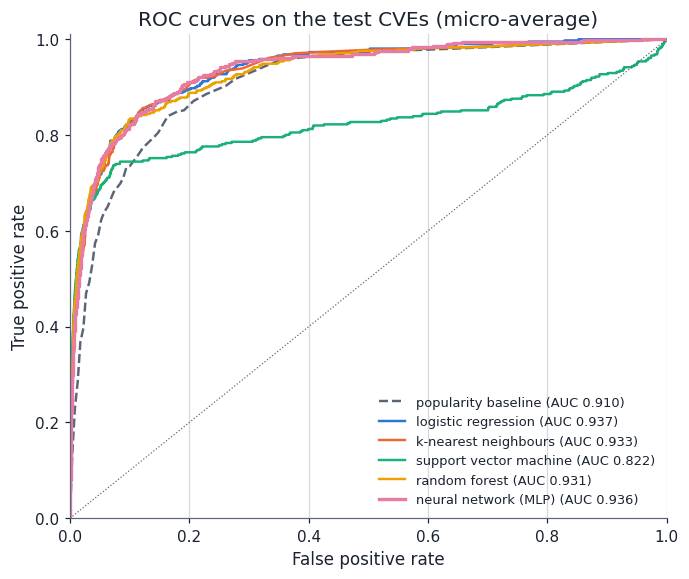

[figure saved] fig_lp_pr.png


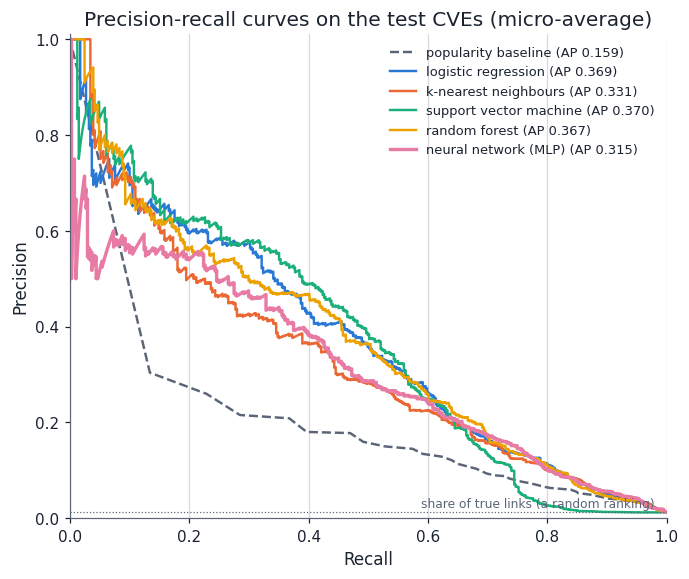


====== 2. Confusion matrix of the top-3 predictions (a technique is "predicted" when it is among the 3 highest scores of a CVE) ======
                 Model  TP  FP  FN     TN Accuracy Precision Recall    F1
   popularity baseline 117 426 300 32,829    0.978     0.215  0.281 0.244
   logistic regression 196 347 221 32,908    0.983     0.361  0.470 0.408
  k-nearest neighbours 191 352 226 32,903    0.983     0.352  0.458 0.398
support vector machine 194 349 223 32,906    0.983     0.357  0.465 0.404
         random forest 192 351 225 32,904    0.983     0.354  0.460 0.400
  neural network (MLP) 181 362 236 32,893    0.982     0.333  0.434 0.377
[table saved]  table_lp_confusion.png  (+ .csv)


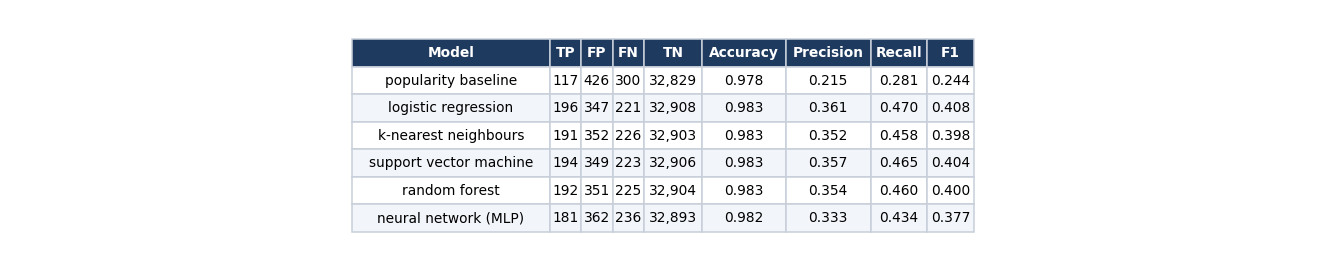

note: accuracy is 0.978 to 0.983 because almost all pairs are true negatives, so accuracy hides the differences; precision, recall and the ranking metrics are the main metrics.
[figure saved] fig_lp_confusion.png


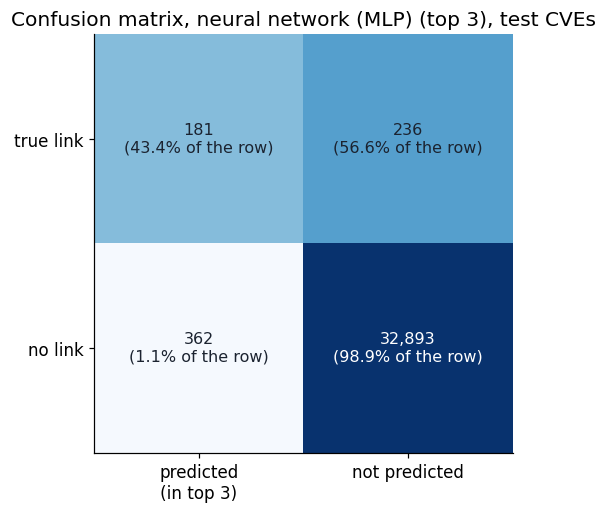


====== 3. Per-technique results of the selected model (MLP), the 10 most frequent techniques of the test CVEs ======
                                   Technique  Test CVEs with it  Flagged in top 3  Correctly flagged Precision Recall
     T1190 Exploit Public-Facing Application                 55               121                 46      0.38   0.84
     T1059 Command and Scripting Interpreter                 39                76                 28      0.37   0.72
 T1068 Exploitation for Privilege Escalation                 34                55                 22      0.40   0.65
                T1005 Data from Local System                 30                19                 13      0.68   0.43
     T1203 Exploitation for Client Execution                 23                71                 15      0.21   0.65
                        T1078 Valid Accounts                 19                25                 11      0.44   0.58
T1499.004 Application or System Exploitation            

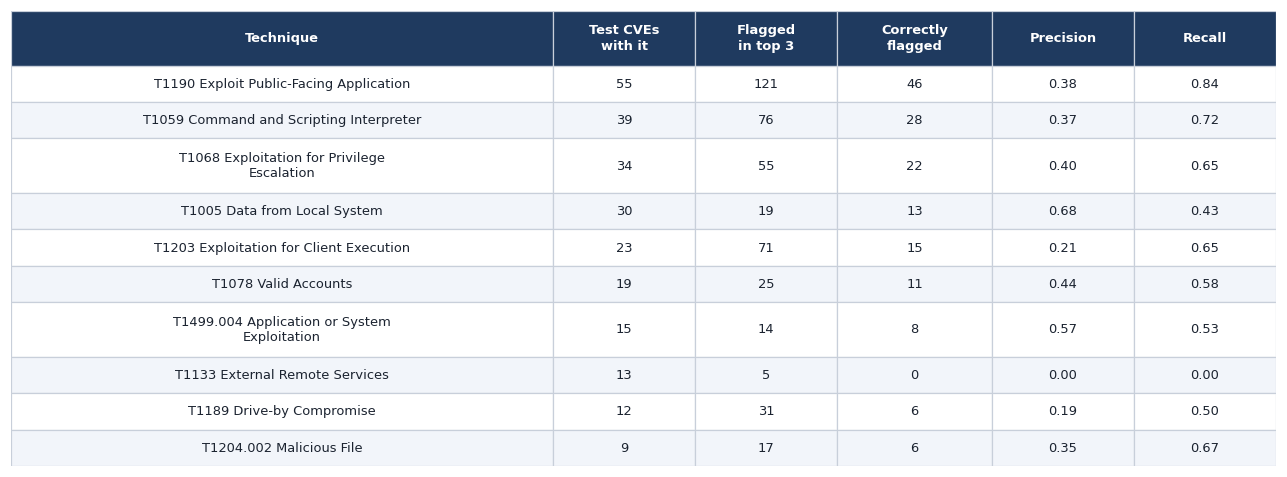


====== 4. Three example test CVEs (chosen by a fixed rule, not by hand) ======
rule: test CVEs in alphabetical order; the FIRST one of each kind is shown. full = every true technique is in the top 3; partial = at least one, but not every, true technique is in the top 3; miss = no true technique in the top 10.
   Case           CVE                                                                                                                                       Description (start)                                                                                                               True techniques (expert mapping)                                                                                                                           Top 3 predicted
   full CVE-2010-0842 Unspecified vulnerability in the Sound component in Oracle Java SE and Java for Business 6 Update 18, 5.0 Update 23, 1.4.2_25, and 1.3.1_27 allows rem...                                                        

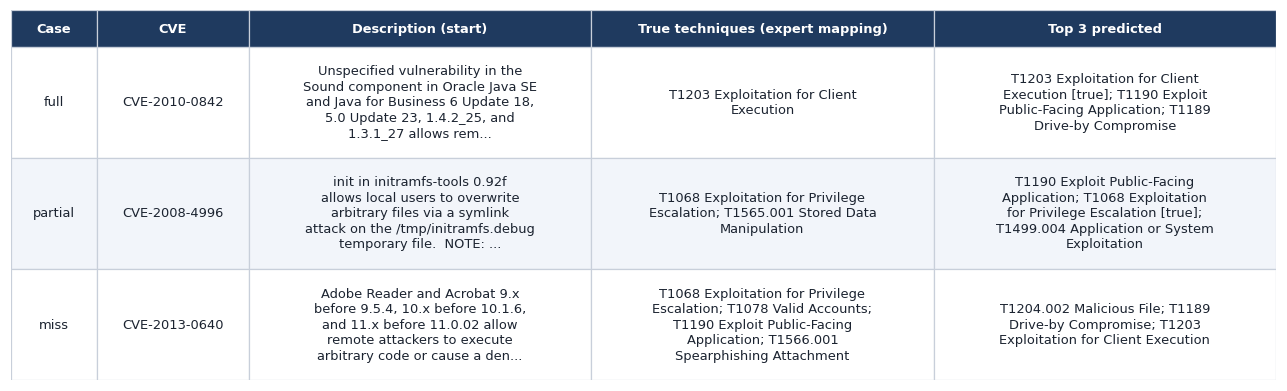


====== 5. Near-duplicates: results by the similarity of the nearest training CVE (description embeddings, test CVEs) ======
nearest training+validation CVE: median cosine 0.84 (training only: 0.84, as in Block 14)
NDCG@10 by similarity group:
Similarity of the nearest training CVE  Test CVEs popularity    LR   kNN   SVM    RF   MLP
                            below 0.80         55      0.406 0.530 0.549 0.549 0.506 0.549
                          0.80 to 0.90         72      0.443 0.578 0.578 0.574 0.552 0.569
                        0.90 or higher         54      0.491 0.687 0.694 0.676 0.732 0.691
[table saved]  table_lp_similarity.png  (+ .csv)


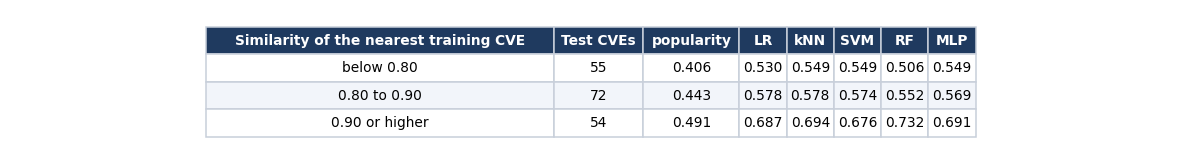

  below 0.80     :  55 CVEs | Hits@3 of the selected model 0.69
  0.80 to 0.90   :  72 CVEs | Hits@3 of the selected model 0.71
  0.90 or higher :  54 CVEs | Hits@3 of the selected model 0.81
[figure saved] fig_lp_similarity.png


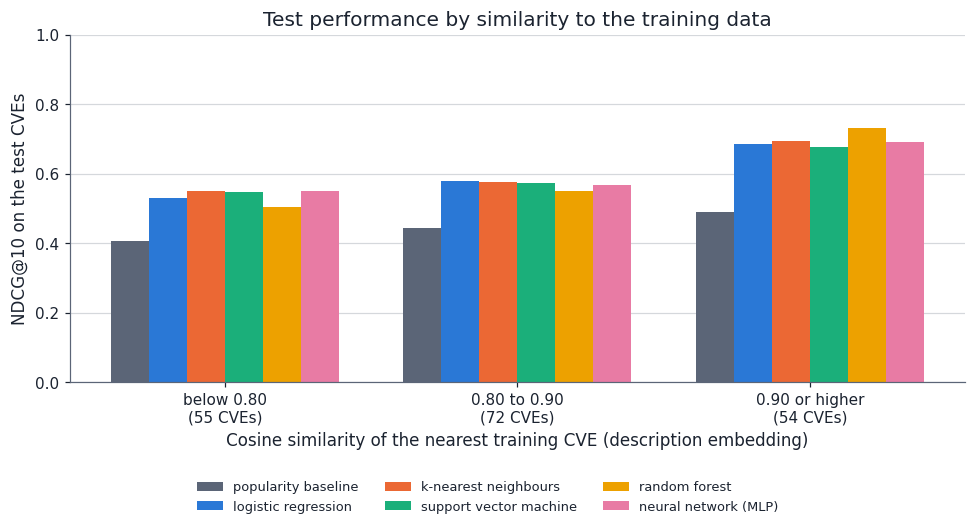


====== 6. Feature-group ablation (VALIDATION CVEs only; kNN and MLP with their tuned settings; MLP: mean and spread over 3 seeds) ======
  all five groups    columns  617 | kNN 0.637 | MLP 0.646 (sd 0.003)
  without TEXT       columns  233 | kNN 0.598 | MLP 0.621 (sd 0.001)
  without CWE        columns  528 | kNN 0.599 | MLP 0.638 (sd 0.002)
  without CVSS       columns  584 | kNN 0.618 | MLP 0.627 (sd 0.005)
  without VENDOR     columns  514 | kNN 0.630 | MLP 0.643 (sd 0.003)
  without META       columns  609 | kNN 0.619 | MLP 0.638 (sd 0.004)
  only TEXT          columns  384 | kNN 0.599 | MLP 0.600 (sd 0.003)
  only CWE           columns   89 | kNN 0.516 | MLP 0.534 (sd 0.004)
  only CVSS          columns   33 | kNN 0.569 | MLP 0.587 (sd 0.003)
  only VENDOR        columns  103 | kNN 0.484 | MLP 0.511 (sd 0.002)
  only META          columns    8 | kNN 0.487 | MLP 0.491 (sd 0.001)
  reference: popularity baseline on the validation CVEs 0.474
[table saved]  table_lp_feature_ablation.

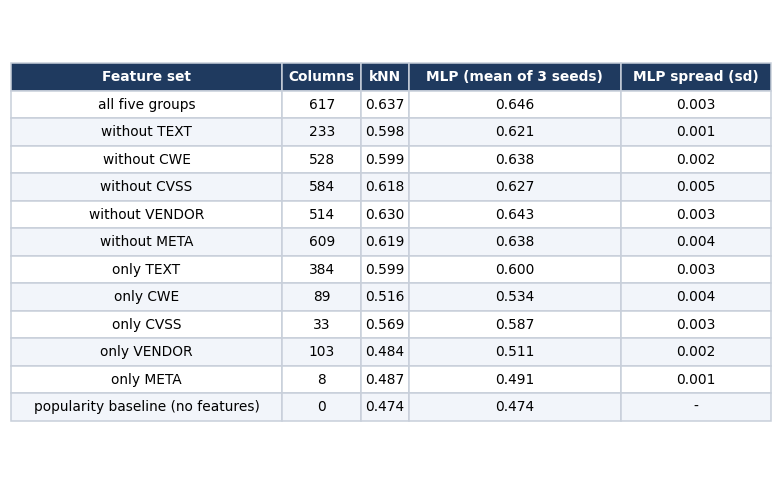

[figure saved] fig_lp_feature_ablation.png


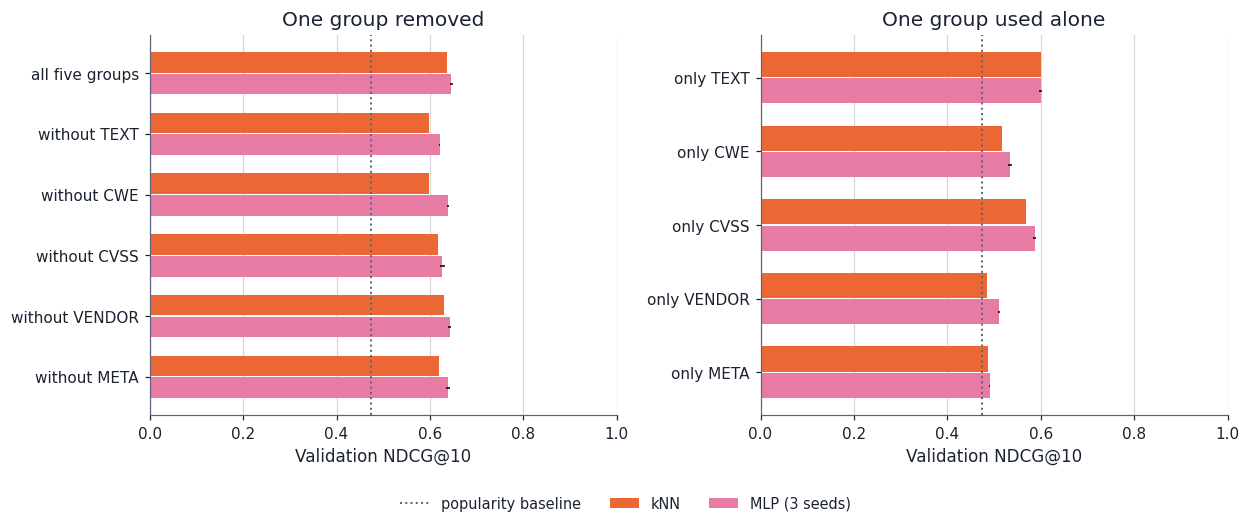


====== 7. Learning curve: validation NDCG@10 against the number of training CVEs (3 random subsets per size; MLP gets the same number of gradient steps as the final model) ======
Share of the training CVEs  Training CVEs  Techniques seen Popularity           kNN           MLP
                       10%             84               59      0.448 0.496 ± 0.020 0.510 ± 0.013
                       25%            211              102      0.469 0.542 ± 0.024 0.556 ± 0.014
                       50%            422              138      0.473 0.600 ± 0.014 0.611 ± 0.012
                       75%            634              160      0.475 0.620 ± 0.015 0.624 ± 0.009
                      100%            845              179      0.474 0.637 ± 0.000 0.646 ± 0.004
[table saved]  table_lp_learning_curve.png  (+ .csv)


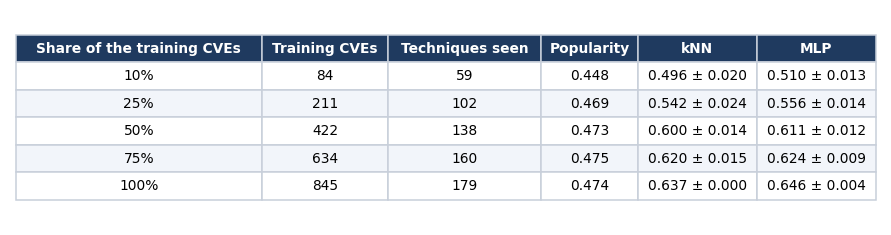

[figure saved] fig_lp_learning_curve.png


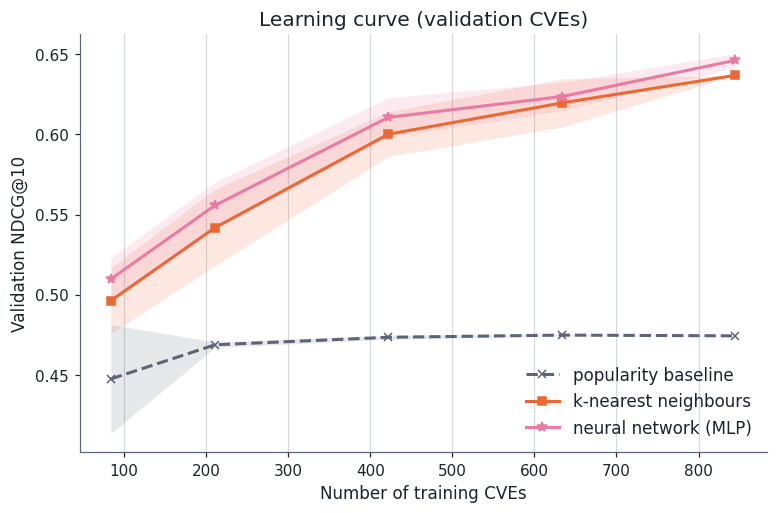


====== 8. Redraw two items from Block 15 (a clipped axis label, and the hidden-layer format in the tuning table) ======
[figure saved] fig_lp_hits_at_k.png


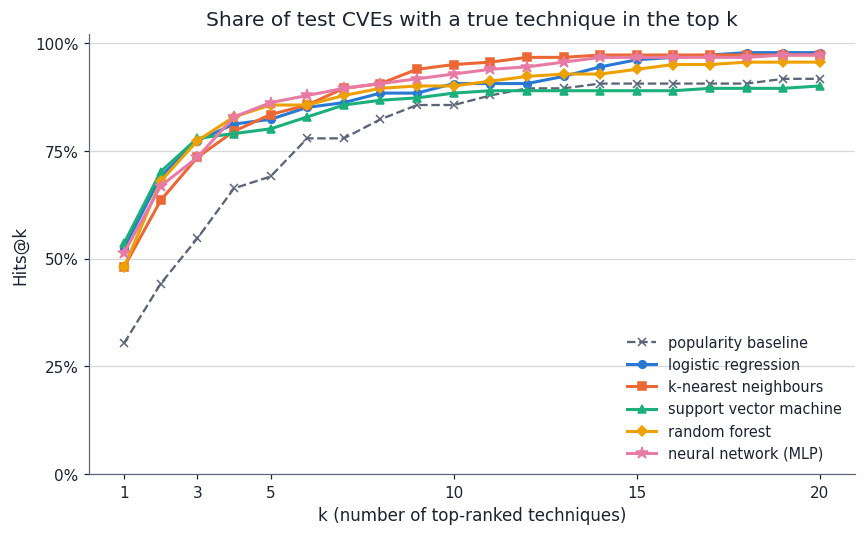

[table saved]  table_lp_tuning.png  (+ .csv)


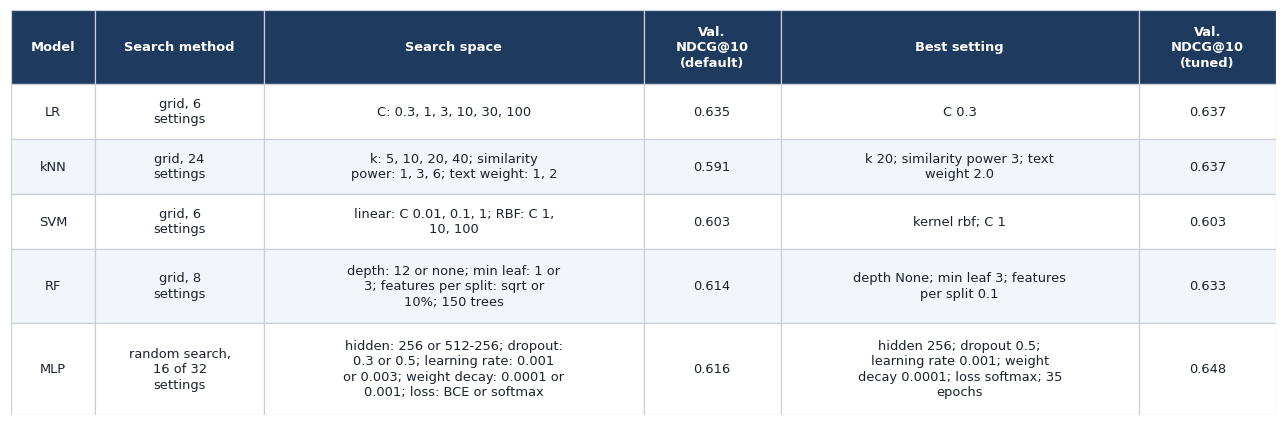


saved: results/lp_extra_results.json | figures: fig_lp_roc, fig_lp_pr, fig_lp_confusion, fig_lp_similarity, fig_lp_feature_ablation, fig_lp_learning_curve, fig_lp_hits_at_k (redrawn)
tables : table_lp_confusion, table_lp_per_technique, table_lp_examples, table_lp_similarity, table_lp_feature_ablation, table_lp_learning_curve, table_lp_tuning (redrawn)
total time 83 s

BLOCK 15b DONE


In [3]:
# ============ BLOCK 15b : Link prediction - extra results (curves, confusion matrix, examples, near-duplicates, feature-group ablation, learning curve) ============
# Needs: Block 1 AND Block 15 run in THIS Colab session (it re-uses their scores, models and helper functions). No language model needed. About 3-6 min on CPU.
# Rules kept: parts 1-4 only REPORT on the test CVEs (nothing is tuned on them); parts 6-7 use the VALIDATION CVEs only, so the test CVEs are not used for any decision.
from sklearn.metrics import roc_curve, precision_recall_curve
need = ['TEST_S', 'TEST_O', 'TEST_M', 'MODELS', 'LABEL', 'SEL', 'BEST', 'BEST_EP', 'FIT', 'prep_for', 'per_cve', 'Ymat', 'label_space', 'XG', 'TR', 'VA', 'TE', 'TRVA',
        'L_TR', 'L_TRVA', 'ids', 'true_sets', 'TNAME', 'G', 'popularity_scores', 'TT', 'save_table_wrapped', 'style', 'COLORS', 'MARK', 'INK', 'INK2']
miss = [v for v in need if v not in globals()]
assert not miss, f'Run Block 15 first in this session (missing: {miss})'
T0_ = time.time(); PROC = DIRS['proc']; EXTRA = {}
def section(t): print('\n' + '=' * 6, t, '=' * 6)
SHORT = {'popularity': 'popularity', 'LR': 'LR', 'kNN': 'kNN', 'SVM': 'SVM', 'RF': 'RF', 'MLP': 'MLP'}

# ---------------------------------------------------------------------------------------------------------
section('1. ROC and precision-recall curves (test CVEs; every pair CVE x technique is one case)')
Ytest = TEST_O[SEL]['_Y'].ravel().astype(int)
print(f'{len(TE)} test CVEs x {len(L_TRVA)} techniques = {Ytest.size:,} pairs, of which {int(Ytest.sum())} are true links ({100 * Ytest.mean():.2f}%)  (true links to techniques outside the label space are not in this grid)')
fig, ax = plt.subplots(figsize=(6.4, 5.4))
for m in MODELS:
    fpr, tpr, _ = roc_curve(Ytest, TEST_S[m].ravel()); ax.plot(fpr, tpr, color=COLORS[m], lw=2.2 if m == 'MLP' else 1.6, ls='--' if m == 'popularity' else '-', label=f'{LABEL[m]} (AUC {TEST_M[m]["roc_auc_micro"]:.3f})')
ax.plot([0, 1], [0, 1], color=INK2, lw=0.8, ls=':'); ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.set_title('ROC curves on the test CVEs (micro-average)'); ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
style(ax, 'both'); ax.legend(frameon=False, loc='lower right', fontsize=8.5, labelcolor=INK); fig.tight_layout()
save_fig(fig, 'fig_lp_roc', 'ROC curves of the five models and the popularity baseline on the test CVEs (micro-average over all CVE-technique pairs)')
fig, ax = plt.subplots(figsize=(6.4, 5.4))
for m in MODELS:
    p_, r_, _ = precision_recall_curve(Ytest, TEST_S[m].ravel()); ax.plot(r_, p_, color=COLORS[m], lw=2.2 if m == 'MLP' else 1.6, ls='--' if m == 'popularity' else '-', label=f'{LABEL[m]} (AP {TEST_M[m]["pr_auc_micro"]:.3f})')
ax.axhline(Ytest.mean(), color=INK2, lw=0.8, ls=':'); ax.text(0.98, Ytest.mean() + 0.01, 'share of true links (a random ranking)', ha='right', fontsize=8, color=INK2)
ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_title('Precision-recall curves on the test CVEs (micro-average)'); ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
style(ax, 'both'); ax.legend(frameon=False, loc='upper right', fontsize=8.5, labelcolor=INK); fig.tight_layout()
save_fig(fig, 'fig_lp_pr', 'Precision-recall curves of the five models and the popularity baseline on the test CVEs (micro-average over all CVE-technique pairs)')

# ---------------------------------------------------------------------------------------------------------
section('2. Confusion matrix of the top-3 predictions (a technique is "predicted" when it is among the 3 highest scores of a CVE)')
def conf3(m):
    o = TEST_O[m]; Y, top = o['_Y'], o['_rank'] < 3; n_unreach = float(o['n_all'].sum() - Y.sum())
    TP, FP = int((Y & top).sum()), int((~Y & top).sum()); FN, TN = int((Y & ~top).sum() + n_unreach), int((~Y & ~top).sum())     # links to techniques that no model can score count as missed
    return TP, FP, FN, TN
rows_c = []
for m in MODELS:
    TP, FP, FN, TN = conf3(m); rows_c.append({'Model': LABEL[m], 'TP': f'{TP:,}', 'FP': f'{FP:,}', 'FN': f'{FN:,}', 'TN': f'{TN:,}', 'Accuracy': f'{(TP + TN) / (TP + FP + FN + TN):.3f}',
                 'Precision': f'{TP / (TP + FP):.3f}', 'Recall': f'{TP / (TP + FN):.3f}', 'F1': f'{2 * TP / (2 * TP + FP + FN):.3f}'})
CM = pd.DataFrame(rows_c); print(CM.to_string(index=False)); save_table(CM, 'table_lp_confusion', 'Confusion counts of the top-3 predictions on the test CVEs (all CVE-technique pairs)')
_acc = [float(a) for a in CM['Accuracy']]; print(f'note: accuracy is {min(_acc):.3f} to {max(_acc):.3f} because almost all pairs are true negatives, so accuracy hides the differences; precision, recall and the ranking metrics are the main metrics.')
TP, FP, FN, TN = conf3(SEL); M2 = np.array([[TP, FN], [FP, TN]]); R2 = M2 / M2.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(5.6, 4.8)); ax.imshow(R2, cmap='Blues', vmin=0, vmax=1)
for i in range(2):
    for j in range(2): ax.text(j, i, f'{M2[i, j]:,}\n({100 * R2[i, j]:.1f}% of the row)', ha='center', va='center', fontsize=10.5, color='white' if R2[i, j] > 0.6 else INK)
ax.set_xticks([0, 1]); ax.set_xticklabels(['predicted\n(in top 3)', 'not predicted']); ax.set_yticks([0, 1]); ax.set_yticklabels(['true link', 'no link']); ax.grid(False)
ax.set_title(f'Confusion matrix, {LABEL[SEL]} (top 3), test CVEs'); fig.tight_layout(); save_fig(fig, 'fig_lp_confusion', f'Confusion matrix of the top-3 predictions of the selected model ({SEL}) on the test CVEs')
EXTRA['confusion_selected'] = {'TP': TP, 'FP': FP, 'FN': FN, 'TN': TN}

# ---------------------------------------------------------------------------------------------------------
section(f'3. Per-technique results of the selected model ({SEL}), the 10 most frequent techniques of the test CVEs')
o = TEST_O[SEL]; Yb, top3 = o['_Y'], o['_rank'] < 3; sup = Yb.sum(0); order = np.argsort(-sup)[:10]; rows_t = []
for j in order:
    tp = int((Yb[:, j] & top3[:, j]).sum()); fl = int(top3[:, j].sum()); nm = TNAME.get(L_TRVA[j], '')
    rows_t.append({'Technique': f'{L_TRVA[j]} {nm}'[:46], 'Test CVEs with it': int(sup[j]), 'Flagged in top 3': fl, 'Correctly flagged': tp, 'Precision': f'{tp / fl:.2f}' if fl else '-', 'Recall': f'{tp / sup[j]:.2f}'})
PT = pd.DataFrame(rows_t); print(PT.to_string(index=False))
save_table_wrapped(PT, 'table_lp_per_technique', 'Per-technique results of the selected model (top-3 rule) for the ten most frequent techniques of the test CVEs', {'Technique': 40, 'Test CVEs with it': 9, 'Flagged in top 3': 9, 'Correctly flagged': 10, 'Precision': 9, 'Recall': 9})

# ---------------------------------------------------------------------------------------------------------
section('4. Three example test CVEs (chosen by a fixed rule, not by hand)')
C_ = _load(PROC / 'cves_enriched.parquet'); DESC = dict(zip(C_.cve_id, C_.description.fillna('')))
print('rule: test CVEs in alphabetical order; the FIRST one of each kind is shown. full = every true technique is in the top 3; partial = at least one, but not every, true technique is in the top 3; miss = no true technique in the top 10.')
rk, Y_all = TEST_O[SEL]['_rank'], TEST_O[SEL]['_Y']; kinds = {'full': None, 'partial': None, 'miss': None}
for i in np.argsort(ids[TE]):
    ntrue = int(Y_all[i].sum()); inb3 = int((Y_all[i] & (rk[i] < 3)).sum()); inb10 = int((Y_all[i] & (rk[i] < 10)).sum())
    kind = 'full' if ntrue and inb3 == ntrue else 'partial' if inb3 > 0 else 'miss' if inb10 == 0 and ntrue else None
    if kind and kinds[kind] is None: kinds[kind] = i
rows_e = []
for kind, i in kinds.items():
    if i is None: continue
    cid = ids[TE[i]]; true_t = sorted(true_sets[cid]); order_i = np.argsort(rk[i])[:3]; pred = [L_TRVA[j] for j in order_i]
    rows_e.append({'Case': kind, 'CVE': cid, 'Description (start)': DESC.get(cid, '')[:150] + '...', 'True techniques (expert mapping)': '; '.join(f'{t} {TNAME.get(t, "")}' for t in true_t)[:200],
                   'Top 3 predicted': '; '.join(f'{t} {TNAME.get(t, "")}{" [true]" if t in true_t else ""}' for t in pred)})
EX = pd.DataFrame(rows_e); print(EX.to_string(index=False))
save_table_wrapped(EX, 'table_lp_examples', 'Three example test CVEs: expert techniques and the three techniques predicted by the selected model', {'Case': 7, 'CVE': 14, 'Description (start)': 34, 'True techniques (expert mapping)': 34, 'Top 3 predicted': 34})
EXTRA['example_cves'] = {k: (ids[TE[i]] if i is not None else None) for k, i in kinds.items()}

# ---------------------------------------------------------------------------------------------------------
section('5. Near-duplicates: results by the similarity of the nearest training CVE (description embeddings, test CVEs)')
TX = XG['TEXT']; nn_trva = (TX[TE] @ TX[TRVA].T).max(1); nn_tr = (TX[TE] @ TX[TR].T).max(1)
print(f'nearest training+validation CVE: median cosine {np.median(nn_trva):.2f} (training only: {np.median(nn_tr):.2f}, as in Block 14)')
bins = [('below 0.80', nn_trva < 0.80), ('0.80 to 0.90', (nn_trva >= 0.80) & (nn_trva < 0.90)), ('0.90 or higher', nn_trva >= 0.90)]
rows_s, SIM = [], {}
for name, msk in bins:
    r_ = {'Similarity of the nearest training CVE': name, 'Test CVEs': int(msk.sum())}
    for m in MODELS: r_[SHORT[m]] = f'{TEST_O[m]["ndcg@10"][msk].mean():.3f}' if msk.sum() else '-'
    rows_s.append(r_); SIM[name] = {'n': int(msk.sum()), **{m: (float(TEST_O[m]['ndcg@10'][msk].mean()) if msk.sum() else None) for m in MODELS}, 'hits@3_MLP': (float(TEST_O['MLP']['hits@3'][msk].mean()) if msk.sum() else None)}
SM = pd.DataFrame(rows_s); print('NDCG@10 by similarity group:'); print(SM.to_string(index=False)); save_table(SM, 'table_lp_similarity', 'NDCG@10 of every model on the test CVEs, grouped by the similarity of the nearest training CVE')
for name, msk in bins: print(f'  {name:15s}: {int(msk.sum()):3d} CVEs | Hits@3 of the selected model {TEST_O[SEL]["hits@3"][msk].mean():.2f}' if msk.sum() else f'  {name}: no CVE')
small = [n for n, m_ in bins if 0 < m_.sum() < 20]
if small: print(f'  careful: the group(s) {small} have fewer than 20 CVEs, so their values are very uncertain')
fig, ax = plt.subplots(figsize=(9, 4.8)); w = 0.13
for k, m in enumerate(MODELS):
    vals = [TEST_O[m]['ndcg@10'][msk].mean() if msk.sum() else 0 for _, msk in bins]; ax.bar(np.arange(3) + (k - 2.5) * w, vals, w, color=COLORS[m], label=LABEL[m])
ax.set_xticks(range(3)); ax.set_xticklabels([f'{n}\n({int(m_.sum())} CVEs)' for n, m_ in bins]); ax.set_xlabel('Cosine similarity of the nearest training CVE (description embedding)'); ax.set_ylabel('NDCG@10 on the test CVEs')
ax.set_title('Test performance by similarity to the training data'); style(ax); ax.set_ylim(0, 1.0); h_, l_ = ax.get_legend_handles_labels(); fig.legend(h_, l_, frameon=False, fontsize=8.5, ncol=3, labelcolor=INK, loc='lower center'); fig.tight_layout(rect=(0, 0.1, 1, 1))
save_fig(fig, 'fig_lp_similarity', 'NDCG@10 on the test CVEs, grouped by the similarity of the nearest training CVE')
EXTRA['similarity'] = {'median_nn_trva': float(np.median(nn_trva)), 'median_nn_tr': float(np.median(nn_tr)), 'groups': SIM}

# ---------------------------------------------------------------------------------------------------------
section('6. Feature-group ablation (VALIDATION CVEs only; kNN and MLP with their tuned settings; MLP: mean and spread over 3 seeds)')
SEEDS_ = (0, 1, 2); WIDTH = {g: XG[g].shape[1] for g in G}
def eval_val(model, keep, seed=None):
    cfg = BEST[model]; gw = {g: ((cfg.get('wt', 1.0) if g == 'TEXT' else 1.0) if g in keep else 0.0) for g in G}
    P = prep_for(TR, gw, 'ablation'); Xtr, Xva = P.transform(TR), P.transform(VA); Ytr = Ymat(TR, L_TR)
    old = globals()['SEED']
    try:
        if seed is not None: globals()['SEED'] = seed
        S, _ = FIT[model](cfg, Xtr, Ytr, Xva, epochs=BEST_EP['MLP'] if model == 'MLP' else None)
    finally: globals()['SEED'] = old
    return float(per_cve(S, VA, L_TR)['ndcg@10'].mean())
sets = [('all five groups', list(G))] + [(f'without {g}', [h for h in G if h != g]) for g in G] + [(f'only {g}', [g]) for g in G]
rows_a, AB = [], {}
for name, keep in sets:
    kv = eval_val('kNN', keep); mv = [eval_val('MLP', keep, s) for s in SEEDS_]
    AB[name] = {'columns': int(sum(WIDTH[g] for g in keep)), 'kNN': kv, 'MLP_mean': float(np.mean(mv)), 'MLP_sd': float(np.std(mv)), 'MLP_runs': mv}
    rows_a.append({'Feature set': name, 'Columns': AB[name]['columns'], 'kNN': f'{kv:.3f}', 'MLP (mean of 3 seeds)': f'{np.mean(mv):.3f}', 'MLP spread (sd)': f'{np.std(mv):.3f}'})
    print(f'  {name:18s} columns {AB[name]["columns"]:4d} | kNN {kv:.3f} | MLP {np.mean(mv):.3f} (sd {np.std(mv):.3f})')
pop_val = float(per_cve(popularity_scores(Ymat(TR, L_TR), len(VA)), VA, L_TR)['ndcg@10'].mean()); print(f'  reference: popularity baseline on the validation CVEs {pop_val:.3f}')
rows_a.append({'Feature set': 'popularity baseline (no features)', 'Columns': 0, 'kNN': f'{pop_val:.3f}', 'MLP (mean of 3 seeds)': f'{pop_val:.3f}', 'MLP spread (sd)': '-'})
AB_DF = pd.DataFrame(rows_a); save_table(AB_DF, 'table_lp_feature_ablation', 'Validation NDCG@10 with feature groups removed or used alone (kNN and MLP with their tuned settings)')
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.8))
for ax, (title, pick) in zip(axs, (('One group removed', [s for s in sets if s[0].startswith('without') or s[0].startswith('all')]), ('One group used alone', [s for s in sets if s[0].startswith('only')]))):
    names = [s[0] for s in pick]; yy = np.arange(len(names))
    ax.barh(yy - 0.18, [AB[n]['kNN'] for n in names], 0.34, color=COLORS['kNN'], label='kNN'); ax.barh(yy + 0.18, [AB[n]['MLP_mean'] for n in names], 0.34, xerr=[AB[n]['MLP_sd'] for n in names], color=COLORS['MLP'], label='MLP (3 seeds)', error_kw={'lw': 1})
    ax.axvline(pop_val, color=INK2, ls=':', lw=1.3, label='popularity baseline'); ax.set_yticks(yy); ax.set_yticklabels(names); ax.invert_yaxis(); ax.set_xlabel('Validation NDCG@10'); ax.set_title(title); ax.set_xlim(0, 1); style(ax, 'x')
h_, l_ = axs[0].get_legend_handles_labels(); fig.legend(h_, l_, frameon=False, fontsize=9.5, labelcolor=INK, loc='lower center', ncol=3); fig.tight_layout(rect=(0, 0.07, 1, 1))
save_fig(fig, 'fig_lp_feature_ablation', 'Validation NDCG@10 of kNN and MLP when one feature group is removed (left) or one group is used alone (right); the dotted line is the popularity baseline')
EXTRA['feature_ablation'] = {'sets': AB, 'popularity_val': pop_val}

# ---------------------------------------------------------------------------------------------------------
section('7. Learning curve: validation NDCG@10 against the number of training CVEs (3 random subsets per size; MLP gets the same number of gradient steps as the final model)')
FR = (0.10, 0.25, 0.50, 0.75, 1.00); rec = []
for fr in FR:
    for s in SEEDS_:
        sub = TR if fr >= 1 else np.sort(np.random.default_rng(100 + s).choice(TR, size=max(30, int(round(fr * len(TR)))), replace=False)); L = label_space(sub); Ytr = Ymat(sub, L)
        pr_k = prep_for(sub, {'TEXT': BEST['kNN'].get('wt', 1.0)}, f'lc_k_{fr}_{s}'); pr_m = prep_for(sub, {'TEXT': 1.0}, f'lc_m_{fr}_{s}')
        Sk, _ = FIT['kNN'](BEST['kNN'], pr_k.transform(sub), Ytr, pr_k.transform(VA)); ep = int(min(400, round(BEST_EP['MLP'] * len(TR) / len(sub)))); old = globals()['SEED']
        try:
            globals()['SEED'] = s; Sm, _ = FIT['MLP'](BEST['MLP'], pr_m.transform(sub), Ytr, pr_m.transform(VA), epochs=ep)
        finally: globals()['SEED'] = old
        rec.append({'fraction': fr, 'n': len(sub), 'techniques': len(L), 'popularity': float(per_cve(popularity_scores(Ytr, len(VA)), VA, L)['ndcg@10'].mean()),
                    'kNN': float(per_cve(Sk, VA, L)['ndcg@10'].mean()), 'MLP': float(per_cve(Sm, VA, L)['ndcg@10'].mean())})
LC = pd.DataFrame(rec); LCm = LC.groupby('fraction').agg(n=('n', 'first'), techniques=('techniques', 'mean'), **{f'{m}_mean': (m, 'mean') for m in ('popularity', 'kNN', 'MLP')}, **{f'{m}_sd': (m, 'std') for m in ('popularity', 'kNN', 'MLP')}).reset_index()
tab_lc = pd.DataFrame({'Share of the training CVEs': [f'{int(100 * f)}%' for f in LCm.fraction], 'Training CVEs': LCm.n.astype(int), 'Techniques seen': LCm.techniques.round(0).astype(int),
                       'Popularity': [f'{v:.3f}' for v in LCm.popularity_mean], 'kNN': [f'{a:.3f} ± {0 if np.isnan(b) else b:.3f}' for a, b in zip(LCm.kNN_mean, LCm.kNN_sd)], 'MLP': [f'{a:.3f} ± {0 if np.isnan(b) else b:.3f}' for a, b in zip(LCm.MLP_mean, LCm.MLP_sd)]})
print(tab_lc.to_string(index=False)); save_table(tab_lc, 'table_lp_learning_curve', 'Validation NDCG@10 of the popularity baseline, kNN and MLP with 10 to 100 percent of the training CVEs (mean and standard deviation of 3 runs)')
fig, ax = plt.subplots(figsize=(7.2, 4.8))
for m in ('popularity', 'kNN', 'MLP'):
    mu, sd = LCm[f'{m}_mean'].values, LCm[f'{m}_sd'].fillna(0).values; ax.plot(LCm.n, mu, color=COLORS[m], marker=MARK[m], ms=7 if m == 'MLP' else 5, lw=2, ls='--' if m == 'popularity' else '-', label=LABEL[m] if m != 'kNN' else 'k-nearest neighbours')
    ax.fill_between(LCm.n, mu - sd, mu + sd, color=COLORS[m], alpha=0.15, linewidth=0)
ax.set_xlabel('Number of training CVEs'); ax.set_ylabel('Validation NDCG@10'); ax.set_title('Learning curve (validation CVEs)'); style(ax, 'both'); ax.legend(frameon=False, labelcolor=INK, loc='lower right'); fig.tight_layout()
save_fig(fig, 'fig_lp_learning_curve', 'Validation NDCG@10 against the number of training CVEs (mean and one standard deviation of three runs)')
EXTRA['learning_curve'] = LC.to_dict('records')

# ---------------------------------------------------------------------------------------------------------
section('8. Redraw two items from Block 15 (a clipped axis label, and the hidden-layer format in the tuning table)')
ks = np.arange(1, 21); fig, ax = plt.subplots(figsize=(8, 5))
for m in MODELS:
    ax.plot(ks, [float(np.mean(TEST_O[m]['_first'] <= k)) for k in ks], color=COLORS[m], marker=MARK[m], ms=5 if m != 'MLP' else 8, lw=2 if m != 'popularity' else 1.5, ls='--' if m == 'popularity' else '-', label=LABEL[m])
ax.set_xlabel('k (number of top-ranked techniques)'); ax.set_ylabel('Hits@k'); ax.set_ylim(0, 1.02); ax.set_xticks([1, 3, 5, 10, 15, 20]); ax.set_title('Share of test CVEs with a true technique in the top k')
ax.set_yticks([0, .25, .5, .75, 1]); ax.set_yticklabels(['0%', '25%', '50%', '75%', '100%']); style(ax); ax.legend(frameon=False, loc='lower right', labelcolor=INK, fontsize=9.5); fig.tight_layout()
save_fig(fig, 'fig_lp_hits_at_k', 'Hits@k of the five models and the popularity baseline on the test CVEs')
TT2 = TT.copy(); TT2['Best setting'] = TT2['Best setting'].str.replace('hidden (512, 256)', 'hidden 512 + 256', regex=False).str.replace('hidden (256,)', 'hidden 256', regex=False)
save_table_wrapped(TT2, 'table_lp_tuning', 'Hyperparameter search space, best setting and validation score of every model', {'Model': 6, 'Search method': 14, 'Search space': 34, 'Val. NDCG@10 (default)': 11, 'Best setting': 32, 'Val. NDCG@10 (tuned)': 11})

_save(EXTRA, DIRS['results'] / 'lp_extra_results.json')
print(f'\nsaved: results/lp_extra_results.json | figures: fig_lp_roc, fig_lp_pr, fig_lp_confusion, fig_lp_similarity, fig_lp_feature_ablation, fig_lp_learning_curve, fig_lp_hits_at_k (redrawn)')
print('tables : table_lp_confusion, table_lp_per_technique, table_lp_examples, table_lp_similarity, table_lp_feature_ablation, table_lp_learning_curve, table_lp_tuning (redrawn)')
print(f'total time {time.time() - T0_:.0f} s'); print('\nBLOCK 15b DONE')

In [4]:
# ============ BLOCK 16 : Package the data files of the Streamlit app (read-only for everything else; makes one new folder and one zip) ============
# Needs: Block 1 run in this session. Everything else is read from Drive.
import zipfile, glob
PROC, RES = DIRS['proc'], DIRS['results']
OUT = ROOT / 'app_package' / 'data'; OUT.mkdir(parents=True, exist_ok=True)
for f in OUT.glob('*'): f.unlink()
def sec(t): print('\n' + '=' * 6 + ' ' + t + ' ' + '=' * 6)
def size_mb(p): return os.path.getsize(p) / 1e6

# ---------- 1. the graph ----------
sec('Knowledge graph')
nodes = pd.read_parquet(PROC / 'kg_nodes.parquet'); edges = pd.read_parquet(PROC / 'kg_edges.parquet')
need_n, need_e = {'node_id', 'node_type', 'ext_id', 'name', 'text', 'attrs'}, {'src', 'rel', 'dst', 'src_type', 'dst_type', 'attr'}
assert need_n <= set(nodes.columns), f'kg_nodes.parquet lacks columns {need_n - set(nodes.columns)}'
assert need_e <= set(edges.columns), f'kg_edges.parquet lacks columns {need_e - set(edges.columns)}'
nodes[sorted(need_n | ({'source'} & set(nodes.columns)), key=list(nodes.columns).index)].to_parquet(OUT / 'kg_nodes.parquet', index=False)
edges[[c for c in edges.columns if c in need_e or c == 'source']].to_parquet(OUT / 'kg_edges.parquet', index=False)
print(f'kg_nodes.parquet {len(nodes):,} rows ({size_mb(OUT / "kg_nodes.parquet"):.1f} MB) | kg_edges.parquet {len(edges):,} rows ({size_mb(OUT / "kg_edges.parquet"):.1f} MB)')

# ---------- 2. link prediction ----------
sec('Link-prediction files')
pr = pd.read_parquet(PROC / 'lp_predictions.parquet')
assert {'cve_id', 'rank', 'technique_id', 'score', 'technique_name', 'has_expert_labels', 'model'} <= set(pr.columns), 'lp_predictions.parquet has unexpected columns'
pr.to_parquet(OUT / 'lp_predictions.parquet', index=False)
Z = np.load(PROC / 'lp_features.npz', allow_pickle=True)
info = pd.DataFrame({'cve_id': Z['cve_ids'].astype(str), 'split': Z['split'].astype(str)}); info.to_parquet(OUT / 'lp_cve_info.parquet', index=False)
shutil.copy(RES / 'lp_test_results.json', OUT / 'lp_test_results.json')
print(f'lp_predictions.parquet {len(pr):,} rows | lp_cve_info.parquet {len(info):,} CVEs, split counts: {info.split.value_counts().to_dict()} | lp_test_results.json copied')

# ---------- 3. benchmark, example questions and recorded runs ----------
sec('Benchmark, example questions, recorded runs')
BENCH_ = _load(PROC / 'benchmark.json')
shutil.copy(PROC / 'benchmark.json', OUT / 'benchmark.json')
ex = []
for t in sorted({q['template'] for q in BENCH_}):
    ex += sorted((q for q in BENCH_ if q['template'] == t and q['split'] == 'test'), key=lambda q: q['id'])[:2]       # two TEST questions per question type
KEEP = ('id', 'template', 'split', 'question', 'answer_kind', 'answer_spec', 'gold', 'entities', 'hops')
(OUT / 'example_questions.json').write_text(json.dumps([{k: q[k] for k in KEEP if k in q} for q in ex], ensure_ascii=False))
def find(prefix):
    tag = globals().get('MODEL_TAG')
    c = sorted(glob.glob(str(RES / f'answers_{prefix}__*.json')))
    pick = [p for p in c if tag and p.endswith(f'__{tag}.json')] or c
    return _load(Path(pick[0])) if pick else {}
AG, GR = find('agentic_final'), find('graphrag')
print(f'answer files found: agentic {len(AG)} answers, GraphRAG {len(GR)} answers')
rec = {}
for q in ex:
    r = {}
    if q['id'] in AG:
        a = AG[q['id']]; m = a.get('meta', {})
        r['agentic'] = {'raw': a.get('raw', ''), 'trace': [{'tool': t[0], 'args': t[1], 'result': t[2]} for t in m.get('trace', [])], 'handle': m.get('handle'), 'forced': bool(m.get('forced')),
                        'tool_errors': int(m.get('tool_errors', 0)), 'pt': int(a.get('pt', 0)), 'ct': int(a.get('ct', 0)), 'calls': int(a.get('calls', 0)), 'lat': float(a.get('lat', 0)), 'strict': bool(a.get('strict', False))}
    if q['id'] in GR:
        g = GR[q['id']]; r['graphrag'] = {'raw': g.get('raw', ''), 'pt': int(g.get('pt', 0)), 'ct': int(g.get('ct', 0)), 'lat': float(g.get('lat', 0)), 'strict': bool(g.get('strict', False))}
    if r: rec[q['id']] = r
(OUT / 'recorded_runs.json').write_text(json.dumps(rec, ensure_ascii=False))
print(f'{len(ex)} example questions ({", ".join(sorted({q["template"] for q in ex}))}) | recorded runs for {len(rec)} of them')
print('   ', pd.DataFrame([{'id': q['id'], 'question': q['question'][:95], 'agent exact': rec.get(q['id'], {}).get('agentic', {}).get('strict'), 'GraphRAG exact': rec.get(q['id'], {}).get('graphrag', {}).get('strict')} for q in ex]).to_string(index=False))

# ---------- 4. check that every file reads back, then zip ----------
sec('Check and zip')
for n in ('kg_nodes', 'kg_edges', 'lp_predictions', 'lp_cve_info'): assert len(pd.read_parquet(OUT / f'{n}.parquet')) > 0, n
for n in ('example_questions', 'recorded_runs', 'benchmark', 'lp_test_results'): json.loads((OUT / f'{n}.json').read_text())
tot = 0; big = []
ZIP = ROOT / 'app_package' / 'app_data.zip'
with zipfile.ZipFile(ZIP, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT.glob('*')):
        z.write(f, f'data/{f.name}'); s = size_mb(f); tot += s; big += [f.name] if s > 90 else []
        print(f'  data/{f.name:28s} {s:7.2f} MB')
print(f'\ntotal {tot:.1f} MB (zip {size_mb(ZIP):.1f} MB)' + (f' | WARNING: GitHub refuses files over 100 MB: {big}' if big else ' | every file is far below the GitHub limit of 100 MB'))
print('\nfolder on Drive: MyDrive/GraphRAG_ThreatIntel/app_package/   ->  download app_data.zip from there and unzip it into the repository folder (the zip already contains the data/ folder).')
print('\nBLOCK 16 DONE')


====== Knowledge graph ======
kg_nodes.parquet 18,661 rows (3.2 MB) | kg_edges.parquet 68,250 rows (0.4 MB)

====== Link-prediction files ======
lp_predictions.parquet 201,720 rows | lp_cve_info.parquet 10,086 CVEs, split counts: {'none': 8879, 'train': 845, 'val': 181, 'test': 181} | lp_test_results.json copied

====== Benchmark, example questions, recorded runs ======
answer files found: agentic 108 answers, GraphRAG 108 answers
18 example questions (A1, A2, B1, B2, B3, C1, C2, C3, D1) | recorded runs for 18 of them
       id                                                                                        question  agent exact  GraphRAG exact
A1-01       List every ATT&CK technique that the expert CVE-to-ATT&CK mapping links to CVE-2025-0282.         True            True
A1-02       List every ATT&CK technique that the expert CVE-to-ATT&CK mapping links to CVE-2020-5283.         True            True
A2-01 How many CVEs that affect zyxel usg flex 700 firmware are listed in the 

In [5]:
# ============ BLOCK 17b : check the figures and tables of the report and pack them into ONE zip (read-only; makes one zip) ============
# Needs: Block 1 run in this session. Run it after Block 15b (and 16). It lists every figure/table that main.tex expects,
# says which ones exist on Drive, and zips report_assets/figures + report_assets/tables into report_assets/report_assets.zip.
import zipfile
FIGS = [
   'fig_dataset_cvss_hist', 'fig_dataset_pub_year', 'fig_dataset_severity', 'fig_dataset_top_cwe', 'fig_dataset_top_products',
   'fig_eda_correlation', 'fig_eda_cvss_vs_epss', 'fig_eda_epss_by_kev', 'fig_eda_missing_values', 'fig_graph_degree_ccdf',
   'fig_graph_example_subgraph', 'fig_graph_label_coverage', 'fig_graph_schema', 'fig_graph_techniques_per_cve',
   'fig_graph_top_techniques', 'fig_lp_confusion', 'fig_lp_feature_ablation', 'fig_lp_hits_at_k', 'fig_lp_labels_by_tactic',
   'fig_lp_learning_curve', 'fig_lp_mlp_training', 'fig_lp_pr', 'fig_lp_roc', 'fig_lp_similarity', 'fig_lp_technique_frequency',
   'fig_lp_tuning', 'fig_nvd_cves_per_year', 'fig_qa_cost_accuracy', 'fig_qa_score_by_hops', 'fig_qa_score_by_type',
   'fig_rag_recall_by_type', 'fig_rag_recall_vs_k', 'fig_rag_retriever_comparison',
]
TABS = [
   'table_benchmark', 'table_dataset_composition', 'table_eda_describe', 'table_eda_missing', 'table_lp_classification',
   'table_lp_confusion', 'table_lp_examples', 'table_lp_feature_ablation', 'table_lp_features', 'table_lp_learning_curve',
   'table_lp_per_technique', 'table_lp_ranking', 'table_lp_similarity', 'table_lp_split', 'table_lp_tuning', 'table_qa_by_type',
   'table_qa_outcomes', 'table_qa_summary', 'table_rag_corpus', 'table_rag_retrieval',
]
FD, TD = DIRS['figures'], DIRS['tables']
miss_f = [n for n in FIGS if not (FD / f'{n}.png').exists()]
miss_t = [n for n in TABS if not (TD / f'{n}.png').exists()]
print(f'figures expected by main.tex: {len(FIGS)} | found {len(FIGS) - len(miss_f)} | missing {len(miss_f)}')
print(f'tables  expected by main.tex: {len(TABS)} | found {len(TABS) - len(miss_t)} | missing {len(miss_t)}')
if miss_f: print('  MISSING figures:', ', '.join(miss_f))
if miss_t: print('  MISSING tables :', ', '.join(miss_t))
extra = sorted({p.stem for p in FD.glob('*.png')} - set(FIGS)) + sorted({p.stem for p in TD.glob('*.png')} - set(TABS))
print('  files on Drive that main.tex does not use (harmless):', ', '.join(extra) if extra else 'none')
ZIP = ROOT / 'report_assets' / 'report_assets.zip'
with zipfile.ZipFile(ZIP, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in sorted(FD.glob('*.png')): z.write(p, f'figures/{p.name}')
    for p in sorted(TD.glob('*.png')): z.write(p, f'tables/{p.name}')
print(f'\nzip written: {ZIP}  ({os.path.getsize(ZIP) / 1e6:.1f} MB)')
print('Download it from Drive (MyDrive/GraphRAG_ThreatIntel/report_assets/report_assets.zip) and unzip it NEXT TO main.tex:')
print('   report/main.tex   report/figures/<name>.png   report/tables/<name>.png      (the names in the tex are the names of the files)')
print('\nBLOCK 17b DONE')

figures expected by main.tex: 33 | found 33 | missing 0
tables  expected by main.tex: 20 | found 20 | missing 0
  files on Drive that main.tex does not use (harmless): table_dataset_sources, table_kg_edges, table_kg_nodes

zip written: /content/drive/MyDrive/GraphRAG_ThreatIntel/report_assets/report_assets.zip  (9.9 MB)
Download it from Drive (MyDrive/GraphRAG_ThreatIntel/report_assets/report_assets.zip) and unzip it NEXT TO main.tex:
   report/main.tex   report/figures/<name>.png   report/tables/<name>.png      (the names in the tex are the names of the files)

BLOCK 17b DONE
